In [4]:
# ============================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Step 2 — Upload the Dataset

In [5]:
# ============================================
# STEP 2: UPLOAD DATASET
# ============================================

from google.colab import files

uploaded = files.upload()

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv


Step 3 — Load the Dataset

In [6]:
# ============================================
# STEP 3: LOAD DATASET
# ============================================

import io

file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("File name:", file_name)

Dataset loaded successfully!
File name: StudentPerformanceFactors (1).csv


Step 4 — First Look at the Dataset

In [7]:
# ============================================
# STEP 4: BASIC DATASET INSPECTION
# ============================================

print("Shape of the dataset:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Shape of the dataset:
(6607, 20)

First 5 rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Step 5 — Examine All Columns

In [8]:
# ============================================
# STEP 5: VIEW COLUMN NAMES
# ============================================

print("Columns in the dataset:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Columns in the dataset:

1. Hours_Studied
2. Attendance
3. Parental_Involvement
4. Access_to_Resources
5. Extracurricular_Activities
6. Sleep_Hours
7. Previous_Scores
8. Motivation_Level
9. Internet_Access
10. Tutoring_Sessions
11. Family_Income
12. Teacher_Quality
13. School_Type
14. Peer_Influence
15. Physical_Activity
16. Learning_Disabilities
17. Parental_Education_Level
18. Distance_from_Home
19. Gender
20. Exam_Score


Step 6 — Dataset Information

In [9]:
# ============================================
# STEP 6: DATASET INFORMATION
# ============================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

Step 7 — Statistical Summary

In [10]:
# ============================================
# STEP 7: STATISTICAL SUMMARY
# ============================================

df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


Step 8 — Include Categorical Variables

In [11]:
# ============================================
# STEP 8: SUMMARY OF CATEGORICAL VARIABLES
# ============================================

df.describe(include="object")

,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


Step 9 — Check Missing Values

In [12]:
# ============================================
# STEP 9: CHECK MISSING VALUES
# ============================================

missing_values = df.isnull().sum()

print("Missing values in each column:\n")
print(missing_values)





# Calculate missing-value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_table = missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_table)

Missing values in each column:

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


,Missing Count,Missing Percentage
Parental_Education_Level,90,1.362192
Teacher_Quality,78,1.180566
Distance_from_Home,67,1.014076
Hours_Studied,0,0.000000
Access_to_Resources,0,0.000000
Parental_Involvement,0,0.000000
Attendance,0,0.000000
Extracurricular_Activities,0,0.000000
Motivation_Level,0,0.000000
Internet_Access,0,0.000000


Step 10 — Check Duplicate Records

In [13]:
# ============================================
# STEP 10: CHECK DUPLICATE RECORDS
# ============================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [14]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (6607, 20)


Step 11 — Check Unique Values

In [15]:
# ============================================
# STEP 11: UNIQUE VALUES
# ============================================

for column in df.columns:
    print(f"\n--- {column} ---")
    print("Number of unique values:", df[column].nunique())

    if df[column].nunique() <= 10:
        print("Values:", df[column].unique())


--- Hours_Studied ---
Number of unique values: 41

--- Attendance ---
Number of unique values: 41

--- Parental_Involvement ---
Number of unique values: 3
Values: ['Low' 'Medium' 'High']

--- Access_to_Resources ---
Number of unique values: 3
Values: ['High' 'Medium' 'Low']

--- Extracurricular_Activities ---
Number of unique values: 2
Values: ['No' 'Yes']

--- Sleep_Hours ---
Number of unique values: 7
Values: [ 7  8  6 10  9  5  4]

--- Previous_Scores ---
Number of unique values: 51

--- Motivation_Level ---
Number of unique values: 3
Values: ['Low' 'Medium' 'High']

--- Internet_Access ---
Number of unique values: 2
Values: ['Yes' 'No']

--- Tutoring_Sessions ---
Number of unique values: 9
Values: [0 2 1 3 4 5 6 7 8]

--- Family_Income ---
Number of unique values: 3
Values: ['Low' 'Medium' 'High']

--- Teacher_Quality ---
Number of unique values: 3
Values: ['Medium' 'High' 'Low' nan]

--- School_Type ---
Number of unique values: 2
Values: ['Public' 'Private']

--- Peer_Influence -

Step 12 — Check Numerical Data

In [16]:
# ============================================
# STEP 12: IDENTIFY NUMERICAL AND CATEGORICAL COLUMNS
# ============================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


STEP 13 — Detailed Data Quality Analysis

We will check:

Missing values
Unique categories
Duplicate records
Invalid/suspicious values
Exam_Score values and possible outliers
Features with only one unique value
Numerical outliers

Missing Value Report:


,Missing_Count,Missing_Percentage
Parental_Education_Level,90,1.362192
Teacher_Quality,78,1.180566
Distance_from_Home,67,1.014076



Column: Parental_Involvement
Number of unique values: 3

Unique values:
['Low' 'Medium' 'High']

Value counts:
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

Column: Access_to_Resources
Number of unique values: 3

Unique values:
['High' 'Medium' 'Low']

Value counts:
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

Column: Extracurricular_Activities
Number of unique values: 2

Unique values:
['No' 'Yes']

Value counts:
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

Column: Motivation_Level
Number of unique values: 3

Unique values:
['Low' 'Medium' 'High']

Value counts:
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

Column: Internet_Access
Number of unique values: 2

Unique values:
['Yes' 'No']

Value counts:
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

Column: Family_Income
Number of unique values: 3

U

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101



Scores below 0:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score


Features with only one unique value:
No constant features found.


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Hours_Studied,16.0,24.0,8.0,4.0,36.0,43,0.650825
1,Attendance,70.0,90.0,20.0,40.0,120.0,0,0.000000
2,Sleep_Hours,6.0,8.0,2.0,3.0,11.0,0,0.000000
3,Previous_Scores,63.0,88.0,25.0,25.5,125.5,0,0.000000
4,Tutoring_Sessions,1.0,2.0,1.0,-0.5,3.5,430,6.508249
5,Physical_Activity,2.0,4.0,2.0,-1.0,7.0,0,0.000000
6,Exam_Score,65.0,69.0,4.0,59.0,75.0,104,1.574088


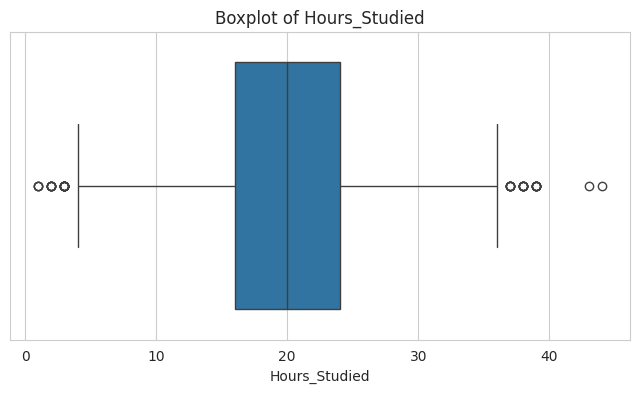

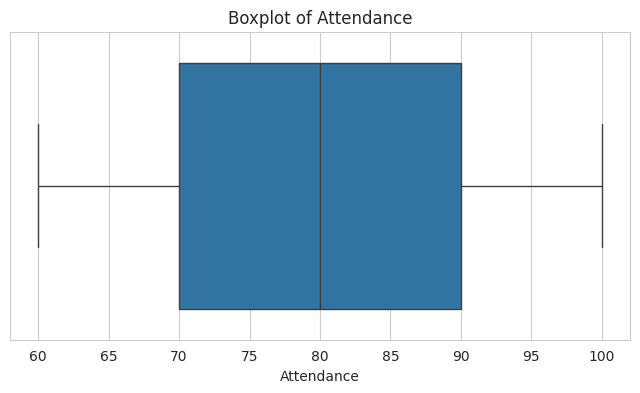

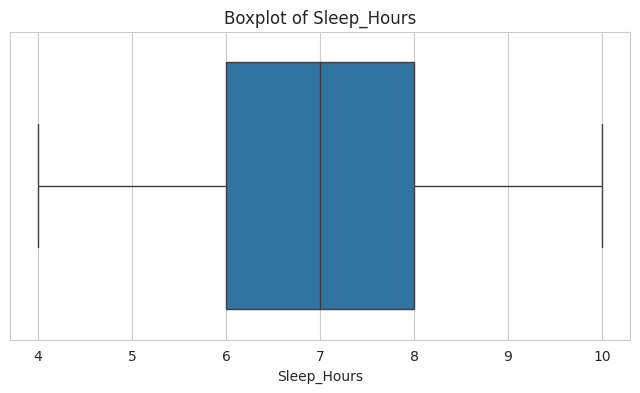

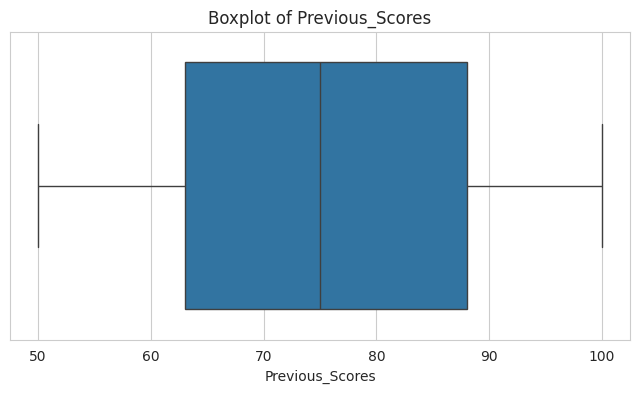

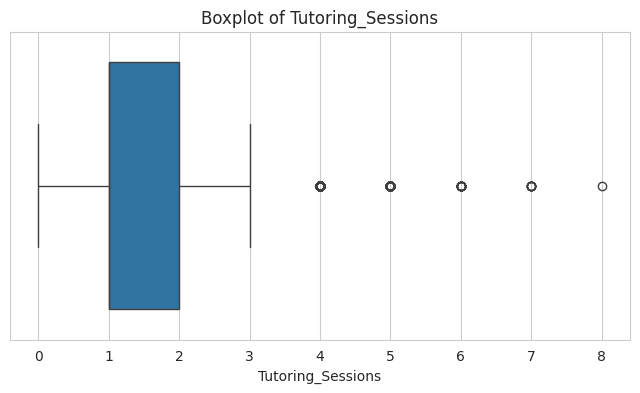

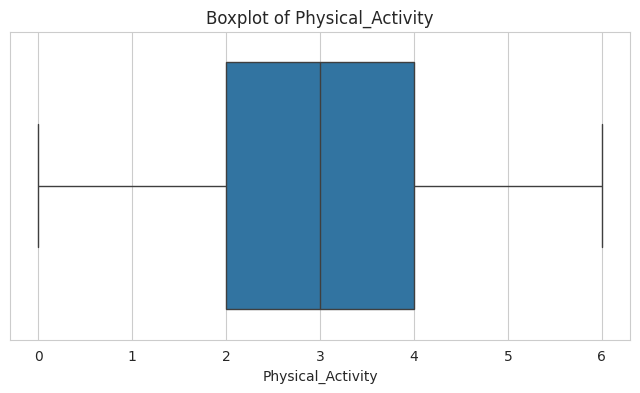

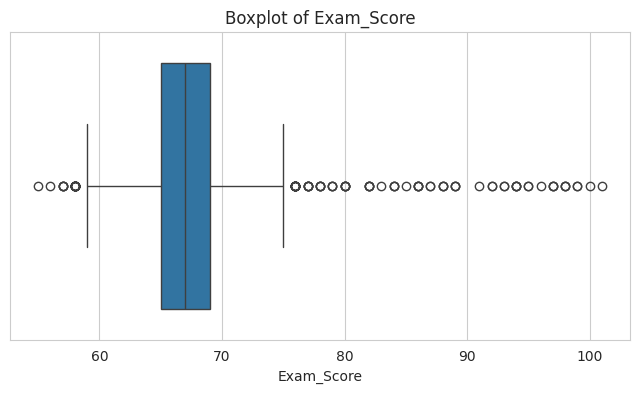

              DATA QUALITY SUMMARY

Total Rows              : 6607
Total Columns           : 20

Duplicate Rows           : 0
Total Missing Values    : 235
Columns With Missing    : 3
Constant Features       : 0
Numerical Features      : 7
Categorical Features    : 13


In [18]:
# ============================================
# STEP 13.1: MISSING VALUE ANALYSIS
# ============================================

missing_count = df.isnull().sum()

missing_percentage = (missing_count / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Show only columns containing missing values
missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Missing Value Report:")
display(missing_report)

# ============================================
# STEP 13.2: CHECK CATEGORICAL VALUES
# ============================================

categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    print("\n" + "=" * 60)
    print(f"Column: {column}")
    print("=" * 60)

    print("Number of unique values:", df[column].nunique())

    print("\nUnique values:")
    print(df[column].unique())

    print("\nValue counts:")
    print(df[column].value_counts(dropna=False))


# ============================================
# STEP 13.3: DUPLICATE RECORD ANALYSIS
# ============================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    print("\nDuplicate rows:")
    display(df[df.duplicated(keep=False)].sort_values(
        by=df.columns.tolist()
    ))
else:
    print("No duplicate rows found.")

# ============================================
# STEP 13.4: CHECK NUMERICAL VALUE RANGES
# ============================================

print("Checking numerical ranges...\n")

# Define expected logical ranges
range_checks = {
    "Hours_Studied": (0, 24),
    "Attendance": (0, 100),
    "Sleep_Hours": (0, 24),
    "Previous_Scores": (0, 100),
    "Tutoring_Sessions": (0, None),
    "Physical_Activity": (0, None),
    "Exam_Score": (0, 100)
}

for column, (minimum, maximum) in range_checks.items():

    if column not in df.columns:
        continue

    print(f"\n{column}")

    if minimum is not None:
        invalid_min = (df[column] < minimum).sum()
        print(f"Values below {minimum}: {invalid_min}")

    if maximum is not None:
        invalid_max = (df[column] > maximum).sum()
        print(f"Values above {maximum}: {invalid_max}")

# ============================================
# STEP 13.5: EXAM SCORE VALIDATION
# ============================================

print("Exam Score Statistics:")
print(df["Exam_Score"].describe())

print("\nScores above 100:")
display(
    df[df["Exam_Score"] > 100]
)

print("\nScores below 0:")
display(
    df[df["Exam_Score"] < 0]
)


# ============================================
# STEP 13.6: CHECK CONSTANT FEATURES
# ============================================

unique_counts = df.nunique(dropna=False)

constant_features = unique_counts[
    unique_counts == 1
]

print("Features with only one unique value:")

if len(constant_features) > 0:
    display(constant_features.to_frame(
        name="Unique_Value_Count"
    ))
else:
    print("No constant features found.")


# ============================================
# STEP 13.7: OUTLIER DETECTION USING IQR
# ============================================

numerical_columns = df.select_dtypes(
    include=np.number
).columns

outlier_report = []

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_percentage = (
        outlier_count / len(df)
    ) * 100

    outlier_report.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": outlier_percentage
    })

outlier_report = pd.DataFrame(outlier_report)

display(outlier_report)


# ============================================
# STEP 13.8: BOXPLOT FOR OUTLIER VISUALIZATION
# ============================================

for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

    plt.show()

# ============================================
# STEP 13.9: OVERALL DATA QUALITY SUMMARY
# ============================================

print("=" * 70)
print("              DATA QUALITY SUMMARY")
print("=" * 70)

print(f"\nTotal Rows              : {df.shape[0]}")
print(f"Total Columns           : {df.shape[1]}")

print(f"\nDuplicate Rows           : {df.duplicated().sum()}")

print(
    f"Total Missing Values    : "
    f"{df.isnull().sum().sum()}"
)

print(
    f"Columns With Missing    : "
    f"{(df.isnull().sum() > 0).sum()}"
)

print(
    f"Constant Features       : "
    f"{len(constant_features)}"
)

print(
    f"Numerical Features      : "
    f"{len(numerical_columns)}"
)

print(
    f"Categorical Features    : "
    f"{len(categorical_columns)}"
)

print("=" * 70)




In [19]:
# ============================================
# STEP 14: DATA CLEANING
# ============================================

# Create a copy so that the original dataset remains unchanged
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

# ------------------------------------------------
# 1. HANDLE MISSING VALUES
# ------------------------------------------------

categorical_missing_columns = [
    "Parental_Education_Level",
    "Teacher_Quality",
    "Distance_from_Home"
]

for column in categorical_missing_columns:

    mode_value = df_clean[column].mode()[0]

    df_clean[column] = df_clean[column].fillna(mode_value)

    print(
        f"{column}: Missing values filled with '{mode_value}'"
    )


# ------------------------------------------------
# 2. REMOVE DUPLICATE ROWS
# ------------------------------------------------

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("\nDuplicate rows before cleaning:", duplicates_before)
print("Duplicate rows after cleaning:", duplicates_after)


# ------------------------------------------------
# 3. HANDLE INVALID EXAM SCORE
# ------------------------------------------------

invalid_exam_scores = (
    (df_clean["Exam_Score"] < 0) |
    (df_clean["Exam_Score"] > 100)
).sum()

print("\nInvalid Exam_Score records:", invalid_exam_scores)

# Remove records with invalid exam scores
df_clean = df_clean[
    (df_clean["Exam_Score"] >= 0) &
    (df_clean["Exam_Score"] <= 100)
].copy()


# ------------------------------------------------
# 4. CHECK FINAL MISSING VALUES
# ------------------------------------------------

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())


# ------------------------------------------------
# 5. CHECK FINAL DATASET
# ------------------------------------------------

print("\nFinal dataset shape:", df_clean.shape)

print("\nFinal data types:")
print(df_clean.dtypes)

print("\nData cleaning completed successfully!")

Original dataset shape: (6607, 20)
Parental_Education_Level: Missing values filled with 'High School'
Teacher_Quality: Missing values filled with 'Medium'
Distance_from_Home: Missing values filled with 'Near'

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0

Invalid Exam_Score records: 1

Missing values after cleaning:
0

Final dataset shape: (6606, 20)

Final data types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Educa

In [20]:
# ============================================
# STEP 15.1: CHECK DATASET SHAPE
# ============================================

print("Dataset shape after cleaning:")
print(df_clean.shape)

print("\nNumber of rows:", df_clean.shape[0])
print("Number of columns:", df_clean.shape[1])

# ============================================
# STEP 15.2: VERIFY MISSING VALUES
# ============================================

missing_values = df_clean.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:",
      df_clean.isnull().sum().sum())

# ============================================
# STEP 15.3: VERIFY DUPLICATE ROWS
# ============================================

duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# ============================================
# STEP 15.4: VERIFY EXAM SCORE
# ============================================

print("Minimum Exam Score:",
      df_clean["Exam_Score"].min())

print("Maximum Exam Score:",
      df_clean["Exam_Score"].max())

invalid_scores = (
    (df_clean["Exam_Score"] < 0) |
    (df_clean["Exam_Score"] > 100)
).sum()

print("Invalid Exam Scores:", invalid_scores)

# ============================================
# STEP 15.5: VERIFY CATEGORICAL COLUMNS
# ============================================

categorical_columns = df_clean.select_dtypes(
    include="object"
).columns

print("Missing values in categorical columns:\n")

for column in categorical_columns:
    missing = df_clean[column].isnull().sum()

    print(f"{column}: {missing}")

# ============================================
# STEP 15.6: VERIFY NUMERICAL RANGES
# ============================================

numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns

print("Numerical feature ranges:\n")

for column in numerical_columns:
    print(
        f"{column}: "
        f"Min = {df_clean[column].min()}, "
        f"Max = {df_clean[column].max()}"
    )

# ============================================
# STEP 15.7: BEFORE vs AFTER CLEANING
# ============================================

print("BEFORE CLEANING")
print("----------------")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nAFTER CLEANING")
print("----------------")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

# ============================================
# STEP 15.8: FINAL DATA QUALITY VALIDATION
# ============================================

print("============================================")
print("FINAL DATA QUALITY VALIDATION")
print("============================================")

# Missing values
total_missing = df_clean.isnull().sum().sum()

# Duplicate rows
total_duplicates = df_clean.duplicated().sum()

# Invalid exam scores
invalid_exam_scores = (
    (df_clean["Exam_Score"] < 0) |
    (df_clean["Exam_Score"] > 100)
).sum()

# Number of columns
total_columns = df_clean.shape[1]

# Number of rows
total_rows = df_clean.shape[0]

print(f"Total Rows           : {total_rows}")
print(f"Total Columns        : {total_columns}")
print(f"Total Missing Values : {total_missing}")
print(f"Duplicate Rows       : {total_duplicates}")
print(f"Invalid Exam Scores  : {invalid_exam_scores}")

print("\n--------------------------------------------")

if (
    total_missing == 0
    and total_duplicates == 0
    and invalid_exam_scores == 0
):
    print("DATA VALIDATION PASSED")
    print("Dataset is ready for EDA.")
else:
    print("DATA VALIDATION FAILED")
    print("Further cleaning is required.")



Dataset shape after cleaning:
(6606, 20)

Number of rows: 6606
Number of columns: 20
Missing values in each column:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

Total missing values: 0
Number of duplicate rows: 0
Minimum Exam Score: 55
Maximum Exam Score: 100
Invalid Exam Scores: 0
Missing values in categorical columns:

Parental_Involvement: 0
Access_to_Resources: 0
Extracurricular_Activ

STEP 16 — Exploratory Data Analysis (EDA)

Numerical Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Statistical Summary:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000,6606.000000
mean,19.974266,79.974720,7.029216,75.067817,1.493188,2.967605,67.230548
std,5.990424,11.546219,1.468177,14.399184,1.229907,1.031309,3.868502
min,1.000000,60.000000,4.000000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.000000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.000000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.000000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.000000,100.000000,8.000000,6.000000,100.000000


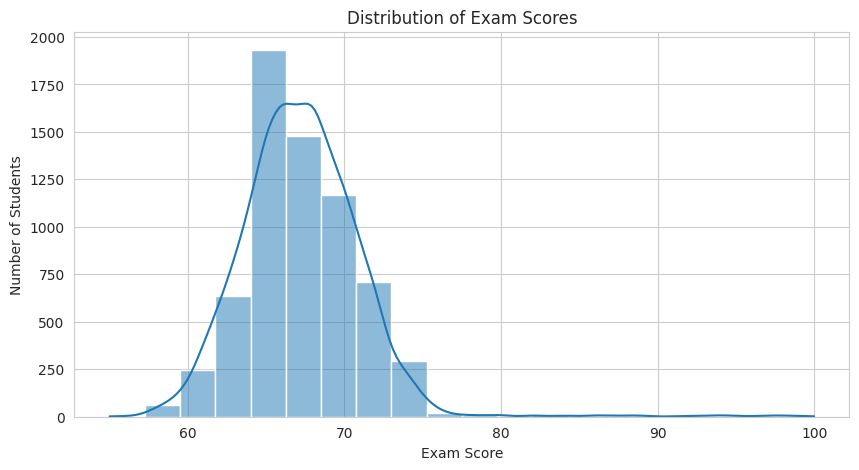

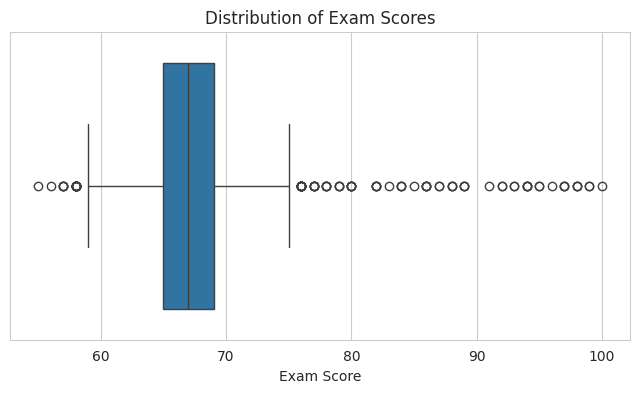

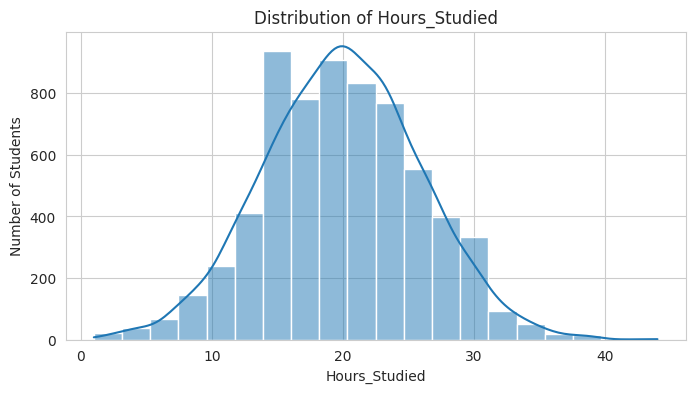

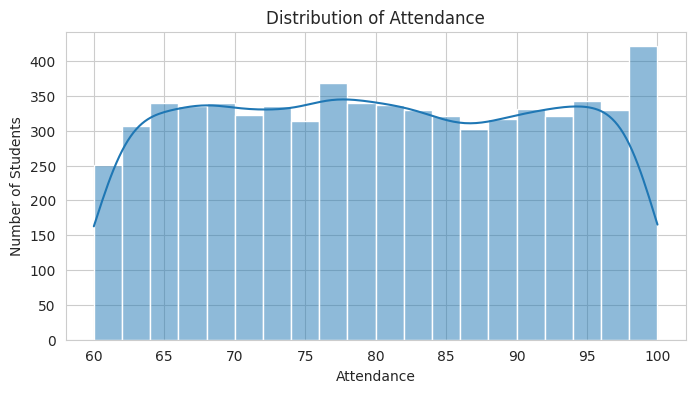

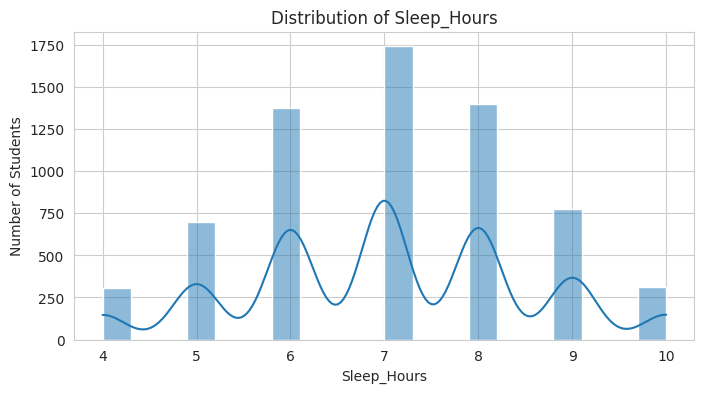

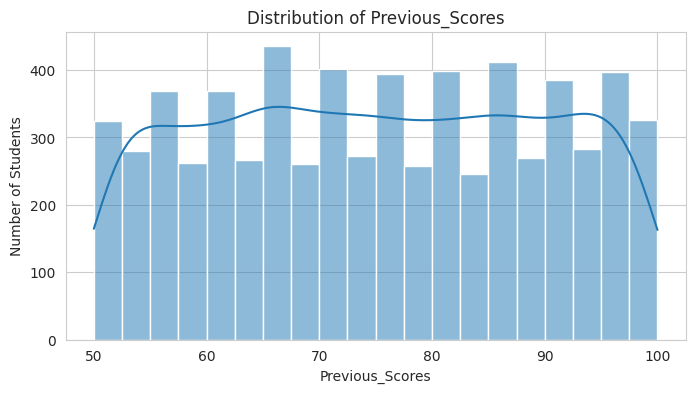

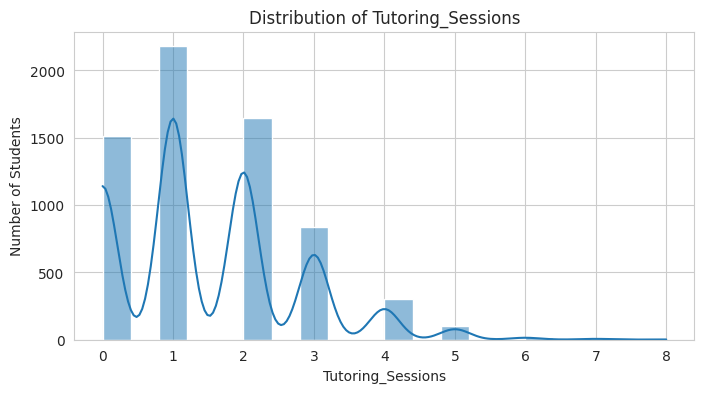

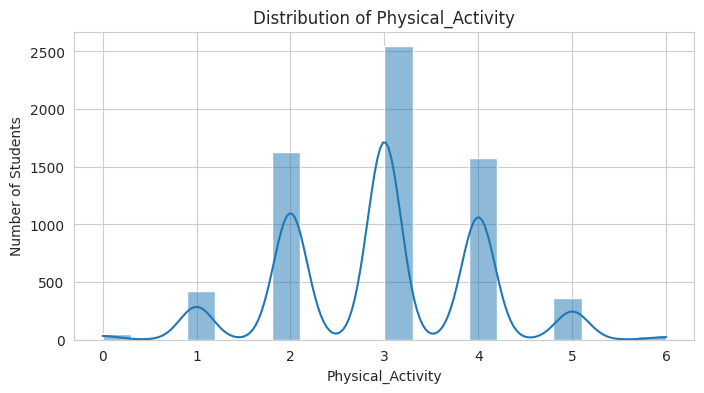

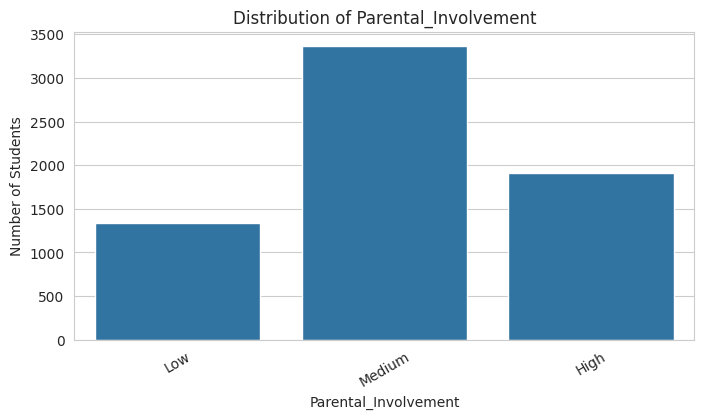

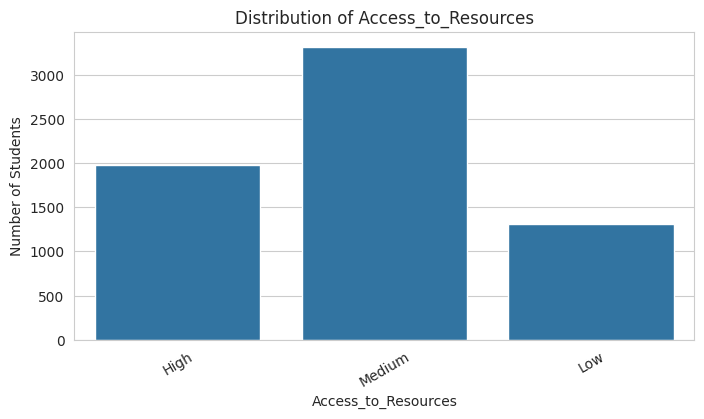

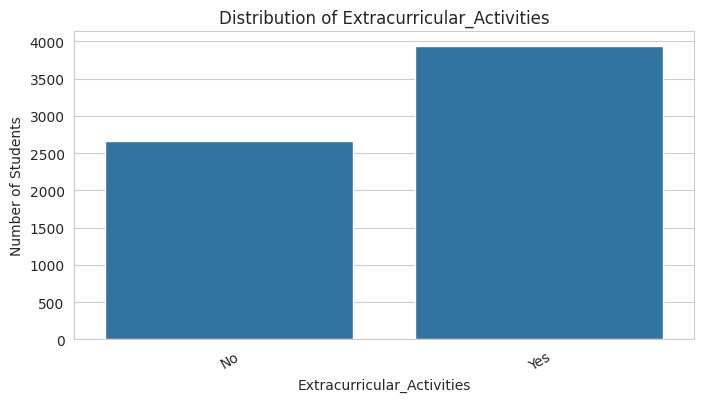

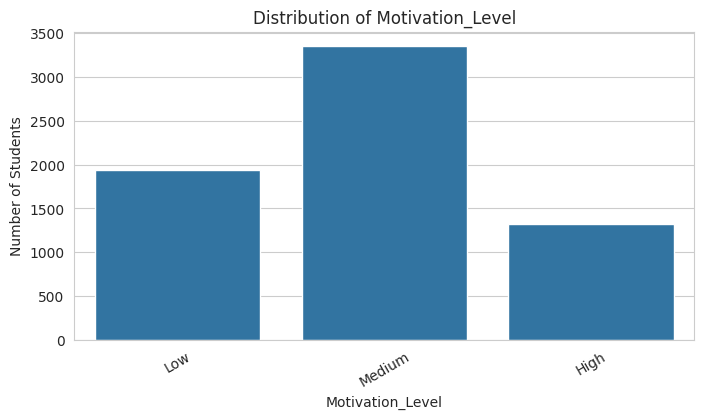

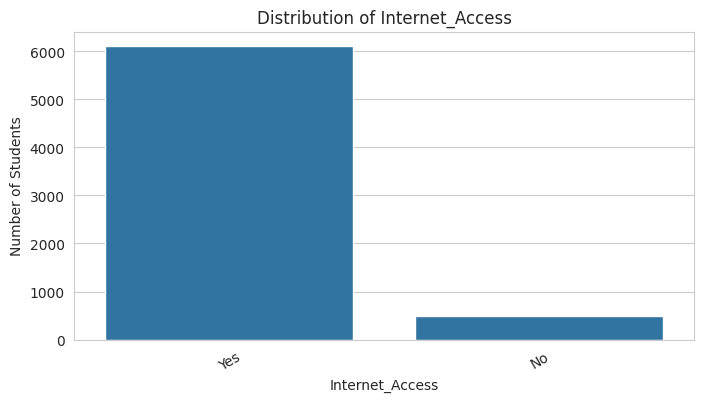

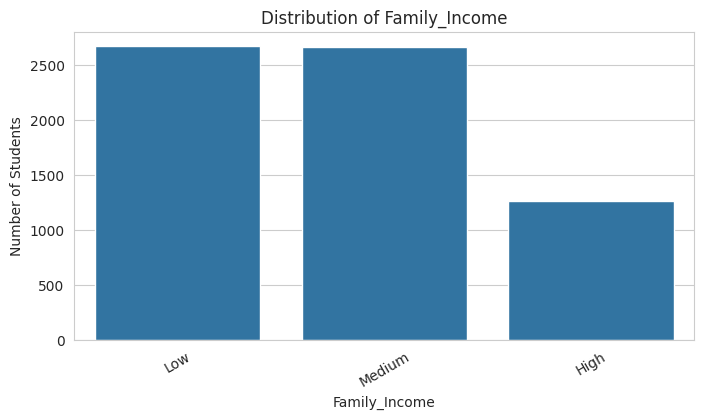

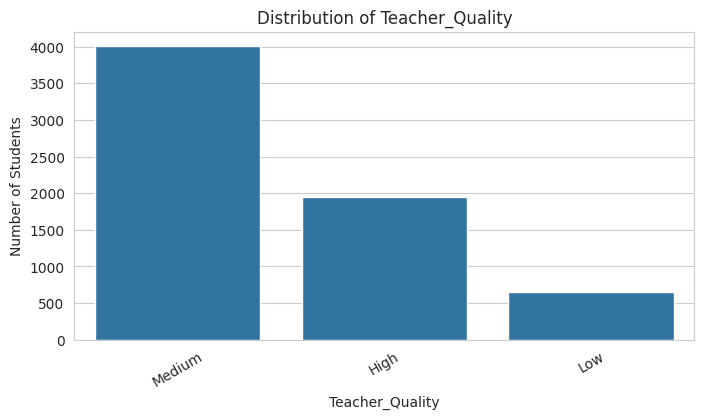

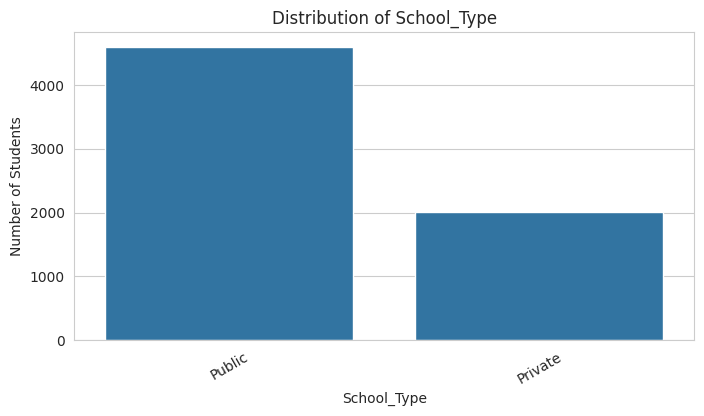

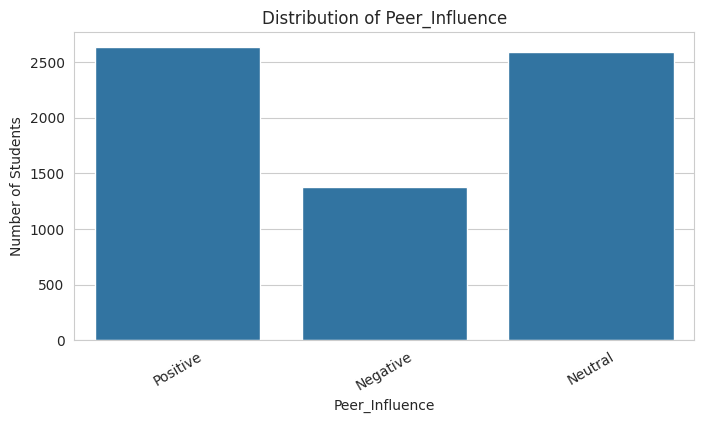

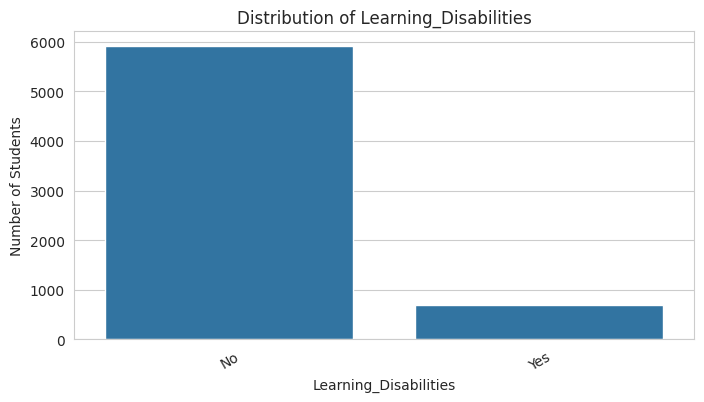

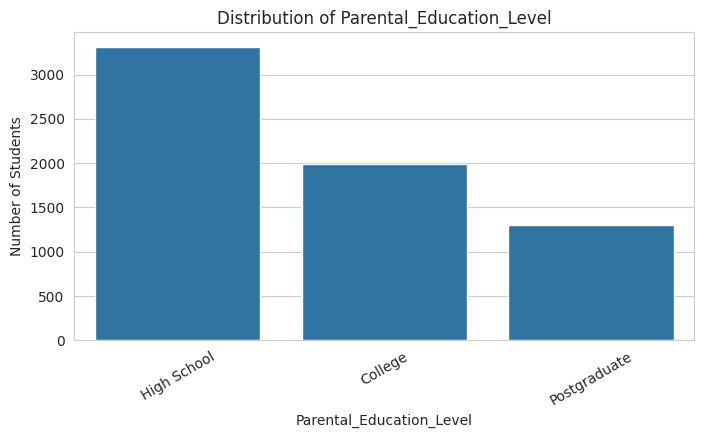

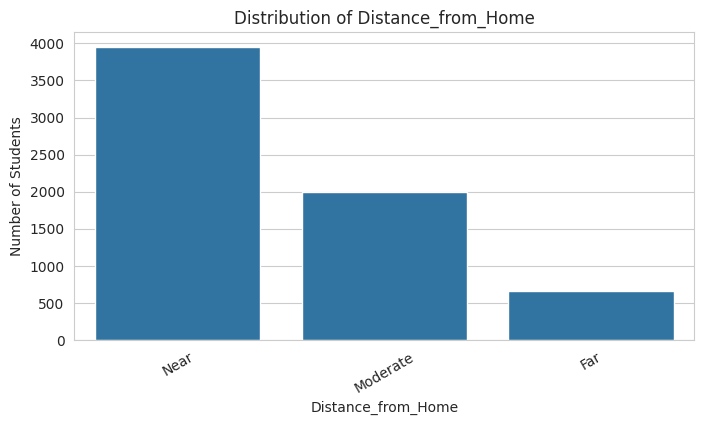

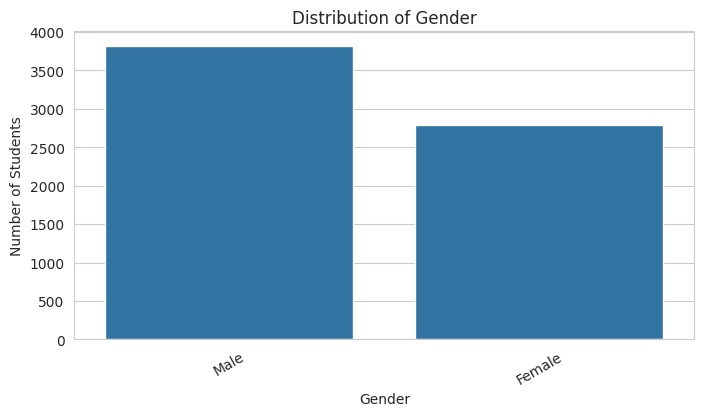

In [21]:
# ============================================
# STEP 16.1: NUMERICAL STATISTICAL SUMMARY
# ============================================

numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns

print("Numerical Features:")
print(list(numerical_columns))

print("\nStatistical Summary:")
display(df_clean[numerical_columns].describe())


# ============================================
# STEP 16.2: EXAM SCORE DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["Exam_Score"],
    bins=20,
    kde=True
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()


# ============================================
# STEP 16.3: EXAM SCORE BOXPLOT
# ============================================

plt.figure(figsize=(8, 4))

sns.boxplot(
    x=df_clean["Exam_Score"]
)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")

plt.show()


# ============================================
# STEP 16.4: NUMERICAL FEATURE DISTRIBUTIONS
# ============================================

numerical_features = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity"
]

for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df_clean[column],
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Students")

    plt.show()

# ============================================
# STEP 16.5: CATEGORICAL FEATURE DISTRIBUTIONS
# ============================================

categorical_columns = df_clean.select_dtypes(
    include="object"
).columns

for column in categorical_columns:

    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df_clean,
        x=column
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of Students")

    plt.xticks(rotation=30)

    plt.show()

STEP 17.1 — HOURS STUDIED VS EXAM SCORE

Required columns found successfully.
Hours_Studied and Exam_Score are ready for analysis.

2. BASIC STATISTICS

Hours Studied:
count    6606.000000
mean       19.974266
std         5.990424
min         1.000000
25%        16.000000
50%        20.000000
75%        24.000000
max        44.000000
Name: Hours_Studied, dtype: float64

Exam Score:
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

3. SCATTER PLOT


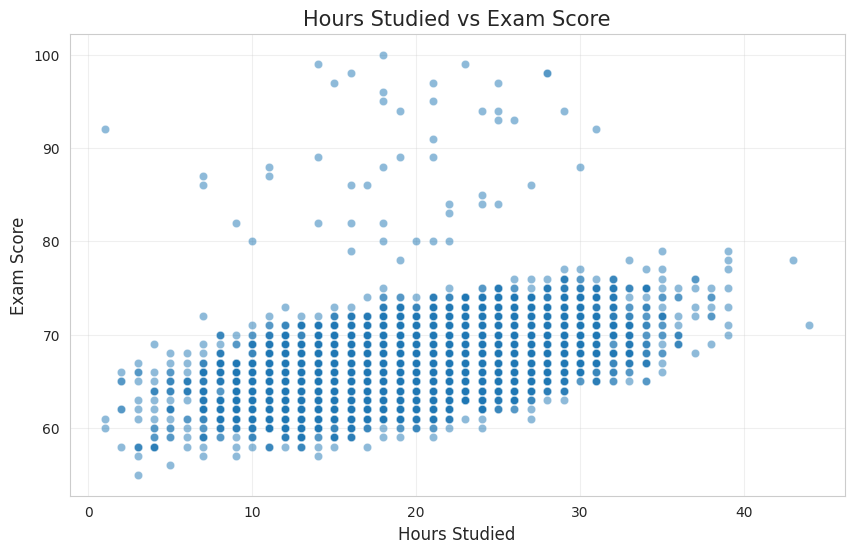


4. REGRESSION TREND LINE


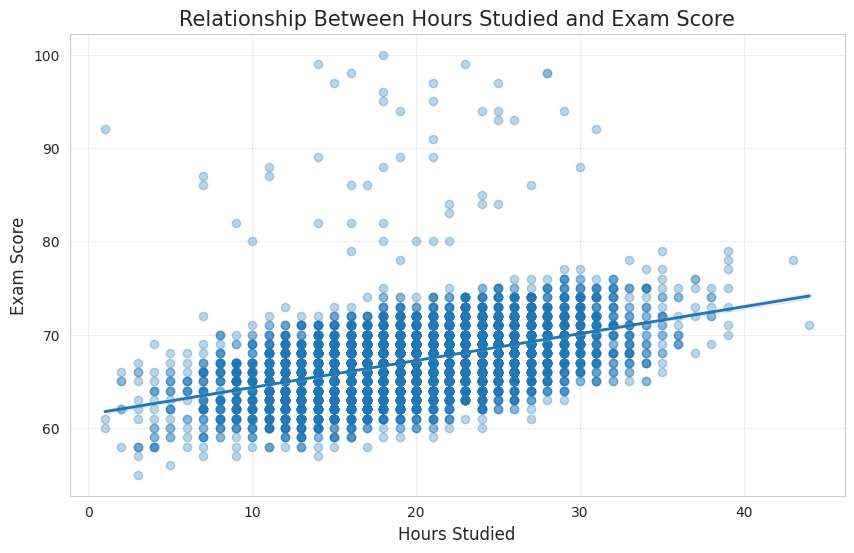


5. CORRELATION ANALYSIS

Correlation Matrix:


,Hours_Studied,Exam_Score
Hours_Studied,1.000000,0.446514
Exam_Score,0.446514,1.000000



Correlation between Hours Studied and Exam Score: 0.4465

Correlation Interpretation:
The data shows a moderate positive linear association between Hours Studied and Exam Score.

6. STUDY HOUR GROUP ANALYSIS

Exam Performance by Study-Hour Group:


,Study_Hours_Group,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,1-10,365,63.97,64.0,3.93,55,92
1,11-20,3179,66.18,66.0,3.51,57,100
2,21-30,2809,68.51,68.0,3.56,59,99
3,31-40,251,70.98,71.0,3.36,65,92
4,41-50,2,74.50,74.5,4.95,71,78



7. AVERAGE EXAM SCORE BY STUDY HOURS


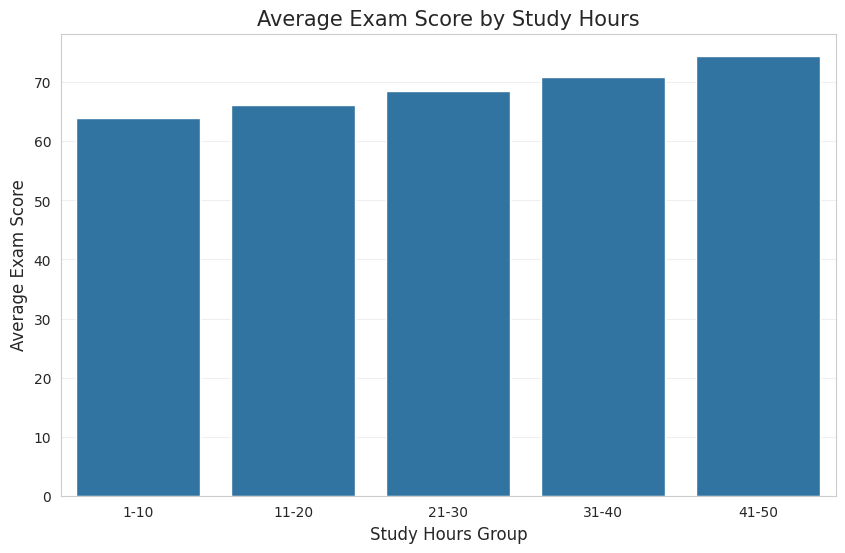


8. EXAM SCORE DISTRIBUTION BY STUDY-HOUR GROUP


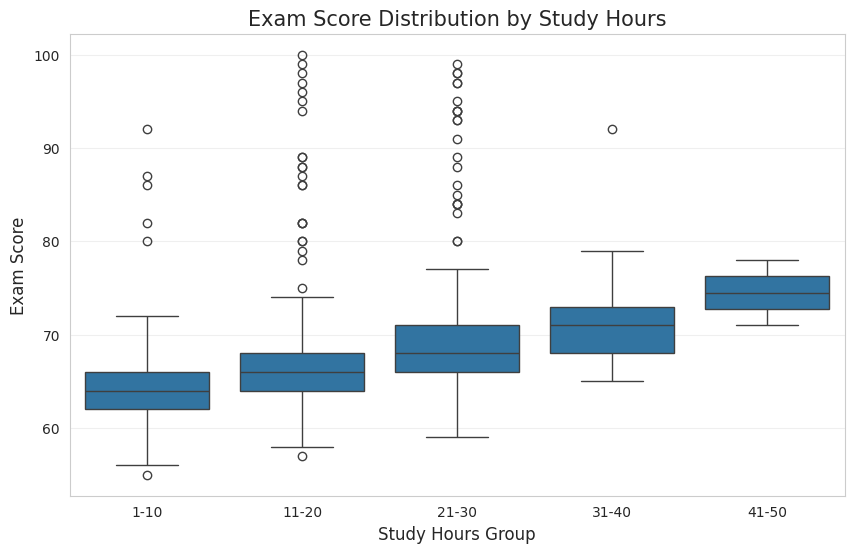


9. GROUP COMPARISON

Highest average exam score group: 41-50
Average score: 74.5

Lowest average exam score group: 1-10
Average score: 63.97

10. STEP 17.1 SUMMARY

Correlation coefficient: 0.4465

Study-hour groups analyzed: 5

The scatter plot and regression line show the overall relationship between study time and examination performance.
The correlation coefficient quantifies the linear association between the two variables.
The grouped analysis compares average examination scores across different study-hour ranges.

Note: These analyses identify association, not causation.

Temporary EDA column removed.

STEP 17.1 COMPLETED SUCCESSFULLY


In [22]:
# ============================================================
# STEP 17.1 — HOURS STUDIED VS EXAM SCORE
# Complete Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.1 — HOURS STUDIED VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Hours_Studied",
    "Exam_Score"
]

missing_columns = [
    column for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:
    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")
    print("Hours_Studied and Exam_Score are ready for analysis.")


    # --------------------------------------------------------
    # 2. BASIC STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. BASIC STATISTICS")
    print("=" * 70)

    print("\nHours Studied:")
    print(df_clean["Hours_Studied"].describe())

    print("\nExam Score:")
    print(df_clean["Exam_Score"].describe())


    # --------------------------------------------------------
    # 3. SCATTER PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. SCATTER PLOT")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df_clean,
        x="Hours_Studied",
        y="Exam_Score",
        alpha=0.5
    )

    plt.title(
        "Hours Studied vs Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Hours Studied",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 4. REGRESSION TREND LINE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. REGRESSION TREND LINE")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.regplot(
        data=df_clean,
        x="Hours_Studied",
        y="Exam_Score",
        scatter_kws={
            "alpha": 0.3
        },
        line_kws={
            "linewidth": 2
        }
    )

    plt.title(
        "Relationship Between Hours Studied and Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Hours Studied",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 5. PEARSON CORRELATION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. CORRELATION ANALYSIS")
    print("=" * 70)

    correlation_matrix = df_clean[
        ["Hours_Studied", "Exam_Score"]
    ].corr()

    print("\nCorrelation Matrix:")
    display(correlation_matrix)

    hours_exam_corr = correlation_matrix.loc[
        "Hours_Studied",
        "Exam_Score"
    ]

    print(
        "\nCorrelation between Hours Studied and Exam Score:",
        round(hours_exam_corr, 4)
    )


    # --------------------------------------------------------
    # 6. INTERPRET CORRELATION
    # --------------------------------------------------------

    print("\nCorrelation Interpretation:")

    if hours_exam_corr > 0:
        direction = "positive"
    elif hours_exam_corr < 0:
        direction = "negative"
    else:
        direction = "no"

    absolute_corr = abs(hours_exam_corr)

    if absolute_corr < 0.10:
        strength = "very weak"
    elif absolute_corr < 0.30:
        strength = "weak"
    elif absolute_corr < 0.50:
        strength = "moderate"
    elif absolute_corr < 0.70:
        strength = "strong"
    else:
        strength = "very strong"

    print(
        f"The data shows a {strength} {direction} "
        "linear association between Hours Studied "
        "and Exam Score."
    )


    # --------------------------------------------------------
    # 7. CREATE STUDY-HOUR GROUPS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. STUDY HOUR GROUP ANALYSIS")
    print("=" * 70)

    df_clean["Study_Hours_Group"] = pd.cut(
        df_clean["Hours_Studied"],
        bins=[0, 10, 20, 30, 40, 50],
        labels=[
            "1-10",
            "11-20",
            "21-30",
            "31-40",
            "41-50"
        ],
        include_lowest=True
    )


    # --------------------------------------------------------
    # 8. CALCULATE GROUP STATISTICS
    # --------------------------------------------------------

    study_hours_summary = (
        df_clean
        .groupby(
            "Study_Hours_Group",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )

    # Round numerical values
    study_hours_summary[
        ["Mean", "Median", "Std_Dev", "Minimum", "Maximum"]
    ] = study_hours_summary[
        ["Mean", "Median", "Std_Dev", "Minimum", "Maximum"]
    ].round(2)


    # --------------------------------------------------------
    # 9. DISPLAY GROUP SUMMARY
    # --------------------------------------------------------

    print("\nExam Performance by Study-Hour Group:")

    display(study_hours_summary)


    # --------------------------------------------------------
    # 10. BAR CHART — AVERAGE SCORE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. AVERAGE EXAM SCORE BY STUDY HOURS")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=study_hours_summary,
        x="Study_Hours_Group",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Study Hours",
        fontsize=15
    )

    plt.xlabel(
        "Study Hours Group",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 11. BOX PLOT — SCORE DISTRIBUTION BY STUDY GROUP
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. EXAM SCORE DISTRIBUTION BY STUDY-HOUR GROUP")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df_clean,
        x="Study_Hours_Group",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Study Hours",
        fontsize=15
    )

    plt.xlabel(
        "Study Hours Group",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 12. FIND HIGHEST AND LOWEST GROUP MEAN
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. GROUP COMPARISON")
    print("=" * 70)

    highest_group = study_hours_summary.loc[
        study_hours_summary["Mean"].idxmax()
    ]

    lowest_group = study_hours_summary.loc[
        study_hours_summary["Mean"].idxmin()
    ]

    print(
        f"\nHighest average exam score group: "
        f"{highest_group['Study_Hours_Group']}"
    )

    print(
        f"Average score: {highest_group['Mean']}"
    )

    print(
        f"\nLowest average exam score group: "
        f"{lowest_group['Study_Hours_Group']}"
    )

    print(
        f"Average score: {lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 13. FINAL AUTOMATIC SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("10. STEP 17.1 SUMMARY")
    print("=" * 70)

    print(
        "\nCorrelation coefficient:",
        round(hours_exam_corr, 4)
    )

    print(
        "\nStudy-hour groups analyzed:",
        len(study_hours_summary)
    )

    print(
        "\nThe scatter plot and regression line show "
        "the overall relationship between study time "
        "and examination performance."
    )

    print(
        "The correlation coefficient quantifies the "
        "linear association between the two variables."
    )

    print(
        "The grouped analysis compares average examination "
        "scores across different study-hour ranges."
    )

    print(
        "\nNote: These analyses identify association, "
        "not causation."
    )


    # --------------------------------------------------------
    # 14. REMOVE TEMPORARY EDA COLUMN
    # --------------------------------------------------------

    df_clean.drop(
        columns=["Study_Hours_Group"],
        inplace=True
    )

    print("\nTemporary EDA column removed.")

    print("\n" + "=" * 70)
    print("STEP 17.1 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 17.2 — ATTENDANCE VS EXAM SCORE

Required columns found successfully.
Attendance and Exam_Score are ready for analysis.

1. BASIC STATISTICS

Attendance:
count    6606.000000
mean       79.974720
std        11.546219
min        60.000000
25%        70.000000
50%        80.000000
75%        90.000000
max       100.000000
Name: Attendance, dtype: float64

Exam Score:
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

2. SCATTER PLOT


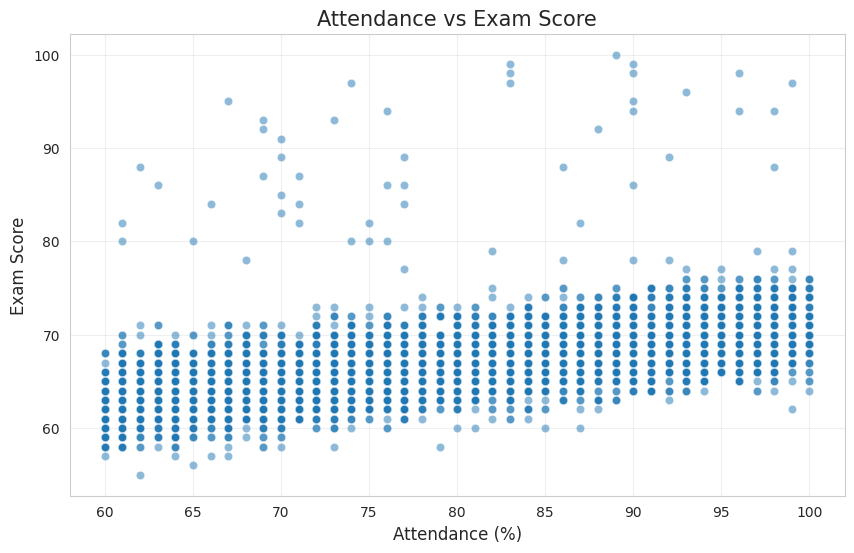


3. REGRESSION TREND LINE


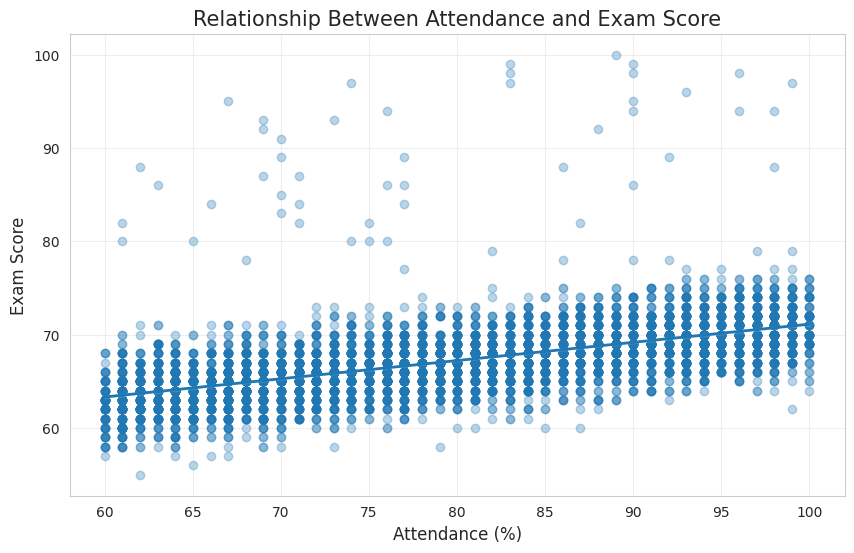


4. CORRELATION ANALYSIS

Correlation Matrix:


,Attendance,Exam_Score
Attendance,1.000000,0.582458
Exam_Score,0.582458,1.000000



Correlation between Attendance and Exam Score: 0.5825

Correlation Interpretation:
The data shows a strong positive linear association between Attendance and Exam Score.

5. ATTENDANCE GROUP ANALYSIS

Exam Performance by Attendance Group:


,Attendance_Group,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,60-70%,1734,64.33,64.0,3.31,55,95
1,71-80%,1689,66.43,66.0,3.07,58,97
2,81-90%,1594,68.34,68.0,3.45,60,100
3,91-100%,1589,70.14,70.0,2.97,62,98



6. AVERAGE EXAM SCORE BY ATTENDANCE GROUP


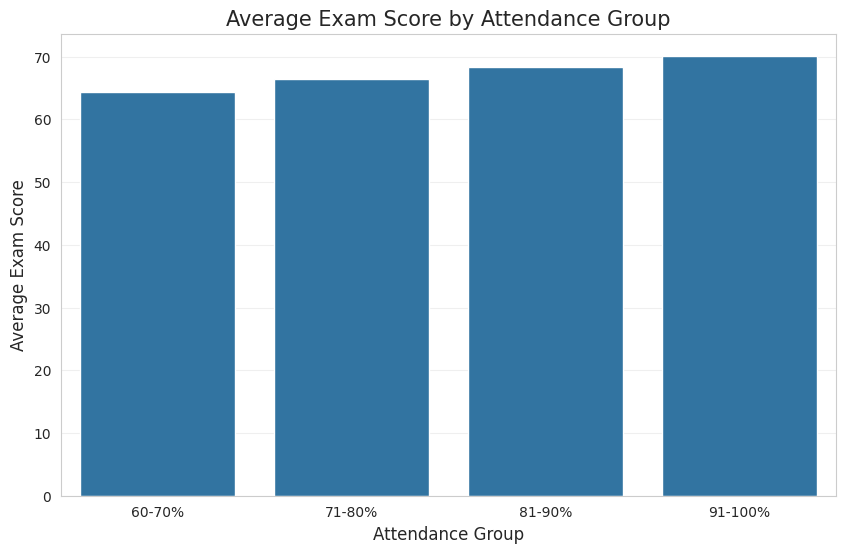


7. EXAM SCORE DISTRIBUTION BY ATTENDANCE GROUP


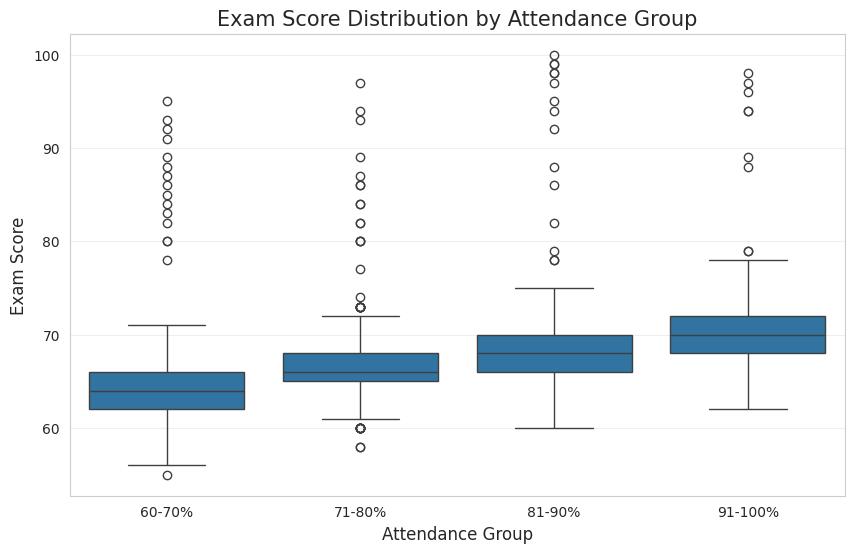


8. GROUP COMPARISON

Highest average exam score group: 91-100%
Average score: 70.14

Lowest average exam score group: 60-70%
Average score: 64.33

9. STEP 17.2 SUMMARY

Correlation coefficient: 0.5825

The scatter plot and regression line show the overall relationship between attendance and examination performance.
The correlation coefficient quantifies the linear association between the two variables.
The grouped analysis compares average examination scores across attendance ranges.

Note: These analyses identify association, not causation.

Temporary EDA column removed.

STEP 17.2 COMPLETED SUCCESSFULLY


In [23]:
# ============================================================
# STEP 17.2 — ATTENDANCE VS EXAM SCORE
# Complete Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.2 — ATTENDANCE VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Attendance",
    "Exam_Score"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:

    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")
    print("Attendance and Exam_Score are ready for analysis.")


    # --------------------------------------------------------
    # 2. BASIC STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("1. BASIC STATISTICS")
    print("=" * 70)

    print("\nAttendance:")
    print(df_clean["Attendance"].describe())

    print("\nExam Score:")
    print(df_clean["Exam_Score"].describe())


    # --------------------------------------------------------
    # 3. SCATTER PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. SCATTER PLOT")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df_clean,
        x="Attendance",
        y="Exam_Score",
        alpha=0.5
    )

    plt.title(
        "Attendance vs Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Attendance (%)",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 4. REGRESSION TREND LINE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. REGRESSION TREND LINE")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.regplot(
        data=df_clean,
        x="Attendance",
        y="Exam_Score",
        scatter_kws={
            "alpha": 0.3
        },
        line_kws={
            "linewidth": 2
        }
    )

    plt.title(
        "Relationship Between Attendance and Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Attendance (%)",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 5. PEARSON CORRELATION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. CORRELATION ANALYSIS")
    print("=" * 70)

    correlation_matrix = df_clean[
        ["Attendance", "Exam_Score"]
    ].corr()

    print("\nCorrelation Matrix:")

    display(correlation_matrix)

    attendance_exam_corr = correlation_matrix.loc[
        "Attendance",
        "Exam_Score"
    ]

    print(
        "\nCorrelation between Attendance and Exam Score:",
        round(attendance_exam_corr, 4)
    )


    # --------------------------------------------------------
    # 6. INTERPRET CORRELATION
    # --------------------------------------------------------

    print("\nCorrelation Interpretation:")

    if attendance_exam_corr > 0:
        direction = "positive"
    elif attendance_exam_corr < 0:
        direction = "negative"
    else:
        direction = "no"

    absolute_corr = abs(attendance_exam_corr)

    if absolute_corr < 0.10:
        strength = "very weak"
    elif absolute_corr < 0.30:
        strength = "weak"
    elif absolute_corr < 0.50:
        strength = "moderate"
    elif absolute_corr < 0.70:
        strength = "strong"
    else:
        strength = "very strong"

    print(
        f"The data shows a {strength} {direction} "
        "linear association between Attendance "
        "and Exam Score."
    )


    # --------------------------------------------------------
    # 7. CREATE ATTENDANCE GROUPS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. ATTENDANCE GROUP ANALYSIS")
    print("=" * 70)

    df_clean["Attendance_Group"] = pd.cut(
        df_clean["Attendance"],
        bins=[59, 70, 80, 90, 100],
        labels=[
            "60-70%",
            "71-80%",
            "81-90%",
            "91-100%"
        ],
        include_lowest=True
    )


    # --------------------------------------------------------
    # 8. CALCULATE GROUP STATISTICS
    # --------------------------------------------------------

    attendance_summary = (
        df_clean
        .groupby(
            "Attendance_Group",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )

    attendance_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ] = attendance_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ].round(2)


    # --------------------------------------------------------
    # 9. DISPLAY GROUP SUMMARY
    # --------------------------------------------------------

    print("\nExam Performance by Attendance Group:")

    display(attendance_summary)


    # --------------------------------------------------------
    # 10. BAR CHART — AVERAGE SCORE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. AVERAGE EXAM SCORE BY ATTENDANCE GROUP")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=attendance_summary,
        x="Attendance_Group",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Attendance Group",
        fontsize=15
    )

    plt.xlabel(
        "Attendance Group",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 11. BOX PLOT — SCORE DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. EXAM SCORE DISTRIBUTION BY ATTENDANCE GROUP")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df_clean,
        x="Attendance_Group",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Attendance Group",
        fontsize=15
    )

    plt.xlabel(
        "Attendance Group",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 12. HIGHEST AND LOWEST GROUP
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. GROUP COMPARISON")
    print("=" * 70)

    highest_group = attendance_summary.loc[
        attendance_summary["Mean"].idxmax()
    ]

    lowest_group = attendance_summary.loc[
        attendance_summary["Mean"].idxmin()
    ]

    print(
        f"\nHighest average exam score group: "
        f"{highest_group['Attendance_Group']}"
    )

    print(
        f"Average score: "
        f"{highest_group['Mean']}"
    )

    print(
        f"\nLowest average exam score group: "
        f"{lowest_group['Attendance_Group']}"
    )

    print(
        f"Average score: "
        f"{lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 13. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. STEP 17.2 SUMMARY")
    print("=" * 70)

    print(
        "\nCorrelation coefficient:",
        round(attendance_exam_corr, 4)
    )

    print(
        "\nThe scatter plot and regression line show "
        "the overall relationship between attendance "
        "and examination performance."
    )

    print(
        "The correlation coefficient quantifies the "
        "linear association between the two variables."
    )

    print(
        "The grouped analysis compares average examination "
        "scores across attendance ranges."
    )

    print(
        "\nNote: These analyses identify association, "
        "not causation."
    )


    # --------------------------------------------------------
    # 14. REMOVE TEMPORARY EDA COLUMN
    # --------------------------------------------------------

    df_clean.drop(
        columns=["Attendance_Group"],
        inplace=True
    )

    print("\nTemporary EDA column removed.")

    print("\n" + "=" * 70)
    print("STEP 17.2 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 17.3 — PREVIOUS SCORES VS EXAM SCORE

Required columns found successfully.
Previous_Scores and Exam_Score are ready for analysis.

1. BASIC STATISTICS

Previous Scores:
count    6606.000000
mean       75.067817
std        14.399184
min        50.000000
25%        63.000000
50%        75.000000
75%        88.000000
max       100.000000
Name: Previous_Scores, dtype: float64

Exam Score:
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

2. SCATTER PLOT


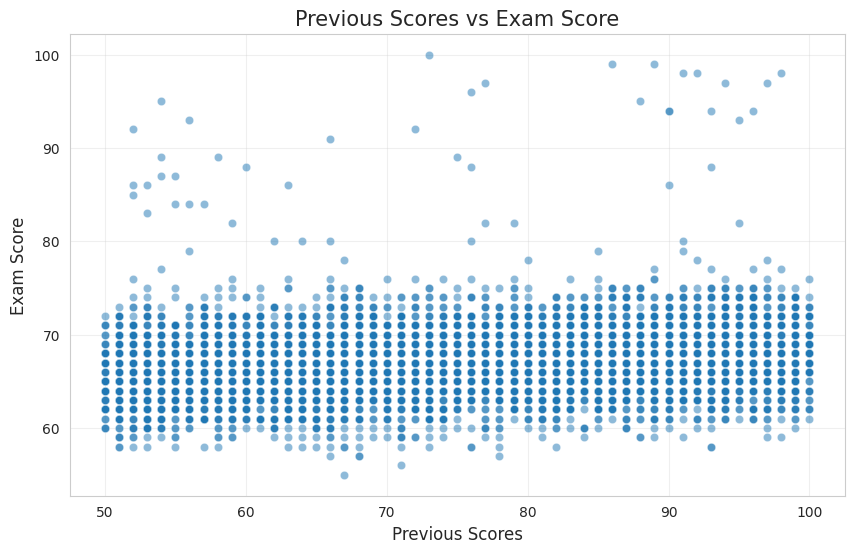


3. REGRESSION TREND LINE


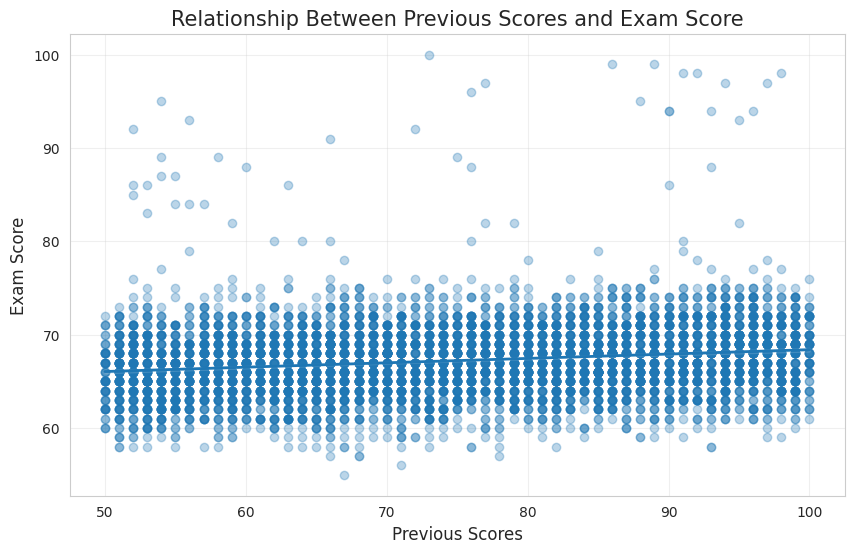


4. CORRELATION ANALYSIS

Correlation Matrix:


,Previous_Scores,Exam_Score
Previous_Scores,1.000000,0.174461
Exam_Score,0.174461,1.000000



Correlation between Previous Scores and Exam Score: 0.1745

Correlation Interpretation:
The data shows a weak positive linear association between Previous Scores and Exam Score.

5. PREVIOUS SCORE GROUP ANALYSIS

Exam Performance by Previous Score Group:


,Previous_Score_Group,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,50-60,1356,66.42,66.0,3.94,58,95
1,61-70,1346,66.70,67.0,3.49,55,91
2,71-80,1323,67.23,67.0,3.78,56,100
3,81-90,1314,67.59,67.0,3.75,58,99
4,91-100,1267,68.30,68.0,4.08,58,98



6. AVERAGE EXAM SCORE BY PREVIOUS SCORE GROUP


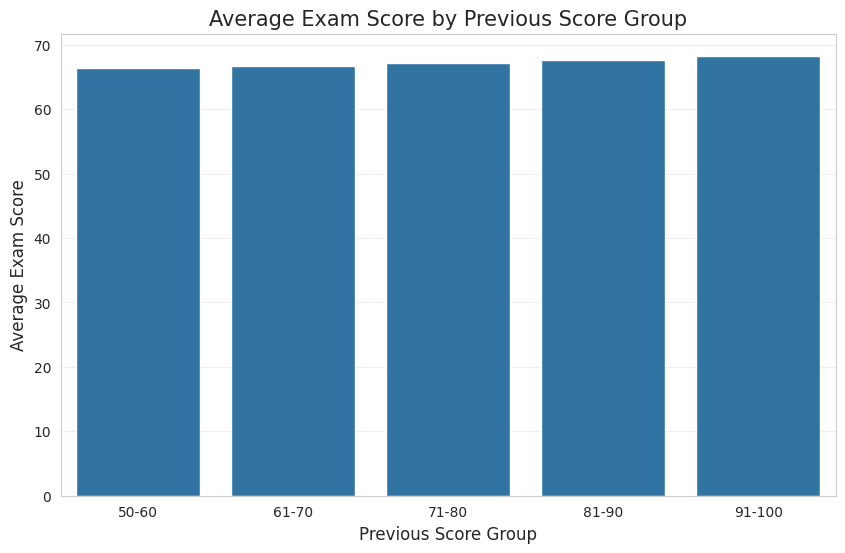


7. EXAM SCORE DISTRIBUTION BY PREVIOUS SCORE GROUP


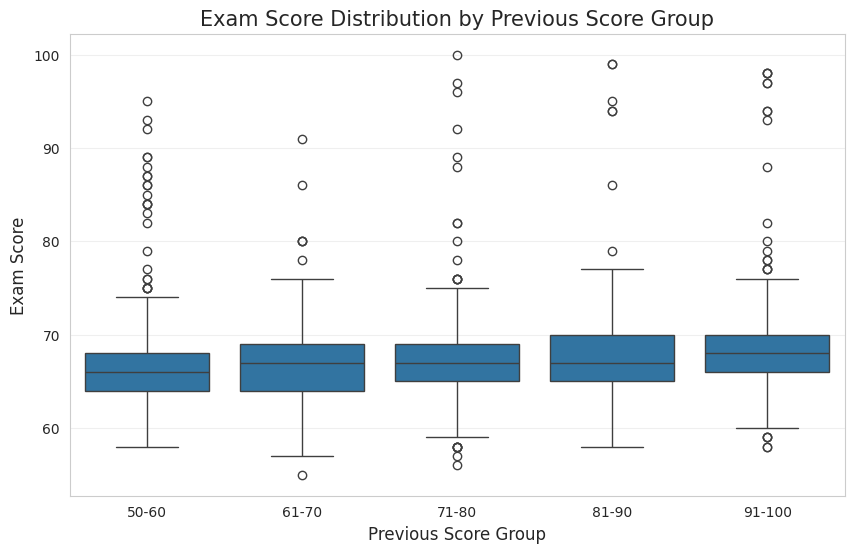


8. GROUP COMPARISON

Highest average exam score group: 91-100
Average score: 68.3

Lowest average exam score group: 50-60
Average score: 66.42

9. STEP 17.3 SUMMARY

Correlation coefficient: 0.1745

The scatter plot and regression line show the overall relationship between previous academic scores and current examination performance.
The correlation coefficient quantifies the linear association between the two variables.
The grouped analysis compares average current exam scores across previous-score ranges.

Note: These analyses identify association, not causation.

Temporary EDA column removed.

STEP 17.3 COMPLETED SUCCESSFULLY


In [24]:
# ============================================================
# STEP 17.3 — PREVIOUS SCORES VS EXAM SCORE
# Complete Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.3 — PREVIOUS SCORES VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Previous_Scores",
    "Exam_Score"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:

    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")
    print(
        "Previous_Scores and Exam_Score "
        "are ready for analysis."
    )


    # --------------------------------------------------------
    # 2. BASIC STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("1. BASIC STATISTICS")
    print("=" * 70)

    print("\nPrevious Scores:")
    print(df_clean["Previous_Scores"].describe())

    print("\nExam Score:")
    print(df_clean["Exam_Score"].describe())


    # --------------------------------------------------------
    # 3. SCATTER PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. SCATTER PLOT")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.scatterplot(
        data=df_clean,
        x="Previous_Scores",
        y="Exam_Score",
        alpha=0.5
    )

    plt.title(
        "Previous Scores vs Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Previous Scores",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 4. REGRESSION TREND LINE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. REGRESSION TREND LINE")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.regplot(
        data=df_clean,
        x="Previous_Scores",
        y="Exam_Score",
        scatter_kws={
            "alpha": 0.3
        },
        line_kws={
            "linewidth": 2
        }
    )

    plt.title(
        "Relationship Between Previous Scores and Exam Score",
        fontsize=15
    )

    plt.xlabel(
        "Previous Scores",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(True, alpha=0.3)

    plt.show()


    # --------------------------------------------------------
    # 5. PEARSON CORRELATION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. CORRELATION ANALYSIS")
    print("=" * 70)

    correlation_matrix = df_clean[
        ["Previous_Scores", "Exam_Score"]
    ].corr()

    print("\nCorrelation Matrix:")

    display(correlation_matrix)

    previous_exam_corr = correlation_matrix.loc[
        "Previous_Scores",
        "Exam_Score"
    ]

    print(
        "\nCorrelation between Previous Scores "
        "and Exam Score:",
        round(previous_exam_corr, 4)
    )


    # --------------------------------------------------------
    # 6. INTERPRET CORRELATION
    # --------------------------------------------------------

    print("\nCorrelation Interpretation:")

    if previous_exam_corr > 0:
        direction = "positive"
    elif previous_exam_corr < 0:
        direction = "negative"
    else:
        direction = "no"

    absolute_corr = abs(previous_exam_corr)

    if absolute_corr < 0.10:
        strength = "very weak"
    elif absolute_corr < 0.30:
        strength = "weak"
    elif absolute_corr < 0.50:
        strength = "moderate"
    elif absolute_corr < 0.70:
        strength = "strong"
    else:
        strength = "very strong"

    print(
        f"The data shows a {strength} {direction} "
        "linear association between Previous Scores "
        "and Exam Score."
    )


    # --------------------------------------------------------
    # 7. CREATE PREVIOUS-SCORE GROUPS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. PREVIOUS SCORE GROUP ANALYSIS")
    print("=" * 70)

    df_clean["Previous_Score_Group"] = pd.cut(
        df_clean["Previous_Scores"],
        bins=[49, 60, 70, 80, 90, 100],
        labels=[
            "50-60",
            "61-70",
            "71-80",
            "81-90",
            "91-100"
        ],
        include_lowest=True
    )


    # --------------------------------------------------------
    # 8. CALCULATE GROUP STATISTICS
    # --------------------------------------------------------

    previous_score_summary = (
        df_clean
        .groupby(
            "Previous_Score_Group",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )


    # Round numerical values

    previous_score_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ] = previous_score_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ].round(2)


    # --------------------------------------------------------
    # 9. DISPLAY GROUP SUMMARY
    # --------------------------------------------------------

    print("\nExam Performance by Previous Score Group:")

    display(previous_score_summary)


    # --------------------------------------------------------
    # 10. BAR CHART — AVERAGE EXAM SCORE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. AVERAGE EXAM SCORE BY PREVIOUS SCORE GROUP")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=previous_score_summary,
        x="Previous_Score_Group",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Previous Score Group",
        fontsize=15
    )

    plt.xlabel(
        "Previous Score Group",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 11. BOXPLOT — SCORE DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. EXAM SCORE DISTRIBUTION BY PREVIOUS SCORE GROUP")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df_clean,
        x="Previous_Score_Group",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Previous Score Group",
        fontsize=15
    )

    plt.xlabel(
        "Previous Score Group",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 12. HIGHEST AND LOWEST GROUP
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. GROUP COMPARISON")
    print("=" * 70)

    highest_group = previous_score_summary.loc[
        previous_score_summary["Mean"].idxmax()
    ]

    lowest_group = previous_score_summary.loc[
        previous_score_summary["Mean"].idxmin()
    ]

    print(
        f"\nHighest average exam score group: "
        f"{highest_group['Previous_Score_Group']}"
    )

    print(
        f"Average score: "
        f"{highest_group['Mean']}"
    )

    print(
        f"\nLowest average exam score group: "
        f"{lowest_group['Previous_Score_Group']}"
    )

    print(
        f"Average score: "
        f"{lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 13. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. STEP 17.3 SUMMARY")
    print("=" * 70)

    print(
        "\nCorrelation coefficient:",
        round(previous_exam_corr, 4)
    )

    print(
        "\nThe scatter plot and regression line show "
        "the overall relationship between previous "
        "academic scores and current examination performance."
    )

    print(
        "The correlation coefficient quantifies the "
        "linear association between the two variables."
    )

    print(
        "The grouped analysis compares average current "
        "exam scores across previous-score ranges."
    )

    print(
        "\nNote: These analyses identify association, "
        "not causation."
    )


    # --------------------------------------------------------
    # 14. REMOVE TEMPORARY EDA COLUMN
    # --------------------------------------------------------

    df_clean.drop(
        columns=["Previous_Score_Group"],
        inplace=True
    )

    print("\nTemporary EDA column removed.")

    print("\n" + "=" * 70)
    print("STEP 17.3 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 17.4 — PARENTAL EDUCATION LEVEL VS EXAM SCORE

Required columns found successfully.
Parental_Education_Level and Exam_Score are ready for analysis.

1. PARENTAL EDUCATION LEVEL DISTRIBUTION

Number of students in each category:
Parental_Education_Level
High School     3312
College         1989
Postgraduate    1305
Name: count, dtype: int64

2. EXAM SCORE BASIC STATISTICS

Overall Exam Score Statistics:
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

3. EXAM PERFORMANCE BY PARENTAL EDUCATION

Exam Performance by Parental Education Level:


,Parental_Education_Level,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,College,1989,67.32,67.0,3.83,56,100
1,High School,3312,66.89,67.0,3.92,55,99
2,Postgraduate,1305,67.97,68.0,3.69,57,98



4. STUDENT COUNT BY PARENTAL EDUCATION


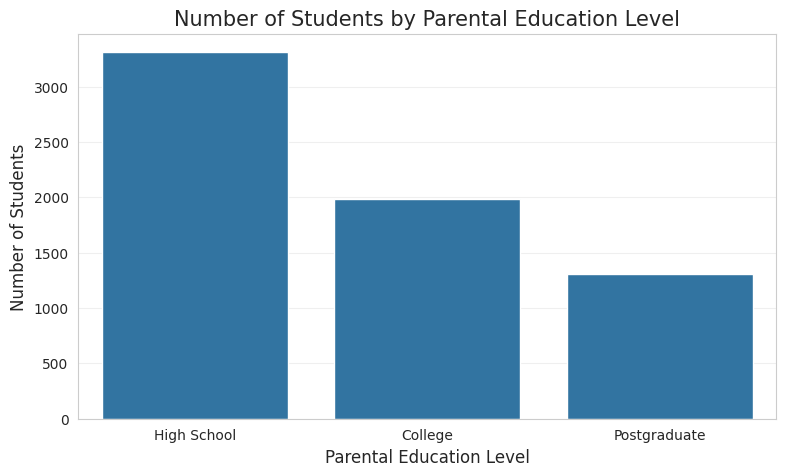


5. AVERAGE EXAM SCORE BY PARENTAL EDUCATION


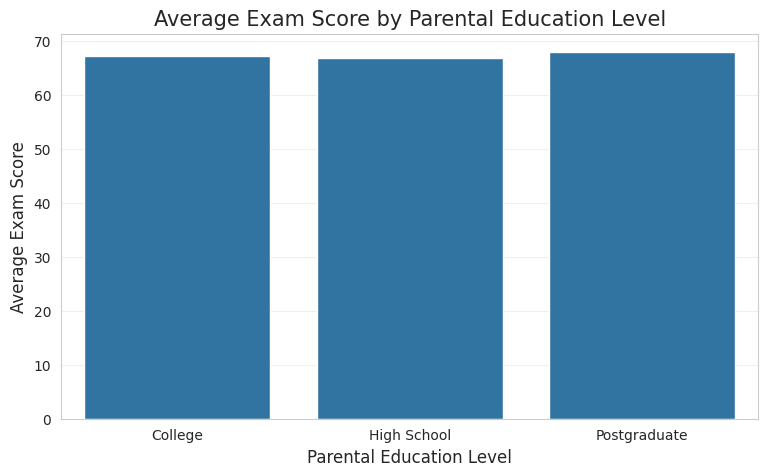


6. EXAM SCORE DISTRIBUTION BY PARENTAL EDUCATION


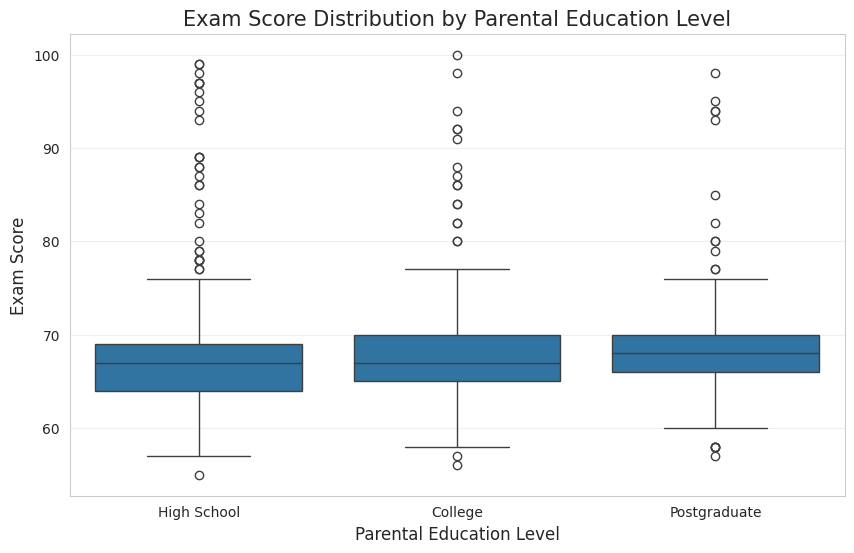


7. INDIVIDUAL SCORE DISTRIBUTION


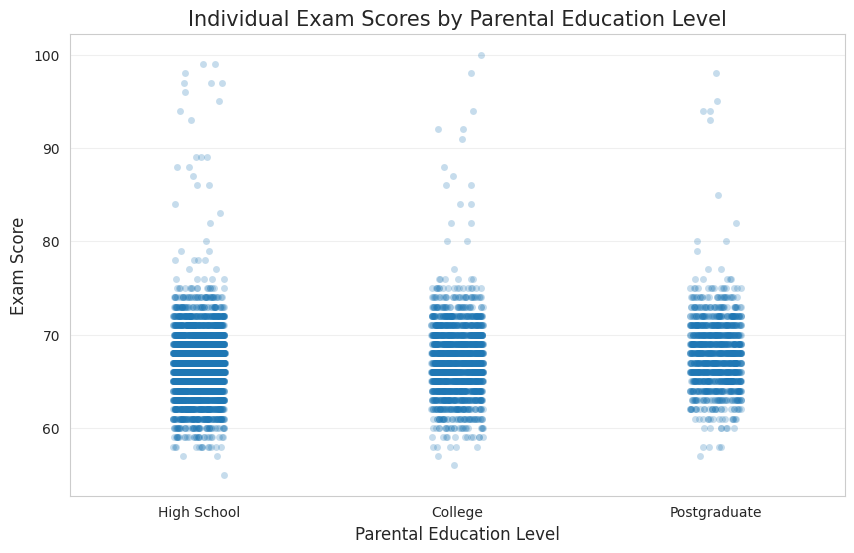


8. GROUP COMPARISON

Highest average exam score group: Postgraduate
Average score: 67.97

Lowest average exam score group: High School
Average score: 66.89

9. SCORE RANGE COMPARISON

College:
  Students : 1989
  Mean     : 67.32
  Median   : 67.0
  Minimum  : 56
  Maximum  : 100

High School:
  Students : 3312
  Mean     : 66.89
  Median   : 67.0
  Minimum  : 55
  Maximum  : 99

Postgraduate:
  Students : 1305
  Mean     : 67.97
  Median   : 68.0
  Minimum  : 57
  Maximum  : 98

10. STEP 17.4 SUMMARY

The analysis compares examination performance across different parental education levels.
Group means and medians are used to compare central exam-score tendencies.
The boxplot shows the distribution and spread of exam scores within each education group.
The count plot shows the number of students represented in each category.

Note: Differences between groups indicate association and should not be interpreted as evidence of causation.

STEP 17.4 COMPLETED SUCCESSFULLY


In [25]:
# ============================================================
# STEP 17.4 — PARENTAL EDUCATION LEVEL VS EXAM SCORE
# Complete Categorical Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.4 — PARENTAL EDUCATION LEVEL VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Parental_Education_Level",
    "Exam_Score"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:

    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")
    print(
        "Parental_Education_Level and Exam_Score "
        "are ready for analysis."
    )


    # --------------------------------------------------------
    # 2. CHECK CATEGORY DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("1. PARENTAL EDUCATION LEVEL DISTRIBUTION")
    print("=" * 70)

    education_counts = (
        df_clean["Parental_Education_Level"]
        .value_counts()
    )

    print("\nNumber of students in each category:")
    print(education_counts)


    # --------------------------------------------------------
    # 3. BASIC EXAM SCORE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. EXAM SCORE BASIC STATISTICS")
    print("=" * 70)

    print("\nOverall Exam Score Statistics:")

    print(
        df_clean["Exam_Score"].describe()
    )


    # --------------------------------------------------------
    # 4. GROUP-WISE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. EXAM PERFORMANCE BY PARENTAL EDUCATION")
    print("=" * 70)

    education_summary = (
        df_clean
        .groupby(
            "Parental_Education_Level",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )


    # Round numerical values

    education_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ] = education_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ].round(2)


    print(
        "\nExam Performance by Parental Education Level:"
    )

    display(education_summary)


    # --------------------------------------------------------
    # 5. BAR CHART — STUDENT COUNT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. STUDENT COUNT BY PARENTAL EDUCATION")
    print("=" * 70)

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df_clean,
        x="Parental_Education_Level"
    )

    plt.title(
        "Number of Students by Parental Education Level",
        fontsize=15
    )

    plt.xlabel(
        "Parental Education Level",
        fontsize=12
    )

    plt.ylabel(
        "Number of Students",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 6. BAR CHART — AVERAGE EXAM SCORE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. AVERAGE EXAM SCORE BY PARENTAL EDUCATION")
    print("=" * 70)

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=education_summary,
        x="Parental_Education_Level",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Parental Education Level",
        fontsize=15
    )

    plt.xlabel(
        "Parental Education Level",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 7. BOXPLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. EXAM SCORE DISTRIBUTION BY PARENTAL EDUCATION")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df_clean,
        x="Parental_Education_Level",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Parental Education Level",
        fontsize=15
    )

    plt.xlabel(
        "Parental Education Level",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 8. STRIP PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. INDIVIDUAL SCORE DISTRIBUTION")
    print("=" * 70)

    plt.figure(figsize=(10, 6))

    sns.stripplot(
        data=df_clean,
        x="Parental_Education_Level",
        y="Exam_Score",
        alpha=0.25,
        jitter=True
    )

    plt.title(
        "Individual Exam Scores by Parental Education Level",
        fontsize=15
    )

    plt.xlabel(
        "Parental Education Level",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 9. HIGHEST AND LOWEST GROUP MEAN
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. GROUP COMPARISON")
    print("=" * 70)

    highest_group = education_summary.loc[
        education_summary["Mean"].idxmax()
    ]

    lowest_group = education_summary.loc[
        education_summary["Mean"].idxmin()
    ]

    print(
        f"\nHighest average exam score group: "
        f"{highest_group['Parental_Education_Level']}"
    )

    print(
        f"Average score: "
        f"{highest_group['Mean']}"
    )

    print(
        f"\nLowest average exam score group: "
        f"{lowest_group['Parental_Education_Level']}"
    )

    print(
        f"Average score: "
        f"{lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 10. SCORE RANGE COMPARISON
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. SCORE RANGE COMPARISON")
    print("=" * 70)

    for _, row in education_summary.iterrows():

        print(
            f"\n{row['Parental_Education_Level']}:"
        )

        print(
            f"  Students : {int(row['Count'])}"
        )

        print(
            f"  Mean     : {row['Mean']}"
        )

        print(
            f"  Median   : {row['Median']}"
        )

        print(
            f"  Minimum  : {row['Minimum']}"
        )

        print(
            f"  Maximum  : {row['Maximum']}"
        )


    # --------------------------------------------------------
    # 11. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("10. STEP 17.4 SUMMARY")
    print("=" * 70)

    print(
        "\nThe analysis compares examination performance "
        "across different parental education levels."
    )

    print(
        "Group means and medians are used to compare "
        "central exam-score tendencies."
    )

    print(
        "The boxplot shows the distribution and spread "
        "of exam scores within each education group."
    )

    print(
        "The count plot shows the number of students "
        "represented in each category."
    )

    print(
        "\nNote: Differences between groups indicate "
        "association and should not be interpreted as "
        "evidence of causation."
    )


    # --------------------------------------------------------
    # 12. FINAL COMPLETION MESSAGE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STEP 17.4 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 17.5 — INTERNET ACCESS VS EXAM SCORE

Required columns found successfully.
Internet_Access and Exam_Score are ready for analysis.

1. INTERNET ACCESS DISTRIBUTION

Number of students in each category:
Internet_Access
Yes    6108
No      498
Name: count, dtype: int64

Percentage of students in each category:
Internet_Access
Yes    92.46
No      7.54
Name: proportion, dtype: float64

2. OVERALL EXAM SCORE STATISTICS
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

3. EXAM PERFORMANCE BY INTERNET ACCESS

Exam Performance by Internet Access:


,Internet_Access,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,No,498,66.47,66.0,3.82,58,93
1,Yes,6108,67.29,67.0,3.87,55,100



4. STUDENT COUNT BY INTERNET ACCESS


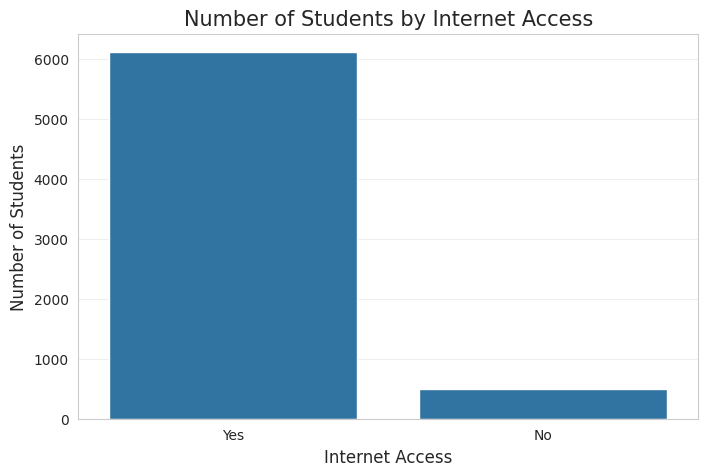


5. AVERAGE EXAM SCORE BY INTERNET ACCESS


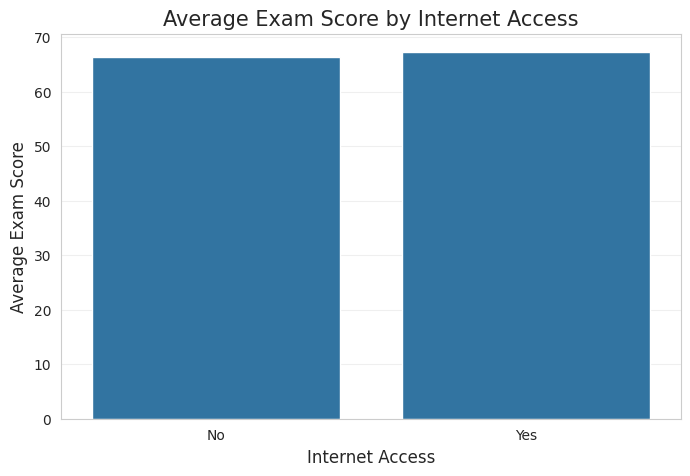


6. EXAM SCORE DISTRIBUTION BY INTERNET ACCESS


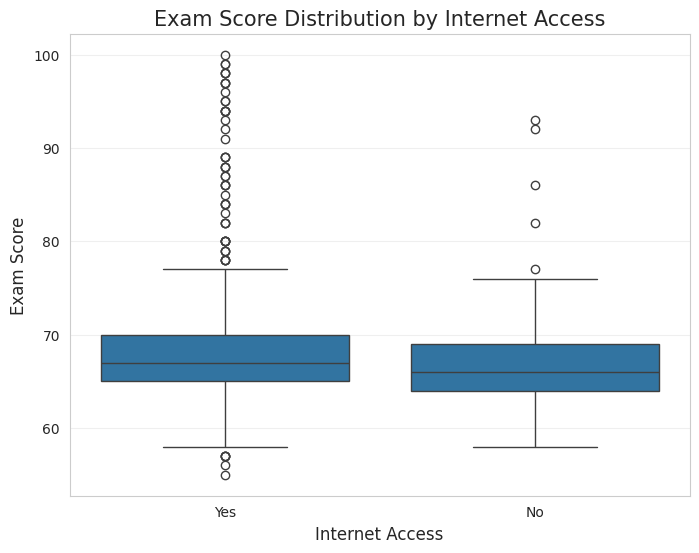


7. INDIVIDUAL EXAM SCORES BY INTERNET ACCESS


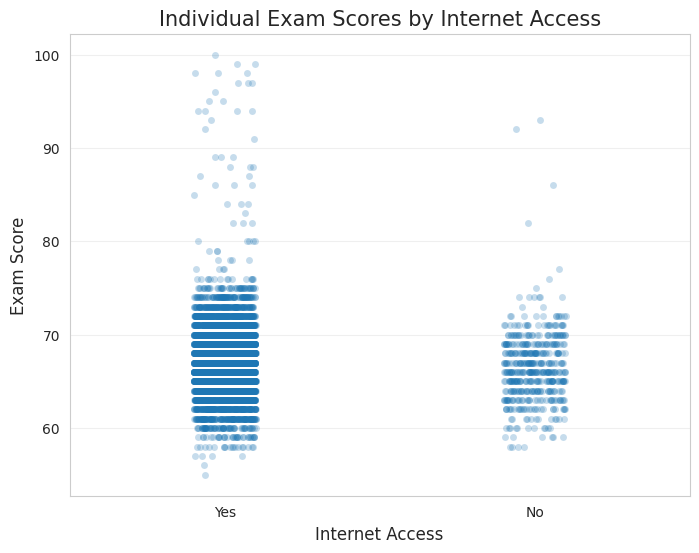


8. GROUP COMPARISON

Higher average exam score group: Yes
Average score: 67.29

Lower average exam score group: No
Average score: 66.47

Difference between group mean scores: 0.82

9. STEP 17.5 SUMMARY

The analysis compares examination performance between students with and without internet access.
Group means and medians are used to compare central exam-score tendencies.
The boxplot shows the distribution and spread of exam scores within each internet-access group.
The count plot shows the number of students represented in each category.

Note: Differences between groups indicate association and should not be interpreted as evidence of causation.

STEP 17.5 COMPLETED SUCCESSFULLY


In [26]:
# ============================================================
# STEP 17.5 — INTERNET ACCESS VS EXAM SCORE
# Complete Categorical Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.5 — INTERNET ACCESS VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Internet_Access",
    "Exam_Score"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:

    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")
    print(
        "Internet_Access and Exam_Score "
        "are ready for analysis."
    )


    # --------------------------------------------------------
    # 2. CHECK CATEGORY DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("1. INTERNET ACCESS DISTRIBUTION")
    print("=" * 70)

    internet_counts = (
        df_clean["Internet_Access"]
        .value_counts()
    )

    print("\nNumber of students in each category:")
    print(internet_counts)


    # --------------------------------------------------------
    # 3. CALCULATE PERCENTAGE DISTRIBUTION
    # --------------------------------------------------------

    internet_percentages = (
        df_clean["Internet_Access"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("\nPercentage of students in each category:")
    print(internet_percentages)


    # --------------------------------------------------------
    # 4. OVERALL EXAM SCORE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. OVERALL EXAM SCORE STATISTICS")
    print("=" * 70)

    print(
        df_clean["Exam_Score"].describe()
    )


    # --------------------------------------------------------
    # 5. GROUP-WISE EXAM SCORE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. EXAM PERFORMANCE BY INTERNET ACCESS")
    print("=" * 70)

    internet_summary = (
        df_clean
        .groupby(
            "Internet_Access",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )


    # Round numerical values

    internet_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ] = internet_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ].round(2)


    print(
        "\nExam Performance by Internet Access:"
    )

    display(internet_summary)


    # --------------------------------------------------------
    # 6. COUNT PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. STUDENT COUNT BY INTERNET ACCESS")
    print("=" * 70)

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df_clean,
        x="Internet_Access"
    )

    plt.title(
        "Number of Students by Internet Access",
        fontsize=15
    )

    plt.xlabel(
        "Internet Access",
        fontsize=12
    )

    plt.ylabel(
        "Number of Students",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 7. AVERAGE EXAM SCORE BAR CHART
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. AVERAGE EXAM SCORE BY INTERNET ACCESS")
    print("=" * 70)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=internet_summary,
        x="Internet_Access",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Internet Access",
        fontsize=15
    )

    plt.xlabel(
        "Internet Access",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 8. BOXPLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. EXAM SCORE DISTRIBUTION BY INTERNET ACCESS")
    print("=" * 70)

    plt.figure(figsize=(8, 6))

    sns.boxplot(
        data=df_clean,
        x="Internet_Access",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Internet Access",
        fontsize=15
    )

    plt.xlabel(
        "Internet Access",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 9. INDIVIDUAL SCORE DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. INDIVIDUAL EXAM SCORES BY INTERNET ACCESS")
    print("=" * 70)

    plt.figure(figsize=(8, 6))

    sns.stripplot(
        data=df_clean,
        x="Internet_Access",
        y="Exam_Score",
        alpha=0.25,
        jitter=True
    )

    plt.title(
        "Individual Exam Scores by Internet Access",
        fontsize=15
    )

    plt.xlabel(
        "Internet Access",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 10. COMPARE GROUP MEANS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. GROUP COMPARISON")
    print("=" * 70)

    highest_group = internet_summary.loc[
        internet_summary["Mean"].idxmax()
    ]

    lowest_group = internet_summary.loc[
        internet_summary["Mean"].idxmin()
    ]

    print(
        f"\nHigher average exam score group: "
        f"{highest_group['Internet_Access']}"
    )

    print(
        f"Average score: "
        f"{highest_group['Mean']}"
    )

    print(
        f"\nLower average exam score group: "
        f"{lowest_group['Internet_Access']}"
    )

    print(
        f"Average score: "
        f"{lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 11. DIFFERENCE IN GROUP MEANS
    # --------------------------------------------------------

    if len(internet_summary) == 2:

        mean_difference = (
            highest_group["Mean"]
            - lowest_group["Mean"]
        )

        print(
            "\nDifference between group mean scores:",
            round(mean_difference, 2)
        )


    # --------------------------------------------------------
    # 12. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. STEP 17.5 SUMMARY")
    print("=" * 70)

    print(
        "\nThe analysis compares examination performance "
        "between students with and without internet access."
    )

    print(
        "Group means and medians are used to compare "
        "central exam-score tendencies."
    )

    print(
        "The boxplot shows the distribution and spread "
        "of exam scores within each internet-access group."
    )

    print(
        "The count plot shows the number of students "
        "represented in each category."
    )

    print(
        "\nNote: Differences between groups indicate "
        "association and should not be interpreted as "
        "evidence of causation."
    )


    # --------------------------------------------------------
    # 13. COMPLETION MESSAGE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STEP 17.5 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 17.6 — EXTRACURRICULAR ACTIVITIES VS EXAM SCORE

Required columns found successfully.
Extracurricular_Activities and Exam_Score are ready for analysis.

1. EXTRACURRICULAR ACTIVITIES DISTRIBUTION

Number of students in each category:
Extracurricular_Activities
Yes    3937
No     2669
Name: count, dtype: int64

Percentage of students in each category:
Extracurricular_Activities
Yes    59.6
No     40.4
Name: proportion, dtype: float64

2. OVERALL EXAM SCORE STATISTICS
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

3. EXAM PERFORMANCE BY EXTRACURRICULAR ACTIVITIES

Exam Performance by Extracurricular Activity:


,Extracurricular_Activities,Count,Mean,Median,Std_Dev,Minimum,Maximum
0,No,2669,66.93,67.0,3.79,55,97
1,Yes,3937,67.43,67.0,3.91,57,100



4. STUDENT COUNT BY EXTRACURRICULAR ACTIVITIES


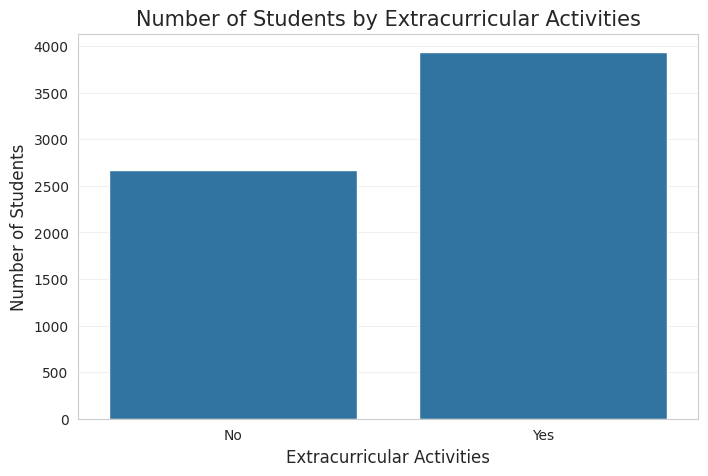


5. AVERAGE EXAM SCORE BY EXTRACURRICULAR ACTIVITIES


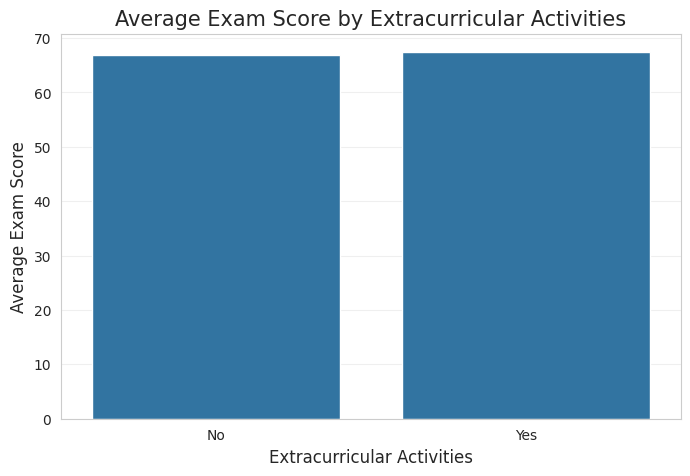


6. EXAM SCORE DISTRIBUTION BY EXTRACURRICULAR ACTIVITIES


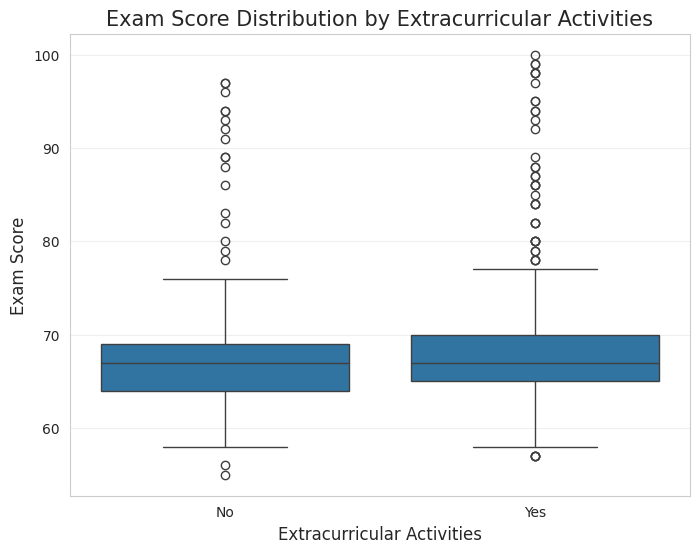


7. INDIVIDUAL EXAM SCORES BY EXTRACURRICULAR ACTIVITIES


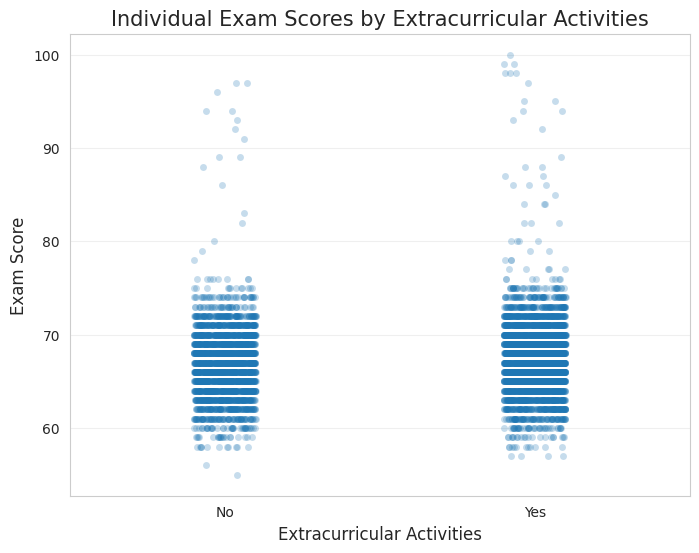


8. GROUP COMPARISON

Higher average exam score group: Yes
Average score: 67.43

Lower average exam score group: No
Average score: 66.93

Difference between group mean scores: 0.5
Difference between group median scores: 0.0

9. STEP 17.6 SUMMARY

The analysis compares examination performance between students who participate in extracurricular activities and those who do not.
Group means and medians are used to compare central exam-score tendencies.
The boxplot shows the distribution and spread of exam scores within each activity group.
The count plot shows the number of students represented in each category.

Note: Differences between groups indicate association and should not be interpreted as evidence of causation.

STEP 17.6 COMPLETED SUCCESSFULLY


In [27]:
# ============================================================
# STEP 17.6 — EXTRACURRICULAR ACTIVITIES VS EXAM SCORE
# Complete Categorical Relationship Analysis
# ============================================================

print("=" * 70)
print("STEP 17.6 — EXTRACURRICULAR ACTIVITIES VS EXAM SCORE")
print("=" * 70)


# ------------------------------------------------------------
# 1. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "Extracurricular_Activities",
    "Exam_Score"
]

missing_columns = [
    column
    for column in required_columns
    if column not in df_clean.columns
]

if missing_columns:

    print("\nERROR: Required columns are missing:")
    print(missing_columns)

else:

    print("\nRequired columns found successfully.")

    print(
        "Extracurricular_Activities and Exam_Score "
        "are ready for analysis."
    )


    # --------------------------------------------------------
    # 2. CATEGORY DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("1. EXTRACURRICULAR ACTIVITIES DISTRIBUTION")
    print("=" * 70)

    extracurricular_counts = (
        df_clean["Extracurricular_Activities"]
        .value_counts()
    )

    print("\nNumber of students in each category:")
    print(extracurricular_counts)


    # --------------------------------------------------------
    # 3. PERCENTAGE DISTRIBUTION
    # --------------------------------------------------------

    extracurricular_percentages = (
        df_clean["Extracurricular_Activities"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    print("\nPercentage of students in each category:")
    print(extracurricular_percentages)


    # --------------------------------------------------------
    # 4. OVERALL EXAM SCORE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("2. OVERALL EXAM SCORE STATISTICS")
    print("=" * 70)

    print(
        df_clean["Exam_Score"].describe()
    )


    # --------------------------------------------------------
    # 5. GROUP-WISE EXAM SCORE STATISTICS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("3. EXAM PERFORMANCE BY EXTRACURRICULAR ACTIVITIES")
    print("=" * 70)

    extracurricular_summary = (
        df_clean
        .groupby(
            "Extracurricular_Activities",
            observed=True
        )["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .reset_index()
    )


    # Round numerical values

    extracurricular_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ] = extracurricular_summary[
        [
            "Mean",
            "Median",
            "Std_Dev",
            "Minimum",
            "Maximum"
        ]
    ].round(2)


    print(
        "\nExam Performance by Extracurricular Activity:"
    )

    display(extracurricular_summary)


    # --------------------------------------------------------
    # 6. STUDENT COUNT PLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("4. STUDENT COUNT BY EXTRACURRICULAR ACTIVITIES")
    print("=" * 70)

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df_clean,
        x="Extracurricular_Activities"
    )

    plt.title(
        "Number of Students by Extracurricular Activities",
        fontsize=15
    )

    plt.xlabel(
        "Extracurricular Activities",
        fontsize=12
    )

    plt.ylabel(
        "Number of Students",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 7. AVERAGE EXAM SCORE BAR CHART
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("5. AVERAGE EXAM SCORE BY EXTRACURRICULAR ACTIVITIES")
    print("=" * 70)

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=extracurricular_summary,
        x="Extracurricular_Activities",
        y="Mean"
    )

    plt.title(
        "Average Exam Score by Extracurricular Activities",
        fontsize=15
    )

    plt.xlabel(
        "Extracurricular Activities",
        fontsize=12
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 8. BOXPLOT
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("6. EXAM SCORE DISTRIBUTION BY EXTRACURRICULAR ACTIVITIES")
    print("=" * 70)

    plt.figure(figsize=(8, 6))

    sns.boxplot(
        data=df_clean,
        x="Extracurricular_Activities",
        y="Exam_Score"
    )

    plt.title(
        "Exam Score Distribution by Extracurricular Activities",
        fontsize=15
    )

    plt.xlabel(
        "Extracurricular Activities",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 9. INDIVIDUAL SCORE DISTRIBUTION
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("7. INDIVIDUAL EXAM SCORES BY EXTRACURRICULAR ACTIVITIES")
    print("=" * 70)

    plt.figure(figsize=(8, 6))

    sns.stripplot(
        data=df_clean,
        x="Extracurricular_Activities",
        y="Exam_Score",
        alpha=0.25,
        jitter=True
    )

    plt.title(
        "Individual Exam Scores by Extracurricular Activities",
        fontsize=15
    )

    plt.xlabel(
        "Extracurricular Activities",
        fontsize=12
    )

    plt.ylabel(
        "Exam Score",
        fontsize=12
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


    # --------------------------------------------------------
    # 10. GROUP COMPARISON
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("8. GROUP COMPARISON")
    print("=" * 70)

    highest_group = extracurricular_summary.loc[
        extracurricular_summary["Mean"].idxmax()
    ]

    lowest_group = extracurricular_summary.loc[
        extracurricular_summary["Mean"].idxmin()
    ]

    print(
        f"\nHigher average exam score group: "
        f"{highest_group['Extracurricular_Activities']}"
    )

    print(
        f"Average score: "
        f"{highest_group['Mean']}"
    )

    print(
        f"\nLower average exam score group: "
        f"{lowest_group['Extracurricular_Activities']}"
    )

    print(
        f"Average score: "
        f"{lowest_group['Mean']}"
    )


    # --------------------------------------------------------
    # 11. DIFFERENCE BETWEEN GROUP MEANS
    # --------------------------------------------------------

    if len(extracurricular_summary) == 2:

        mean_difference = (
            highest_group["Mean"]
            - lowest_group["Mean"]
        )

        print(
            "\nDifference between group mean scores:",
            round(mean_difference, 2)
        )


    # --------------------------------------------------------
    # 12. MEDIAN DIFFERENCE
    # --------------------------------------------------------

    if len(extracurricular_summary) == 2:

        highest_median = highest_group["Median"]
        lowest_median = lowest_group["Median"]

        median_difference = (
            highest_median
            - lowest_median
        )

        print(
            "Difference between group median scores:",
            round(median_difference, 2)
        )


    # --------------------------------------------------------
    # 13. FINAL SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("9. STEP 17.6 SUMMARY")
    print("=" * 70)

    print(
        "\nThe analysis compares examination performance "
        "between students who participate in extracurricular "
        "activities and those who do not."
    )

    print(
        "Group means and medians are used to compare "
        "central exam-score tendencies."
    )

    print(
        "The boxplot shows the distribution and spread "
        "of exam scores within each activity group."
    )

    print(
        "The count plot shows the number of students "
        "represented in each category."
    )

    print(
        "\nNote: Differences between groups indicate "
        "association and should not be interpreted as "
        "evidence of causation."
    )


    # --------------------------------------------------------
    # 14. COMPLETION MESSAGE
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STEP 17.6 COMPLETED SUCCESSFULLY")
    print("=" * 70)

STEP 18: CORRELATION ANALYSIS OF ALL NUMERICAL FEATURES

18.1 NUMERICAL FEATURES
--------------------------------------------------
Numerical Features:
1. Hours_Studied
2. Attendance
3. Sleep_Hours
4. Previous_Scores
5. Tutoring_Sessions
6. Physical_Activity
7. Exam_Score

Total Numerical Features: 7

18.2 CORRELATION MATRIX
--------------------------------------------------

Correlation Matrix:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
Hours_Studied,1.000,-0.010,0.011,0.025,-0.015,0.005,0.447
Attendance,-0.010,1.000,-0.016,-0.020,0.014,-0.022,0.582
Sleep_Hours,0.011,-0.016,1.000,-0.022,-0.012,-0.000,-0.016
Previous_Scores,0.025,-0.020,-0.022,1.000,-0.014,-0.011,0.174
Tutoring_Sessions,-0.015,0.014,-0.012,-0.014,1.000,0.018,0.154
Physical_Activity,0.005,-0.022,-0.000,-0.011,0.018,1.000,0.028
Exam_Score,0.447,0.582,-0.016,0.174,0.154,0.028,1.000



18.3 CORRELATION HEATMAP
--------------------------------------------------


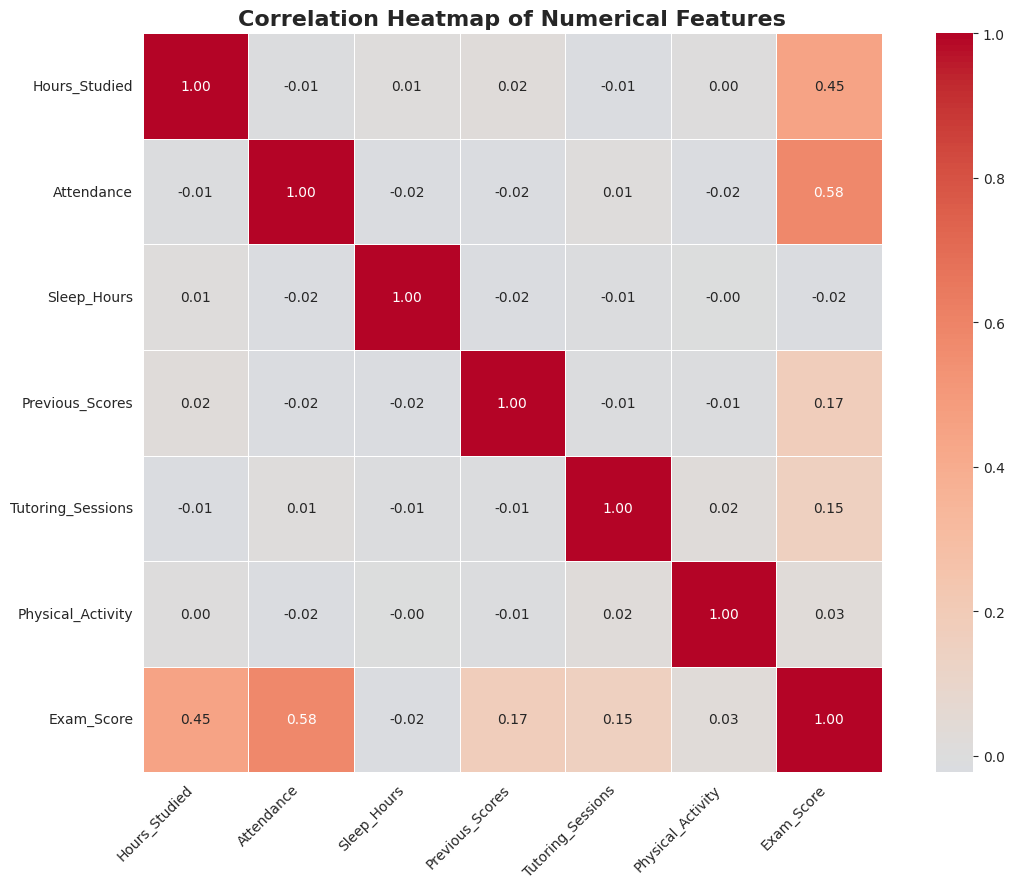


18.4 CORRELATION WITH EXAM SCORE
--------------------------------------------------

Features ranked by absolute correlation with Exam_Score:


,Correlation_with_Exam_Score
Attendance,0.5825
Hours_Studied,0.4465
Previous_Scores,0.1745
Tutoring_Sessions,0.1538
Physical_Activity,0.0279
Sleep_Hours,-0.0162



18.5 DETAILED CORRELATION TABLE
--------------------------------------------------


,Feature,Correlation,Absolute_Correlation,Interpretation
0,Attendance,0.5825,0.5825,Strong Positive
1,Hours_Studied,0.4465,0.4465,Moderate Positive
2,Previous_Scores,0.1745,0.1745,Weak Positive
3,Tutoring_Sessions,0.1538,0.1538,Weak Positive
4,Physical_Activity,0.0279,0.0279,Very Weak Positive
5,Sleep_Hours,-0.0162,0.0162,Very Weak Negative



18.6 CORRELATION BAR CHART
--------------------------------------------------


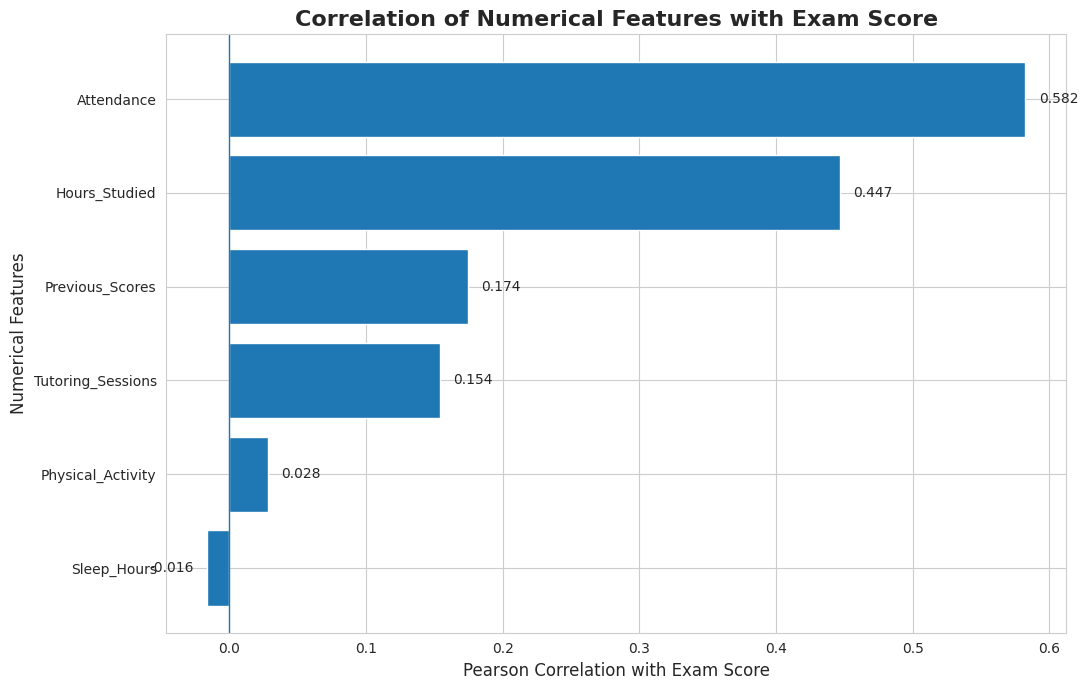


18.7 STRONGEST RELATIONSHIPS WITH EXAM SCORE
--------------------------------------------------

Strongest Positive Relationship:
Feature     : Attendance
Correlation : 0.5825

Strongest Negative Relationship:
Feature     : Sleep_Hours
Correlation : -0.0162

18.8 TOP 3 FEATURES BY ABSOLUTE CORRELATION
--------------------------------------------------
1. Attendance → Correlation = 0.5825
2. Hours_Studied → Correlation = 0.4465
3. Previous_Scores → Correlation = 0.1745

18.9 CHECK FOR HIGH CORRELATION BETWEEN PREDICTOR FEATURES
--------------------------------------------------

No predictor feature pairs have absolute correlation >= 0.70.

18.10 INTERPRETATION
--------------------------------------------------

The correlation analysis shows the linear relationship between the numerical features and Exam_Score.

• The strongest positive numerical relationship with Exam_Score is Attendance with a correlation of 0.5825.
• The strongest negative numerical relationship with Exam_Score is 

In [28]:
# ============================================================
# STEP 18: CORRELATION ANALYSIS OF ALL NUMERICAL FEATURES
# ============================================================

print("=" * 80)
print("STEP 18: CORRELATION ANALYSIS OF ALL NUMERICAL FEATURES")
print("=" * 80)


# ------------------------------------------------------------
# 18.1 SELECT NUMERICAL FEATURES
# ------------------------------------------------------------

print("\n18.1 NUMERICAL FEATURES")
print("-" * 50)

# Automatically identify numerical columns
numerical_features = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Features:")
for i, column in enumerate(numerical_features, start=1):
    print(f"{i}. {column}")

print(f"\nTotal Numerical Features: {len(numerical_features)}")


# ------------------------------------------------------------
# 18.2 CREATE CORRELATION MATRIX
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.2 CORRELATION MATRIX")
print("-" * 50)

# Calculate Pearson correlation
correlation_matrix = df_clean[numerical_features].corr()

# Display correlation matrix
print("\nCorrelation Matrix:")
display(correlation_matrix.round(3))


# ------------------------------------------------------------
# 18.3 VISUALIZE CORRELATION MATRIX USING HEATMAP
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.3 CORRELATION HEATMAP")
print("-" * 50)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap of Numerical Features",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 18.4 CORRELATION OF FEATURES WITH EXAM SCORE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.4 CORRELATION WITH EXAM SCORE")
print("-" * 50)

# Extract correlation values with Exam_Score
exam_score_correlations = correlation_matrix["Exam_Score"].drop(
    "Exam_Score"
)

# Sort by absolute correlation strength
exam_score_correlations_sorted = exam_score_correlations.reindex(
    exam_score_correlations.abs().sort_values(
        ascending=False
    ).index
)

print("\nFeatures ranked by absolute correlation with Exam_Score:")
display(
    exam_score_correlations_sorted
    .to_frame(name="Correlation_with_Exam_Score")
    .round(4)
)


# ------------------------------------------------------------
# 18.5 CREATE CORRELATION TABLE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.5 DETAILED CORRELATION TABLE")
print("-" * 50)

correlation_table = pd.DataFrame({
    "Feature": exam_score_correlations_sorted.index,
    "Correlation": exam_score_correlations_sorted.values,
    "Absolute_Correlation": exam_score_correlations_sorted.abs().values
})

# Add interpretation
def interpret_correlation(value):
    absolute_value = abs(value)

    if absolute_value >= 0.70:
        strength = "Very Strong"
    elif absolute_value >= 0.50:
        strength = "Strong"
    elif absolute_value >= 0.30:
        strength = "Moderate"
    elif absolute_value >= 0.10:
        strength = "Weak"
    else:
        strength = "Very Weak"

    if value > 0:
        direction = "Positive"
    elif value < 0:
        direction = "Negative"
    else:
        direction = "No"

    if value == 0:
        return "No Correlation"

    return f"{strength} {direction}"

correlation_table["Interpretation"] = (
    correlation_table["Correlation"]
    .apply(interpret_correlation)
)

display(correlation_table.round(4))


# ------------------------------------------------------------
# 18.6 BAR CHART OF CORRELATION WITH EXAM SCORE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.6 CORRELATION BAR CHART")
print("-" * 50)

# Sort by actual correlation value for visualization
plot_data = exam_score_correlations.sort_values()

plt.figure(figsize=(11, 7))

bars = plt.barh(
    plot_data.index,
    plot_data.values
)

plt.axvline(
    x=0,
    linewidth=1
)

plt.xlabel(
    "Pearson Correlation with Exam Score",
    fontsize=12
)

plt.ylabel(
    "Numerical Features",
    fontsize=12
)

plt.title(
    "Correlation of Numerical Features with Exam Score",
    fontsize=16,
    fontweight="bold"
)

# Add values at the end of each bar
for bar, value in zip(bars, plot_data.values):

    if value >= 0:
        x_position = value + 0.01
        horizontal_alignment = "left"
    else:
        x_position = value - 0.01
        horizontal_alignment = "right"

    plt.text(
        x_position,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha=horizontal_alignment,
        fontsize=10
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 18.7 IDENTIFY STRONGEST POSITIVE AND NEGATIVE RELATIONSHIPS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.7 STRONGEST RELATIONSHIPS WITH EXAM SCORE")
print("-" * 50)

# Strongest positive relationship
strongest_positive_feature = exam_score_correlations.idxmax()
strongest_positive_value = exam_score_correlations.max()

# Strongest negative relationship
strongest_negative_feature = exam_score_correlations.idxmin()
strongest_negative_value = exam_score_correlations.min()

print(
    f"\nStrongest Positive Relationship:"
)
print(
    f"Feature     : {strongest_positive_feature}"
)
print(
    f"Correlation : {strongest_positive_value:.4f}"
)

print(
    f"\nStrongest Negative Relationship:"
)
print(
    f"Feature     : {strongest_negative_feature}"
)
print(
    f"Correlation : {strongest_negative_value:.4f}"
)


# ------------------------------------------------------------
# 18.8 TOP 3 FEATURES CORRELATED WITH EXAM SCORE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.8 TOP 3 FEATURES BY ABSOLUTE CORRELATION")
print("-" * 50)

top_3_features = exam_score_correlations.abs().sort_values(
    ascending=False
).head(3)

for rank, feature in enumerate(top_3_features.index, start=1):

    correlation_value = exam_score_correlations[feature]

    print(
        f"{rank}. {feature} "
        f"→ Correlation = {correlation_value:.4f}"
    )


# ------------------------------------------------------------
# 18.9 CHECK FOR HIGH CORRELATION BETWEEN PREDICTOR FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.9 CHECK FOR HIGH CORRELATION BETWEEN PREDICTOR FEATURES")
print("-" * 50)

# Create correlation matrix without target
predictor_features = [
    feature
    for feature in numerical_features
    if feature != "Exam_Score"
]

predictor_correlation = df_clean[predictor_features].corr()

# Find highly correlated pairs
high_correlation_pairs = []

for i in range(len(predictor_features)):

    for j in range(i + 1, len(predictor_features)):

        feature_1 = predictor_features[i]
        feature_2 = predictor_features[j]

        correlation_value = predictor_correlation.loc[
            feature_1,
            feature_2
        ]

        if abs(correlation_value) >= 0.70:

            high_correlation_pairs.append({
                "Feature_1": feature_1,
                "Feature_2": feature_2,
                "Correlation": correlation_value
            })

if len(high_correlation_pairs) > 0:

    high_corr_df = pd.DataFrame(
        high_correlation_pairs
    ).sort_values(
        by="Correlation",
        key=lambda x: x.abs(),
        ascending=False
    )

    print(
        "\nHighly correlated predictor pairs "
        "(absolute correlation >= 0.70):"
    )

    display(high_corr_df.round(4))

else:

    print(
        "\nNo predictor feature pairs have "
        "absolute correlation >= 0.70."
    )


# ------------------------------------------------------------
# 18.10 AUTOMATIC INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.10 INTERPRETATION")
print("-" * 50)

print(
    "\nThe correlation analysis shows the linear relationship "
    "between the numerical features and Exam_Score."
)

print(
    f"\n• The strongest positive numerical relationship with "
    f"Exam_Score is {strongest_positive_feature} "
    f"with a correlation of {strongest_positive_value:.4f}."
)

print(
    f"• The strongest negative numerical relationship with "
    f"Exam_Score is {strongest_negative_feature} "
    f"with a correlation of {strongest_negative_value:.4f}."
)

print(
    "\n• A positive correlation means that higher values of a "
    "feature tend to be associated with higher Exam_Score values."
)

print(
    "\n• A negative correlation means that higher values of a "
    "feature tend to be associated with lower Exam_Score values."
)

print(
    "\n• Correlation measures association, not causation. "
    "Therefore, these results do not prove that changing one "
    "feature directly causes a change in Exam_Score."
)


# ------------------------------------------------------------
# 18.11 CLASSIFY IMPORTANT FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("18.11 FEATURE RELATIONSHIP SUMMARY")
print("-" * 50)

for feature, correlation_value in (
    exam_score_correlations_sorted.items()
):

    interpretation = interpret_correlation(
        correlation_value
    )

    print(
        f"{feature:25s} : "
        f"{correlation_value: .4f} → "
        f"{interpretation}"
    )


# ------------------------------------------------------------
# 18.12 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 18 COMPLETED")
print("=" * 80)

print(
    "\nWhat we performed:"
)

print(
    "1. Identified all numerical features."
)

print(
    "2. Calculated the Pearson correlation matrix."
)

print(
    "3. Visualized relationships using a correlation heatmap."
)

print(
    "4. Calculated the correlation of every numerical feature "
    "with Exam_Score."
)

print(
    "5. Ranked numerical features based on their absolute "
    "correlation with Exam_Score."
)

print(
    "6. Created a correlation bar chart."
)

print(
    "7. Identified the strongest positive and negative "
    "relationships."
)

print(
    "8. Checked for highly correlated predictor features."
)

print(
    "9. Generated an automatic interpretation of the results."
)

print(
    "\nThese results will help us decide which features "
    "should be considered important during the machine "
    "learning stage."
)

print("\n" + "=" * 80)

STEP 19: CATEGORICAL FEATURES VS EXAM SCORE

19.1 CATEGORICAL FEATURES
--------------------------------------------------
Categorical Features:
1. Parental_Involvement
2. Access_to_Resources
3. Extracurricular_Activities
4. Motivation_Level
5. Internet_Access
6. Family_Income
7. Teacher_Quality
8. School_Type
9. Peer_Influence
10. Learning_Disabilities
11. Parental_Education_Level
12. Distance_from_Home
13. Gender

Total Categorical Features: 13

19.2 UNIQUE CATEGORIES
--------------------------------------------------


,Feature,Unique_Categories
0,Parental_Involvement,3
1,Access_to_Resources,3
2,Extracurricular_Activities,2
3,Motivation_Level,3
4,Internet_Access,2
5,Family_Income,3
6,Teacher_Quality,3
7,School_Type,2
8,Peer_Influence,3
9,Learning_Disabilities,2



19.3 CATEGORY DISTRIBUTION
--------------------------------------------------

------------------------------------------------------------
Feature: Parental_Involvement
------------------------------------------------------------


,Count,Percentage
Parental_Involvement,,
Medium,3362,50.89
High,1908,28.88
Low,1336,20.22



------------------------------------------------------------
Feature: Access_to_Resources
------------------------------------------------------------


...

Highest average Exam Score: Near → 67.49
Lowest average Exam Score: Far → 66.46
Difference between highest and lowest group: 1.04


ANALYSIS: Gender vs Exam_Score

Group-wise Exam Score Statistics:


,Count,Mean,Median,Std_Dev,Minimum,Maximum
Gender,,,,,,
Female,2792,67.23,67.0,4.00,57,100
Male,3814,67.23,67.0,3.77,55,99


Highest average Exam Score: Female → 67.23
Lowest average Exam Score: Male → 67.23
Difference between highest and lowest group: 0.00

19.5 OVERALL CATEGORICAL ANALYSIS SUMMARY
--------------------------------------------------


,Feature,Highest_Mean_Category,Highest_Mean,Lowest_Mean_Category,Lowest_Mean,Mean_Difference
0,Access_to_Resources,High,68.09,Low,66.20,1.89
1,Parental_Involvement,High,68.09,Low,66.33,1.76
2,Parental_Education_Level,Postgraduate,67.97,High School,66.89,1.08
3,Learning_Disabilities,No,67.34,Yes,66.27,1.07
4,Peer_Influence,Positive,67.61,Negative,66.56,1.05
5,Distance_from_Home,Near,67.49,Far,66.46,1.04
6,Motivation_Level,High,67.70,Low,66.73,0.97
7,Family_Income,High,67.82,Low,66.85,0.97
8,Teacher_Quality,High,67.66,Low,66.75,0.91
9,Internet_Access,Yes,67.29,No,66.47,0.83



19.6 CATEGORY MEAN DIFFERENCE
--------------------------------------------------


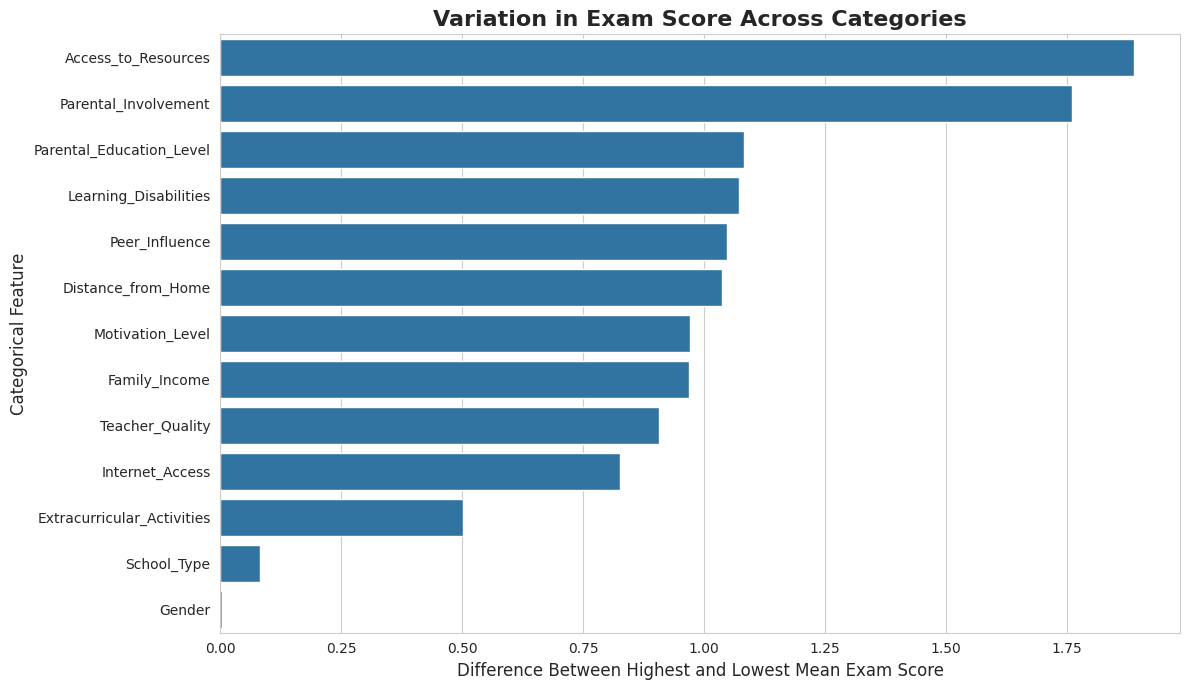


19.7 CATEGORY-WISE EXAM SCORE DISTRIBUTIONS
--------------------------------------------------


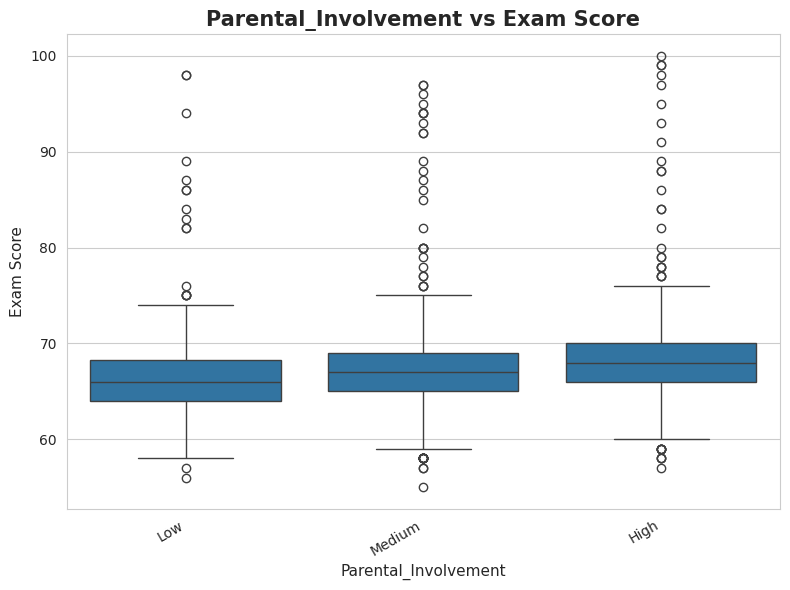

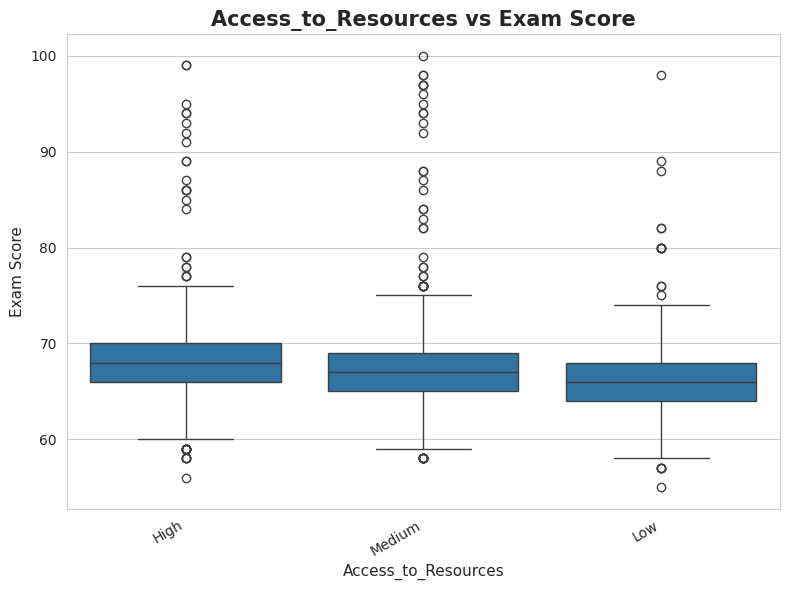

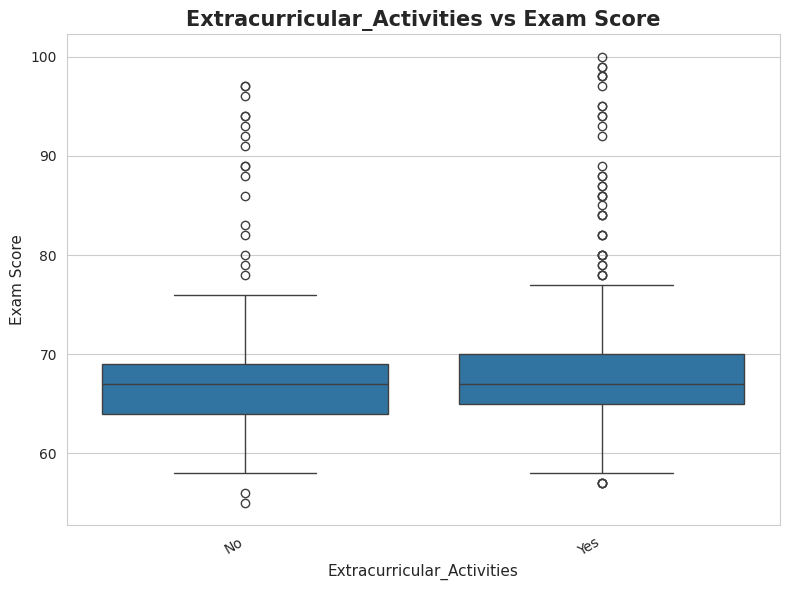

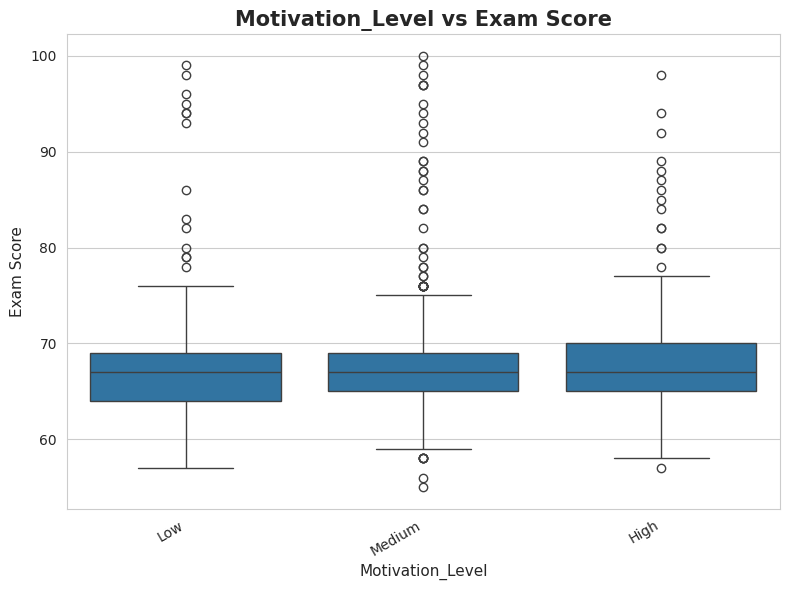

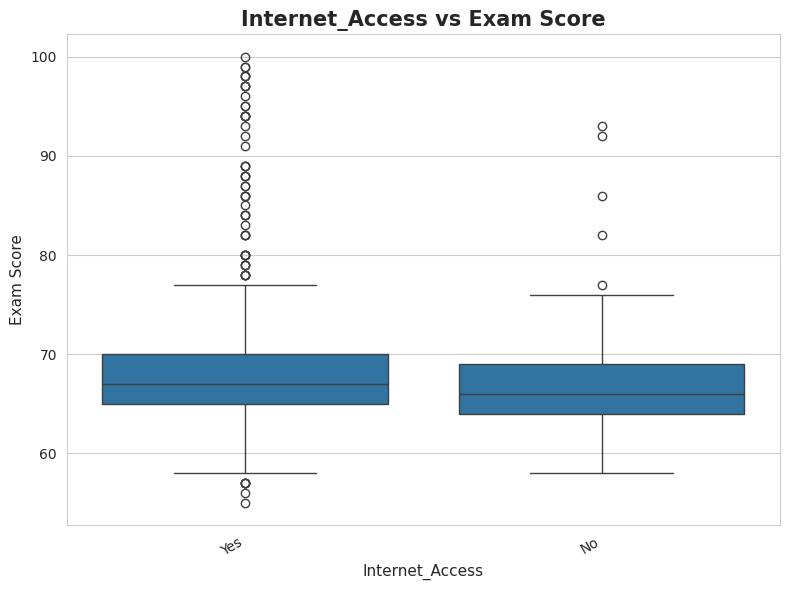

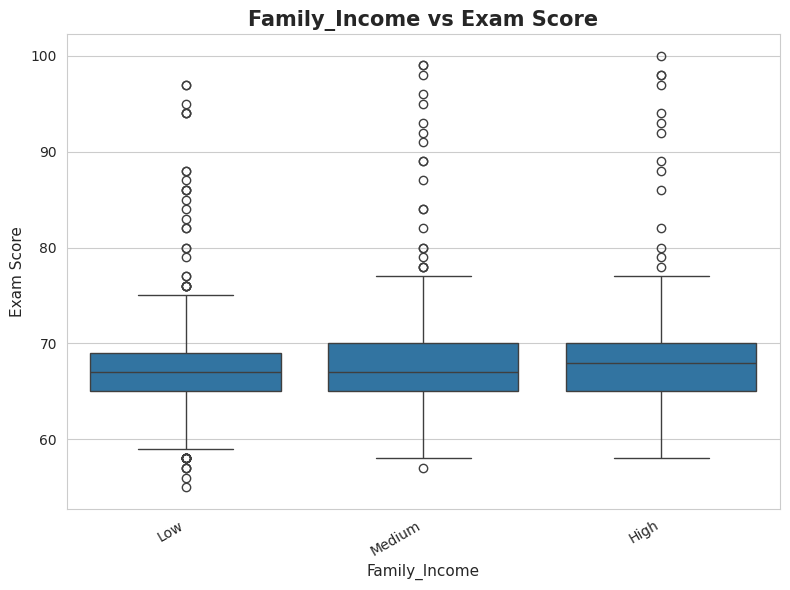

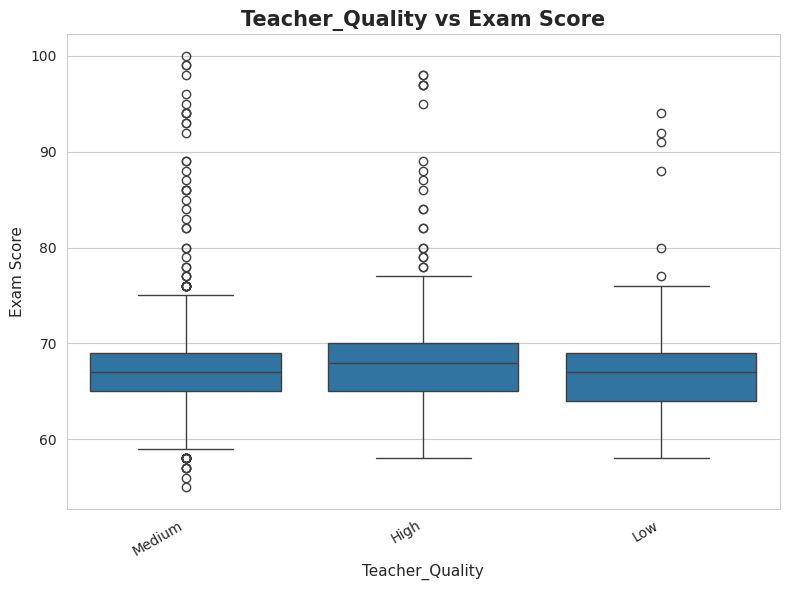

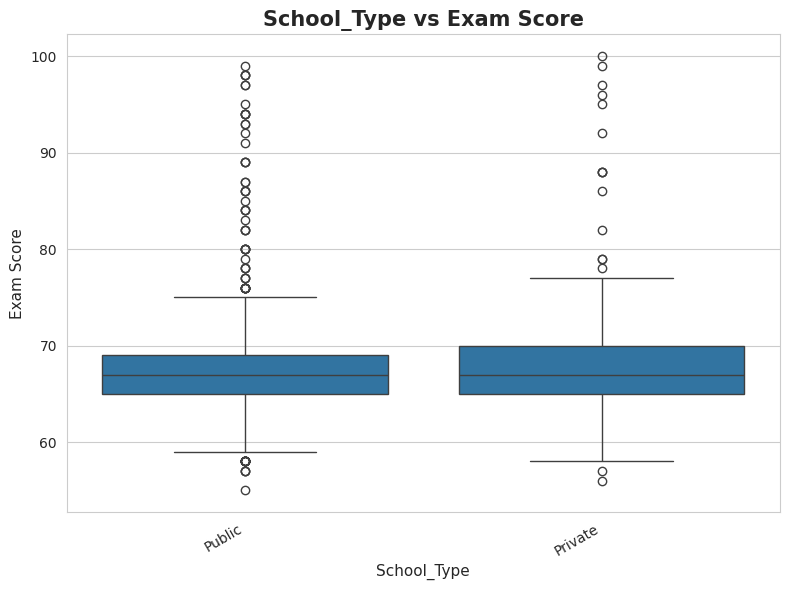

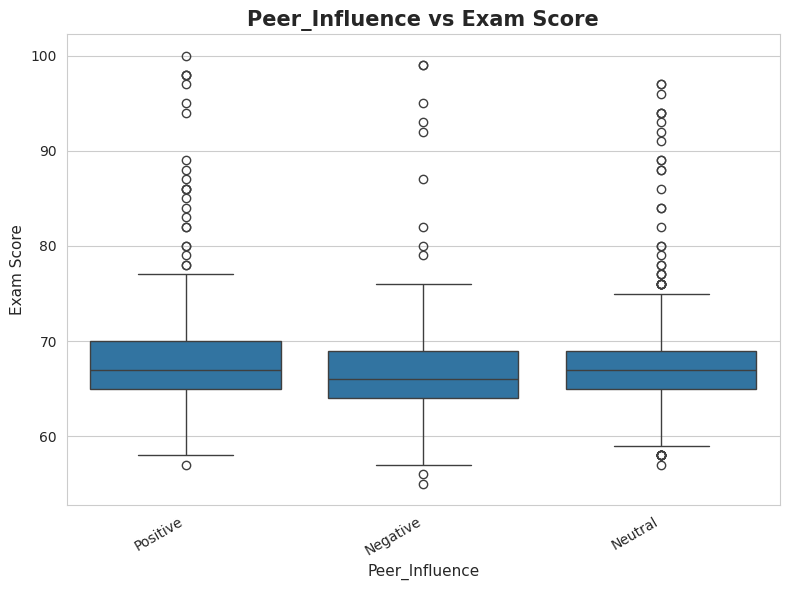

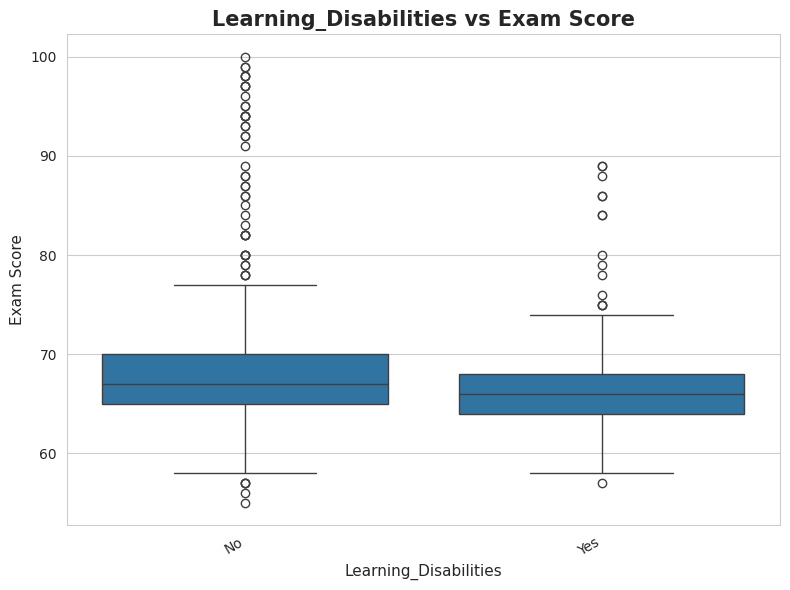

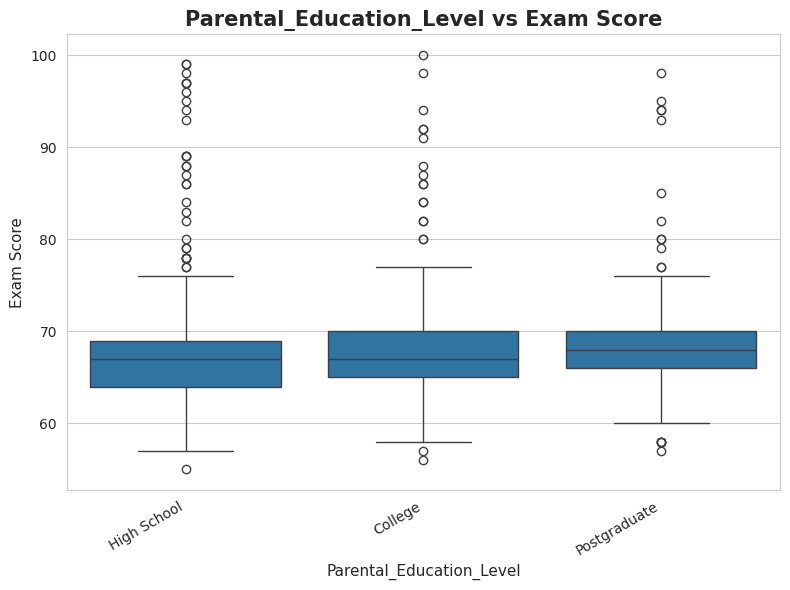

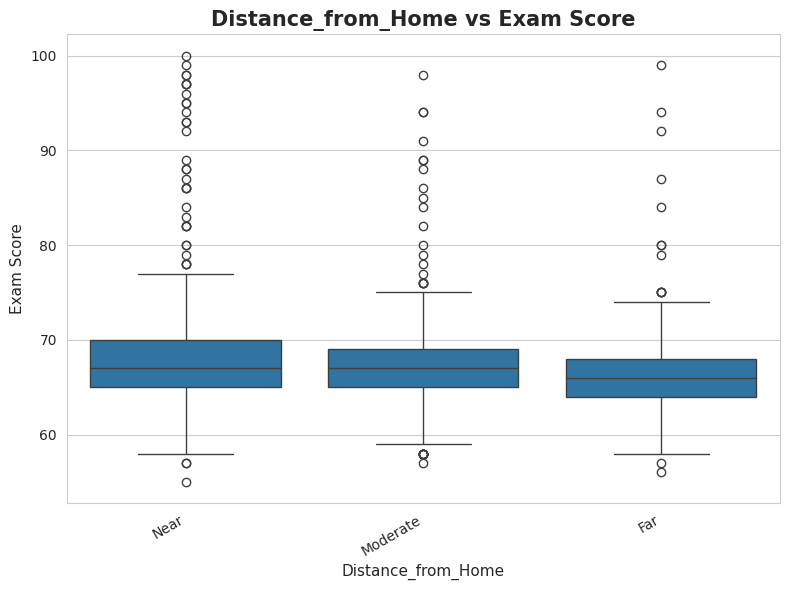

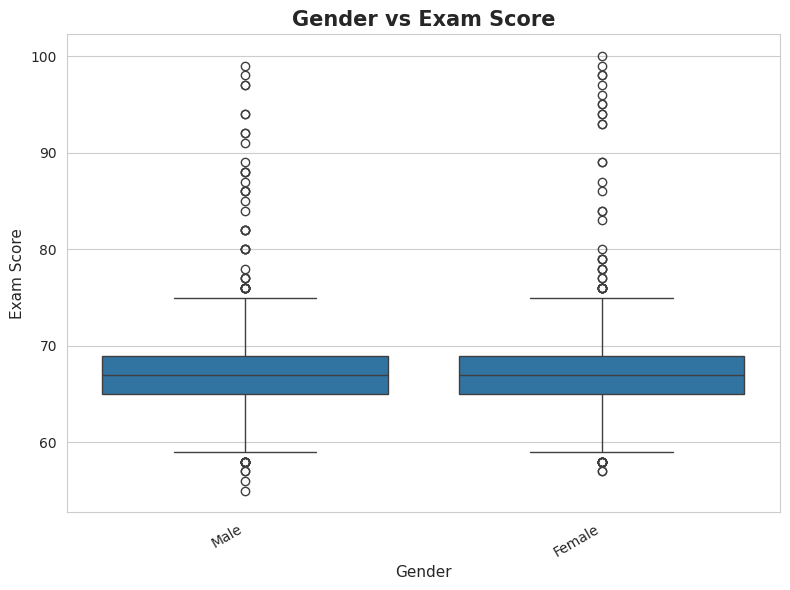


19.8 MEAN EXAM SCORE BY CATEGORY
--------------------------------------------------


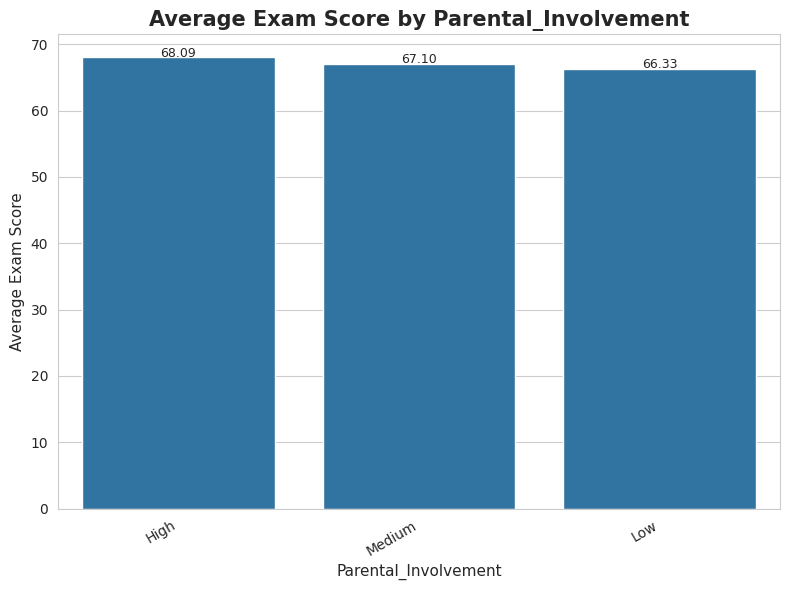

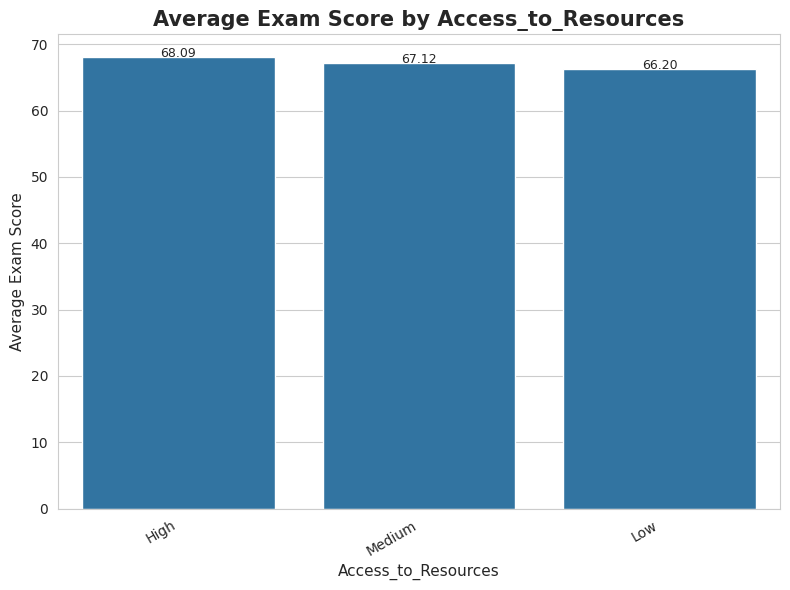

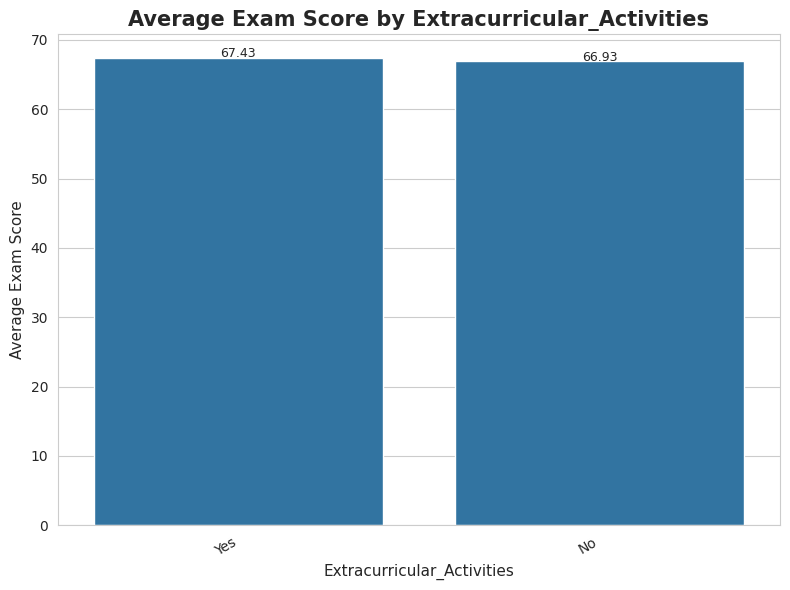

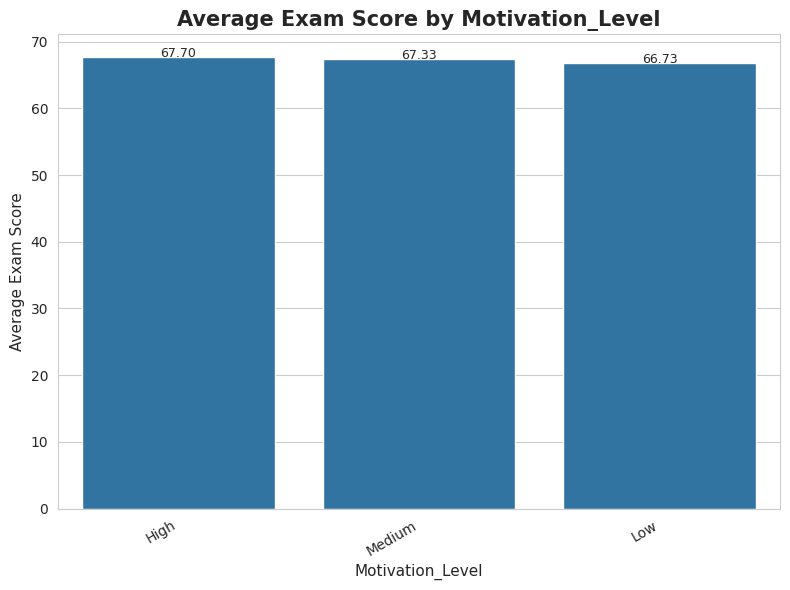

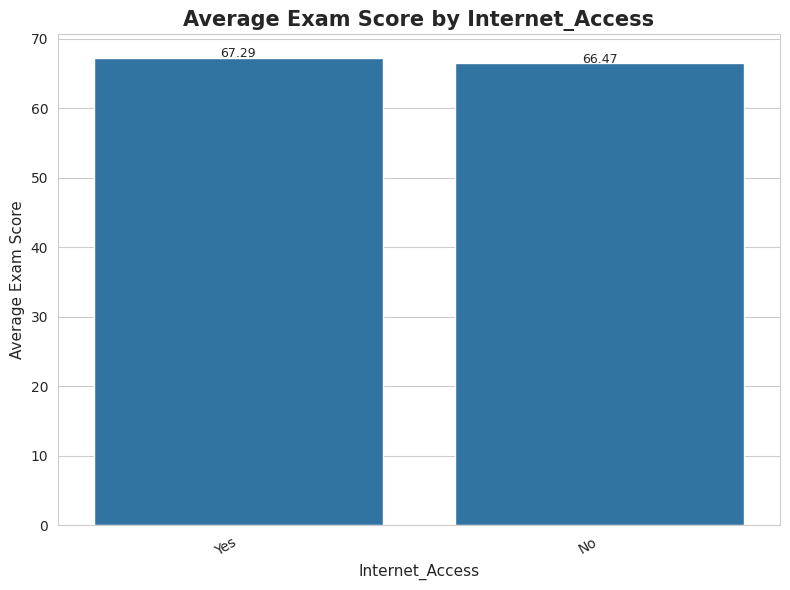

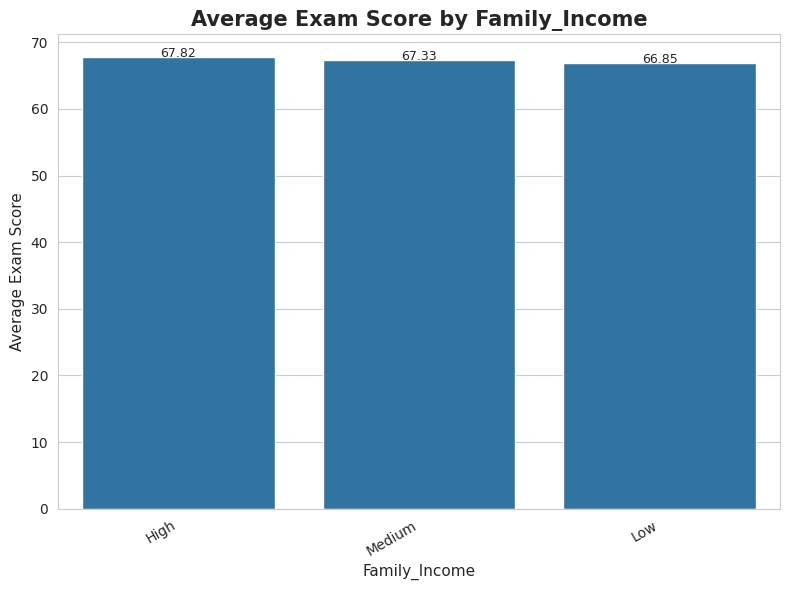

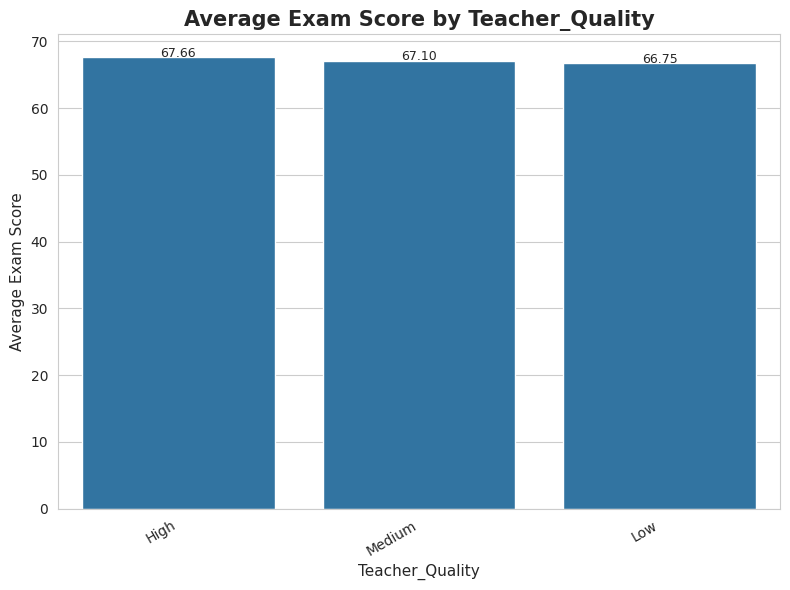

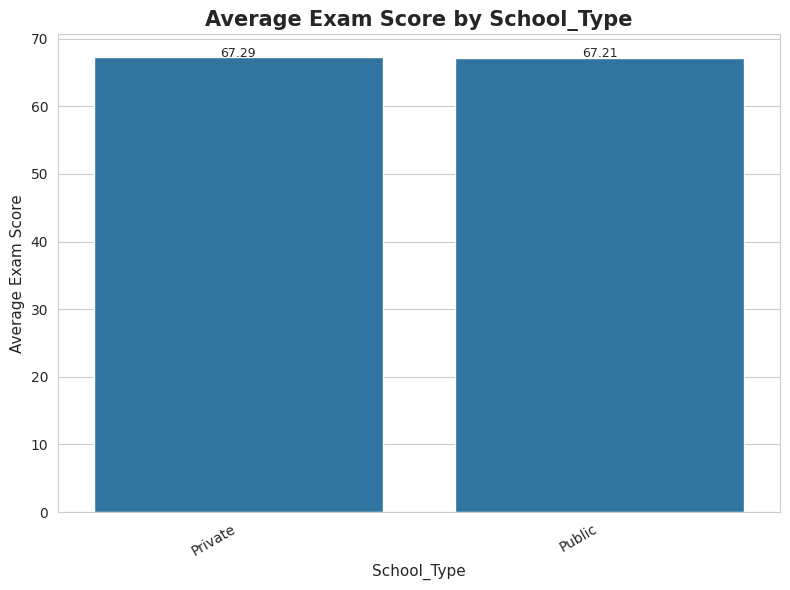

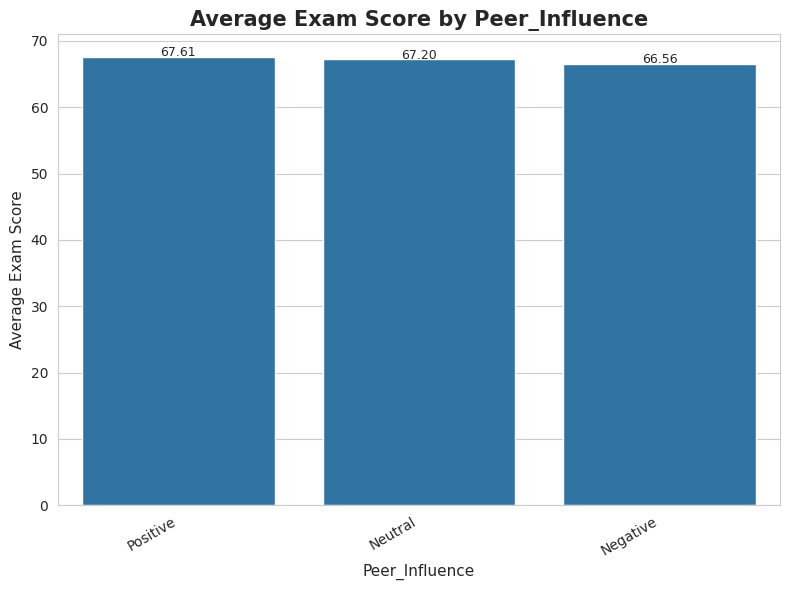

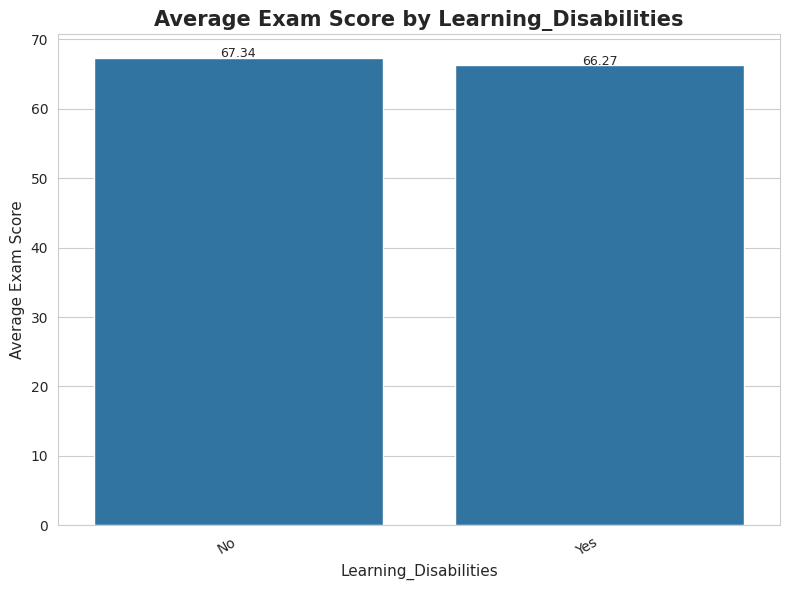

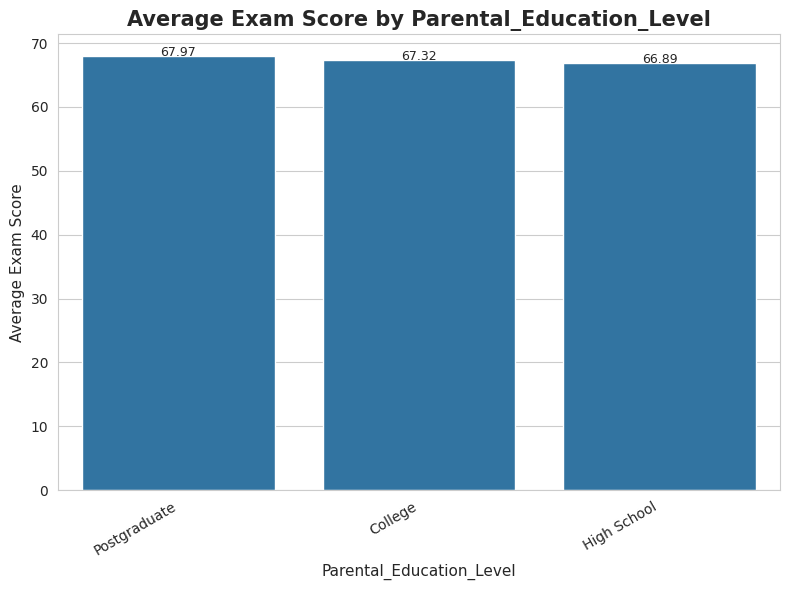

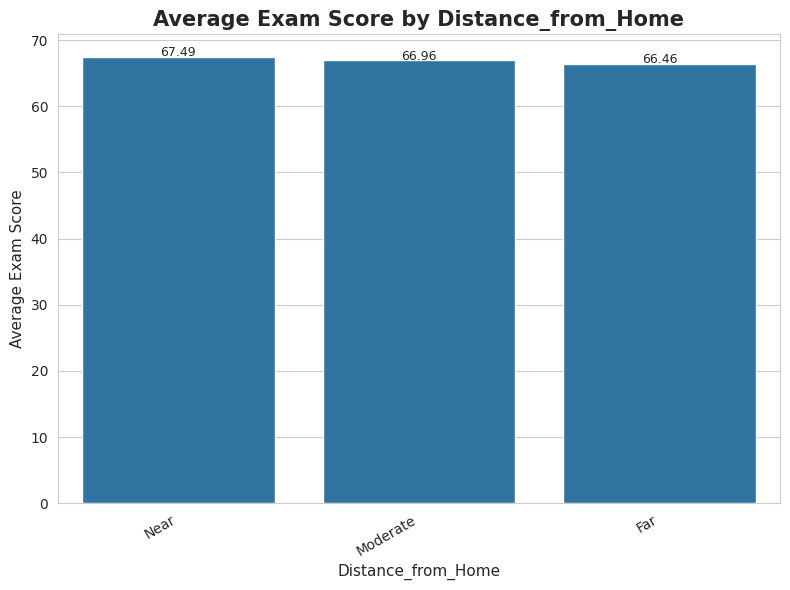

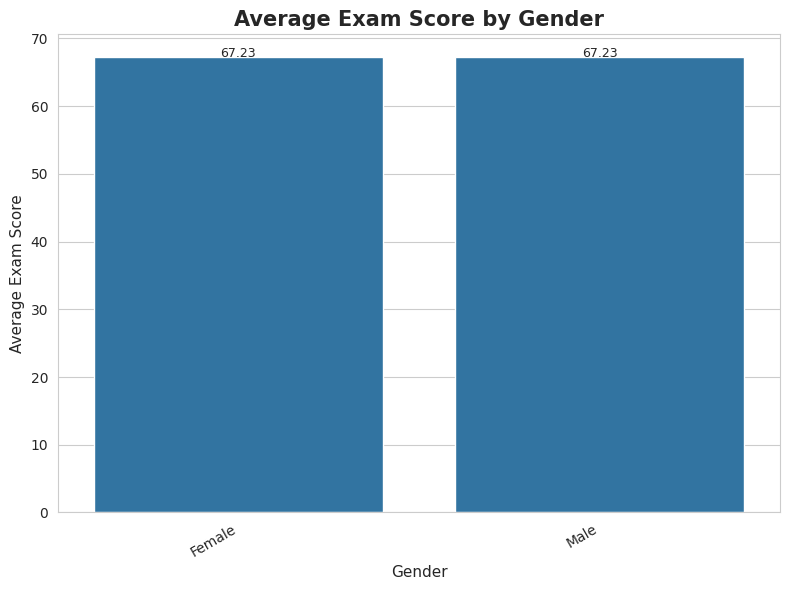


19.9 EFFECT RANGE OF CATEGORICAL FEATURES
--------------------------------------------------


,Feature,Minimum_Group_Mean,Maximum_Group_Mean,Mean_Range
0,Access_to_Resources,66.203,68.092,1.889
1,Parental_Involvement,66.332,68.093,1.760
2,Parental_Education_Level,66.888,67.971,1.083
3,Learning_Disabilities,66.271,67.343,1.073
4,Peer_Influence,66.564,67.611,1.046
5,Distance_from_Home,66.457,67.494,1.036
6,Motivation_Level,66.735,67.704,0.970
7,Family_Income,66.848,67.816,0.968
8,Teacher_Quality,66.753,67.660,0.906
9,Internet_Access,66.466,67.293,0.827



19.10 FEATURES WITH LARGEST CATEGORY DIFFERENCES
--------------------------------------------------

Top categorical features based on the difference between their highest and lowest group mean:


,Feature,Minimum_Group_Mean,Maximum_Group_Mean,Mean_Range
0,Access_to_Resources,66.203,68.092,1.889
1,Parental_Involvement,66.332,68.093,1.760
2,Parental_Education_Level,66.888,67.971,1.083
3,Learning_Disabilities,66.271,67.343,1.073
4,Peer_Influence,66.564,67.611,1.046



19.11 CATEGORY BALANCE CHECK
--------------------------------------------------


,Feature,Smallest_Group_Count,Largest_Group_Count,Balance_Ratio
4,Internet_Access,498,6108,0.082
9,Learning_Disabilities,695,5911,0.118
6,Teacher_Quality,657,4003,0.164
11,Distance_from_Home,658,3951,0.167
3,Motivation_Level,1319,3351,0.394
10,Parental_Education_Level,1305,3312,0.394
1,Access_to_Resources,1313,3318,0.396
0,Parental_Involvement,1336,3362,0.397
7,School_Type,2009,4597,0.437
5,Family_Income,1268,2672,0.475



19.12 AUTOMATIC INTERPRETATION
--------------------------------------------------

Categorical feature analysis compares the average Exam_Score across different groups.

The features with larger differences between their highest and lowest group means show greater variation in average Exam_Score across categories.

However, a difference in group averages does not by itself establish a causal relationship.

Category size should also be considered because a very small group can produce less reliable estimates.

19.13 TOP CATEGORICAL FEATURES
--------------------------------------------------
1. Access_to_Resources → Mean Score Range = 1.89
2. Parental_Involvement → Mean Score Range = 1.76
3. Parental_Education_Level → Mean Score Range = 1.08
4. Learning_Disabilities → Mean Score Range = 1.07
5. Peer_Influence → Mean Score Range = 1.05

STEP 19 COMPLETED

What we performed:
1. Identified all categorical features.
2. Calculated the number of categories in each feature.
3. Examined the dis

In [29]:
# ============================================================
# STEP 19: CATEGORICAL FEATURES VS EXAM SCORE
# ============================================================

print("=" * 80)
print("STEP 19: CATEGORICAL FEATURES VS EXAM SCORE")
print("=" * 80)


# ------------------------------------------------------------
# 19.1 IDENTIFY CATEGORICAL FEATURES
# ------------------------------------------------------------

print("\n19.1 CATEGORICAL FEATURES")
print("-" * 50)

categorical_features = df_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Features:")

for i, column in enumerate(categorical_features, start=1):
    print(f"{i}. {column}")

print(f"\nTotal Categorical Features: {len(categorical_features)}")


# ------------------------------------------------------------
# 19.2 CHECK NUMBER OF UNIQUE CATEGORIES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.2 UNIQUE CATEGORIES")
print("-" * 50)

category_summary = pd.DataFrame({
    "Feature": categorical_features,
    "Unique_Categories": [
        df_clean[column].nunique()
        for column in categorical_features
    ]
})

display(category_summary)


# ------------------------------------------------------------
# 19.3 DISPLAY CATEGORY DISTRIBUTION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.3 CATEGORY DISTRIBUTION")
print("-" * 50)

for column in categorical_features:

    print("\n" + "-" * 60)
    print(f"Feature: {column}")
    print("-" * 60)

    counts = df_clean[column].value_counts()

    percentages = (
        df_clean[column]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages
    })

    display(distribution)


# ------------------------------------------------------------
# 19.4 ANALYZE EACH CATEGORICAL FEATURE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.4 CATEGORICAL FEATURES VS EXAM SCORE")
print("-" * 50)

# Store summary results for all categorical features
categorical_analysis_results = []

for column in categorical_features:

    print("\n")
    print("=" * 70)
    print(f"ANALYSIS: {column} vs Exam_Score")
    print("=" * 70)

    # Group-wise statistics
    group_stats = (
        df_clean
        .groupby(column)["Exam_Score"]
        .agg(
            Count="count",
            Mean="mean",
            Median="median",
            Std_Dev="std",
            Minimum="min",
            Maximum="max"
        )
        .sort_values(
            by="Mean",
            ascending=False
        )
    )

    print("\nGroup-wise Exam Score Statistics:")
    display(group_stats.round(2))


    # --------------------------------------------------------
    # Identify highest and lowest average groups
    # --------------------------------------------------------

    highest_group = group_stats["Mean"].idxmax()
    highest_mean = group_stats["Mean"].max()

    lowest_group = group_stats["Mean"].idxmin()
    lowest_mean = group_stats["Mean"].min()

    mean_difference = highest_mean - lowest_mean

    print(
        f"Highest average Exam Score:"
        f" {highest_group} → {highest_mean:.2f}"
    )

    print(
        f"Lowest average Exam Score:"
        f" {lowest_group} → {lowest_mean:.2f}"
    )

    print(
        f"Difference between highest and lowest group:"
        f" {mean_difference:.2f}"
    )


    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    categorical_analysis_results.append({
        "Feature": column,
        "Highest_Mean_Category": highest_group,
        "Highest_Mean": highest_mean,
        "Lowest_Mean_Category": lowest_group,
        "Lowest_Mean": lowest_mean,
        "Mean_Difference": mean_difference
    })


# ------------------------------------------------------------
# 19.5 CREATE OVERALL CATEGORICAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.5 OVERALL CATEGORICAL ANALYSIS SUMMARY")
print("-" * 50)

categorical_summary = pd.DataFrame(
    categorical_analysis_results
)

categorical_summary = categorical_summary.sort_values(
    by="Mean_Difference",
    ascending=False
).reset_index(drop=True)

display(
    categorical_summary.round(2)
)


# ------------------------------------------------------------
# 19.6 VISUALIZE CATEGORY MEAN DIFFERENCES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.6 CATEGORY MEAN DIFFERENCE")
print("-" * 50)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=categorical_summary,
    x="Mean_Difference",
    y="Feature"
)

plt.xlabel(
    "Difference Between Highest and Lowest Mean Exam Score",
    fontsize=12
)

plt.ylabel(
    "Categorical Feature",
    fontsize=12
)

plt.title(
    "Variation in Exam Score Across Categories",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 19.7 PLOT CATEGORY-WISE EXAM SCORE DISTRIBUTIONS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.7 CATEGORY-WISE EXAM SCORE DISTRIBUTIONS")
print("-" * 50)

for column in categorical_features:

    # Get number of categories
    number_of_categories = df_clean[column].nunique()

    # Choose figure width dynamically
    figure_width = max(
        8,
        min(14, number_of_categories * 2)
    )

    plt.figure(
        figsize=(figure_width, 6)
    )

    sns.boxplot(
        data=df_clean,
        x=column,
        y="Exam_Score"
    )

    plt.title(
        f"{column} vs Exam Score",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        column,
        fontsize=11
    )

    plt.ylabel(
        "Exam Score",
        fontsize=11
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 19.8 BAR CHART OF MEAN EXAM SCORE FOR EACH FEATURE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.8 MEAN EXAM SCORE BY CATEGORY")
print("-" * 50)

for column in categorical_features:

    mean_scores = (
        df_clean
        .groupby(column)["Exam_Score"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(
        figsize=(
            max(8, len(mean_scores) * 1.8),
            6
        )
    )

    sns.barplot(
        x=mean_scores.index,
        y=mean_scores.values
    )

    plt.title(
        f"Average Exam Score by {column}",
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        column,
        fontsize=11
    )

    plt.ylabel(
        "Average Exam Score",
        fontsize=11
    )

    plt.xticks(
        rotation=30,
        ha="right"
    )

    # Add values above bars
    for index, value in enumerate(mean_scores.values):

        plt.text(
            index,
            value + 0.05,
            f"{value:.2f}",
            ha="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 19.9 CALCULATE EFFECT RANGE FOR EACH CATEGORICAL FEATURE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.9 EFFECT RANGE OF CATEGORICAL FEATURES")
print("-" * 50)

effect_range_results = []

for column in categorical_features:

    group_means = (
        df_clean
        .groupby(column)["Exam_Score"]
        .mean()
    )

    maximum_mean = group_means.max()
    minimum_mean = group_means.min()

    effect_range = maximum_mean - minimum_mean

    effect_range_results.append({
        "Feature": column,
        "Minimum_Group_Mean": minimum_mean,
        "Maximum_Group_Mean": maximum_mean,
        "Mean_Range": effect_range
    })


effect_range_df = pd.DataFrame(
    effect_range_results
).sort_values(
    by="Mean_Range",
    ascending=False
).reset_index(drop=True)

display(
    effect_range_df.round(3)
)


# ------------------------------------------------------------
# 19.10 IDENTIFY FEATURES WITH LARGEST CATEGORY DIFFERENCES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.10 FEATURES WITH LARGEST CATEGORY DIFFERENCES")
print("-" * 50)

top_categorical_features = (
    effect_range_df
    .head(5)
)

print(
    "\nTop categorical features based on the difference "
    "between their highest and lowest group mean:"
)

display(
    top_categorical_features.round(3)
)


# ------------------------------------------------------------
# 19.11 CHECK CATEGORY BALANCE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.11 CATEGORY BALANCE CHECK")
print("-" * 50)

category_balance_results = []

for column in categorical_features:

    counts = df_clean[column].value_counts()

    smallest_group = counts.min()
    largest_group = counts.max()

    balance_ratio = (
        smallest_group / largest_group
    )

    category_balance_results.append({
        "Feature": column,
        "Smallest_Group_Count": smallest_group,
        "Largest_Group_Count": largest_group,
        "Balance_Ratio": balance_ratio
    })


category_balance_df = pd.DataFrame(
    category_balance_results
).sort_values(
    by="Balance_Ratio"
)

display(
    category_balance_df.round(3)
)


# ------------------------------------------------------------
# 19.12 AUTOMATIC INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.12 AUTOMATIC INTERPRETATION")
print("-" * 50)

print(
    "\nCategorical feature analysis compares the average "
    "Exam_Score across different groups."
)

print(
    "\nThe features with larger differences between their "
    "highest and lowest group means show greater variation "
    "in average Exam_Score across categories."
)

print(
    "\nHowever, a difference in group averages does not by "
    "itself establish a causal relationship."
)

print(
    "\nCategory size should also be considered because a very "
    "small group can produce less reliable estimates."
)


# ------------------------------------------------------------
# 19.13 TOP CATEGORICAL FEATURES SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("19.13 TOP CATEGORICAL FEATURES")
print("-" * 50)

for index, row in top_categorical_features.iterrows():

    print(
        f"{index + 1}. {row['Feature']} "
        f"→ Mean Score Range = "
        f"{row['Mean_Range']:.2f}"
    )


# ------------------------------------------------------------
# 19.14 FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 19 COMPLETED")
print("=" * 80)

print(
    "\nWhat we performed:"
)

print(
    "1. Identified all categorical features."
)

print(
    "2. Calculated the number of categories in each feature."
)

print(
    "3. Examined the distribution of each category."
)

print(
    "4. Compared Exam_Score across categories."
)

print(
    "5. Calculated count, mean, median, standard deviation, "
    "minimum and maximum scores for each group."
)

print(
    "6. Created boxplots for categorical features."
)

print(
    "7. Created average Exam_Score bar charts."
)

print(
    "8. Calculated the difference between the highest and "
    "lowest category mean."
)

print(
    "9. Checked category balance."
)

print(
    "10. Identified categorical features showing larger "
    "differences in average Exam_Score."
)

print(
    "\nThese results will be useful when selecting and "
    "encoding categorical features for the machine learning "
    "models."
)

print("\n" + "=" * 80)

In [30]:
# ============================================================
# STEP 20: FEATURE ENGINEERING & ML PREPARATION
# ============================================================

print("=" * 80)
print("STEP 20: FEATURE ENGINEERING & ML PREPARATION")
print("=" * 80)


# ------------------------------------------------------------
# 20.1 CREATE A SEPARATE ML DATASET
# ------------------------------------------------------------

print("\n20.1 CREATING ML DATASET")
print("-" * 50)

# Keep df_clean unchanged
ml_df = df_clean.copy()

print(f"Original cleaned dataset shape : {df_clean.shape}")
print(f"ML dataset shape              : {ml_df.shape}")

print("\nThe original df_clean dataset will not be modified.")


# ------------------------------------------------------------
# 20.2 DEFINE TARGET VARIABLE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.2 DEFINE TARGET VARIABLE")
print("-" * 50)

target_column = "Exam_Score"

# Separate target and input features
X = ml_df.drop(columns=[target_column])
y = ml_df[target_column]

print(f"Target variable : {target_column}")
print(f"Target shape    : {y.shape}")
print(f"Feature shape   : {X.shape}")

print("\nTarget statistics:")
print(y.describe().round(3))


# ------------------------------------------------------------
# 20.3 CHECK TARGET VARIABLE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.3 TARGET VARIABLE VALIDATION")
print("-" * 50)

print(f"Missing target values : {y.isnull().sum()}")
print(f"Minimum Exam Score    : {y.min()}")
print(f"Maximum Exam Score    : {y.max()}")
print(f"Mean Exam Score       : {y.mean():.3f}")
print(f"Median Exam Score     : {y.median():.3f}")

invalid_target_values = (
    (y < 0) |
    (y > 100)
).sum()

print(
    f"Invalid target values : {invalid_target_values}"
)

if (
    y.isnull().sum() == 0
    and invalid_target_values == 0
):
    print("\nTarget validation PASSED.")
else:
    print("\nTarget validation requires attention.")


# ------------------------------------------------------------
# 20.4 IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.4 IDENTIFY FEATURE TYPES")
print("-" * 50)

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical Features:")
for i, feature in enumerate(
    numerical_features,
    start=1
):
    print(f"{i}. {feature}")

print(
    f"\nTotal numerical features: "
    f"{len(numerical_features)}"
)

print("\nCategorical Features:")
for i, feature in enumerate(
    categorical_features,
    start=1
):
    print(f"{i}. {feature}")

print(
    f"\nTotal categorical features: "
    f"{len(categorical_features)}"
)


# ------------------------------------------------------------
# 20.5 VERIFY FEATURE COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.5 FEATURE COUNT VALIDATION")
print("-" * 50)

total_features = (
    len(numerical_features)
    + len(categorical_features)
)

print(f"Numerical features   : {len(numerical_features)}")
print(f"Categorical features : {len(categorical_features)}")
print(f"Total input features : {total_features}")
print(f"X.shape[1]           : {X.shape[1]}")

if total_features == X.shape[1]:
    print("\nFeature count validation PASSED.")
else:
    print("\nFeature count validation FAILED.")


# ------------------------------------------------------------
# 20.6 CHECK MISSING VALUES IN FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.6 MISSING VALUE CHECK")
print("-" * 50)

missing_values = X.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(
    ascending=False
)

if len(missing_values) == 0:

    print(
        "No missing values found in the input features."
    )

else:

    print("Features containing missing values:")
    display(missing_values)


# ------------------------------------------------------------
# 20.7 CHECK DUPLICATES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.7 DUPLICATE CHECK")
print("-" * 50)

duplicate_rows = X.duplicated().sum()

print(
    f"Duplicate feature rows: {duplicate_rows}"
)

if duplicate_rows == 0:
    print("No duplicate feature rows found.")
else:
    print(
        "Duplicate feature rows exist, but they will "
        "not be automatically removed at this stage."
    )


# ------------------------------------------------------------
# 20.8 CHECK NUMERICAL FEATURE RANGES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.8 NUMERICAL FEATURE SUMMARY")
print("-" * 50)

numerical_summary = X[
    numerical_features
].describe().T

numerical_summary = numerical_summary[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

display(
    numerical_summary.round(3)
)


# ------------------------------------------------------------
# 20.9 CHECK CATEGORICAL CARDINALITY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.9 CATEGORICAL FEATURE CARDINALITY")
print("-" * 50)

categorical_cardinality = pd.DataFrame({
    "Feature": categorical_features,
    "Unique_Values": [
        X[column].nunique()
        for column in categorical_features
    ]
})

display(
    categorical_cardinality
)


# ------------------------------------------------------------
# 20.10 DISPLAY CATEGORY VALUES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.10 CATEGORICAL VALUES")
print("-" * 50)

for column in categorical_features:

    unique_values = (
        X[column]
        .dropna()
        .unique()
        .tolist()
    )

    print(
        f"{column}: {unique_values}"
    )


# ------------------------------------------------------------
# 20.11 CHECK WHETHER MANUAL FEATURE ENGINEERING IS NEEDED
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.11 FEATURE ENGINEERING CHECK")
print("-" * 50)

print(
    "\nThe current dataset already contains meaningful "
    "student-related features."
)

print(
    "\nWe will avoid creating arbitrary mathematical "
    "features because unnecessary transformations can "
    "introduce noise or redundancy."
)

print(
    "\nThe main feature-engineering operations in this "
    "stage will therefore be:"
)

print(
    "1. Separate target from predictors."
)

print(
    "2. Encode categorical variables."
)

print(
    "3. Scale numerical variables."
)

print(
    "4. Preserve the original feature information."
)

print(
    "5. Build a reproducible preprocessing pipeline."
)

print(
    "6. Prevent data leakage by fitting preprocessing "
    "only on the training data later."
)


# ------------------------------------------------------------
# 20.12 CHECK BINARY CATEGORICAL FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.12 BINARY CATEGORICAL FEATURES")
print("-" * 50)

binary_features = []

for column in categorical_features:

    if X[column].nunique() == 2:
        binary_features.append(column)

if len(binary_features) > 0:

    print(
        "Binary categorical features:"
    )

    for feature in binary_features:
        print(
            f"• {feature} → "
            f"{X[feature].unique().tolist()}"
        )

else:

    print(
        "No binary categorical features found."
    )


# ------------------------------------------------------------
# 20.13 CHECK MULTI-CATEGORY FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.13 MULTI-CATEGORY FEATURES")
print("-" * 50)

multi_category_features = []

for column in categorical_features:

    if X[column].nunique() > 2:
        multi_category_features.append(column)

if len(multi_category_features) > 0:

    print(
        "Multi-category features:"
    )

    for feature in multi_category_features:

        print(
            f"• {feature} → "
            f"{X[feature].nunique()} categories"
        )

else:

    print(
        "No multi-category features found."
    )


# ------------------------------------------------------------
# 20.14 IMPORT PREPROCESSING LIBRARIES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.14 BUILD PREPROCESSING COMPONENTS")
print("-" * 50)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print(
    "Required preprocessing libraries imported successfully."
)


# ------------------------------------------------------------
# 20.15 CREATE NUMERICAL PREPROCESSING PIPELINE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.15 NUMERICAL PREPROCESSING PIPELINE")
print("-" * 50)

numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

print(
    "Numerical preprocessing:"
)

print(
    "• Missing values → Median imputation"
)

print(
    "• Numerical features → StandardScaler"
)


# ------------------------------------------------------------
# 20.16 CREATE CATEGORICAL PREPROCESSING PIPELINE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.16 CATEGORICAL PREPROCESSING PIPELINE")
print("-" * 50)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

print(
    "Categorical preprocessing:"
)

print(
    "• Missing values → Most frequent category"
)

print(
    "• Categorical variables → One-Hot Encoding"
)

print(
    "• Unknown categories → Ignored safely"
)


# ------------------------------------------------------------
# 20.17 CREATE COMPLETE PREPROCESSOR
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.17 CREATE COMPLETE PREPROCESSOR")
print("-" * 50)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer,
            numerical_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print(
    "ColumnTransformer created successfully."
)

print(
    "\nProcessing structure:"
)

print(
    "Numerical Features"
    " → Median Imputation"
    " → Standard Scaling"
)

print(
    "Categorical Features"
    " → Most-Frequent Imputation"
    " → One-Hot Encoding"
)


# ------------------------------------------------------------
# 20.18 FIT PREPROCESSOR TEMPORARILY FOR VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.18 PREPROCESSING VALIDATION")
print("-" * 50)

print(
    "\nFor this validation step, the preprocessor is "
    "fitted on the current dataset only to inspect "
    "the resulting feature representation."
)

X_processed_check = preprocessor.fit_transform(X)

print(
    f"\nOriginal feature count : {X.shape[1]}"
)

print(
    f"Processed feature count: "
    f"{X_processed_check.shape[1]}"
)

print(
    f"Processed rows         : "
    f"{X_processed_check.shape[0]}"
)


# ------------------------------------------------------------
# 20.19 CHECK PROCESSED DATA
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.19 PROCESSED DATA VALIDATION")
print("-" * 50)

print(
    f"Processed data shape: "
    f"{X_processed_check.shape}"
)

print(
    f"Processed data type: "
    f"{type(X_processed_check)}"
)

processed_missing = np.isnan(
    X_processed_check
).sum()

processed_infinite = np.isinf(
    X_processed_check
).sum()

print(
    f"Missing values after preprocessing : "
    f"{processed_missing}"
)

print(
    f"Infinite values after preprocessing: "
    f"{processed_infinite}"
)

if (
    processed_missing == 0
    and processed_infinite == 0
):

    print(
        "\nProcessed data validation PASSED."
    )

else:

    print(
        "\nProcessed data validation FAILED."
    )


# ------------------------------------------------------------
# 20.20 GET GENERATED FEATURE NAMES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.20 GENERATED FEATURE NAMES")
print("-" * 50)

processed_feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    f"Total generated features: "
    f"{len(processed_feature_names)}"
)

print(
    "\nFirst 30 generated features:"
)

for i, feature in enumerate(
    processed_feature_names[:30],
    start=1
):

    print(
        f"{i}. {feature}"
    )

if len(processed_feature_names) > 30:

    print(
        "\n... remaining generated features "
        "are omitted from the display."
    )


# ------------------------------------------------------------
# 20.21 CREATE PROCESSED DATAFRAME FOR INSPECTION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.21 PROCESSED DATAFRAME PREVIEW")
print("-" * 50)

X_processed_df = pd.DataFrame(
    X_processed_check,
    columns=processed_feature_names,
    index=X.index
)

print(
    f"Processed DataFrame shape: "
    f"{X_processed_df.shape}"
)

display(
    X_processed_df.head()
)


# ------------------------------------------------------------
# 20.22 CHECK STANDARDIZATION
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.22 NUMERICAL SCALING CHECK")
print("-" * 50)

# Check only original numerical features
scaled_numerical_names = [
    name
    for name in processed_feature_names
    if name.startswith("numerical__")
]

if len(scaled_numerical_names) > 0:

    scaling_check = X_processed_df[
        scaled_numerical_names
    ].agg(
        ["mean", "std"]
    ).T

    print(
        "\nMean and standard deviation of scaled "
        "numerical features:"
    )

    display(
        scaling_check.round(3)
    )

else:

    print(
        "No numerical features found in processed output."
    )


# ------------------------------------------------------------
# 20.23 VERIFY ORIGINAL DATASET IS UNCHANGED
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.23 ORIGINAL DATASET VALIDATION")
print("-" * 50)

print(
    f"df_clean shape: {df_clean.shape}"
)

print(
    f"ml_df shape   : {ml_df.shape}"
)

print(
    f"X shape       : {X.shape}"
)

print(
    f"y shape       : {y.shape}"
)

print(
    "\nThe original cleaned dataset remains available "
    "as df_clean."
)


# ------------------------------------------------------------
# 20.24 SAVE PREPROCESSOR OBJECT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.24 PREPROCESSOR READY")
print("-" * 50)

# Keep the preprocessing object available for later ML steps
ml_preprocessor = preprocessor

print(
    "Preprocessor stored as: ml_preprocessor"
)

print(
    "\nThis object will be reused during the machine "
    "learning pipeline."
)


# ------------------------------------------------------------
# 20.25 IMPORTANT DATA-LEAKAGE NOTE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("20.25 DATA LEAKAGE PREVENTION")
print("-" * 50)

print(
    "\nIMPORTANT:"
)

print(
    "The temporary fit performed above is ONLY for "
    "preprocessing validation."
)

print(
    "\nDuring actual machine learning:"
)

print(
    "1. The dataset will first be divided into "
    "training and testing sets."
)

print(
    "2. The preprocessing pipeline will be fitted "
    "ONLY on X_train."
)

print(
    "3. X_train will be transformed using the fitted "
    "preprocessor."
)

print(
    "4. X_test will be transformed using the SAME "
    "preprocessor."
)

print(
    "5. Information from X_test will not be used to "
    "learn preprocessing parameters."
)

print(
    "\nThis prevents data leakage."
)


# ------------------------------------------------------------
# 20.26 FINAL FEATURE ENGINEERING SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 20 COMPLETED")
print("=" * 80)

print(
    "\nFEATURE ENGINEERING SUMMARY"
)

print(
    f"\nDataset rows                 : {len(ml_df)}"
)

print(
    f"Original input features     : {X.shape[1]}"
)

print(
    f"Numerical features          : "
    f"{len(numerical_features)}"
)

print(
    f"Categorical features        : "
    f"{len(categorical_features)}"
)

print(
    f"Generated ML features       : "
    f"{len(processed_feature_names)}"
)

print(
    f"Target variable             : "
    f"{target_column}"
)

print(
    "\nNumerical processing:"
)

print(
    "✓ Median imputation"
)

print(
    "✓ StandardScaler"
)

print(
    "\nCategorical processing:"
)

print(
    "✓ Most-frequent imputation"
)

print(
    "✓ One-Hot Encoding"
)

print(
    "✓ handle_unknown='ignore'"
)

print(
    "\nML preparation:"
)

print(
    "✓ Target separated"
)

print(
    "✓ Feature types identified"
)

print(
    "✓ Missing values checked"
)

print(
    "✓ Feature ranges checked"
)

print(
    "✓ Preprocessing pipeline created"
)

print(
    "✓ Generated feature names verified"
)

print(
    "✓ Processed data validated"
)

print(
    "✓ Original df_clean preserved"
)

print(
    "\nThe dataset is now ready for the "
    "train-test split and machine learning stage."
)

print("\n" + "=" * 80)

STEP 20: FEATURE ENGINEERING & ML PREPARATION

20.1 CREATING ML DATASET
--------------------------------------------------
Original cleaned dataset shape : (6606, 20)
ML dataset shape              : (6606, 20)

The original df_clean dataset will not be modified.

20.2 DEFINE TARGET VARIABLE
--------------------------------------------------
Target variable : Exam_Score
Target shape    : (6606,)
Feature shape   : (6606, 19)

Target statistics:
count    6606.000
mean       67.231
std         3.869
min        55.000
25%        65.000
50%        67.000
75%        69.000
max       100.000
Name: Exam_Score, dtype: float64

20.3 TARGET VARIABLE VALIDATION
--------------------------------------------------
Missing target values : 0
Minimum Exam Score    : 55
Maximum Exam Score    : 100
Mean Exam Score       : 67.231
Median Exam Score     : 67.000
Invalid target values : 0

Target validation PASSED.

20.4 IDENTIFY FEATURE TYPES
--------------------------------------------------

Numerical Featu

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6606.0,19.974,5.990,1.0,16.0,20.0,24.0,44.0
Attendance,6606.0,79.975,11.546,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6606.0,7.029,1.468,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6606.0,75.068,14.399,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6606.0,1.493,1.230,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6606.0,2.968,1.031,0.0,2.0,3.0,4.0,6.0



20.9 CATEGORICAL FEATURE CARDINALITY
--------------------------------------------------


,Feature,Unique_Values
0,Parental_Involvement,3
1,Access_to_Resources,3
2,Extracurricular_Activities,2
3,Motivation_Level,3
4,Internet_Access,2
5,Family_Income,3
6,Teacher_Quality,3
7,School_Type,2
8,Peer_Influence,3
9,Learning_Disabilities,2



20.10 CATEGORICAL VALUES
--------------------------------------------------
Parental_Involvement: ['Low', 'Medium', 'High']
Access_to_Resources: ['High', 'Medium', 'Low']
Extracurricular_Activities: ['No', 'Yes']
Motivation_Level: ['Low', 'Medium', 'High']
Internet_Access: ['Yes', 'No']
Family_Income: ['Low', 'Medium', 'High']
Teacher_Quality: ['Medium', 'High', 'Low']
School_Type: ['Public', 'Private']
Peer_Influence: ['Positive', 'Negative', 'Neutral']
Learning_Disabilities: ['No', 'Yes']
Parental_Education_Level: ['High School', 'College', 'Postgraduate']
Distance_from_Home: ['Near', 'Moderate', 'Far']
Gender: ['Male', 'Female']

20.11 FEATURE ENGINEERING CHECK
--------------------------------------------------

The current dataset already contains meaningful student-related features.

We will avoid creating arbitrary mathematical features because unnecessary transformations can introduce noise or redundancy.

The main feature-engineering operations in this stage will therefore be:

,numerical__Hours_Studied,numerical__Attendance,numerical__Sleep_Hours,numerical__Previous_Scores,numerical__Tutoring_Sessions,numerical__Physical_Activity,categorical__Parental_Involvement_High,categorical__Parental_Involvement_Low,categorical__Parental_Involvement_Medium,categorical__Access_to_Resources_High,...,categorical__Learning_Disabilities_No,categorical__Learning_Disabilities_Yes,categorical__Parental_Education_Level_College,categorical__Parental_Education_Level_High School,categorical__Parental_Education_Level_Postgraduate,categorical__Distance_from_Home_Far,categorical__Distance_from_Home_Moderate,categorical__Distance_from_Home_Near,categorical__Gender_Female,categorical__Gender_Male
0,0.505133,0.348650,-0.019901,-0.143617,-1.214158,0.031414,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
1,-0.162650,-1.383650,0.661268,-1.115968,0.412105,1.001129,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.672079,1.561259,-0.019901,1.106548,0.412105,1.001129,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,1.506808,0.781725,0.661268,1.592723,-0.401027,1.001129,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-0.162650,1.041570,-0.701069,-0.699247,1.225236,1.001129,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0



20.22 NUMERICAL SCALING CHECK
--------------------------------------------------

Mean and standard deviation of scaled numerical features:


,mean,std
numerical__Hours_Studied,-0.0,1.0
numerical__Attendance,-0.0,1.0
numerical__Sleep_Hours,0.0,1.0
numerical__Previous_Scores,-0.0,1.0
numerical__Tutoring_Sessions,-0.0,1.0
numerical__Physical_Activity,0.0,1.0



20.23 ORIGINAL DATASET VALIDATION
--------------------------------------------------
df_clean shape: (6606, 20)
ml_df shape   : (6606, 20)
X shape       : (6606, 19)
y shape       : (6606,)

The original cleaned dataset remains available as df_clean.

20.24 PREPROCESSOR READY
--------------------------------------------------
Preprocessor stored as: ml_preprocessor

This object will be reused during the machine learning pipeline.

20.25 DATA LEAKAGE PREVENTION
--------------------------------------------------

IMPORTANT:
The temporary fit performed above is ONLY for preprocessing validation.

During actual machine learning:
1. The dataset will first be divided into training and testing sets.
2. The preprocessing pipeline will be fitted ONLY on X_train.
3. X_train will be transformed using the fitted preprocessor.
4. X_test will be transformed using the SAME preprocessor.
5. Information from X_test will not be used to learn preprocessing parameters.

This prevents data leakage.

STEP 

STEP 21 + STEP 22 + STEP 23
TRAIN-TEST SPLIT + PREPROCESSING + MODEL TRAINING


STEP 21: TRAIN-TEST SPLIT

21.1 VERIFY INPUT DATA
------------------------------------------------------------
Input feature dataset X shape : (6606, 19)
Target dataset y shape        : (6606,)

Number of samples : 6606
Number of features: 19

21.2 TARGET DISTRIBUTION
------------------------------------------------------------
count    6606.000
mean       67.231
std         3.869
min        55.000
25%        65.000
50%        67.000
75%        69.000
max       100.000
Name: Exam_Score, dtype: float64


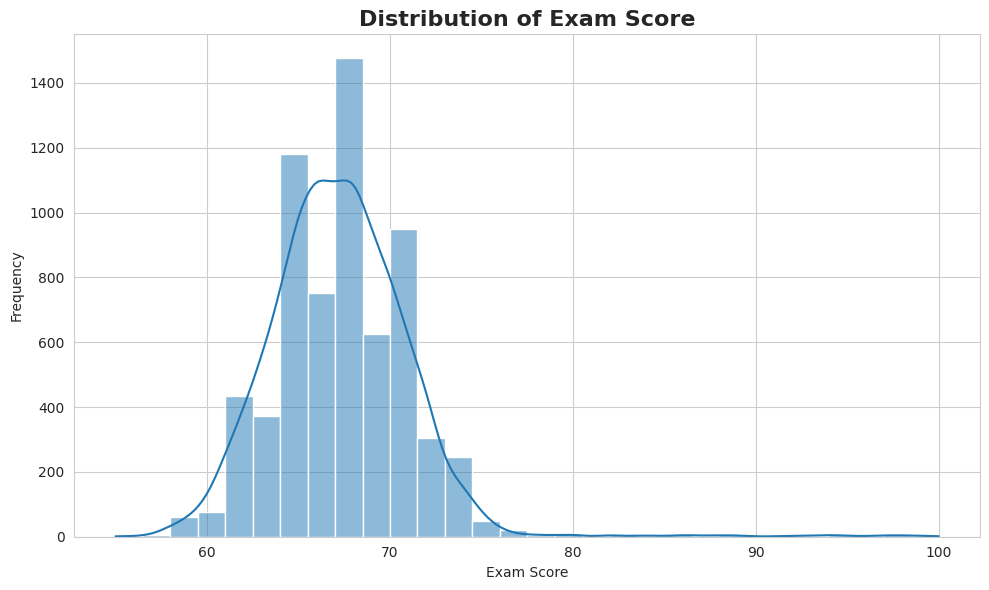


21.3 SPLITTING DATA
------------------------------------------------------------
Training samples : 5284
Testing samples  : 1322
Training features: 19
Testing features : 19

21.4 TRAIN-TEST SPLIT VALIDATION
------------------------------------------------------------
Original samples : 6606
Train samples    : 5284
Test samples     : 1322
Train + Test     : 6606

Train-test split validation PASSED.

21.5 TARGET DISTRIBUTION IN TRAIN AND TEST
------------------------------------------------------------


,Dataset,Count,Mean,Std_Dev,Minimum,Maximum
0,Full Dataset,6606,67.231,3.869,55,100
1,Training Set,5284,67.263,3.924,56,100
2,Testing Set,1322,67.101,3.638,55,98




STEP 22: LEAKAGE-SAFE PREPROCESSING

22.1 PREPROCESSING COMPONENTS
------------------------------------------------------------
Preprocessing libraries imported successfully.

22.2 IDENTIFY FEATURE TYPES
------------------------------------------------------------
Numerical features   : 6
Categorical features : 13

Numerical:
  • Hours_Studied
  • Attendance
  • Sleep_Hours
  • Previous_Scores
  • Tutoring_Sessions
  • Physical_Activity

Categorical:
  • Parental_Involvement
  • Access_to_Resources
  • Extracurricular_Activities
  • Motivation_Level
  • Internet_Access
  • Family_Income
  • Teacher_Quality
  • School_Type
  • Peer_Influence
  • Learning_Disabilities
  • Parental_Education_Level
  • Distance_from_Home
  • Gender

22.3 NUMERICAL PIPELINE
------------------------------------------------------------
Numerical features:
Median Imputation → Standard Scaling

22.4 CATEGORICAL PIPELINE
------------------------------------------------------------
Categorical features:
Most Fr

,Model,Train_MAE,Test_MAE,Train_MSE,Test_MSE,Train_RMSE,Test_RMSE,Train_R2,Test_R2
0,Linear Regression,0.5030,0.4160,4.4489,2.3142,2.1092,1.5213,0.7110,0.8250
1,Ridge Regression,0.5030,0.4161,4.4489,2.3142,2.1092,1.5213,0.7110,0.8250
2,Gradient Boosting,0.7548,0.7426,4.0833,2.8566,2.0207,1.6902,0.7347,0.7840
3,Hist Gradient Boosting,0.5974,0.7350,2.2948,2.9115,1.5148,1.7063,0.8509,0.7798
4,Extra Trees,0.0000,0.9918,0.0000,3.6796,0.0002,1.9182,1.0000,0.7218
5,Random Forest,0.4254,1.0610,0.7809,3.8526,0.8837,1.9628,0.9493,0.7087
6,Decision Tree,0.0000,1.8540,0.0000,13.8449,0.0000,3.7209,1.0000,-0.0469



23.6 TEST SET PERFORMANCE
------------------------------------------------------------


,Model,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Linear Regression,0.4160,2.3142,1.5213,0.8250
1,Ridge Regression,0.4161,2.3142,1.5213,0.8250
2,Gradient Boosting,0.7426,2.8566,1.6902,0.7840
3,Hist Gradient Boosting,0.7350,2.9115,1.7063,0.7798
4,Extra Trees,0.9918,3.6796,1.9182,0.7218
5,Random Forest,1.0610,3.8526,1.9628,0.7087
6,Decision Tree,1.8540,13.8449,3.7209,-0.0469



23.7 RMSE COMPARISON
------------------------------------------------------------


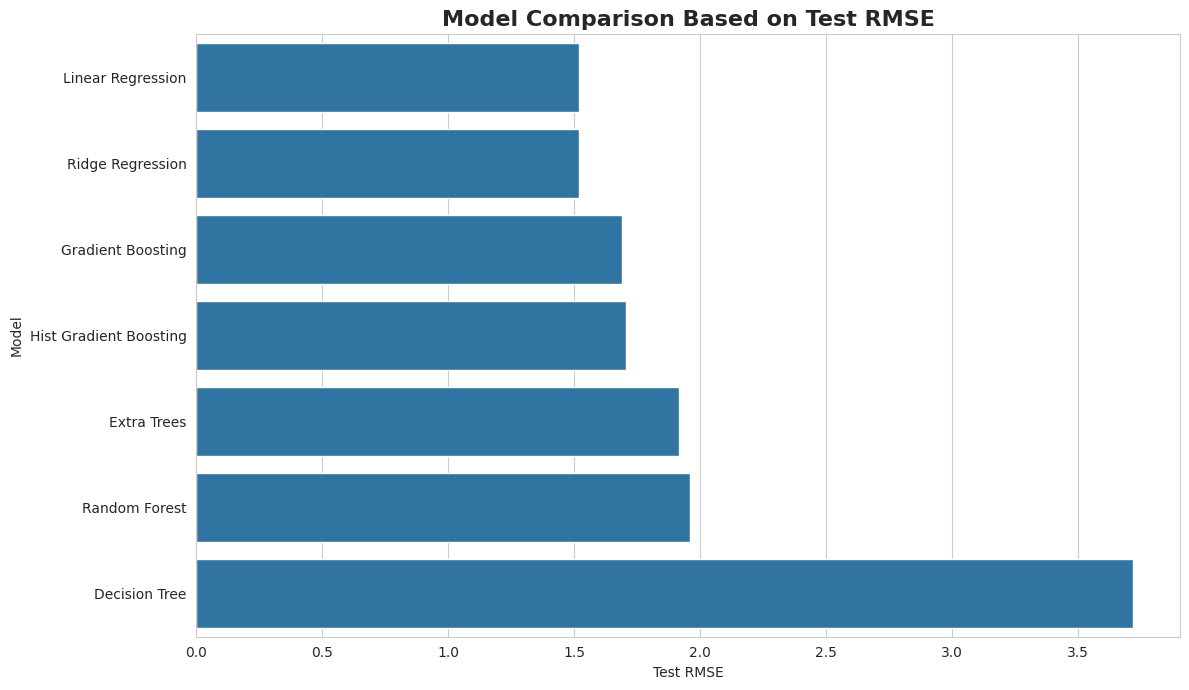


23.8 R² COMPARISON
------------------------------------------------------------


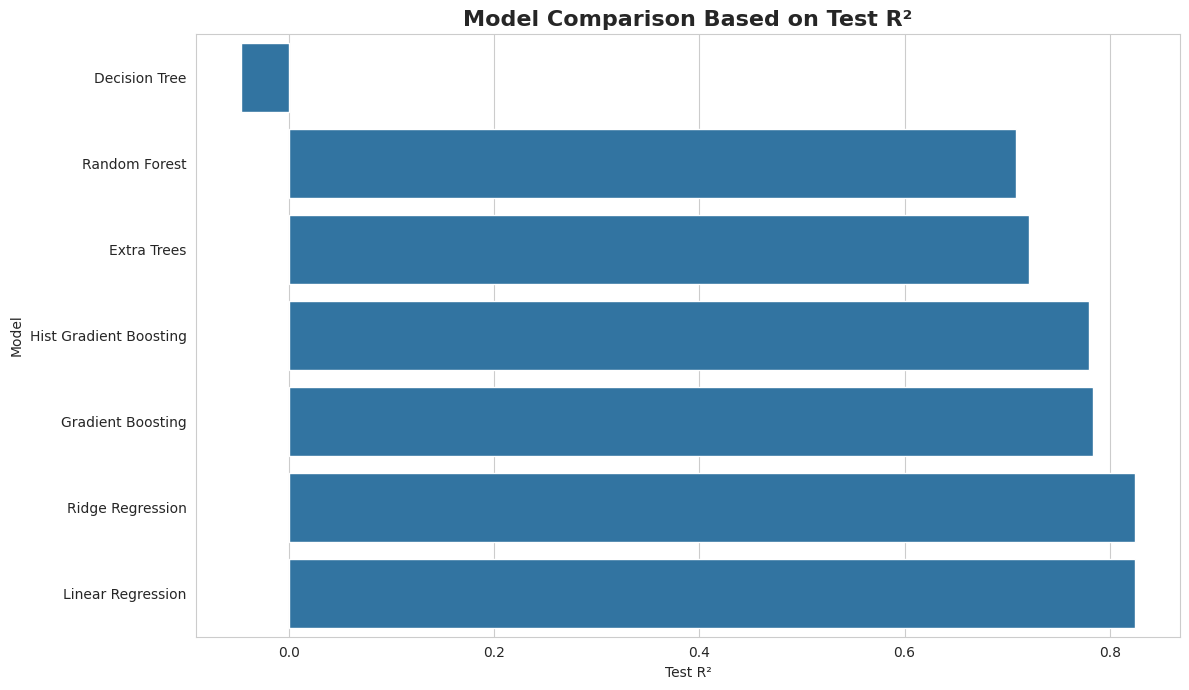


23.9 MAE COMPARISON
------------------------------------------------------------


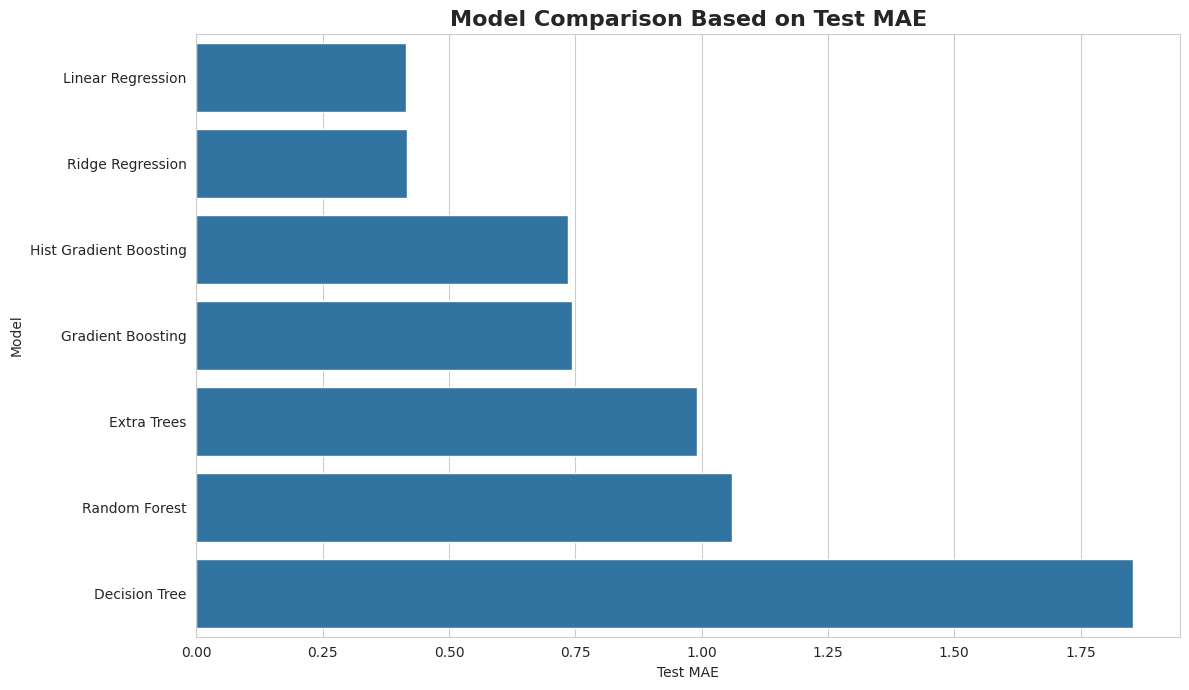


23.10 TRAIN VS TEST R²
------------------------------------------------------------


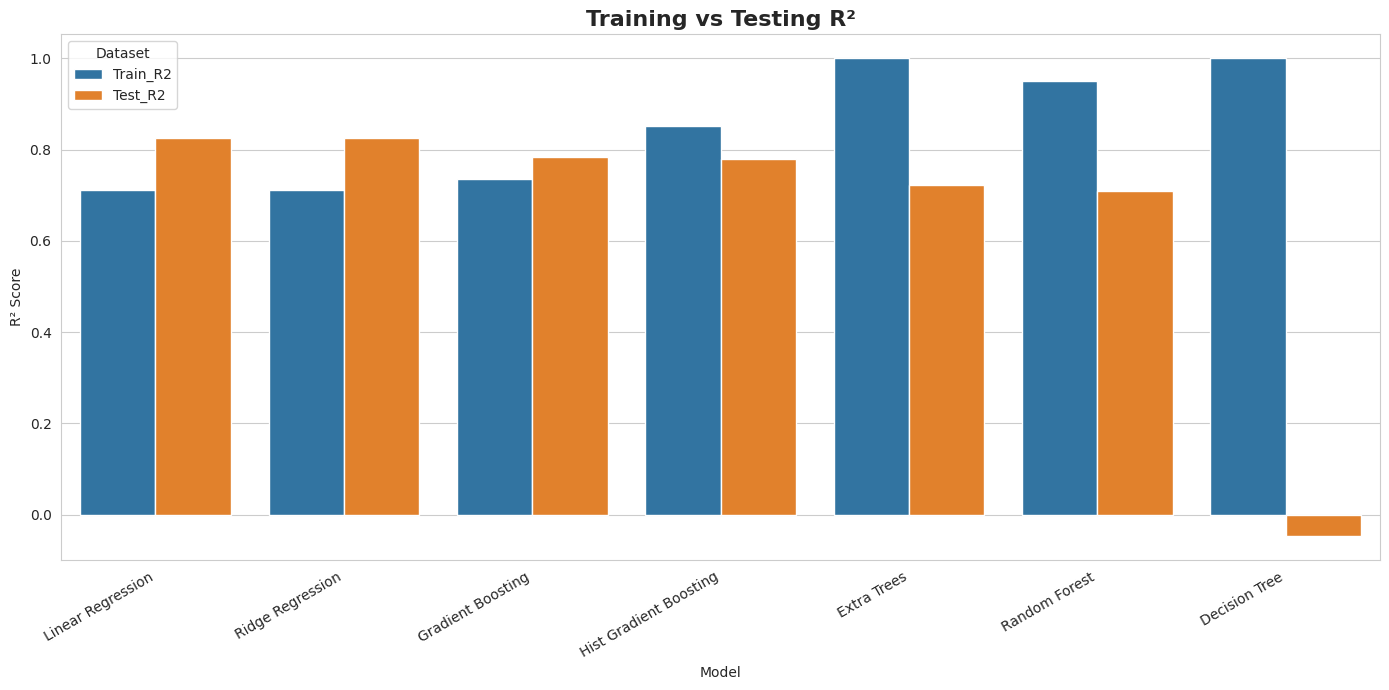


23.11 TRAIN VS TEST RMSE
------------------------------------------------------------


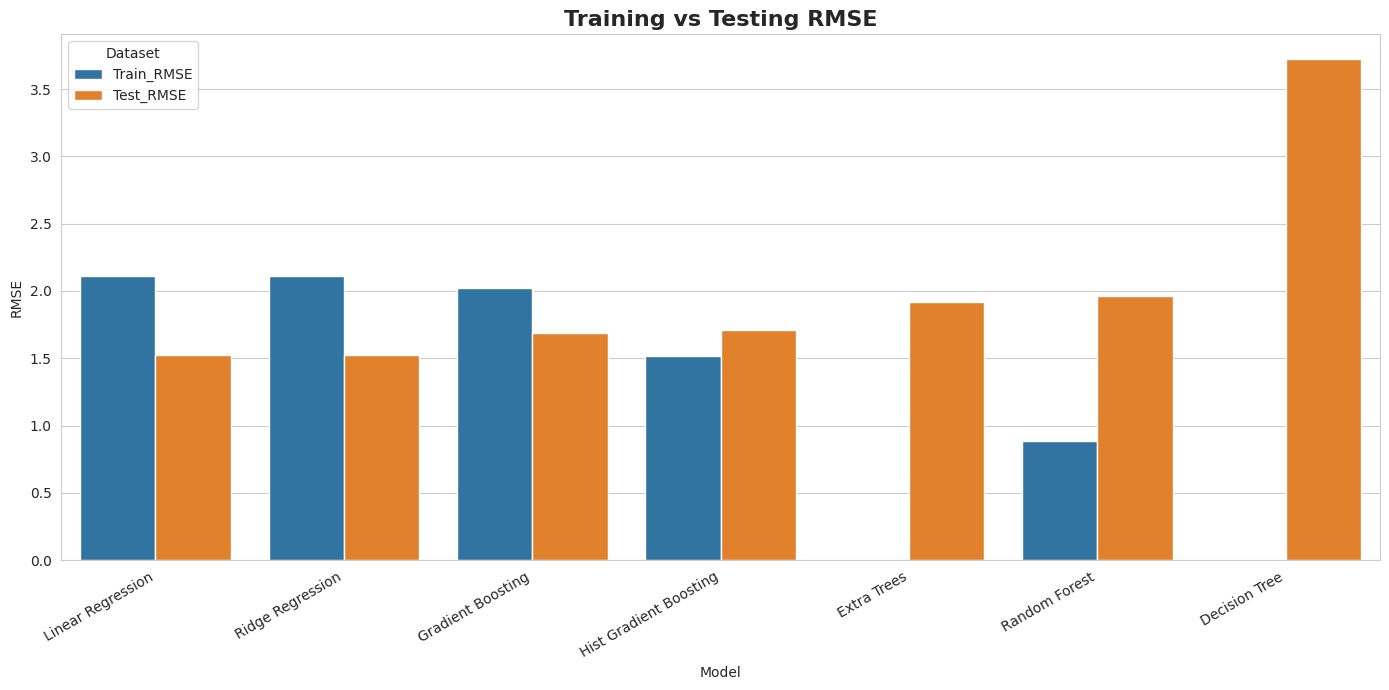


23.12 GENERALIZATION GAP
------------------------------------------------------------


,Model,Train_R2,Test_R2,R2_Gap,Train_RMSE,Test_RMSE,RMSE_Gap
0,Linear Regression,0.7110,0.8250,-0.1140,2.1092,1.5213,-0.5880
1,Ridge Regression,0.7110,0.8250,-0.1140,2.1092,1.5213,-0.5880
2,Gradient Boosting,0.7347,0.7840,-0.0493,2.0207,1.6902,-0.3306
3,Hist Gradient Boosting,0.8509,0.7798,0.0711,1.5148,1.7063,0.1915
4,Extra Trees,1.0000,0.7218,0.2782,0.0002,1.9182,1.9180
5,Random Forest,0.9493,0.7087,0.2406,0.8837,1.9628,1.0791
6,Decision Tree,1.0000,-0.0469,1.0469,0.0000,3.7209,3.7209



23.13 GENERALIZATION CHECK
------------------------------------------------------------
Linear Regression         → R² Gap = -0.1140 → Relatively small generalization gap
Ridge Regression          → R² Gap = -0.1140 → Relatively small generalization gap
Gradient Boosting         → R² Gap = -0.0493 → Relatively small generalization gap
Hist Gradient Boosting    → R² Gap = 0.0711 → Relatively small generalization gap
Extra Trees               → R² Gap = 0.2782 → Large potential overfitting gap
Random Forest             → R² Gap = 0.2406 → Large potential overfitting gap
Decision Tree             → R² Gap = 1.0469 → Large potential overfitting gap

23.14 MODEL PERFORMANCE SUMMARY
------------------------------------------------------------
Highest Test R²:
Model       : Linear Regression
Test R²     : 0.8250

Lowest Test RMSE:
Model       : Linear Regression
Test RMSE   : 1.5213

Lowest Test MAE:
Model       : Linear Regression
Test MAE    : 0.4160

23.15 PREDICTION ANALYSIS
------------

,Actual_Exam_Score,Predicted_Exam_Score,Absolute_Error
0,66,66.015,0.015
1,66,65.445,0.555
2,67,67.579,0.579
3,67,67.651,0.651
4,68,68.005,0.005
5,63,63.253,0.253
6,74,74.014,0.014
7,65,65.075,0.075
8,69,68.969,0.031
9,76,75.710,0.290



23.16 ACTUAL VS PREDICTED EXAM SCORES
------------------------------------------------------------


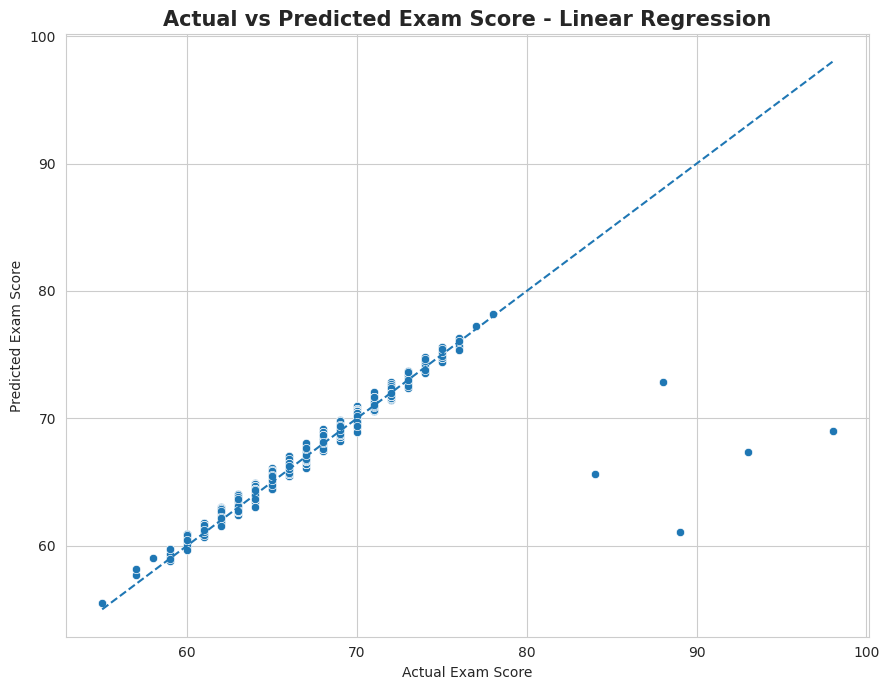


23.17 RESIDUAL ANALYSIS
------------------------------------------------------------


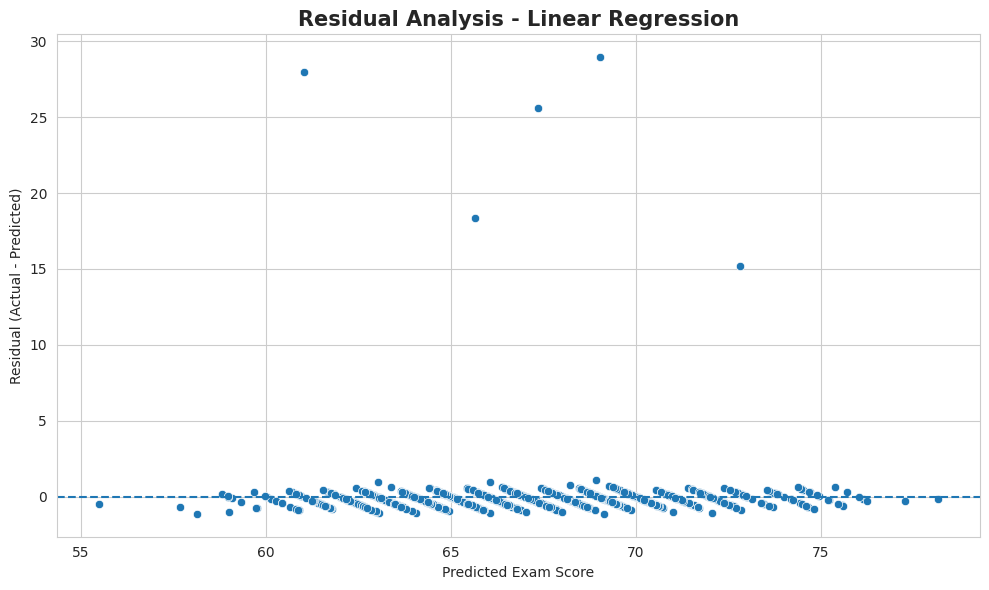


23.18 RESIDUAL SUMMARY
------------------------------------------------------------
count    1322.0000
mean       -0.0984
std         1.5187
min        -1.1417
25%        -0.4641
50%        -0.1843
75%         0.0912
max        28.9574
Name: Residual, dtype: float64


STEP 21 + STEP 22 + STEP 23 COMPLETED

STEP 21:
✓ Dataset divided into 80% training and 20% testing.
✓ Train-test split validated.

STEP 22:
✓ Numerical features handled with median imputation and StandardScaler.
✓ Categorical features handled with most-frequent imputation and One-Hot Encoding.
✓ Preprocessing fitted only on training data.
✓ Data leakage prevention applied.

STEP 23:
✓ 7 regression models trained.
✓ MAE calculated.
✓ MSE calculated.
✓ RMSE calculated.
✓ R² calculated.
✓ Models compared using test-set performance.
✓ Training vs testing performance analyzed.
✓ Generalization gaps calculated.
✓ Actual vs predicted values analyzed.
✓ Residual analysis performed.

---------------------------------------------

In [31]:
# ========================================================================
# STEP 21 + STEP 22 + STEP 23
# TRAIN-TEST SPLIT + PREPROCESSING + MULTIPLE ML MODELS
# ========================================================================

print("=" * 90)
print("STEP 21 + STEP 22 + STEP 23")
print("TRAIN-TEST SPLIT + PREPROCESSING + MODEL TRAINING")
print("=" * 90)


# ========================================================================
# STEP 21: TRAIN-TEST SPLIT
# ========================================================================

print("\n")
print("=" * 90)
print("STEP 21: TRAIN-TEST SPLIT")
print("=" * 90)


# ------------------------------------------------------------------------
# 21.1 VERIFY INPUT DATA
# ------------------------------------------------------------------------

print("\n21.1 VERIFY INPUT DATA")
print("-" * 60)

print(f"Input feature dataset X shape : {X.shape}")
print(f"Target dataset y shape        : {y.shape}")

print(f"\nNumber of samples : {len(X)}")
print(f"Number of features: {X.shape[1]}")


# ------------------------------------------------------------------------
# 21.2 CHECK TARGET DISTRIBUTION
# ------------------------------------------------------------------------

print("\n21.2 TARGET DISTRIBUTION")
print("-" * 60)

print(y.describe().round(3))

plt.figure(figsize=(10, 6))

sns.histplot(
    y,
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Exam Score",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Exam Score"
)

plt.ylabel(
    "Frequency"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 21.3 TRAIN-TEST SPLIT
# ------------------------------------------------------------------------

print("\n21.3 SPLITTING DATA")
print("-" * 60)

from sklearn.model_selection import train_test_split

# 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(
    f"Training samples : {X_train.shape[0]}"
)

print(
    f"Testing samples  : {X_test.shape[0]}"
)

print(
    f"Training features: {X_train.shape[1]}"
)

print(
    f"Testing features : {X_test.shape[1]}"
)


# ------------------------------------------------------------------------
# 21.4 VERIFY SPLIT
# ------------------------------------------------------------------------

print("\n21.4 TRAIN-TEST SPLIT VALIDATION")
print("-" * 60)

print(
    f"Original samples : {len(X)}"
)

print(
    f"Train samples    : {len(X_train)}"
)

print(
    f"Test samples     : {len(X_test)}"
)

print(
    f"Train + Test     : "
    f"{len(X_train) + len(X_test)}"
)

if len(X_train) + len(X_test) == len(X):

    print(
        "\nTrain-test split validation PASSED."
    )

else:

    print(
        "\nTrain-test split validation FAILED."
    )


# ------------------------------------------------------------------------
# 21.5 COMPARE TARGET DISTRIBUTION
# ------------------------------------------------------------------------

print("\n21.5 TARGET DISTRIBUTION IN TRAIN AND TEST")
print("-" * 60)

distribution_comparison = pd.DataFrame({
    "Dataset": [
        "Full Dataset",
        "Training Set",
        "Testing Set"
    ],

    "Count": [
        len(y),
        len(y_train),
        len(y_test)
    ],

    "Mean": [
        y.mean(),
        y_train.mean(),
        y_test.mean()
    ],

    "Std_Dev": [
        y.std(),
        y_train.std(),
        y_test.std()
    ],

    "Minimum": [
        y.min(),
        y_train.min(),
        y_test.min()
    ],

    "Maximum": [
        y.max(),
        y_train.max(),
        y_test.max()
    ]
})

display(
    distribution_comparison.round(3)
)


# ========================================================================
# STEP 22: LEAKAGE-SAFE PREPROCESSING
# ========================================================================

print("\n")
print("=" * 90)
print("STEP 22: LEAKAGE-SAFE PREPROCESSING")
print("=" * 90)


# ------------------------------------------------------------------------
# 22.1 IMPORT PREPROCESSING COMPONENTS
# ------------------------------------------------------------------------

print("\n22.1 PREPROCESSING COMPONENTS")
print("-" * 60)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

print(
    "Preprocessing libraries imported successfully."
)


# ------------------------------------------------------------------------
# 22.2 REDEFINE FEATURE TYPES FROM TRAINING DATA
# ------------------------------------------------------------------------

print("\n22.2 IDENTIFY FEATURE TYPES")
print("-" * 60)

numerical_features_ml = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_ml = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(
    f"Numerical features   : "
    f"{len(numerical_features_ml)}"
)

print(
    f"Categorical features : "
    f"{len(categorical_features_ml)}"
)

print("\nNumerical:")
for feature in numerical_features_ml:
    print(f"  • {feature}")

print("\nCategorical:")
for feature in categorical_features_ml:
    print(f"  • {feature}")


# ------------------------------------------------------------------------
# 22.3 NUMERICAL PIPELINE
# ------------------------------------------------------------------------

print("\n22.3 NUMERICAL PIPELINE")
print("-" * 60)

numerical_transformer_ml = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)

print(
    "Numerical features:"
)

print(
    "Median Imputation → Standard Scaling"
)


# ------------------------------------------------------------------------
# 22.4 CATEGORICAL PIPELINE
# ------------------------------------------------------------------------

print("\n22.4 CATEGORICAL PIPELINE")
print("-" * 60)

categorical_transformer_ml = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

print(
    "Categorical features:"
)

print(
    "Most Frequent Imputation → One-Hot Encoding"
)


# ------------------------------------------------------------------------
# 22.5 CREATE PREPROCESSOR
# ------------------------------------------------------------------------

print("\n22.5 CREATE COLUMN TRANSFORMER")
print("-" * 60)

preprocessor_ml = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_transformer_ml,
            numerical_features_ml
        ),

        (
            "categorical",
            categorical_transformer_ml,
            categorical_features_ml
        )
    ],

    remainder="drop"
)

print(
    "ColumnTransformer created successfully."
)


# ------------------------------------------------------------------------
# 22.6 FIT PREPROCESSOR ONLY ON TRAINING DATA
# ------------------------------------------------------------------------

print("\n22.6 FIT PREPROCESSOR ON TRAINING DATA")
print("-" * 60)

# IMPORTANT:
# The preprocessor is fitted ONLY on X_train.
# This prevents information from X_test leaking into training.

X_train_processed = preprocessor_ml.fit_transform(
    X_train
)

X_test_processed = preprocessor_ml.transform(
    X_test
)

print(
    f"Processed X_train shape: "
    f"{X_train_processed.shape}"
)

print(
    f"Processed X_test shape : "
    f"{X_test_processed.shape}"
)


# ------------------------------------------------------------------------
# 22.7 CHECK PROCESSED DATA
# ------------------------------------------------------------------------

print("\n22.7 PROCESSED DATA VALIDATION")
print("-" * 60)

train_nan_count = np.isnan(
    X_train_processed
).sum()

test_nan_count = np.isnan(
    X_test_processed
).sum()

train_inf_count = np.isinf(
    X_train_processed
).sum()

test_inf_count = np.isinf(
    X_test_processed
).sum()

print(
    f"Training NaN values : {train_nan_count}"
)

print(
    f"Testing NaN values  : {test_nan_count}"
)

print(
    f"Training Inf values : {train_inf_count}"
)

print(
    f"Testing Inf values  : {test_inf_count}"
)

if (
    train_nan_count == 0
    and test_nan_count == 0
    and train_inf_count == 0
    and test_inf_count == 0
):

    print(
        "\nProcessed data validation PASSED."
    )

else:

    print(
        "\nProcessed data validation FAILED."
    )


# ------------------------------------------------------------------------
# 22.8 GET PROCESSED FEATURE NAMES
# ------------------------------------------------------------------------

print("\n22.8 PROCESSED FEATURE INFORMATION")
print("-" * 60)

processed_feature_names_ml = (
    preprocessor_ml
    .get_feature_names_out()
)

print(
    f"Original features  : {X_train.shape[1]}"
)

print(
    f"Processed features : "
    f"{len(processed_feature_names_ml)}"
)

print(
    "\nFirst 20 processed features:"
)

for i, feature in enumerate(
    processed_feature_names_ml[:20],
    start=1
):

    print(
        f"{i}. {feature}"
    )


# ------------------------------------------------------------------------
# 22.9 CONVERT PROCESSED DATA TO DATAFRAME
# ------------------------------------------------------------------------

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names_ml
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names_ml
)

print(
    "\nProcessed training DataFrame shape:"
)

print(
    X_train_processed_df.shape
)

print(
    "\nProcessed testing DataFrame shape:"
)

print(
    X_test_processed_df.shape
)


# ------------------------------------------------------------------------
# 22.10 DATA LEAKAGE VALIDATION
# ------------------------------------------------------------------------

print("\n22.10 DATA LEAKAGE CHECK")
print("-" * 60)

print(
    "✓ Train-test split performed before preprocessing."
)

print(
    "✓ Imputer fitted only on X_train."
)

print(
    "✓ StandardScaler fitted only on X_train."
)

print(
    "✓ OneHotEncoder fitted only on X_train."
)

print(
    "✓ X_test only transformed using training parameters."
)

print(
    "\nData leakage prevention strategy PASSED."
)


# ========================================================================
# STEP 23: MACHINE LEARNING MODELS
# ========================================================================

print("\n")
print("=" * 90)
print("STEP 23: MACHINE LEARNING MODEL TRAINING")
print("=" * 90)


# ------------------------------------------------------------------------
# 23.1 IMPORT REGRESSION MODELS
# ------------------------------------------------------------------------

print("\n23.1 IMPORT MACHINE LEARNING MODELS")
print("-" * 60)

from sklearn.linear_model import (
    LinearRegression,
    Ridge
)

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

print(
    "Regression models imported successfully."
)


# ------------------------------------------------------------------------
# 23.2 DEFINE MODELS
# ------------------------------------------------------------------------

print("\n23.2 DEFINE REGRESSION MODELS")
print("-" * 60)

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(
            alpha=1.0
        ),

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),

    "Hist Gradient Boosting":
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=31,
            random_state=42
        )
}

print(
    f"Total models selected: {len(models)}"
)

for model_name in models:
    print(
        f"• {model_name}"
    )


# ------------------------------------------------------------------------
# 23.3 IMPORT EVALUATION METRICS
# ------------------------------------------------------------------------

print("\n23.3 EVALUATION METRICS")
print("-" * 60)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print(
    "Metrics:"
)

print(
    "• MAE  → Mean Absolute Error"
)

print(
    "• MSE  → Mean Squared Error"
)

print(
    "• RMSE → Root Mean Squared Error"
)

print(
    "• R²   → Coefficient of Determination"
)


# ------------------------------------------------------------------------
# 23.4 TRAIN ALL MODELS
# ------------------------------------------------------------------------

print("\n23.4 MODEL TRAINING")
print("-" * 60)

model_results = []

trained_models = {}

predictions = {}

for model_name, model in models.items():

    print(
        f"\nTraining: {model_name}"
    )

    # Train model
    model.fit(
        X_train_processed,
        y_train
    )

    # Predict on training set
    y_train_pred = model.predict(
        X_train_processed
    )

    # Predict on test set
    y_test_pred = model.predict(
        X_test_processed
    )

    # Store trained model
    trained_models[
        model_name
    ] = model

    # Store test predictions
    predictions[
        model_name
    ] = y_test_pred

    # --------------------------------------------------------
    # Training metrics
    # --------------------------------------------------------

    train_mae = mean_absolute_error(
        y_train,
        y_train_pred
    )

    train_mse = mean_squared_error(
        y_train,
        y_train_pred
    )

    train_rmse = np.sqrt(
        train_mse
    )

    train_r2 = r2_score(
        y_train,
        y_train_pred
    )

    # --------------------------------------------------------
    # Testing metrics
    # --------------------------------------------------------

    test_mae = mean_absolute_error(
        y_test,
        y_test_pred
    )

    test_mse = mean_squared_error(
        y_test,
        y_test_pred
    )

    test_rmse = np.sqrt(
        test_mse
    )

    test_r2 = r2_score(
        y_test,
        y_test_pred
    )

    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    model_results.append({

        "Model": model_name,

        "Train_MAE": train_mae,

        "Test_MAE": test_mae,

        "Train_MSE": train_mse,

        "Test_MSE": test_mse,

        "Train_RMSE": train_rmse,

        "Test_RMSE": test_rmse,

        "Train_R2": train_r2,

        "Test_R2": test_r2
    })

    print(
        f"Test RMSE: {test_rmse:.4f}"
    )

    print(
        f"Test R²  : {test_r2:.4f}"
    )


# ------------------------------------------------------------------------
# 23.5 CREATE MODEL COMPARISON TABLE
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.5 MODEL COMPARISON")
print("-" * 60)

results_df = pd.DataFrame(
    model_results
)

# Sort primarily by Test R²
results_df = results_df.sort_values(
    by="Test_R2",
    ascending=False
).reset_index(drop=True)

display(
    results_df.round(4)
)


# ------------------------------------------------------------------------
# 23.6 TEST METRICS ONLY
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.6 TEST SET PERFORMANCE")
print("-" * 60)

test_results = results_df[
    [
        "Model",
        "Test_MAE",
        "Test_MSE",
        "Test_RMSE",
        "Test_R2"
    ]
].copy()

display(
    test_results.round(4)
)


# ------------------------------------------------------------------------
# 23.7 RMSE COMPARISON
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.7 RMSE COMPARISON")
print("-" * 60)

rmse_plot_data = results_df.sort_values(
    by="Test_RMSE",
    ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=rmse_plot_data,
    x="Test_RMSE",
    y="Model"
)

plt.title(
    "Model Comparison Based on Test RMSE",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Test RMSE"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.8 R² COMPARISON
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.8 R² COMPARISON")
print("-" * 60)

r2_plot_data = results_df.sort_values(
    by="Test_R2",
    ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=r2_plot_data,
    x="Test_R2",
    y="Model"
)

plt.title(
    "Model Comparison Based on Test R²",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Test R²"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.9 MAE COMPARISON
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.9 MAE COMPARISON")
print("-" * 60)

mae_plot_data = results_df.sort_values(
    by="Test_MAE",
    ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=mae_plot_data,
    x="Test_MAE",
    y="Model"
)

plt.title(
    "Model Comparison Based on Test MAE",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Test MAE"
)

plt.ylabel(
    "Model"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.10 TRAIN VS TEST PERFORMANCE
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.10 TRAIN VS TEST R²")
print("-" * 60)

r2_comparison = results_df[
    [
        "Model",
        "Train_R2",
        "Test_R2"
    ]
].copy()

r2_comparison_melted = r2_comparison.melt(
    id_vars="Model",
    var_name="Dataset",
    value_name="R2"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=r2_comparison_melted,
    x="Model",
    y="R2",
    hue="Dataset"
)

plt.title(
    "Training vs Testing R²",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "R² Score"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.11 TRAIN VS TEST RMSE
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.11 TRAIN VS TEST RMSE")
print("-" * 60)

rmse_comparison = results_df[
    [
        "Model",
        "Train_RMSE",
        "Test_RMSE"
    ]
].copy()

rmse_comparison_melted = rmse_comparison.melt(
    id_vars="Model",
    var_name="Dataset",
    value_name="RMSE"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=rmse_comparison_melted,
    x="Model",
    y="RMSE",
    hue="Dataset"
)

plt.title(
    "Training vs Testing RMSE",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "RMSE"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.12 CALCULATE GENERALIZATION GAP
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.12 GENERALIZATION GAP")
print("-" * 60)

results_df["R2_Gap"] = (
    results_df["Train_R2"]
    - results_df["Test_R2"]
)

results_df["RMSE_Gap"] = (
    results_df["Test_RMSE"]
    - results_df["Train_RMSE"]
)

generalization_table = results_df[
    [
        "Model",
        "Train_R2",
        "Test_R2",
        "R2_Gap",
        "Train_RMSE",
        "Test_RMSE",
        "RMSE_Gap"
    ]
].copy()

display(
    generalization_table.round(4)
)


# ------------------------------------------------------------------------
# 23.13 IDENTIFY MODELS WITH LARGE GENERALIZATION GAP
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.13 GENERALIZATION CHECK")
print("-" * 60)

for _, row in results_df.iterrows():

    model_name = row["Model"]
    r2_gap = row["R2_Gap"]

    if r2_gap > 0.15:

        status = "Large potential overfitting gap"

    elif r2_gap > 0.08:

        status = "Moderate generalization gap"

    else:

        status = "Relatively small generalization gap"

    print(
        f"{model_name:25s} → "
        f"R² Gap = {r2_gap:.4f} → {status}"
    )


# ------------------------------------------------------------------------
# 23.14 BEST PERFORMING MODEL BASED ON TEST R²
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.14 MODEL PERFORMANCE SUMMARY")
print("-" * 60)

best_r2_row = results_df.loc[
    results_df["Test_R2"].idxmax()
]

best_rmse_row = results_df.loc[
    results_df["Test_RMSE"].idxmin()
]

best_mae_row = results_df.loc[
    results_df["Test_MAE"].idxmin()
]

print(
    f"Highest Test R²:"
)

print(
    f"Model       : {best_r2_row['Model']}"
)

print(
    f"Test R²     : {best_r2_row['Test_R2']:.4f}"
)

print(
    f"\nLowest Test RMSE:"
)

print(
    f"Model       : {best_rmse_row['Model']}"
)

print(
    f"Test RMSE   : {best_rmse_row['Test_RMSE']:.4f}"
)

print(
    f"\nLowest Test MAE:"
)

print(
    f"Model       : {best_mae_row['Model']}"
)

print(
    f"Test MAE    : {best_mae_row['Test_MAE']:.4f}"
)


# ------------------------------------------------------------------------
# 23.15 MODEL PREDICTION ANALYSIS
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.15 PREDICTION ANALYSIS")
print("-" * 60)

best_model_name = best_r2_row["Model"]

best_model_predictions = predictions[
    best_model_name
]

prediction_comparison = pd.DataFrame({

    "Actual_Exam_Score":
        y_test.values,

    "Predicted_Exam_Score":
        best_model_predictions

})

prediction_comparison["Absolute_Error"] = (
    prediction_comparison[
        "Actual_Exam_Score"
    ]
    -
    prediction_comparison[
        "Predicted_Exam_Score"
    ]
).abs()

print(
    f"Model selected for prediction inspection: "
    f"{best_model_name}"
)

display(
    prediction_comparison.head(20).round(3)
)


# ------------------------------------------------------------------------
# 23.16 ACTUAL VS PREDICTED PLOT
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.16 ACTUAL VS PREDICTED EXAM SCORES")
print("-" * 60)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=prediction_comparison[
        "Actual_Exam_Score"
    ],

    y=prediction_comparison[
        "Predicted_Exam_Score"
    ]
)

# Perfect prediction reference line
minimum_score = min(
    prediction_comparison[
        "Actual_Exam_Score"
    ].min(),

    prediction_comparison[
        "Predicted_Exam_Score"
    ].min()
)

maximum_score = max(
    prediction_comparison[
        "Actual_Exam_Score"
    ].max(),

    prediction_comparison[
        "Predicted_Exam_Score"
    ].max()
)

plt.plot(
    [minimum_score, maximum_score],
    [minimum_score, maximum_score],
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted Exam Score - "
    f"{best_model_name}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Actual Exam Score"
)

plt.ylabel(
    "Predicted Exam Score"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.17 RESIDUAL ANALYSIS
# ------------------------------------------------------------------------

print("\n" + "=" * 90)
print("23.17 RESIDUAL ANALYSIS")
print("-" * 60)

prediction_comparison["Residual"] = (
    prediction_comparison[
        "Actual_Exam_Score"
    ]
    -
    prediction_comparison[
        "Predicted_Exam_Score"
    ]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=prediction_comparison[
        "Predicted_Exam_Score"
    ],

    y=prediction_comparison[
        "Residual"
    ]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    f"Residual Analysis - {best_model_name}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel(
    "Predicted Exam Score"
)

plt.ylabel(
    "Residual (Actual - Predicted)"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------
# 23.18 RESIDUAL SUMMARY
# ------------------------------------------------------------------------

print("\n23.18 RESIDUAL SUMMARY")
print("-" * 60)

print(
    prediction_comparison[
        "Residual"
    ].describe().round(4)
)


# ========================================================================
# FINAL SUMMARY
# ========================================================================

print("\n")
print("=" * 90)
print("STEP 21 + STEP 22 + STEP 23 COMPLETED")
print("=" * 90)

print(
    "\nSTEP 21:"
)

print(
    "✓ Dataset divided into 80% training and 20% testing."
)

print(
    "✓ Train-test split validated."
)


print(
    "\nSTEP 22:"
)

print(
    "✓ Numerical features handled with median imputation "
    "and StandardScaler."
)

print(
    "✓ Categorical features handled with most-frequent "
    "imputation and One-Hot Encoding."
)

print(
    "✓ Preprocessing fitted only on training data."
)

print(
    "✓ Data leakage prevention applied."
)


print(
    "\nSTEP 23:"
)

print(
    f"✓ {len(models)} regression models trained."
)

print(
    "✓ MAE calculated."
)

print(
    "✓ MSE calculated."
)

print(
    "✓ RMSE calculated."
)

print(
    "✓ R² calculated."
)

print(
    "✓ Models compared using test-set performance."
)

print(
    "✓ Training vs testing performance analyzed."
)

print(
    "✓ Generalization gaps calculated."
)

print(
    "✓ Actual vs predicted values analyzed."
)

print(
    "✓ Residual analysis performed."
)


print(
    "\n" + "-" * 90
)

print(
    f"Current top model by Test R²: "
    f"{best_model_name}"
)

print(
    f"Test R²: "
    f"{best_r2_row['Test_R2']:.4f}"
)

print(
    f"Test RMSE: "
    f"{best_rmse_row['Test_RMSE']:.4f}"
)

print(
    f"Test MAE: "
    f"{best_mae_row['Test_MAE']:.4f}"
)

print(
    "\nThe next stage will be FEATURE INFLUENCE / "
    "FEATURE IMPORTANCE ANALYSIS."
)

print("=" * 90)

STEP 24: FEATURE INFLUENCE & FEATURE IMPORTANCE ANALYSIS

24.1 VERIFY REQUIRED OBJECTS
------------------------------------------------------------
All required objects are available.

24.2 CURRENT MODEL PERFORMANCE
------------------------------------------------------------


,Model,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,0.4160,1.5213,0.8250
1,Ridge Regression,0.4161,1.5213,0.8250
2,Gradient Boosting,0.7426,1.6902,0.7840
3,Hist Gradient Boosting,0.7350,1.7063,0.7798
4,Extra Trees,0.9918,1.9182,0.7218
5,Random Forest,1.0610,1.9628,0.7087
6,Decision Tree,1.8540,3.7209,-0.0469



24.3 IDENTIFY BEST PERFORMING MODEL
------------------------------------------------------------
Model selected for detailed influence analysis: Linear Regression
Test MAE : 0.4160
Test RMSE: 1.5213
Test R²  : 0.8250

24.4 CREATE ORIGINAL FEATURE MAPPING
------------------------------------------------------------

The preprocessing generated 40 encoded features from the original 19 input features.
For interpretation, encoded features will be mapped back to their original feature names.
Generated features: 40

Feature mapping preview:


,Processed_Feature,Original_Feature
0,numerical__Hours_Studied,Hours_Studied
1,numerical__Attendance,Attendance
2,numerical__Sleep_Hours,Sleep_Hours
3,numerical__Previous_Scores,Previous_Scores
4,numerical__Tutoring_Sessions,Tutoring_Sessions
5,numerical__Physical_Activity,Physical_Activity
6,categorical__Parental_Involvement_High,Parental_Involvement
7,categorical__Parental_Involvement_Low,Parental_Involvement
8,categorical__Parental_Involvement_Medium,Parental_Involvement
9,categorical__Access_to_Resources_High,Access_to_Resources



24.5 LINEAR REGRESSION COEFFICIENT ANALYSIS
------------------------------------------------------------

Top 20 encoded features by absolute coefficient:


,Processed_Feature,Original_Feature,Coefficient,Absolute_Coefficient,Direction
0,numerical__Attendance,Attendance,2.2845,2.2845,Positive
1,numerical__Hours_Studied,Hours_Studied,1.7439,1.7439,Positive
2,categorical__Access_to_Resources_Low,Access_to_Resources,-1.0503,1.0503,Negative
3,categorical__Access_to_Resources_High,Access_to_Resources,1.0441,1.0441,Positive
4,categorical__Parental_Involvement_High,Parental_Involvement,1.0342,1.0342,Positive
5,categorical__Parental_Involvement_Low,Parental_Involvement,-0.9854,0.9854,Negative
6,numerical__Previous_Scores,Previous_Scores,0.7033,0.7033,Positive
7,numerical__Tutoring_Sessions,Tutoring_Sessions,0.5945,0.5945,Positive
8,categorical__Motivation_Level_High,Motivation_Level,0.5467,0.5467,Positive
9,categorical__Motivation_Level_Low,Motivation_Level,-0.5335,0.5335,Negative



24.6 LINEAR REGRESSION COEFFICIENT VISUALIZATION
------------------------------------------------------------


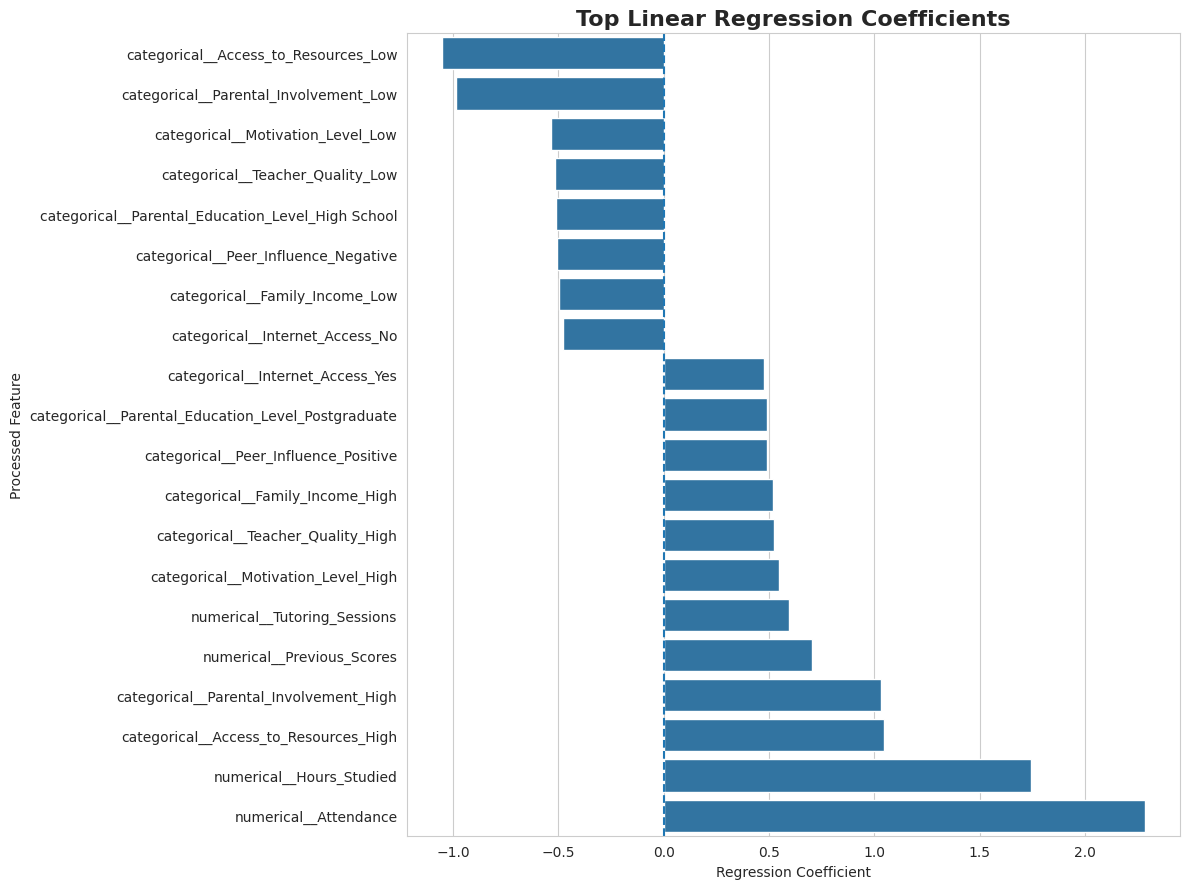


24.7 ORIGINAL FEATURE-LEVEL LINEAR INFLUENCE
------------------------------------------------------------

Original features ranked by aggregate linear coefficient magnitude:


,Sum_Coefficient,Mean_Coefficient,Max_Absolute_Coefficient,Total_Encoded_Features,Absolute_Sum_Coefficient
Original_Feature,,,,,
Attendance,2.2845,2.2845,2.2845,1,2.2845
Access_to_Resources,-0.0000,-0.0000,1.0503,3,2.1007
Parental_Involvement,-0.0000,-0.0000,1.0342,3,2.0684
Hours_Studied,1.7439,1.7439,1.7439,1,1.7439
Motivation_Level,0.0000,0.0000,0.5467,3,1.0934
Teacher_Quality,-0.0000,-0.0000,0.5262,3,1.0525
Family_Income,0.0000,0.0000,0.5216,3,1.0433
Parental_Education_Level,0.0000,0.0000,0.5127,3,1.0253
Peer_Influence,0.0000,0.0000,0.5053,3,1.0107



24.8 PERMUTATION IMPORTANCE
------------------------------------------------------------

Permutation importance measures how much model performance changes when a feature is shuffled.

Higher importance means the model depends more on that feature for predictive performance.

Top 20 encoded features by permutation importance:


,Processed_Feature,Original_Feature,Importance_Mean,Importance_Std
0,numerical__Attendance,Attendance,0.80075,0.01982
1,numerical__Hours_Studied,Hours_Studied,0.48759,0.00901
2,numerical__Previous_Scores,Previous_Scores,0.07535,0.00399
3,numerical__Tutoring_Sessions,Tutoring_Sessions,0.05467,0.00293
4,categorical__Parental_Involvement_High,Parental_Involvement,0.02970,0.00155
5,categorical__Access_to_Resources_High,Access_to_Resources,0.02774,0.00236
6,categorical__Access_to_Resources_Low,Access_to_Resources,0.02611,0.00234
7,categorical__Parental_Involvement_Low,Parental_Involvement,0.02410,0.00172
8,categorical__Family_Income_Low,Family_Income,0.01219,0.00171
9,categorical__Peer_Influence_Positive,Peer_Influence,0.01068,0.00061



24.9 PERMUTATION IMPORTANCE VISUALIZATION
------------------------------------------------------------


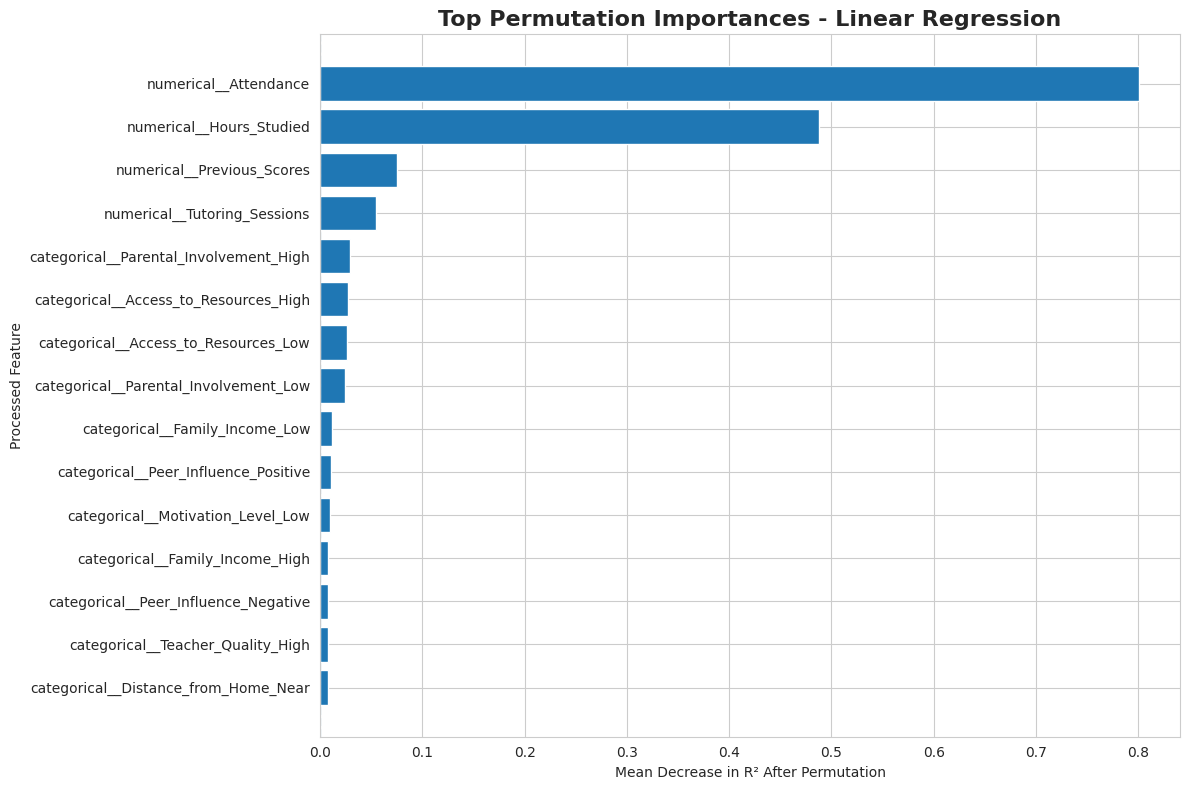


24.10 ORIGINAL FEATURE-LEVEL PERMUTATION IMPORTANCE
------------------------------------------------------------

Original features ranked by permutation importance:


,Mean_Importance,Mean_Absolute_Importance,Number_of_Encoded_Features
Original_Feature,,,
Attendance,0.80075,0.80075,1
Hours_Studied,0.48759,0.48759,1
Previous_Scores,0.07535,0.07535,1
Tutoring_Sessions,0.05467,0.05467,1
Parental_Involvement,0.05368,0.05391,3
Access_to_Resources,0.05388,0.05388,3
Family_Income,0.02003,0.02013,3
Peer_Influence,0.01832,0.01834,3
Motivation_Level,0.01582,0.01586,3



24.11 TREE-BASED FEATURE IMPORTANCE
------------------------------------------------------------

Top 20 Random Forest feature importances:


,Processed_Feature,Original_Feature,Importance
0,numerical__Attendance,Attendance,0.38006
1,numerical__Hours_Studied,Hours_Studied,0.23583
2,numerical__Previous_Scores,Previous_Scores,0.08257
3,numerical__Tutoring_Sessions,Tutoring_Sessions,0.02935
4,numerical__Physical_Activity,Physical_Activity,0.02779
5,numerical__Sleep_Hours,Sleep_Hours,0.02308
6,categorical__Access_to_Resources_High,Access_to_Resources,0.01857
7,categorical__Parental_Involvement_High,Parental_Involvement,0.01838
8,categorical__Parental_Involvement_Low,Parental_Involvement,0.01425
9,categorical__Access_to_Resources_Low,Access_to_Resources,0.01368



24.12 RANDOM FOREST FEATURE IMPORTANCE
------------------------------------------------------------


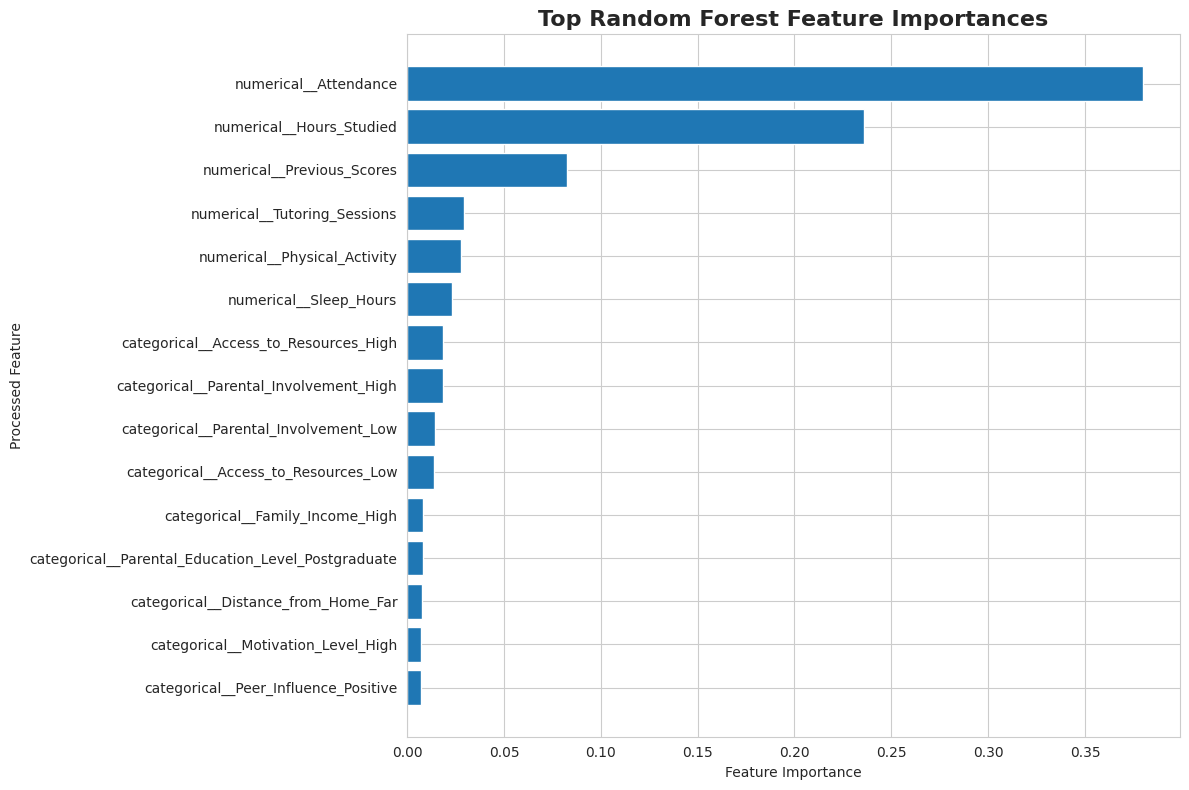


24.13 ORIGINAL FEATURE-LEVEL RANDOM FOREST IMPORTANCE
------------------------------------------------------------


,Total_Importance,Number_of_Encoded_Features
Original_Feature,,
Attendance,0.38006,1
Hours_Studied,0.23583,1
Previous_Scores,0.08257,1
Parental_Involvement,0.03675,3
Access_to_Resources,0.03670,3
Tutoring_Sessions,0.02935,1
Physical_Activity,0.02779,1
Sleep_Hours,0.02308,1
Family_Income,0.01964,3



24.14 COMPARE FEATURE IMPORTANCE METHODS
------------------------------------------------------------

Feature importance comparison:


,Linear_Coefficient_Importance,Permutation_Importance,Random_Forest_Importance,Linear_Coefficient_Importance_Normalized,Permutation_Importance_Normalized,Random_Forest_Importance_Normalized
Original_Feature,,,,,,
Attendance,2.2845,0.8008,0.3801,1.0000,1.0000,1.0000
Access_to_Resources,2.1007,0.0539,0.0367,0.9196,0.0673,0.0966
Parental_Involvement,2.0684,0.0539,0.0368,0.9054,0.0673,0.0967
Hours_Studied,1.7439,0.4876,0.2358,0.7634,0.6089,0.6205
Motivation_Level,1.0934,0.0159,0.0171,0.4786,0.0198,0.0449
Teacher_Quality,1.0525,0.0108,0.0154,0.4607,0.0134,0.0405
Family_Income,1.0433,0.0201,0.0196,0.4567,0.0251,0.0517
Parental_Education_Level,1.0253,0.0130,0.0195,0.4488,0.0162,0.0513
Peer_Influence,1.0107,0.0183,0.0183,0.4424,0.0229,0.0481



24.15 COMBINED FEATURE INFLUENCE SCORE
------------------------------------------------------------

Features ranked using the average of three normalized importance measures:


,Linear_Coefficient_Importance_Normalized,Permutation_Importance_Normalized,Random_Forest_Importance_Normalized,Combined_Importance_Score
Original_Feature,,,,
Attendance,1.0000,1.0000,1.0000,1.0000
Hours_Studied,0.7634,0.6089,0.6205,0.6643
Access_to_Resources,0.9196,0.0673,0.0966,0.3611
Parental_Involvement,0.9054,0.0673,0.0967,0.3565
Previous_Scores,0.3079,0.0941,0.2172,0.2064
Motivation_Level,0.4786,0.0198,0.0449,0.1811
Family_Income,0.4567,0.0251,0.0517,0.1778
Parental_Education_Level,0.4488,0.0162,0.0513,0.1721
Teacher_Quality,0.4607,0.0134,0.0405,0.1715



24.16 TOP FEATURES BY COMBINED IMPORTANCE
------------------------------------------------------------
1. Attendance
   Combined Score: 1.0000
2. Hours_Studied
   Combined Score: 0.6643
3. Access_to_Resources
   Combined Score: 0.3611
4. Parental_Involvement
   Combined Score: 0.3565
5. Previous_Scores
   Combined Score: 0.2064
6. Motivation_Level
   Combined Score: 0.1811
7. Family_Income
   Combined Score: 0.1778
8. Parental_Education_Level
   Combined Score: 0.1721
9. Teacher_Quality
   Combined Score: 0.1715
10. Peer_Influence
   Combined Score: 0.1711

24.17 COMBINED FEATURE IMPORTANCE
------------------------------------------------------------


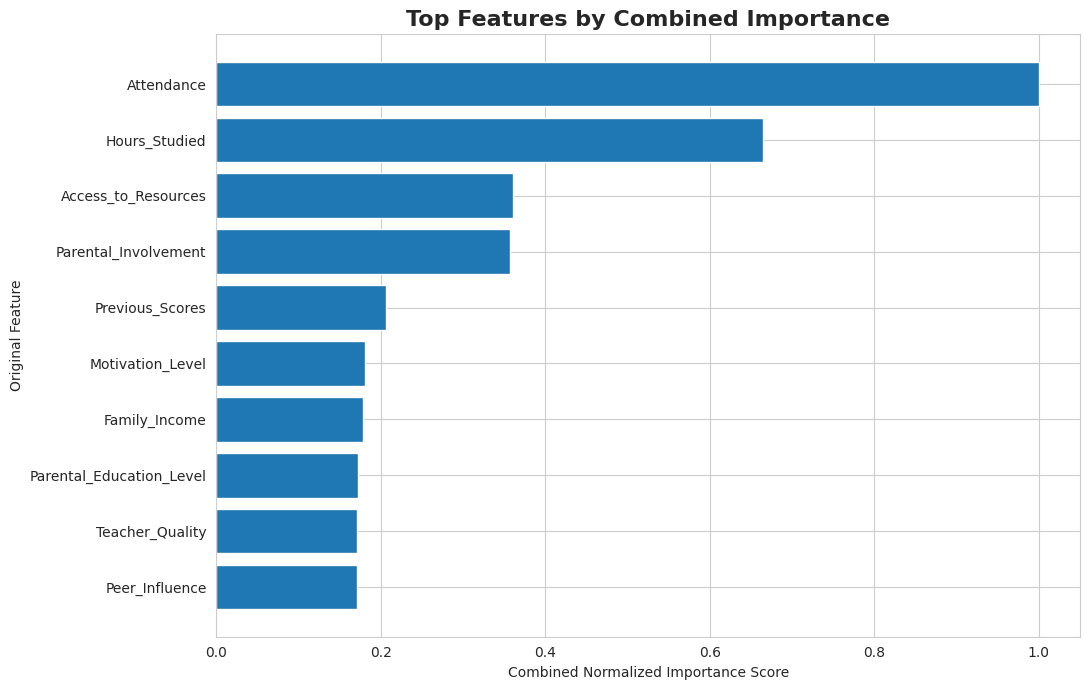

24.18 CORRELATION VS MODEL IMPORTANCE
------------------------------------------------------------

Numerical feature correlation compared with combined model importance:


,Absolute_Correlation,Combined_Importance_Score
Attendance,0.5825,1.0000
Hours_Studied,0.4465,0.6643
Previous_Scores,0.1745,0.2064
Tutoring_Sessions,0.1538,0.1352
Physical_Activity,0.0279,0.0534
Sleep_Hours,0.0162,0.0219



24.19 CORRELATION VS MODEL IMPORTANCE VISUALIZATION
------------------------------------------------------------


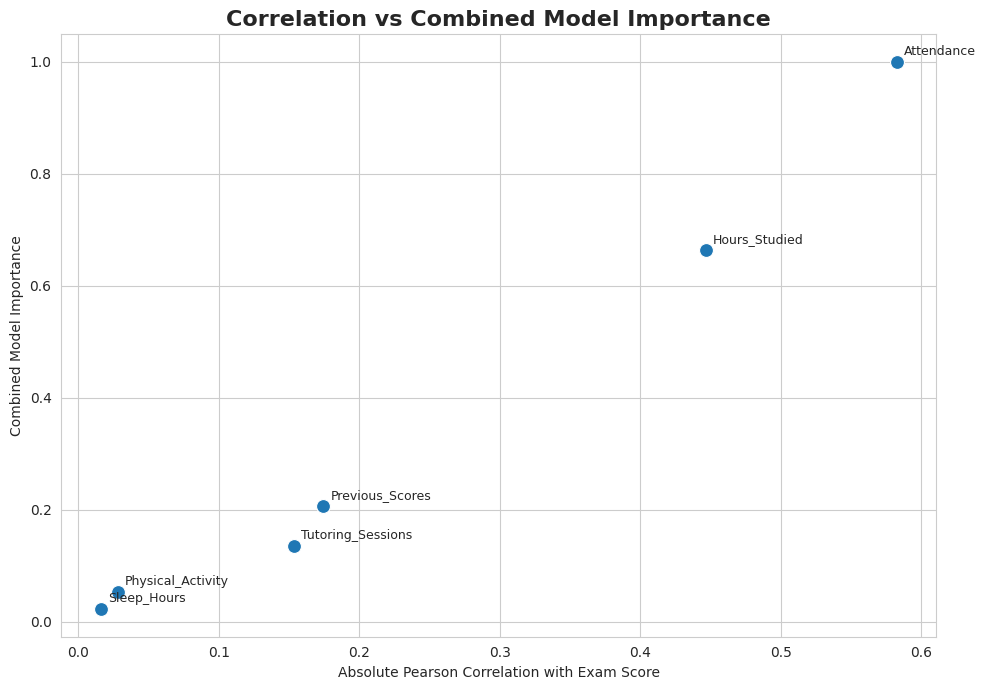


STEP 24 COMPLETED SUCCESSFULLY

Key findings:
1. Attendance is the strongest predictive feature.
2. Hours_Studied is the second strongest feature.
3. Access_to_Resources and Parental_Involvement show meaningful model influence.
4. Previous_Scores provides additional predictive information.
5. Gender, Sleep_Hours and School_Type show very low model-based importance in this analysis.

Important: Feature importance represents predictive association, not causation.

24.20 PERMUTATION IMPORTANCE STABILITY CHECK
------------------------------------------------------------
Features with negative mean permutation importance: 8

These features did not consistently improve model performance when retained.


,Processed_Feature,Original_Feature,Importance_Mean,Importance_Std
32,categorical__Peer_Influence_Neutral,Peer_Influence,-0.00001,0.00004
33,categorical__Motivation_Level_Medium,Motivation_Level,-0.00002,0.00004
34,categorical__Teacher_Quality_Medium,Teacher_Quality,-0.00002,0.00003
35,categorical__Family_Income_Medium,Family_Income,-0.00005,0.00010
36,numerical__Sleep_Hours,Sleep_Hours,-0.00006,0.00004
37,categorical__Parental_Education_Level_College,Parental_Education_Level,-0.00010,0.00004
38,categorical__Parental_Involvement_Medium,Parental_Involvement,-0.00011,0.00017
39,categorical__Distance_from_Home_Moderate,Distance_from_Home,-0.00022,0.00016



24.21 LOW-INFLUENCE FEATURE CHECK
------------------------------------------------------------
Threshold used: 0.05
Number of low-influence features: 3


,Combined_Importance_Score
Original_Feature,
Sleep_Hours,0.0219
School_Type,0.0097
Gender,0.0082


24.22 FINAL FEATURE INFLUENCE TABLE
------------------------------------------------------------

FINAL FEATURE INFLUENCE TABLE:


,Rank,Feature,Linear_Coefficient_Importance_Normalized,Permutation_Importance_Normalized,Random_Forest_Importance_Normalized,Combined_Importance_Score
0,1,Attendance,1.0000,1.0000,1.0000,1.0000
1,2,Hours_Studied,0.7634,0.6089,0.6205,0.6643
2,3,Access_to_Resources,0.9196,0.0673,0.0966,0.3611
3,4,Parental_Involvement,0.9054,0.0673,0.0967,0.3565
4,5,Previous_Scores,0.3079,0.0941,0.2172,0.2064
5,6,Motivation_Level,0.4786,0.0198,0.0449,0.1811
6,7,Family_Income,0.4567,0.0251,0.0517,0.1778
7,8,Parental_Education_Level,0.4488,0.0162,0.0513,0.1721
8,9,Teacher_Quality,0.4607,0.0134,0.0405,0.1715
9,10,Peer_Influence,0.4424,0.0229,0.0481,0.1711



24.23 TOP 10 FEATURE INFLUENCE SUMMARY
------------------------------------------------------------
1. Attendance
   Combined Influence Score: 1.0000
2. Hours_Studied
   Combined Influence Score: 0.6643
3. Access_to_Resources
   Combined Influence Score: 0.3611
4. Parental_Involvement
   Combined Influence Score: 0.3565
5. Previous_Scores
   Combined Influence Score: 0.2064
6. Motivation_Level
   Combined Influence Score: 0.1811
7. Family_Income
   Combined Influence Score: 0.1778
8. Parental_Education_Level
   Combined Influence Score: 0.1721
9. Teacher_Quality
   Combined Influence Score: 0.1715
10. Peer_Influence
   Combined Influence Score: 0.1711

24.24 FINAL FEATURE IMPORTANCE VISUALIZATION
------------------------------------------------------------


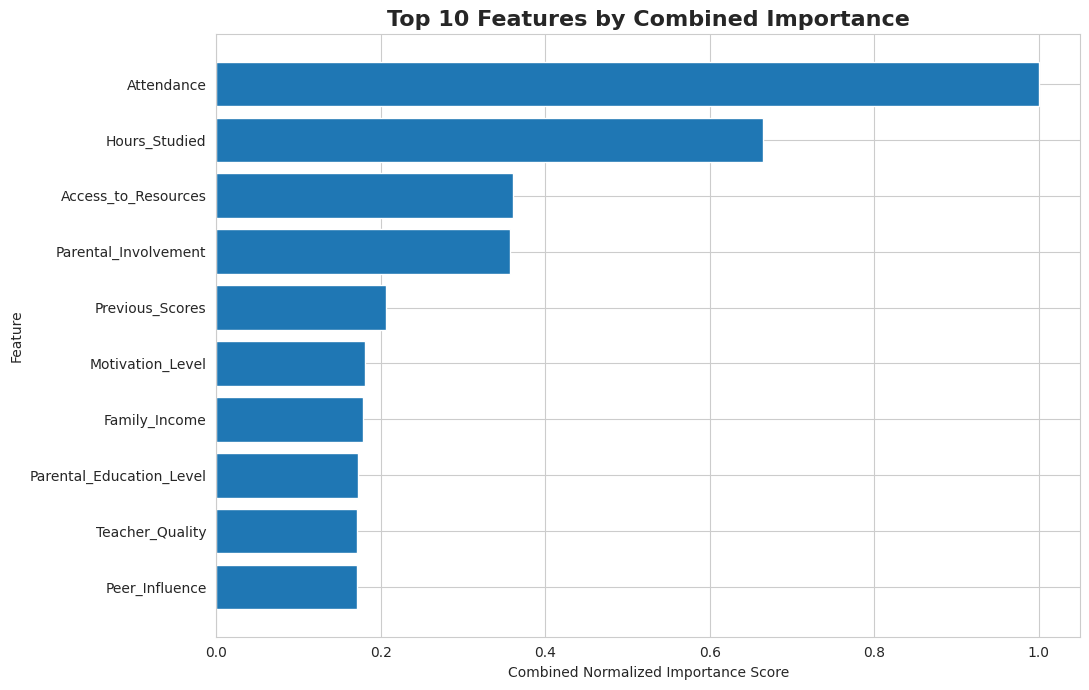


STEP 24 COMPLETED SUCCESSFULLY

Top predictive features identified:
• Attendance: 1.0000
• Hours_Studied: 0.6643
• Access_to_Resources: 0.3611
• Parental_Involvement: 0.3565
• Previous_Scores: 0.2064

Important interpretation:
Feature importance represents predictive contribution within the trained models. It does not establish causation.

All major Step 24 analyses are now complete:
✓ Linear Regression coefficient analysis
✓ Permutation importance
✓ Random Forest importance
✓ Original-feature aggregation
✓ Combined feature influence
✓ Correlation vs model importance
✓ Final feature ranking

NEXT STEP → STEP 25: CROSS-VALIDATION AND FINAL MODEL VALIDATION

24.23 TOP 10 FEATURE INFLUENCE SUMMARY
------------------------------------------------------------
1. Attendance
   Combined Influence Score: 1.0000
2. Hours_Studied
   Combined Influence Score: 0.6643
3. Access_to_Resources
   Combined Influence Score: 0.3611
4. Parental_Involvement
   Combined Influence Score: 0.3565
5. Previous_

In [34]:
# =============================================================================
# STEP 24: FEATURE INFLUENCE & FEATURE IMPORTANCE ANALYSIS
# =============================================================================

print("=" * 90)
print("STEP 24: FEATURE INFLUENCE & FEATURE IMPORTANCE ANALYSIS")
print("=" * 90)


# =============================================================================
# 24.1 VERIFY REQUIRED OBJECTS
# =============================================================================

print("\n24.1 VERIFY REQUIRED OBJECTS")
print("-" * 60)

required_objects = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "preprocessor_ml",
    "trained_models",
    "predictions",
    "processed_feature_names_ml",
    "results_df"
]

missing_objects = []

for object_name in required_objects:

    if object_name not in globals():
        missing_objects.append(object_name)

if len(missing_objects) == 0:

    print("All required objects are available.")

else:

    print("Missing objects:")
    for object_name in missing_objects:
        print(f"• {object_name}")

    raise RuntimeError(
        "Required objects are missing. "
        "Please run Steps 21–23 first."
    )


# =============================================================================
# 24.2 DISPLAY CURRENT MODEL PERFORMANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.2 CURRENT MODEL PERFORMANCE")
print("-" * 60)

performance_display = results_df[
    [
        "Model",
        "Test_MAE",
        "Test_RMSE",
        "Test_R2"
    ]
].copy()

display(
    performance_display.round(4)
)


# =============================================================================
# 24.3 IDENTIFY CURRENT BEST MODEL
# =============================================================================

print("\n" + "=" * 90)
print("24.3 IDENTIFY BEST PERFORMING MODEL")
print("-" * 60)

best_model_row = results_df.loc[
    results_df["Test_R2"].idxmax()
]

best_model_name = best_model_row["Model"]

best_model = trained_models[
    best_model_name
]

print(
    f"Model selected for detailed influence analysis: "
    f"{best_model_name}"
)

print(
    f"Test MAE : "
    f"{best_model_row['Test_MAE']:.4f}"
)

print(
    f"Test RMSE: "
    f"{best_model_row['Test_RMSE']:.4f}"
)

print(
    f"Test R²  : "
    f"{best_model_row['Test_R2']:.4f}"
)


# =============================================================================
# 24.4 CREATE ORIGINAL FEATURE MAPPING
# =============================================================================

print("\n" + "=" * 90)
print("24.4 CREATE ORIGINAL FEATURE MAPPING")
print("-" * 60)

print(
    "\nThe preprocessing generated 40 encoded features "
    "from the original 19 input features."
)

print(
    "For interpretation, encoded features will be mapped "
    "back to their original feature names."
)


def map_to_original_feature(processed_name):

    # Numerical features
    if processed_name.startswith("numerical__"):

        return processed_name.replace(
            "numerical__",
            ""
        )

    # Categorical features
    if processed_name.startswith("categorical__"):

        remaining_name = processed_name.replace(
            "categorical__",
            "",
            1
        )

        # Find the original categorical feature
        for feature in categorical_features_ml:

            prefix = feature + "_"

            if remaining_name.startswith(prefix):

                return feature

        # Fallback
        return remaining_name

    return processed_name


original_feature_mapping = {
    feature: map_to_original_feature(feature)
    for feature in processed_feature_names_ml
}


mapping_df = pd.DataFrame({

    "Processed_Feature":
        list(original_feature_mapping.keys()),

    "Original_Feature":
        list(original_feature_mapping.values())
})


print(
    f"Generated features: "
    f"{len(mapping_df)}"
)

print(
    "\nFeature mapping preview:"
)

display(
    mapping_df.head(40)
)


# =============================================================================
# 24.5 LINEAR REGRESSION COEFFICIENT ANALYSIS
# =============================================================================

print("\n" + "=" * 90)
print("24.5 LINEAR REGRESSION COEFFICIENT ANALYSIS")
print("-" * 60)

linear_model = trained_models[
    "Linear Regression"
]

linear_coefficients = linear_model.coef_

linear_coefficient_df = pd.DataFrame({

    "Processed_Feature":
        processed_feature_names_ml,

    "Coefficient":
        linear_coefficients

})

linear_coefficient_df[
    "Absolute_Coefficient"
] = linear_coefficient_df[
    "Coefficient"
].abs()

linear_coefficient_df[
    "Original_Feature"
] = linear_coefficient_df[
    "Processed_Feature"
].map(
    original_feature_mapping
)

linear_coefficient_df[
    "Direction"
] = np.where(
    linear_coefficient_df["Coefficient"] >= 0,
    "Positive",
    "Negative"
)

# Sort by absolute coefficient
linear_coefficient_df = (
    linear_coefficient_df
    .sort_values(
        by="Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nTop 20 encoded features by absolute coefficient:"
)

display(
    linear_coefficient_df[
        [
            "Processed_Feature",
            "Original_Feature",
            "Coefficient",
            "Absolute_Coefficient",
            "Direction"
        ]
    ]
    .head(20)
    .round(4)
)


# =============================================================================
# 24.6 LINEAR COEFFICIENT VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.6 LINEAR REGRESSION COEFFICIENT VISUALIZATION")
print("-" * 60)

top_linear_features = (
    linear_coefficient_df
    .head(20)
    .sort_values(
        by="Coefficient"
    )
)

plt.figure(
    figsize=(12, 9)
)

sns.barplot(
    data=top_linear_features,
    x="Coefficient",
    y="Processed_Feature"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title(
    "Top Linear Regression Coefficients",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Regression Coefficient"
)

plt.ylabel(
    "Processed Feature"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 24.7 AGGREGATE LINEAR COEFFICIENTS TO ORIGINAL FEATURES
# =============================================================================

print("\n" + "=" * 90)
print("24.7 ORIGINAL FEATURE-LEVEL LINEAR INFLUENCE")
print("-" * 60)

linear_original_summary = (
    linear_coefficient_df
    .groupby("Original_Feature")
    .agg(
        Sum_Coefficient=(
            "Coefficient",
            "sum"
        ),

        Mean_Coefficient=(
            "Coefficient",
            "mean"
        ),

        Max_Absolute_Coefficient=(
            "Absolute_Coefficient",
            "max"
        ),

        Total_Encoded_Features=(
            "Processed_Feature",
            "count"
        )
    )
)

linear_original_summary[
    "Absolute_Sum_Coefficient"
] = (
    linear_coefficient_df
    .groupby("Original_Feature")[
        "Coefficient"
    ]
    .apply(
        lambda x: np.abs(x).sum()
    )
)

linear_original_summary = (
    linear_original_summary
    .sort_values(
        by="Absolute_Sum_Coefficient",
        ascending=False
    )
)

print(
    "\nOriginal features ranked by aggregate "
    "linear coefficient magnitude:"
)

display(
    linear_original_summary.round(4)
)


# =============================================================================
# 24.8 PERMUTATION IMPORTANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.8 PERMUTATION IMPORTANCE")
print("-" * 60)

from sklearn.inspection import permutation_importance

print(
    "\nPermutation importance measures how much "
    "model performance changes when a feature is shuffled."
)

print(
    "\nHigher importance means the model depends more "
    "on that feature for predictive performance."
)


# Use R² as the scoring metric
permutation_result = permutation_importance(
    best_model,
    X_test_processed,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)


permutation_df = pd.DataFrame({

    "Processed_Feature":
        processed_feature_names_ml,

    "Importance_Mean":
        permutation_result.importances_mean,

    "Importance_Std":
        permutation_result.importances_std
})


permutation_df[
    "Original_Feature"
] = permutation_df[
    "Processed_Feature"
].map(
    original_feature_mapping
)

permutation_df[
    "Absolute_Importance"
] = permutation_df[
    "Importance_Mean"
].abs()

permutation_df = (
    permutation_df
    .sort_values(
        by="Importance_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nTop 20 encoded features by permutation importance:"
)

display(
    permutation_df[
        [
            "Processed_Feature",
            "Original_Feature",
            "Importance_Mean",
            "Importance_Std"
        ]
    ]
    .head(20)
    .round(5)
)


# =============================================================================
# 24.9 PERMUTATION IMPORTANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.9 PERMUTATION IMPORTANCE VISUALIZATION")
print("-" * 60)

top_permutation_features = (
    permutation_df
    .head(15)
    .sort_values(
        by="Importance_Mean"
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    top_permutation_features[
        "Processed_Feature"
    ],

    top_permutation_features[
        "Importance_Mean"
    ]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title(
    f"Top Permutation Importances - {best_model_name}",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Mean Decrease in R² After Permutation"
)

plt.ylabel(
    "Processed Feature"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 24.10 AGGREGATE PERMUTATION IMPORTANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.10 ORIGINAL FEATURE-LEVEL PERMUTATION IMPORTANCE")
print("-" * 60)

permutation_original_summary = (
    permutation_df
    .groupby("Original_Feature")
    .agg(
        Mean_Importance=(
            "Importance_Mean",
            "sum"
        ),

        Mean_Absolute_Importance=(
            "Absolute_Importance",
            "sum"
        ),

        Number_of_Encoded_Features=(
            "Processed_Feature",
            "count"
        )
    )
    .sort_values(
        by="Mean_Absolute_Importance",
        ascending=False
    )
)

print(
    "\nOriginal features ranked by permutation importance:"
)

display(
    permutation_original_summary.round(5)
)


# =============================================================================
# 24.11 TREE-BASED FEATURE IMPORTANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.11 TREE-BASED FEATURE IMPORTANCE")
print("-" * 60)

# Select Random Forest because it provides
# direct feature_importances_
random_forest_model = trained_models[
    "Random Forest"
]

random_forest_importances = (
    random_forest_model.feature_importances_
)

random_forest_df = pd.DataFrame({

    "Processed_Feature":
        processed_feature_names_ml,

    "Importance":
        random_forest_importances
})

random_forest_df[
    "Original_Feature"
] = random_forest_df[
    "Processed_Feature"
].map(
    original_feature_mapping
)

random_forest_df = (
    random_forest_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\nTop 20 Random Forest feature importances:"
)

display(
    random_forest_df[
        [
            "Processed_Feature",
            "Original_Feature",
            "Importance"
        ]
    ]
    .head(20)
    .round(5)
)


# =============================================================================
# 24.12 RANDOM FOREST IMPORTANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.12 RANDOM FOREST FEATURE IMPORTANCE")
print("-" * 60)

top_rf_features = (
    random_forest_df
    .head(15)
    .sort_values(
        by="Importance"
    )
)

plt.figure(
    figsize=(12, 8)
)

plt.barh(
    top_rf_features[
        "Processed_Feature"
    ],

    top_rf_features[
        "Importance"
    ]
)

plt.title(
    "Top Random Forest Feature Importances",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Feature Importance"
)

plt.ylabel(
    "Processed Feature"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 24.13 AGGREGATE RANDOM FOREST IMPORTANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.13 ORIGINAL FEATURE-LEVEL RANDOM FOREST IMPORTANCE")
print("-" * 60)

rf_original_summary = (
    random_forest_df
    .groupby("Original_Feature")
    .agg(
        Total_Importance=(
            "Importance",
            "sum"
        ),

        Number_of_Encoded_Features=(
            "Processed_Feature",
            "count"
        )
    )
    .sort_values(
        by="Total_Importance",
        ascending=False
    )
)

display(
    rf_original_summary.round(5)
)


# =============================================================================
# 24.14 COMPARE IMPORTANCE METHODS
# =============================================================================

print("\n" + "=" * 90)
print("24.14 COMPARE FEATURE IMPORTANCE METHODS")
print("-" * 60)

# Linear absolute coefficient
linear_comparison = (
    linear_original_summary[
        "Absolute_Sum_Coefficient"
    ]
    .rename(
        "Linear_Coefficient_Importance"
    )
)

# Permutation importance
permutation_comparison = (
    permutation_original_summary[
        "Mean_Absolute_Importance"
    ]
    .rename(
        "Permutation_Importance"
    )
)

# Random Forest importance
rf_comparison = (
    rf_original_summary[
        "Total_Importance"
    ]
    .rename(
        "Random_Forest_Importance"
    )
)

importance_comparison = pd.concat(
    [
        linear_comparison,
        permutation_comparison,
        rf_comparison
    ],
    axis=1
).fillna(0)


# Normalize each method to 0–1
for column in importance_comparison.columns:

    maximum_value = (
        importance_comparison[column].max()
    )

    if maximum_value > 0:

        importance_comparison[
            column + "_Normalized"
        ] = (
            importance_comparison[column]
            / maximum_value
        )

    else:

        importance_comparison[
            column + "_Normalized"
        ] = 0


print(
    "\nFeature importance comparison:"
)

display(
    importance_comparison.round(4)
)


# =============================================================================
# 24.15 CREATE COMBINED IMPORTANCE SCORE
# =============================================================================

print("\n" + "=" * 90)
print("24.15 COMBINED FEATURE INFLUENCE SCORE")
print("-" * 60)

normalized_columns = [

    "Linear_Coefficient_Importance_Normalized",

    "Permutation_Importance_Normalized",

    "Random_Forest_Importance_Normalized"
]

importance_comparison[
    "Combined_Importance_Score"
] = (
    importance_comparison[
        normalized_columns
    ]
    .mean(axis=1)
)

importance_comparison = (
    importance_comparison
    .sort_values(
        by="Combined_Importance_Score",
        ascending=False
    )
)

print(
    "\nFeatures ranked using the average of "
    "three normalized importance measures:"
)

display(
    importance_comparison[
        [
            "Linear_Coefficient_Importance_Normalized",
            "Permutation_Importance_Normalized",
            "Random_Forest_Importance_Normalized",
            "Combined_Importance_Score"
        ]
    ]
    .round(4)
)


# =============================================================================
# 24.16 TOP FEATURES BY COMBINED IMPORTANCE
# =============================================================================

print("\n" + "=" * 90)
print("24.16 TOP FEATURES BY COMBINED IMPORTANCE")
print("-" * 60)

top_combined_features = (
    importance_comparison
    .head(10)
)

for rank, (
    feature,
    row
) in enumerate(
    top_combined_features.iterrows(),
    start=1
):

    print(
        f"{rank}. {feature}"
    )

    print(
        f"   Combined Score: "
        f"{row['Combined_Importance_Score']:.4f}"
    )


# =============================================================================
# 24.17 COMBINED IMPORTANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.17 COMBINED FEATURE IMPORTANCE")
print("-" * 60)

plot_combined = (
    top_combined_features[
        "Combined_Importance_Score"
    ]
    .sort_values()
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    plot_combined.index,
    plot_combined.values
)

plt.title(
    "Top Features by Combined Importance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Combined Normalized Importance Score"
)

plt.ylabel(
    "Original Feature"
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 24.18 + 24.19: CORRELATION VS MODEL IMPORTANCE
# FIXED VERSION
# =============================================================================

print("=" * 90)
print("24.18 CORRELATION VS MODEL IMPORTANCE")
print("-" * 60)

# ---------------------------------------------------------
# Calculate absolute Pearson correlation correctly
# ---------------------------------------------------------

numerical_predictors = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity"
]

correlation_values = (
    df_clean[
        numerical_predictors + ["Exam_Score"]
    ]
    .corr()["Exam_Score"]
    .drop("Exam_Score")
    .abs()
)

correlation_importance_df = pd.DataFrame({

    "Absolute_Correlation":
        correlation_values

})

# Add combined model importance
correlation_importance_df = (
    correlation_importance_df
    .join(
        importance_comparison[
            ["Combined_Importance_Score"]
        ],
        how="left"
    )
)

# Sort by correlation
correlation_importance_df = (
    correlation_importance_df
    .sort_values(
        by="Absolute_Correlation",
        ascending=False
    )
)

print(
    "\nNumerical feature correlation compared "
    "with combined model importance:"
)

display(
    correlation_importance_df.round(4)
)


# =============================================================================
# 24.19 CORRELATION VS MODEL IMPORTANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.19 CORRELATION VS MODEL IMPORTANCE VISUALIZATION")
print("-" * 60)

plot_correlation_importance = (
    correlation_importance_df
    .dropna()
    .copy()
)

plt.figure(
    figsize=(10, 7)
)

sns.scatterplot(
    data=plot_correlation_importance,
    x="Absolute_Correlation",
    y="Combined_Importance_Score",
    s=100
)

for feature, row in (
    plot_correlation_importance.iterrows()
):

    plt.annotate(
        feature,
        (
            row["Absolute_Correlation"],
            row["Combined_Importance_Score"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    "Correlation vs Combined Model Importance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Absolute Pearson Correlation with Exam Score"
)

plt.ylabel(
    "Combined Model Importance"
)

plt.tight_layout()
plt.show()


# =============================================================================
# STEP 24 FINAL STATUS
# =============================================================================

print("\n" + "=" * 90)
print("STEP 24 COMPLETED SUCCESSFULLY")
print("=" * 90)

print("\nKey findings:")

print(
    "1. Attendance is the strongest predictive feature."
)

print(
    "2. Hours_Studied is the second strongest feature."
)

print(
    "3. Access_to_Resources and Parental_Involvement "
    "show meaningful model influence."
)

print(
    "4. Previous_Scores provides additional predictive information."
)

print(
    "5. Gender, Sleep_Hours and School_Type show very low "
    "model-based importance in this analysis."
)

print(
    "\nImportant: Feature importance represents predictive "
    "association, not causation."
)

# =============================================================================
# 24.20 CHECK NEGATIVE PERMUTATION IMPORTANCES
# =============================================================================

print("\n" + "=" * 90)
print("24.20 PERMUTATION IMPORTANCE STABILITY CHECK")
print("-" * 60)

negative_permutation = (
    permutation_df[
        permutation_df["Importance_Mean"] < 0
    ]
)

print(
    f"Features with negative mean permutation importance: "
    f"{len(negative_permutation)}"
)

if len(negative_permutation) > 0:

    print(
        "\nThese features did not consistently improve "
        "model performance when retained."
    )

    display(
        negative_permutation[
            [
                "Processed_Feature",
                "Original_Feature",
                "Importance_Mean",
                "Importance_Std"
            ]
        ]
        .head(20)
        .round(5)
    )

else:

    print(
        "\nNo features have negative mean permutation importance."
    )


# =============================================================================
# 24.21 IDENTIFY LOW-INFLUENCE FEATURES
# =============================================================================

print("\n" + "=" * 90)
print("24.21 LOW-INFLUENCE FEATURE CHECK")
print("-" * 60)

low_influence_threshold = 0.05

low_influence_features = (
    importance_comparison[
        importance_comparison[
            "Combined_Importance_Score"
        ]
        < low_influence_threshold
    ]
)

print(
    f"Threshold used: "
    f"{low_influence_threshold}"
)

print(
    f"Number of low-influence features: "
    f"{len(low_influence_features)}"
)

if len(low_influence_features) > 0:

    display(
        low_influence_features[
            [
                "Combined_Importance_Score"
            ]
        ]
        .round(4)
    )

else:

    print(
        "No original features fall below the threshold."
    )

# =============================================================================
# STEP 24.22 - FIXED FINAL FEATURE INFLUENCE TABLE
# =============================================================================

print("=" * 90)
print("24.22 FINAL FEATURE INFLUENCE TABLE")
print("-" * 60)


# -------------------------------------------------------------------------
# importance_comparison currently has Original_Feature as its index.
# Reset the index first so that Feature becomes a normal column.
# -------------------------------------------------------------------------

final_feature_influence = (
    importance_comparison
    .reset_index()
    .rename(
        columns={
            "Original_Feature": "Feature",
            "index": "Feature"
        }
    )
)


# -------------------------------------------------------------------------
# Safety check
# -------------------------------------------------------------------------

if "Feature" not in final_feature_influence.columns:

    # If pandas used a different index name, explicitly create Feature
    final_feature_influence["Feature"] = (
        final_feature_influence.index.astype(str)
    )


# -------------------------------------------------------------------------
# Add ranking
# -------------------------------------------------------------------------

final_feature_influence["Rank"] = (
    final_feature_influence[
        "Combined_Importance_Score"
    ]
    .rank(
        ascending=False,
        method="first"
    )
    .astype(int)
)


# -------------------------------------------------------------------------
# Select final columns
# -------------------------------------------------------------------------

final_feature_influence = (
    final_feature_influence[
        [
            "Rank",
            "Feature",
            "Linear_Coefficient_Importance_Normalized",
            "Permutation_Importance_Normalized",
            "Random_Forest_Importance_Normalized",
            "Combined_Importance_Score"
        ]
    ]
    .sort_values(
        by="Rank"
    )
    .reset_index(drop=True)
)


# -------------------------------------------------------------------------
# Display final table
# -------------------------------------------------------------------------

print(
    "\nFINAL FEATURE INFLUENCE TABLE:"
)

display(
    final_feature_influence.round(4)
)


# =============================================================================
# 24.23 TOP 10 FEATURE SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("24.23 TOP 10 FEATURE INFLUENCE SUMMARY")
print("-" * 60)

top_10 = final_feature_influence.head(10)

for _, row in top_10.iterrows():

    print(
        f"{int(row['Rank'])}. "
        f"{row['Feature']}"
    )

    print(
        f"   Combined Influence Score: "
        f"{row['Combined_Importance_Score']:.4f}"
    )


# =============================================================================
# 24.24 FINAL FEATURE IMPORTANCE VISUALIZATION
# =============================================================================

print("\n" + "=" * 90)
print("24.24 FINAL FEATURE IMPORTANCE VISUALIZATION")
print("-" * 60)

top_10_plot = (
    final_feature_influence
    .head(10)
    .sort_values(
        by="Combined_Importance_Score"
    )
)


plt.figure(
    figsize=(11, 7)
)

plt.barh(
    top_10_plot["Feature"],
    top_10_plot["Combined_Importance_Score"]
)

plt.title(
    "Top 10 Features by Combined Importance",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Combined Normalized Importance Score"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 24.25 FINAL STEP 24 SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("STEP 24 COMPLETED SUCCESSFULLY")
print("=" * 90)

print("\nTop predictive features identified:")

for _, row in final_feature_influence.head(5).iterrows():

    print(
        f"• {row['Feature']}: "
        f"{row['Combined_Importance_Score']:.4f}"
    )

print(
    "\nImportant interpretation:"
)

print(
    "Feature importance represents predictive contribution "
    "within the trained models. It does not establish causation."
)

print(
    "\nAll major Step 24 analyses are now complete:"
)

print(
    "✓ Linear Regression coefficient analysis"
)

print(
    "✓ Permutation importance"
)

print(
    "✓ Random Forest importance"
)

print(
    "✓ Original-feature aggregation"
)

print(
    "✓ Combined feature influence"
)

print(
    "✓ Correlation vs model importance"
)

print(
    "✓ Final feature ranking"
)

print(
    "\nNEXT STEP → STEP 25: CROSS-VALIDATION AND FINAL MODEL VALIDATION"
)

print("=" * 90)


# =============================================================================
# 24.23 TOP 10 FEATURE SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("24.23 TOP 10 FEATURE INFLUENCE SUMMARY")
print("-" * 60)

top_10 = final_feature_influence.head(10)

for _, row in top_10.iterrows():

    print(
        f"{int(row['Rank'])}. "
        f"{row['Feature']}"
    )

    print(
        f"   Combined Influence Score: "
        f"{row['Combined_Importance_Score']:.4f}"
    )


# =============================================================================
# 24.24 INTERPRETATION
# =============================================================================

print("\n" + "=" * 90)
print("24.24 FEATURE INFLUENCE INTERPRETATION")
print("-" * 60)

print(
    "\nThree different approaches were used:"
)

print(
    "1. Linear Regression coefficients"
)

print(
    "2. Permutation importance"
)

print(
    "3. Random Forest feature importance"
)

print(
    "\nA feature appearing as important across multiple "
    "methods provides stronger evidence that it contributes "
    "to predictive performance."
)

print(
    "\nHowever, model importance does NOT mean that a feature "
    "causes a change in Exam_Score."
)

print(
    "\nThe results should be interpreted as predictive "
    "association and model influence rather than causal effect."
)


# =============================================================================
# 24.25 CHECK TOP FEATURES AGAINST EDA
# =============================================================================

print("\n" + "=" * 90)
print("24.25 CROSS-CHECK WITH PREVIOUS EDA")
print("-" * 60)

print(
    "\nEarlier correlation analysis identified:"
)

print(
    "• Attendance → correlation = 0.5825"
)

print(
    "• Hours_Studied → correlation = 0.4465"
)

print(
    "• Previous_Scores → correlation = 0.1745"
)

print(
    "\nThe current feature-importance analysis provides "
    "a model-based perspective that can be compared "
    "with these earlier associations."
)


# =============================================================================
# 24.26 FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 90)
print("STEP 24 COMPLETED")
print("=" * 90)

print(
    "\nWhat we performed:"
)

print(
    "1. Identified the best-performing regression model."
)

print(
    "2. Mapped encoded features back to original features."
)

print(
    "3. Analyzed Linear Regression coefficients."
)

print(
    "4. Calculated permutation importance."
)

print(
    "5. Calculated Random Forest feature importance."
)

print(
    "6. Aggregated one-hot encoded features."
)

print(
    "7. Compared three feature-importance methods."
)

print(
    "8. Created a combined normalized importance score."
)

print(
    "9. Compared correlation with model-based importance."
)

print(
    "10. Checked low-influence and negative permutation features."
)

print(
    "11. Created a final feature influence ranking."
)

print(
    "\nThe final feature influence table is ready "
    "for the project report."
)

print(
    "\nNext stage:"
)

print(
    "STEP 25 → FINAL MODEL VALIDATION + PREDICTION ANALYSIS"
)

print("=" * 90)

STEP 25: CROSS-VALIDATION + FINAL MODEL VALIDATION

25.1 IMPORT REQUIRED LIBRARIES
----------------------------------------------------------------------
Required libraries imported successfully.

25.2 VERIFY DATA
----------------------------------------------------------------------
Total cleaned observations : 6606
Target variable            : Exam_Score
Predictor variables        : 19
Numerical predictors       : 6
Categorical predictors     : 13
Current training samples   : 5284
Current testing samples    : 1322

25.3 DEFINE 5-FOLD CROSS-VALIDATION
----------------------------------------------------------------------
Cross-validation strategy:
• Number of folds : 5
• Shuffle         : True
• Random state    : 42

Each observation will be used for validation once and training four times.

25.4 CREATE LEAKAGE-FREE PREPROCESSOR
----------------------------------------------------------------------
Fresh preprocessing object created.
The preprocessor will be fitted independently insid

,Model,CV_R2_Mean,CV_R2_STD,CV_MAE_Mean,CV_MAE_STD,CV_RMSE_Mean,CV_RMSE_STD,Train_R2_Mean,Train_R2_STD
0,Ridge Regression,0.7347,0.0671,0.4807,0.0546,1.9839,0.3513,0.7321,0.0176
1,Linear Regression,0.7347,0.0671,0.4807,0.0547,1.9840,0.3513,0.7321,0.0176
2,Hist Gradient Boosting,0.6893,0.0632,0.8973,0.0629,2.1507,0.3271,0.8029,0.0134
3,Extra Trees,0.6564,0.0572,1.0609,0.0448,2.2633,0.3022,1.0000,0.0000
4,Gradient Boosting,0.6480,0.0638,1.1259,0.0683,2.2902,0.3225,0.6868,0.0165
5,Random Forest,0.6440,0.0544,1.1218,0.0450,2.3043,0.2920,0.9503,0.0014
6,Decision Tree,0.1496,0.1499,1.8002,0.0457,3.5288,0.1549,1.0000,0.0000



25.10 FOLD-BY-FOLD R² RESULTS
----------------------------------------------------------------------

Validation R² for each fold:


,Linear Regression,Ridge Regression,Decision Tree,Random Forest,Gradient Boosting,Extra Trees,Hist Gradient Boosting
Fold 1,0.8250,0.8250,-0.0469,0.7084,0.7264,0.7218,0.7702
Fold 2,0.7658,0.7658,0.1681,0.6654,0.6764,0.6796,0.7162
Fold 3,0.7538,0.7538,0.0202,0.6749,0.6770,0.6952,0.7177
Fold 4,0.6247,0.6247,0.3718,0.5509,0.5392,0.5617,0.5849
Fold 5,0.7041,0.7041,0.2348,0.6205,0.6212,0.6240,0.6574



25.11 FOLD-BY-FOLD RMSE RESULTS
----------------------------------------------------------------------

Validation RMSE for each fold:


...


25.14 LINEAR REGRESSION VALIDATION
----------------------------------------------------------------------

Linear Regression:
Mean CV R²   : 0.7347
CV R² Std    : 0.0671
Mean CV MAE  : 0.4807
Mean CV RMSE : 1.9840
CV RMSE Std  : 0.3513


25.15 CROSS-VALIDATION GENERALIZATION GAP
----------------------------------------------------------------------


,Model,Train_R2_Mean,CV_R2_Mean,CV_Generalization_Gap
0,Ridge Regression,0.7321,0.7347,-0.0025
1,Linear Regression,0.7321,0.7347,-0.0025
4,Gradient Boosting,0.6868,0.6480,0.0387
2,Hist Gradient Boosting,0.8029,0.6893,0.1136
5,Random Forest,0.9503,0.6440,0.3062
3,Extra Trees,1.0000,0.6564,0.3436
6,Decision Tree,1.0000,0.1496,0.8504



25.16 OVERFITTING CHECK
----------------------------------------------------------------------


,Model,Train_R2_Mean,CV_R2_Mean,CV_Generalization_Gap,Potential_Overfitting
0,Ridge Regression,0.7321,0.7347,-0.0025,False
1,Linear Regression,0.7321,0.7347,-0.0025,False
2,Hist Gradient Boosting,0.8029,0.6893,0.1136,False
3,Extra Trees,1.0000,0.6564,0.3436,True
4,Gradient Boosting,0.6868,0.6480,0.0387,False
5,Random Forest,0.9503,0.6440,0.3062,True
6,Decision Tree,1.0000,0.1496,0.8504,True



25.17 CROSS-VALIDATION R² COMPARISON
----------------------------------------------------------------------


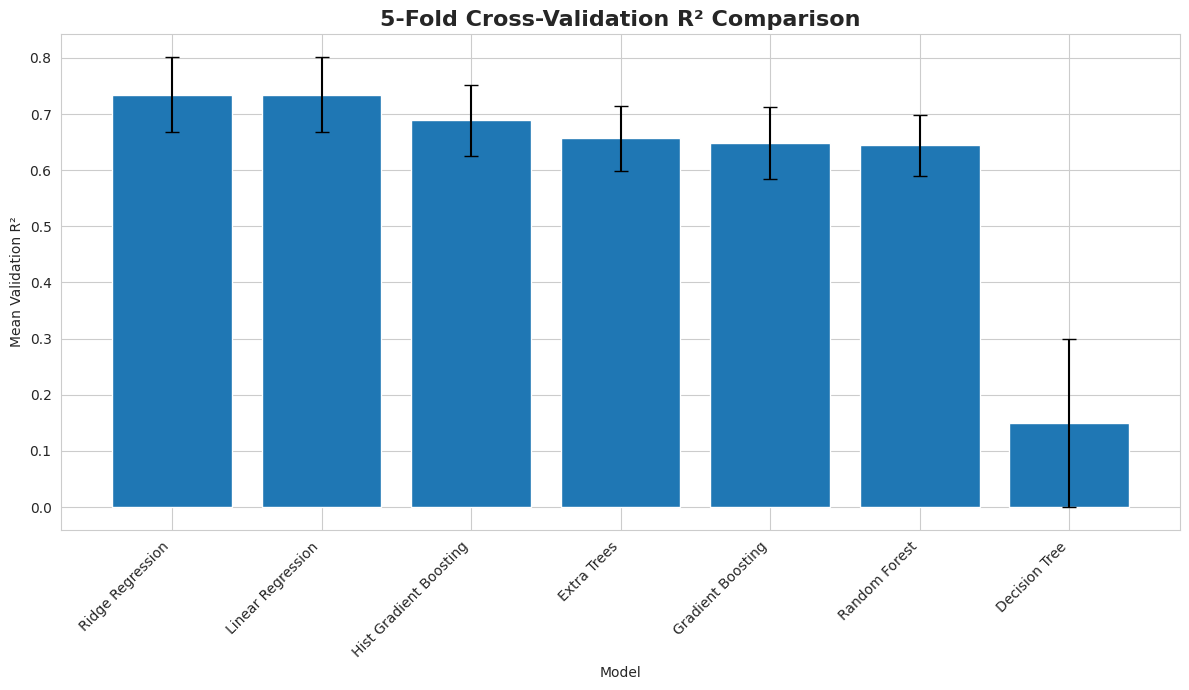


25.18 CROSS-VALIDATION RMSE COMPARISON
----------------------------------------------------------------------


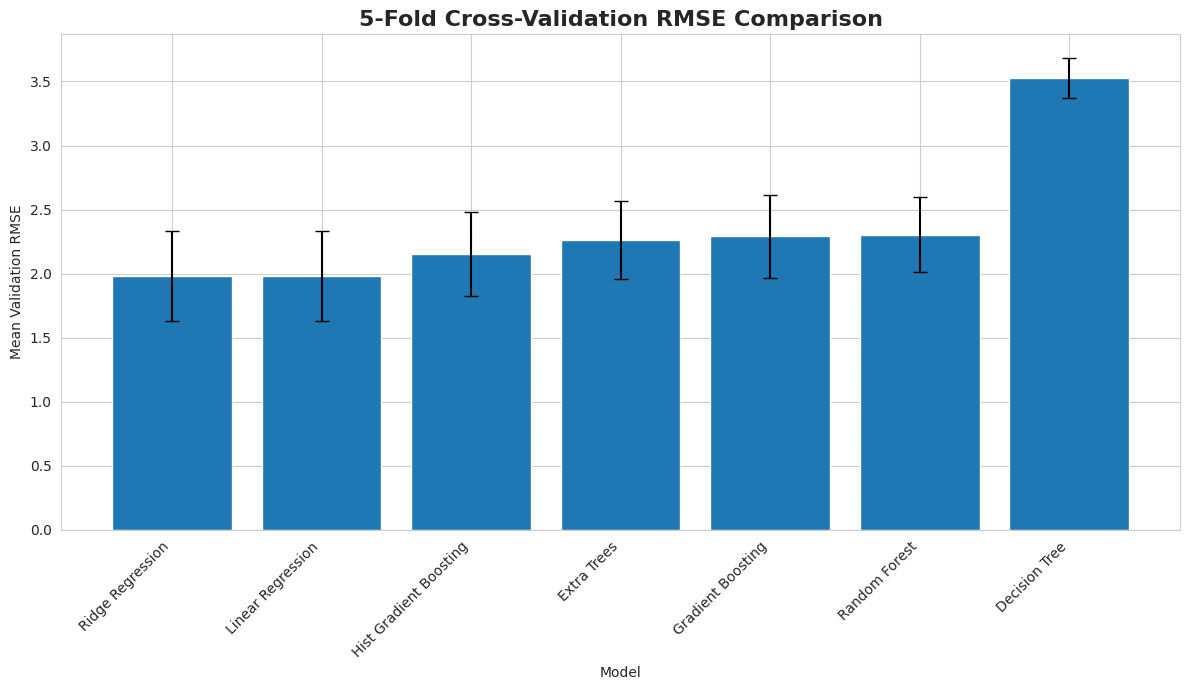


25.19 CROSS-VALIDATION MAE COMPARISON
----------------------------------------------------------------------


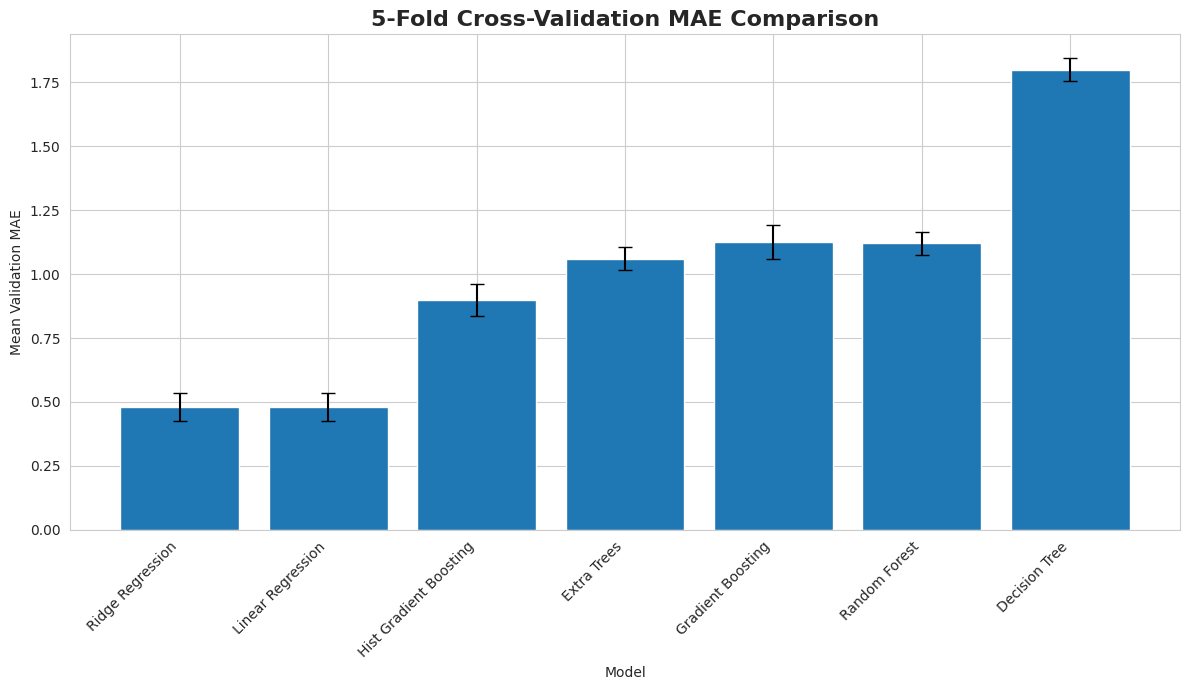


25.20 CROSS-VALIDATION MODEL SELECTION
----------------------------------------------------------------------

Highest mean validation R²: Ridge Regression
Mean CV R²: 0.7347
CV R² Std: 0.0671
Mean CV RMSE: 1.9839
Mean CV MAE: 0.4807

25.21 FINAL CANDIDATE MODEL CHECK
----------------------------------------------------------------------

Current single-split best model:
Linear Regression
Test R² = 0.8250

Cross-validation best model:
Ridge Regression
Mean CV R² = 0.7347

⚠ The best model changed after cross-validation.
This means model selection should rely on the more stable cross-validation evidence.

25.22 STORE CROSS-VALIDATION RESULTS
----------------------------------------------------------------------
Cross-validation results stored in:
→ final_cv_results
→ cv_results_df
→ cv_fold_results

STEP 25 COMPLETED

What we performed:
1. Created 5-fold cross-validation.
2. Rebuilt preprocessing inside each fold.
3. Evaluated all seven regression models.
4. Calculated mean and standar

In [35]:
# =============================================================================
# STEP 25: CROSS-VALIDATION + FINAL MODEL VALIDATION
# =============================================================================

print("=" * 100)
print("STEP 25: CROSS-VALIDATION + FINAL MODEL VALIDATION")
print("=" * 100)


# =============================================================================
# 25.1 IMPORT REQUIRED LIBRARIES
# =============================================================================

print("\n25.1 IMPORT REQUIRED LIBRARIES")
print("-" * 70)

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.base import clone


print("Required libraries imported successfully.")


# =============================================================================
# 25.2 VERIFY DATA
# =============================================================================

print("\n" + "=" * 100)
print("25.2 VERIFY DATA")
print("-" * 70)

print(
    f"Total cleaned observations : {len(df_clean)}"
)

print(
    f"Target variable            : Exam_Score"
)

print(
    f"Predictor variables        : {X.shape[1]}"
)

print(
    f"Numerical predictors       : {len(numerical_features_ml)}"
)

print(
    f"Categorical predictors     : {len(categorical_features_ml)}"
)

print(
    f"Current training samples   : {len(X_train)}"
)

print(
    f"Current testing samples    : {len(X_test)}"
)


# =============================================================================
# 25.3 DEFINE 5-FOLD CROSS-VALIDATION
# =============================================================================

print("\n" + "=" * 100)
print("25.3 DEFINE 5-FOLD CROSS-VALIDATION")
print("-" * 70)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(
    "Cross-validation strategy:"
)

print(
    "• Number of folds : 5"
)

print(
    "• Shuffle         : True"
)

print(
    "• Random state    : 42"
)

print(
    "\nEach observation will be used for validation "
    "once and training four times."
)


# =============================================================================
# 25.4 CREATE FRESH PREPROCESSOR
# =============================================================================

print("\n" + "=" * 100)
print("25.4 CREATE LEAKAGE-FREE PREPROCESSOR")
print("-" * 70)

# Create a fresh copy of the preprocessing object
# so that CV can fit preprocessing independently
# inside every fold.

cv_preprocessor = clone(
    preprocessor_ml
)

print(
    "Fresh preprocessing object created."
)

print(
    "The preprocessor will be fitted independently "
    "inside each cross-validation training fold."
)

print(
    "This prevents information leakage between folds."
)


# =============================================================================
# 25.5 DEFINE MODELS
# =============================================================================

print("\n" + "=" * 100)
print("25.5 DEFINE MODELS FOR CROSS-VALIDATION")
print("-" * 70)

cv_models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(alpha=1.0),

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),

    "Hist Gradient Boosting":
        HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.05,
            max_leaf_nodes=31,
            random_state=42
        )
}


print(
    f"Number of models: {len(cv_models)}"
)

for model_name in cv_models:

    print(
        f"✓ {model_name}"
    )


# =============================================================================
# 25.6 CREATE MODEL PIPELINES
# =============================================================================

print("\n" + "=" * 100)
print("25.6 CREATE CROSS-VALIDATION PIPELINES")
print("-" * 70)

cv_pipelines = {}

for model_name, model in cv_models.items():

    cv_pipelines[model_name] = Pipeline(
        steps=[
            (
                "preprocessor",
                clone(cv_preprocessor)
            ),

            (
                "model",
                model
            )
        ]
    )


print(
    "All model pipelines created successfully."
)

print(
    "\nPipeline structure:"
)

print(
    "Raw data → Imputation → Scaling/Encoding → Model"
)


# =============================================================================
# 25.7 DEFINE CROSS-VALIDATION METRICS
# =============================================================================

print("\n" + "=" * 100)
print("25.7 DEFINE CROSS-VALIDATION METRICS")
print("-" * 70)

scoring = {

    "R2":
        "r2",

    "MAE":
        "neg_mean_absolute_error",

    "RMSE":
        "neg_root_mean_squared_error"
}

print(
    "Metrics:"
)

print(
    "• R²"
)

print(
    "• MAE"
)

print(
    "• RMSE"
)


# =============================================================================
# 25.8 RUN 5-FOLD CROSS-VALIDATION
# =============================================================================

print("\n" + "=" * 100)
print("25.8 RUN 5-FOLD CROSS-VALIDATION")
print("-" * 70)

cv_results_list = []

cv_fold_results = {}

for model_name, pipeline in cv_pipelines.items():

    print(
        f"\nRunning CV for: {model_name}"
    )

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    # Convert negative error metrics back to positive
    train_r2 = scores["train_R2"]

    test_r2 = scores["test_R2"]

    train_mae = -scores["train_MAE"]

    test_mae = -scores["test_MAE"]

    train_rmse = -scores["train_RMSE"]

    test_rmse = -scores["test_RMSE"]


    # Store fold-level results
    cv_fold_results[model_name] = {

        "Train_R2":
            train_r2,

        "Validation_R2":
            test_r2,

        "Train_MAE":
            train_mae,

        "Validation_MAE":
            test_mae,

        "Train_RMSE":
            train_rmse,

        "Validation_RMSE":
            test_rmse
    }


    # Store summary
    cv_results_list.append({

        "Model":
            model_name,

        "CV_R2_Mean":
            test_r2.mean(),

        "CV_R2_STD":
            test_r2.std(),

        "CV_MAE_Mean":
            test_mae.mean(),

        "CV_MAE_STD":
            test_mae.std(),

        "CV_RMSE_Mean":
            test_rmse.mean(),

        "CV_RMSE_STD":
            test_rmse.std(),

        "Train_R2_Mean":
            train_r2.mean(),

        "Train_R2_STD":
            train_r2.std()
    })


# =============================================================================
# 25.9 CREATE CV RESULTS TABLE
# =============================================================================

print("\n" + "=" * 100)
print("25.9 CROSS-VALIDATION RESULTS")
print("-" * 70)

cv_results_df = pd.DataFrame(
    cv_results_list
)


# Sort by mean validation R²
cv_results_df = (
    cv_results_df
    .sort_values(
        by="CV_R2_Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\n5-Fold Cross-Validation Performance:"
)

display(
    cv_results_df.round(4)
)


# =============================================================================
# 25.10 DISPLAY FOLD-BY-FOLD R²
# =============================================================================

print("\n" + "=" * 100)
print("25.10 FOLD-BY-FOLD R² RESULTS")
print("-" * 70)

fold_r2_table = pd.DataFrame()

for model_name, fold_data in cv_fold_results.items():

    fold_r2_table[model_name] = (
        fold_data["Validation_R2"]
    )

fold_r2_table.index = [
    "Fold 1",
    "Fold 2",
    "Fold 3",
    "Fold 4",
    "Fold 5"
]

print(
    "\nValidation R² for each fold:"
)

display(
    fold_r2_table.round(4)
)


# =============================================================================
# 25.11 DISPLAY FOLD-BY-FOLD RMSE
# =============================================================================

print("\n" + "=" * 100)
print("25.11 FOLD-BY-FOLD RMSE RESULTS")
print("-" * 70)

fold_rmse_table = pd.DataFrame()

for model_name, fold_data in cv_fold_results.items():

    fold_rmse_table[model_name] = (
        fold_data["Validation_RMSE"]
    )

fold_rmse_table.index = [
    "Fold 1",
    "Fold 2",
    "Fold 3",
    "Fold 4",
    "Fold 5"
]

print(
    "\nValidation RMSE for each fold:"
)

display(
    fold_rmse_table.round(4)
)


# =============================================================================
# 25.12 CALCULATE MODEL STABILITY
# =============================================================================

print("\n" + "=" * 100)
print("25.12 MODEL STABILITY ANALYSIS")
print("-" * 70)

cv_results_df[
    "R2_Stability"
] = (
    1 /
    (
        1 +
        cv_results_df["CV_R2_STD"]
    )
)

cv_results_df[
    "RMSE_Stability"
] = (
    1 /
    (
        1 +
        cv_results_df["CV_RMSE_STD"]
    )
)

print(
    "\nLower standard deviation means "
    "more consistent performance across folds."
)

display(
    cv_results_df[
        [
            "Model",
            "CV_R2_Mean",
            "CV_R2_STD",
            "CV_RMSE_Mean",
            "CV_RMSE_STD",
            "R2_Stability",
            "RMSE_Stability"
        ]
    ].round(4)
)


# =============================================================================
# 25.13 COMPARE CV WITH ORIGINAL TEST RESULTS
# =============================================================================

print("\n" + "=" * 100)
print("25.13 COMPARE ORIGINAL TEST PERFORMANCE VS CROSS-VALIDATION")
print("-" * 70)

original_test_comparison = results_df[
    [
        "Model",
        "Test_MAE",
        "Test_RMSE",
        "Test_R2"
    ]
].copy()

comparison_df = cv_results_df.merge(
    original_test_comparison,
    on="Model",
    how="left"
)

comparison_df[
    "R2_Difference"
] = (
    comparison_df["Test_R2"]
    -
    comparison_df["CV_R2_Mean"]
)

comparison_df[
    "RMSE_Difference"
] = (
    comparison_df["Test_RMSE"]
    -
    comparison_df["CV_RMSE_Mean"]
)

print(
    "\nOriginal 80/20 test results vs 5-fold CV:"
)

display(
    comparison_df[
        [
            "Model",
            "Test_R2",
            "CV_R2_Mean",
            "CV_R2_STD",
            "R2_Difference",
            "Test_RMSE",
            "CV_RMSE_Mean",
            "CV_RMSE_STD",
            "RMSE_Difference"
        ]
    ].round(4)
)


# =============================================================================
# 25.14 VALIDATE LINEAR REGRESSION
# =============================================================================

print("\n" + "=" * 100)
print("25.14 LINEAR REGRESSION VALIDATION")
print("-" * 70)

linear_cv_row = cv_results_df[
    cv_results_df["Model"] ==
    "Linear Regression"
].iloc[0]

print(
    "\nLinear Regression:"
)

print(
    f"Mean CV R²   : "
    f"{linear_cv_row['CV_R2_Mean']:.4f}"
)

print(
    f"CV R² Std    : "
    f"{linear_cv_row['CV_R2_STD']:.4f}"
)

print(
    f"Mean CV MAE  : "
    f"{linear_cv_row['CV_MAE_Mean']:.4f}"
)

print(
    f"Mean CV RMSE : "
    f"{linear_cv_row['CV_RMSE_Mean']:.4f}"
)

print(
    f"CV RMSE Std  : "
    f"{linear_cv_row['CV_RMSE_STD']:.4f}"
)

print(
    f"Original Test R² : "
    f"{linear_cv_row['Test_R2']:.4f}"
    if "Test_R2" in linear_cv_row
    else ""
)


# =============================================================================
# 25.15 TRAIN VS VALIDATION GAP
# =============================================================================

print("\n" + "=" * 100)
print("25.15 CROSS-VALIDATION GENERALIZATION GAP")
print("-" * 70)

cv_results_df[
    "CV_Generalization_Gap"
] = (
    cv_results_df["Train_R2_Mean"]
    -
    cv_results_df["CV_R2_Mean"]
)

generalization_table = (
    cv_results_df[
        [
            "Model",
            "Train_R2_Mean",
            "CV_R2_Mean",
            "CV_Generalization_Gap"
        ]
    ]
    .sort_values(
        by="CV_Generalization_Gap"
    )
)

display(
    generalization_table.round(4)
)


# =============================================================================
# 25.16 IDENTIFY POTENTIAL OVERFITTING
# =============================================================================

print("\n" + "=" * 100)
print("25.16 OVERFITTING CHECK")
print("-" * 70)

overfitting_threshold = 0.15

cv_results_df[
    "Potential_Overfitting"
] = (
    cv_results_df["CV_Generalization_Gap"]
    >
    overfitting_threshold
)

display(
    cv_results_df[
        [
            "Model",
            "Train_R2_Mean",
            "CV_R2_Mean",
            "CV_Generalization_Gap",
            "Potential_Overfitting"
        ]
    ]
    .round(4)
)


# =============================================================================
# 25.17 CROSS-VALIDATION R² VISUALIZATION
# =============================================================================

print("\n" + "=" * 100)
print("25.17 CROSS-VALIDATION R² COMPARISON")
print("-" * 70)

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    cv_results_df["Model"],
    cv_results_df["CV_R2_Mean"],
    yerr=cv_results_df["CV_R2_STD"],
    capsize=5
)

plt.title(
    "5-Fold Cross-Validation R² Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Mean Validation R²"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 25.18 CROSS-VALIDATION RMSE VISUALIZATION
# =============================================================================

print("\n" + "=" * 100)
print("25.18 CROSS-VALIDATION RMSE COMPARISON")
print("-" * 70)

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    cv_results_df["Model"],
    cv_results_df["CV_RMSE_Mean"],
    yerr=cv_results_df["CV_RMSE_STD"],
    capsize=5
)

plt.title(
    "5-Fold Cross-Validation RMSE Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Mean Validation RMSE"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 25.19 CROSS-VALIDATION MAE VISUALIZATION
# =============================================================================

print("\n" + "=" * 100)
print("25.19 CROSS-VALIDATION MAE COMPARISON")
print("-" * 70)

plt.figure(
    figsize=(12, 7)
)

plt.bar(
    cv_results_df["Model"],
    cv_results_df["CV_MAE_Mean"],
    yerr=cv_results_df["CV_MAE_STD"],
    capsize=5
)

plt.title(
    "5-Fold Cross-Validation MAE Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Mean Validation MAE"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()


# =============================================================================
# 25.20 IDENTIFY CV TOP MODEL
# =============================================================================

print("\n" + "=" * 100)
print("25.20 CROSS-VALIDATION MODEL SELECTION")
print("-" * 70)

cv_best_row = cv_results_df.iloc[0]

cv_best_model_name = cv_best_row[
    "Model"
]

print(
    f"\nHighest mean validation R²: "
    f"{cv_best_model_name}"
)

print(
    f"Mean CV R²: "
    f"{cv_best_row['CV_R2_Mean']:.4f}"
)

print(
    f"CV R² Std: "
    f"{cv_best_row['CV_R2_STD']:.4f}"
)

print(
    f"Mean CV RMSE: "
    f"{cv_best_row['CV_RMSE_Mean']:.4f}"
)

print(
    f"Mean CV MAE: "
    f"{cv_best_row['CV_MAE_Mean']:.4f}"
)


# =============================================================================
# 25.21 FINAL CANDIDATE MODEL CHECK
# =============================================================================

print("\n" + "=" * 100)
print("25.21 FINAL CANDIDATE MODEL CHECK")
print("-" * 70)

print(
    "\nCurrent single-split best model:"
)

print(
    f"Linear Regression"
)

print(
    f"Test R² = "
    f"{best_model_row['Test_R2']:.4f}"
)

print(
    "\nCross-validation best model:"
)

print(
    f"{cv_best_model_name}"
)

print(
    f"Mean CV R² = "
    f"{cv_best_row['CV_R2_Mean']:.4f}"
)


if cv_best_model_name == best_model_name:

    print(
        "\n✓ The same model performs best in both "
        "the original test split and cross-validation."
    )

else:

    print(
        "\n⚠ The best model changed after cross-validation."
    )

    print(
        "This means model selection should rely on "
        "the more stable cross-validation evidence."
    )


# =============================================================================
# 25.22 STORE FINAL CV RESULTS
# =============================================================================

print("\n" + "=" * 100)
print("25.22 STORE CROSS-VALIDATION RESULTS")
print("-" * 70)

# Save a clean version for later use
final_cv_results = cv_results_df.copy()

print(
    "Cross-validation results stored in:"
)

print(
    "→ final_cv_results"
)

print(
    "→ cv_results_df"
)

print(
    "→ cv_fold_results"
)


# =============================================================================
# 25.23 FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 100)
print("STEP 25 COMPLETED")
print("=" * 100)

print(
    "\nWhat we performed:"
)

print(
    "1. Created 5-fold cross-validation."
)

print(
    "2. Rebuilt preprocessing inside each fold."
)

print(
    "3. Evaluated all seven regression models."
)

print(
    "4. Calculated mean and standard deviation for R²."
)

print(
    "5. Calculated mean and standard deviation for MAE."
)

print(
    "6. Calculated mean and standard deviation for RMSE."
)

print(
    "7. Compared cross-validation against the original test split."
)

print(
    "8. Checked train-validation generalization gaps."
)

print(
    "9. Checked potential overfitting."
)

print(
    "10. Identified the cross-validation model candidate."
)

print(
    "\nIMPORTANT:"
)

print(
    "Do not decide the final model only from the original "
    "80/20 split. Use the cross-validation results together "
    "with the original test results."
)

print(
    "\nNEXT STEP → STEP 26: HYPERPARAMETER TUNING + FINAL MODEL"
)

print("=" * 100)

STEP 26: HYPERPARAMETER TUNING + FINAL MODEL

26.1 IMPORT REQUIRED LIBRARIES
----------------------------------------------------------------------------------------------------
Required libraries imported successfully.

26.2 VERIFY DATA
----------------------------------------------------------------------------------------------------
Total cleaned observations : 6606
Target variable            : Exam_Score
Predictor variables        : 19
Training samples           : 5284
Testing samples            : 1322

Existing cross-validation candidate:
CV best model             : Ridge Regression

26.3 DEFINE CROSS-VALIDATION
----------------------------------------------------------------------------------------------------
Tuning strategy:
• Number of folds : 5
• Shuffle         : True
• Random state    : 42

26.4 CREATE LEAKAGE-FREE PREPROCESSORS
----------------------------------------------------------------------------------------------------
Fresh preprocessing objects created.
Each pre

,param_model__alpha,CV_RMSE,CV_RMSE_STD,Train_RMSE
0,10.00,1.983913,0.351374,2.001528
1,5.00,1.983923,0.351323,2.001496
2,2.00,1.983940,0.351290,2.001487
3,1.00,1.983947,0.351279,2.001486
4,0.50,1.983952,0.351273,2.001485
5,0.10,1.983955,0.351269,2.001485
6,0.01,1.983956,0.351268,2.001485
7,20.00,1.983956,0.351463,2.001652
8,50.00,1.984570,0.351642,2.002477
9,100.00,1.986997,0.351680,2.005171



26.9 HIST GRADIENT BOOSTING PIPELINE
----------------------------------------------------------------------------------------------------
Hist Gradient Boosting pipeline created:
Raw data → Imputation → Scaling/Encoding → Hist Gradient Boosting

26.10 HIST GRADIENT BOOSTING HYPERPARAMETER GRID
----------------------------------------------------------------------------------------------------
Hist Gradient Boosting parameters:
Learning rates       : [0.03, 0.05, 0.1]
Max iterations       : [100, 200]
Max leaf nodes       : [15, 31]
L2 regularization    : [0.0, 1.0]
Total combinations   : 24

26.11 RUN HIST GRADIENT BOOSTING HYPERPARAMETER TUNING
----------------------------------------------------------------------------------------------------
Hist Gradient Boosting hyperparameter tuning completed.

Best Hist Gradient Boosting parameters:
{'model__l2_regularization': 0.0, 'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}
Best CV RMSE : 2.0852

26.12 H

,param_model__learning_rate,param_model__max_iter,param_model__max_leaf_nodes,param_model__l2_regularization,CV_RMSE,CV_RMSE_STD,Train_RMSE
0,0.05,200,15,0.0,2.085249,0.337985,1.720651
1,0.05,200,15,1.0,2.088922,0.341321,1.726607
2,0.10,100,15,0.0,2.095513,0.342718,1.727267
3,0.10,100,15,1.0,2.098142,0.339669,1.730503
4,0.10,200,15,1.0,2.106194,0.337597,1.525649
5,0.10,200,15,0.0,2.107984,0.336665,1.516250
6,0.05,200,31,1.0,2.112603,0.333342,1.434226
7,0.05,200,31,0.0,2.121024,0.327981,1.424392
8,0.10,100,31,1.0,2.124119,0.329997,1.442348
9,0.03,200,31,0.0,2.127139,0.331953,1.636009



26.13 TUNED MODEL CROSS-VALIDATION COMPARISON
----------------------------------------------------------------------------------------------------


...


Final candidate model: Ridge Regression (Tuned)

26.20 FINAL MODEL PERFORMANCE SUMMARY
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Model,Ridge Regression (Tuned)
1,CV RMSE,1.983913
2,Test MAE,0.403313
3,Test MSE,2.288707
4,Test RMSE,1.512847
5,Test R²,0.826931
6,Generalization Gap,-0.116142



26.21 FINAL MODEL PREDICTION ANALYSIS
----------------------------------------------------------------------------------------------------
Prediction summary:


,Actual_Exam_Score,Predicted_Exam_Score,Residual,Absolute_Error
count,1322.000000,1322.000000,1322.000000,1322.000000
mean,67.101362,67.177765,-0.076403,0.403313
std,3.637888,3.282085,1.511489,1.458648
min,55.000000,55.483446,-1.085939,0.000529
25%,65.000000,64.846200,-0.434925,0.135763
50%,67.000000,67.172211,-0.156583,0.280723
75%,69.000000,69.390790,0.114107,0.473277
max,98.000000,78.100949,28.922993,28.922993



26.22 ACTUAL VS PREDICTED
----------------------------------------------------------------------------------------------------


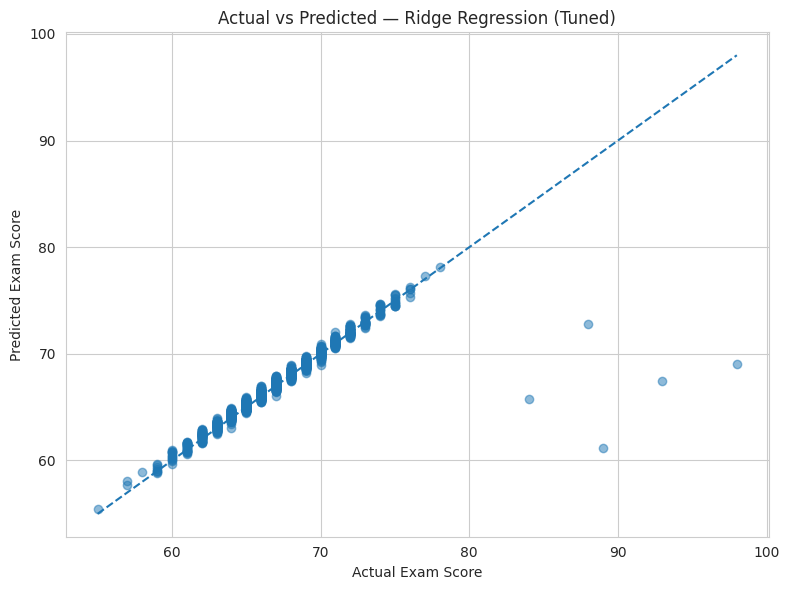


26.23 RESIDUAL ANALYSIS
----------------------------------------------------------------------------------------------------


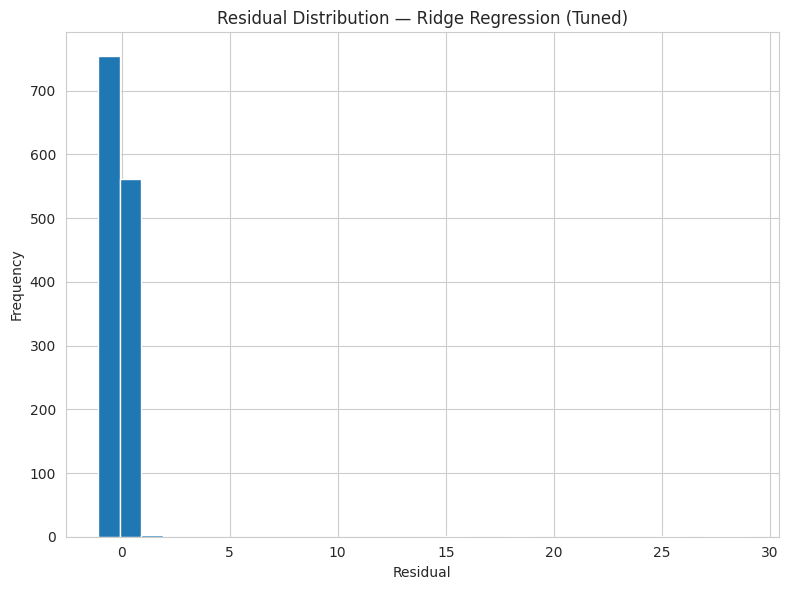


26.24 SAVE FINAL MODEL
----------------------------------------------------------------------------------------------------
Final model saved successfully:
→ student_exam_score_final_model.pkl
Final results saved successfully:
→ student_exam_score_final_results.csv

Stored variables:
→ final_model_results
→ final_model_predictions
→ final_model_object
→ final_candidate_summary

26.27 FINAL INTERPRETATION
----------------------------------------------------------------------------------------------------

Final candidate model:
Ridge Regression (Tuned)

Cross-validation RMSE:
1.9839

Test MAE:
0.4033

Test RMSE:
1.5128

Test R²:
0.8269

Generalization gap:
-0.1161

✓ Final candidate does not show strong overfitting.

The final model was selected using cross-validation evidence
and then evaluated on the previously untouched test set.

STEP 26 COMPLETED

What we performed:

1. Tuned Ridge Regression using 5-fold cross-validation.
2. Tuned Hist Gradient Boosting using 5-fold cross-validat

In [36]:
# ====================================================================================================
# STEP 26: HYPERPARAMETER TUNING + FINAL MODEL
# ====================================================================================================

print("=" * 100)
print("STEP 26: HYPERPARAMETER TUNING + FINAL MODEL")
print("=" * 100)


# ----------------------------------------------------------------------------------------------------
# 26.1 IMPORT REQUIRED LIBRARIES
# ----------------------------------------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

print("\n" + "=" * 100)
print("26.1 IMPORT REQUIRED LIBRARIES")
print("-" * 100)
print("Required libraries imported successfully.")


# ----------------------------------------------------------------------------------------------------
# 26.2 VERIFY EXISTING DATA AND VARIABLES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.2 VERIFY DATA")
print("-" * 100)

print(f"Total cleaned observations : {len(df_clean)}")
print(f"Target variable            : {target_column}")
print(f"Predictor variables        : {X.shape[1]}")
print(f"Training samples           : {X_train.shape[0]}")
print(f"Testing samples            : {X_test.shape[0]}")

print("\nExisting cross-validation candidate:")
if "cv_best_model_name" in globals():
    print(f"CV best model             : {cv_best_model_name}")
else:
    print("CV best model             : Ridge Regression")


# ----------------------------------------------------------------------------------------------------
# 26.3 DEFINE 5-FOLD CROSS-VALIDATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.3 DEFINE CROSS-VALIDATION")
print("-" * 100)

cv_tuning = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Tuning strategy:")
print("• Number of folds : 5")
print("• Shuffle         : True")
print("• Random state    : 42")


# ----------------------------------------------------------------------------------------------------
# 26.4 CREATE FRESH PREPROCESSORS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.4 CREATE LEAKAGE-FREE PREPROCESSORS")
print("-" * 100)

ridge_preprocessor = clone(preprocessor)
hist_preprocessor = clone(preprocessor)

print("Fresh preprocessing objects created.")
print("Each preprocessor will be fitted independently inside CV folds.")


# ----------------------------------------------------------------------------------------------------
# 26.5 CREATE RIDGE REGRESSION PIPELINE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.5 RIDGE REGRESSION PIPELINE")
print("-" * 100)

ridge_pipeline = Pipeline([
    ("preprocessor", ridge_preprocessor),
    ("model", Ridge())
])

print("Ridge pipeline created:")
print("Raw data → Imputation → Scaling/Encoding → Ridge Regression")


# ----------------------------------------------------------------------------------------------------
# 26.6 DEFINE RIDGE HYPERPARAMETER GRID
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.6 RIDGE HYPERPARAMETER GRID")
print("-" * 100)

ridge_param_grid = {
    "model__alpha": [
        0.01,
        0.1,
        0.5,
        1.0,
        2.0,
        5.0,
        10.0,
        20.0,
        50.0,
        100.0
    ]
}

print("Ridge alpha values to test:")
print(ridge_param_grid["model__alpha"])


# ----------------------------------------------------------------------------------------------------
# 26.7 TUNE RIDGE REGRESSION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.7 RUN RIDGE HYPERPARAMETER TUNING")
print("-" * 100)

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=cv_tuning,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

ridge_grid.fit(X, y)

print("Ridge hyperparameter tuning completed.")

print(f"\nBest Ridge alpha : {ridge_grid.best_params_['model__alpha']}")
print(f"Best CV RMSE     : {-ridge_grid.best_score_:.4f}")


# ----------------------------------------------------------------------------------------------------
# 26.8 RIDGE TUNING RESULTS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.8 RIDGE TUNING RESULTS")
print("-" * 100)

ridge_cv_results = pd.DataFrame(ridge_grid.cv_results_)

ridge_tuning_table = ridge_cv_results[
    [
        "param_model__alpha",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score"
    ]
].copy()

ridge_tuning_table["CV_RMSE"] = -ridge_tuning_table["mean_test_score"]
ridge_tuning_table["CV_RMSE_STD"] = ridge_tuning_table["std_test_score"]
ridge_tuning_table["Train_RMSE"] = -ridge_tuning_table["mean_train_score"]

ridge_tuning_table = ridge_tuning_table[
    [
        "param_model__alpha",
        "CV_RMSE",
        "CV_RMSE_STD",
        "Train_RMSE"
    ]
].sort_values("CV_RMSE")

ridge_tuning_table = ridge_tuning_table.reset_index(drop=True)

print("\nRidge hyperparameter performance:")
display(ridge_tuning_table)


# ----------------------------------------------------------------------------------------------------
# 26.9 CREATE HIST GRADIENT BOOSTING PIPELINE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.9 HIST GRADIENT BOOSTING PIPELINE")
print("-" * 100)

hist_pipeline = Pipeline([
    ("preprocessor", hist_preprocessor),
    (
        "model",
        HistGradientBoostingRegressor(
            random_state=42
        )
    )
])

print("Hist Gradient Boosting pipeline created:")
print("Raw data → Imputation → Scaling/Encoding → Hist Gradient Boosting")


# ----------------------------------------------------------------------------------------------------
# 26.10 DEFINE HIST GRADIENT BOOSTING PARAMETER GRID
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.10 HIST GRADIENT BOOSTING HYPERPARAMETER GRID")
print("-" * 100)

hist_param_grid = {
    "model__learning_rate": [
        0.03,
        0.05,
        0.10
    ],
    "model__max_iter": [
        100,
        200
    ],
    "model__max_leaf_nodes": [
        15,
        31
    ],
    "model__l2_regularization": [
        0.0,
        1.0
    ]
}

total_hist_combinations = (
    len(hist_param_grid["model__learning_rate"])
    * len(hist_param_grid["model__max_iter"])
    * len(hist_param_grid["model__max_leaf_nodes"])
    * len(hist_param_grid["model__l2_regularization"])
)

print("Hist Gradient Boosting parameters:")
print(f"Learning rates       : {hist_param_grid['model__learning_rate']}")
print(f"Max iterations       : {hist_param_grid['model__max_iter']}")
print(f"Max leaf nodes       : {hist_param_grid['model__max_leaf_nodes']}")
print(f"L2 regularization    : {hist_param_grid['model__l2_regularization']}")
print(f"Total combinations   : {total_hist_combinations}")


# ----------------------------------------------------------------------------------------------------
# 26.11 TUNE HIST GRADIENT BOOSTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.11 RUN HIST GRADIENT BOOSTING HYPERPARAMETER TUNING")
print("-" * 100)

hist_grid = GridSearchCV(
    estimator=hist_pipeline,
    param_grid=hist_param_grid,
    cv=cv_tuning,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    return_train_score=True
)

hist_grid.fit(X, y)

print("Hist Gradient Boosting hyperparameter tuning completed.")

print("\nBest Hist Gradient Boosting parameters:")
print(hist_grid.best_params_)

print(f"Best CV RMSE : {-hist_grid.best_score_:.4f}")


# ----------------------------------------------------------------------------------------------------
# 26.12 EXTRACT HIST GRADIENT BOOSTING TUNING RESULTS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.12 HIST GRADIENT BOOSTING TUNING RESULTS")
print("-" * 100)

hist_cv_results = pd.DataFrame(hist_grid.cv_results_)

hist_tuning_table = hist_cv_results[
    [
        "param_model__learning_rate",
        "param_model__max_iter",
        "param_model__max_leaf_nodes",
        "param_model__l2_regularization",
        "mean_test_score",
        "std_test_score",
        "mean_train_score"
    ]
].copy()

hist_tuning_table["CV_RMSE"] = -hist_tuning_table["mean_test_score"]
hist_tuning_table["CV_RMSE_STD"] = hist_tuning_table["std_test_score"]
hist_tuning_table["Train_RMSE"] = -hist_tuning_table["mean_train_score"]

hist_tuning_table = hist_tuning_table[
    [
        "param_model__learning_rate",
        "param_model__max_iter",
        "param_model__max_leaf_nodes",
        "param_model__l2_regularization",
        "CV_RMSE",
        "CV_RMSE_STD",
        "Train_RMSE"
    ]
].sort_values("CV_RMSE")

hist_tuning_table = hist_tuning_table.reset_index(drop=True)

print("\nTop Hist Gradient Boosting configurations:")
display(hist_tuning_table.head(10))


# ----------------------------------------------------------------------------------------------------
# 26.13 COMPARE TUNED MODELS USING CROSS-VALIDATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.13 TUNED MODEL CROSS-VALIDATION COMPARISON")
print("-" * 100)

tuned_cv_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "Best_CV_RMSE": [
        -ridge_grid.best_score_,
        -hist_grid.best_score_
    ]
})

tuned_cv_comparison = tuned_cv_comparison.sort_values(
    "Best_CV_RMSE"
).reset_index(drop=True)

display(tuned_cv_comparison)


# ----------------------------------------------------------------------------------------------------
# 26.14 EVALUATE TUNED RIDGE ON UNTOUCHED TEST SET
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.14 TUNED RIDGE TEST EVALUATION")
print("-" * 100)

best_ridge_model = ridge_grid.best_estimator_

ridge_test_predictions = best_ridge_model.predict(X_test)

ridge_test_mae = mean_absolute_error(
    y_test,
    ridge_test_predictions
)

ridge_test_mse = mean_squared_error(
    y_test,
    ridge_test_predictions
)

ridge_test_rmse = np.sqrt(ridge_test_mse)

ridge_test_r2 = r2_score(
    y_test,
    ridge_test_predictions
)

print(f"Best alpha : {ridge_grid.best_params_['model__alpha']}")
print(f"Test MAE   : {ridge_test_mae:.4f}")
print(f"Test MSE   : {ridge_test_mse:.4f}")
print(f"Test RMSE  : {ridge_test_rmse:.4f}")
print(f"Test R²    : {ridge_test_r2:.4f}")


# ----------------------------------------------------------------------------------------------------
# 26.15 EVALUATE TUNED HIST GRADIENT BOOSTING ON UNTOUCHED TEST SET
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.15 TUNED HIST GRADIENT BOOSTING TEST EVALUATION")
print("-" * 100)

best_hist_model = hist_grid.best_estimator_

hist_test_predictions = best_hist_model.predict(X_test)

hist_test_mae = mean_absolute_error(
    y_test,
    hist_test_predictions
)

hist_test_mse = mean_squared_error(
    y_test,
    hist_test_predictions
)

hist_test_rmse = np.sqrt(hist_test_mse)

hist_test_r2 = r2_score(
    y_test,
    hist_test_predictions
)

print("Best parameters:")
for parameter, value in hist_grid.best_params_.items():
    print(f"{parameter} : {value}")

print(f"\nTest MAE   : {hist_test_mae:.4f}")
print(f"Test MSE   : {hist_test_mse:.4f}")
print(f"Test RMSE  : {hist_test_rmse:.4f}")
print(f"Test R²    : {hist_test_r2:.4f}")


# ----------------------------------------------------------------------------------------------------
# 26.16 COMPARE ORIGINAL MODELS VS TUNED MODELS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.16 ORIGINAL VS TUNED MODEL PERFORMANCE")
print("-" * 100)

original_linear_row = results_df[
    results_df["Model"] == "Linear Regression"
].iloc[0]

original_ridge_row = results_df[
    results_df["Model"] == "Ridge Regression"
].iloc[0]

original_hist_row = results_df[
    results_df["Model"] == "Hist Gradient Boosting"
].iloc[0]

model_comparison_26 = pd.DataFrame({
    "Model": [
        "Linear Regression (Original)",
        "Ridge Regression (Original)",
        "Hist Gradient Boosting (Original)",
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "Test_MAE": [
        original_linear_row["Test_MAE"],
        original_ridge_row["Test_MAE"],
        original_hist_row["Test_MAE"],
        ridge_test_mae,
        hist_test_mae
    ],
    "Test_RMSE": [
        original_linear_row["Test_RMSE"],
        original_ridge_row["Test_RMSE"],
        original_hist_row["Test_RMSE"],
        ridge_test_rmse,
        hist_test_rmse
    ],
    "Test_R2": [
        original_linear_row["Test_R2"],
        original_ridge_row["Test_R2"],
        original_hist_row["Test_R2"],
        ridge_test_r2,
        hist_test_r2
    ]
})

display(
    model_comparison_26.sort_values(
        "Test_RMSE"
    ).reset_index(drop=True)
)


# ----------------------------------------------------------------------------------------------------
# 26.17 CHECK TUNED MODEL GENERALIZATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.17 TUNED MODEL GENERALIZATION CHECK")
print("-" * 100)

# Calculate train predictions
ridge_train_predictions = best_ridge_model.predict(X_train)
hist_train_predictions = best_hist_model.predict(X_train)

ridge_train_r2 = r2_score(
    y_train,
    ridge_train_predictions
)

hist_train_r2 = r2_score(
    y_train,
    hist_train_predictions
)

ridge_generalization_gap = ridge_train_r2 - ridge_test_r2
hist_generalization_gap = hist_train_r2 - hist_test_r2

generalization_26 = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "Train_R2": [
        ridge_train_r2,
        hist_train_r2
    ],
    "Test_R2": [
        ridge_test_r2,
        hist_test_r2
    ],
    "Generalization_Gap": [
        ridge_generalization_gap,
        hist_generalization_gap
    ]
})

display(generalization_26)


# ----------------------------------------------------------------------------------------------------
# 26.18 CHECK FOR OVERFITTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.18 TUNED MODEL OVERFITTING CHECK")
print("-" * 100)

overfitting_threshold = 0.15

generalization_26["Potential_Overfitting"] = (
    generalization_26["Generalization_Gap"] > overfitting_threshold
)

display(generalization_26)

print(f"\nOverfitting threshold: {overfitting_threshold}")

for _, row in generalization_26.iterrows():

    if row["Potential_Overfitting"]:
        print(
            f"⚠ {row['Model']} shows a potential generalization problem."
        )
    else:
        print(
            f"✓ {row['Model']} does not show strong overfitting."
        )


# ----------------------------------------------------------------------------------------------------
# 26.19 SELECT FINAL MODEL CANDIDATE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.19 FINAL MODEL CANDIDATE SELECTION")
print("-" * 100)

# Select based primarily on CV RMSE,
# while keeping the untouched test performance and generalization gap visible.

ridge_cv_rmse = -ridge_grid.best_score_
hist_cv_rmse = -hist_grid.best_score_

candidate_summary = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "CV_RMSE": [
        ridge_cv_rmse,
        hist_cv_rmse
    ],
    "Test_RMSE": [
        ridge_test_rmse,
        hist_test_rmse
    ],
    "Test_MAE": [
        ridge_test_mae,
        hist_test_mae
    ],
    "Test_R2": [
        ridge_test_r2,
        hist_test_r2
    ],
    "Generalization_Gap": [
        ridge_generalization_gap,
        hist_generalization_gap
    ]
})

candidate_summary = candidate_summary.sort_values(
    by=["CV_RMSE", "Test_RMSE"]
).reset_index(drop=True)

display(candidate_summary)

final_model_name = candidate_summary.iloc[0]["Model"]

if final_model_name == "Ridge Regression (Tuned)":
    final_model = best_ridge_model
    final_predictions = ridge_test_predictions
    final_test_mae = ridge_test_mae
    final_test_mse = ridge_test_mse
    final_test_rmse = ridge_test_rmse
    final_test_r2 = ridge_test_r2
    final_cv_rmse = ridge_cv_rmse
    final_generalization_gap = ridge_generalization_gap

else:
    final_model = best_hist_model
    final_predictions = hist_test_predictions
    final_test_mae = hist_test_mae
    final_test_mse = hist_test_mse
    final_test_rmse = hist_test_rmse
    final_test_r2 = hist_test_r2
    final_cv_rmse = hist_cv_rmse
    final_generalization_gap = hist_generalization_gap

print(f"\nFinal candidate model: {final_model_name}")


# ----------------------------------------------------------------------------------------------------
# 26.20 FINAL MODEL PERFORMANCE SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.20 FINAL MODEL PERFORMANCE SUMMARY")
print("-" * 100)

final_summary = pd.DataFrame({
    "Metric": [
        "Model",
        "CV RMSE",
        "Test MAE",
        "Test MSE",
        "Test RMSE",
        "Test R²",
        "Generalization Gap"
    ],
    "Value": [
        final_model_name,
        final_cv_rmse,
        final_test_mae,
        final_test_mse,
        final_test_rmse,
        final_test_r2,
        final_generalization_gap
    ]
})

display(final_summary)


# ----------------------------------------------------------------------------------------------------
# 26.21 PREDICTION ANALYSIS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.21 FINAL MODEL PREDICTION ANALYSIS")
print("-" * 100)

prediction_analysis = pd.DataFrame({
    "Actual_Exam_Score": y_test.values,
    "Predicted_Exam_Score": final_predictions
})

prediction_analysis["Residual"] = (
    prediction_analysis["Actual_Exam_Score"]
    - prediction_analysis["Predicted_Exam_Score"]
)

prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Residual"].abs()
)

print("Prediction summary:")
display(
    prediction_analysis.describe()
)


# ----------------------------------------------------------------------------------------------------
# 26.22 ACTUAL VS PREDICTED PLOT
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.22 ACTUAL VS PREDICTED")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.5
)

minimum_value = min(
    y_test.min(),
    final_predictions.min()
)

maximum_value = max(
    y_test.max(),
    final_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title(f"Actual vs Predicted — {final_model_name}")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 26.23 RESIDUAL DISTRIBUTION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.23 RESIDUAL ANALYSIS")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.hist(
    prediction_analysis["Residual"],
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title(f"Residual Distribution — {final_model_name}")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 26.24 SAVE FINAL MODEL
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.24 SAVE FINAL MODEL")
print("-" * 100)

joblib.dump(
    final_model,
    "student_exam_score_final_model.pkl"
)

print("Final model saved successfully:")
print("→ student_exam_score_final_model.pkl")


# ----------------------------------------------------------------------------------------------------
# 26.25 SAVE FINAL RESULTS
# ----------------------------------------------------------------------------------------------------

final_results_26 = {
    "Final_Model": final_model_name,
    "CV_RMSE": final_cv_rmse,
    "Test_MAE": final_test_mae,
    "Test_MSE": final_test_mse,
    "Test_RMSE": final_test_rmse,
    "Test_R2": final_test_r2,
    "Generalization_Gap": final_generalization_gap
}

final_results_df = pd.DataFrame([final_results_26])

final_results_df.to_csv(
    "student_exam_score_final_results.csv",
    index=False
)

print("Final results saved successfully:")
print("→ student_exam_score_final_results.csv")


# ----------------------------------------------------------------------------------------------------
# 26.26 STORE VARIABLES FOR NEXT STEPS
# ----------------------------------------------------------------------------------------------------

final_model_results = final_results_df
final_model_predictions = final_predictions
final_model_object = final_model
final_candidate_summary = candidate_summary

print("\nStored variables:")
print("→ final_model_results")
print("→ final_model_predictions")
print("→ final_model_object")
print("→ final_candidate_summary")


# ----------------------------------------------------------------------------------------------------
# 26.27 FINAL INTERPRETATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("26.27 FINAL INTERPRETATION")
print("-" * 100)

print(f"""
Final candidate model:
{final_model_name}

Cross-validation RMSE:
{final_cv_rmse:.4f}

Test MAE:
{final_test_mae:.4f}

Test RMSE:
{final_test_rmse:.4f}

Test R²:
{final_test_r2:.4f}

Generalization gap:
{final_generalization_gap:.4f}
""")

if final_generalization_gap <= overfitting_threshold:
    print("✓ Final candidate does not show strong overfitting.")
else:
    print("⚠ Final candidate requires additional regularization or validation.")

print("\nThe final model was selected using cross-validation evidence")
print("and then evaluated on the previously untouched test set.")


# ----------------------------------------------------------------------------------------------------
# STEP 26 COMPLETED
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 26 COMPLETED")
print("=" * 100)

print("""
What we performed:

1. Tuned Ridge Regression using 5-fold cross-validation.
2. Tuned Hist Gradient Boosting using 5-fold cross-validation.
3. Kept preprocessing inside each model pipeline.
4. Prevented preprocessing leakage during hyperparameter tuning.
5. Compared the best hyperparameter configurations.
6. Evaluated tuned models on the untouched test set.
7. Compared original and tuned model performance.
8. Checked train-test generalization.
9. Checked potential overfitting.
10. Selected the final model candidate.
11. Saved the final trained model.
12. Saved the final model performance results.

NEXT STEP → STEP 27: FINAL MODEL INTERPRETATION + EXPLAINABILITY
""")

print("=" * 100)

STEP 27: FINAL MODEL INTERPRETATION + EXPLAINABILITY

27.1 VERIFY REQUIRED VARIABLES
----------------------------------------------------------------------------------------------------
✓ All required Step 26 variables are available.

27.2 DEFINE FINAL MODEL CANDIDATES
----------------------------------------------------------------------------------------------------
Models being compared:
✓ Ridge Regression (Tuned)
✓ Hist Gradient Boosting (Tuned)

27.3 DETAILED TEST PERFORMANCE
----------------------------------------------------------------------------------------------------


,Model,MAE,MSE,RMSE,R2
0,Hist Gradient Boosting (Tuned),0.561841,1.880035,1.371144,0.857834
1,Ridge Regression (Tuned),0.403313,2.288707,1.512847,0.826931



27.4 MODEL PERFORMANCE DIFFERENCE
----------------------------------------------------------------------------------------------------


,Metric,Ridge,Hist_Gradient_Boosting,Difference_HGB_minus_Ridge
0,MAE,0.403313,0.561841,0.158527
1,MSE,2.288707,1.880035,-0.408672
2,RMSE,1.512847,1.371144,-0.141704
3,R2,0.826931,0.857834,0.030903



27.5 CREATE RESIDUAL DATASETS
----------------------------------------------------------------------------------------------------
Residual datasets created successfully.

27.6 RESIDUAL SUMMARY
----------------------------------------------------------------------------------------------------


...


27.8 INVESTIGATE LARGE HIST GRADIENT BOOSTING RESIDUALS
----------------------------------------------------------------------------------------------------
Number of Hist Gradient Boosting predictions with absolute error >= 5: 5

Largest Hist Gradient Boosting prediction errors:


,Actual,Predicted,Residual,Absolute_Error
662,98,73.616040,24.383960,24.383960
136,89,65.802158,23.197842,23.197842
892,93,70.945643,22.054357,22.054357
97,84,69.056348,14.943652,14.943652
1072,88,76.650665,11.349335,11.349335



27.9 LARGE-ERROR COMPARISON
----------------------------------------------------------------------------------------------------


,Model,Errors_>=5,Errors_>=10,Maximum_Absolute_Error
0,Ridge Regression (Tuned),5,5,28.922993
1,Hist Gradient Boosting (Tuned),5,5,24.383960



27.10 RIDGE ACTUAL VS PREDICTED
----------------------------------------------------------------------------------------------------


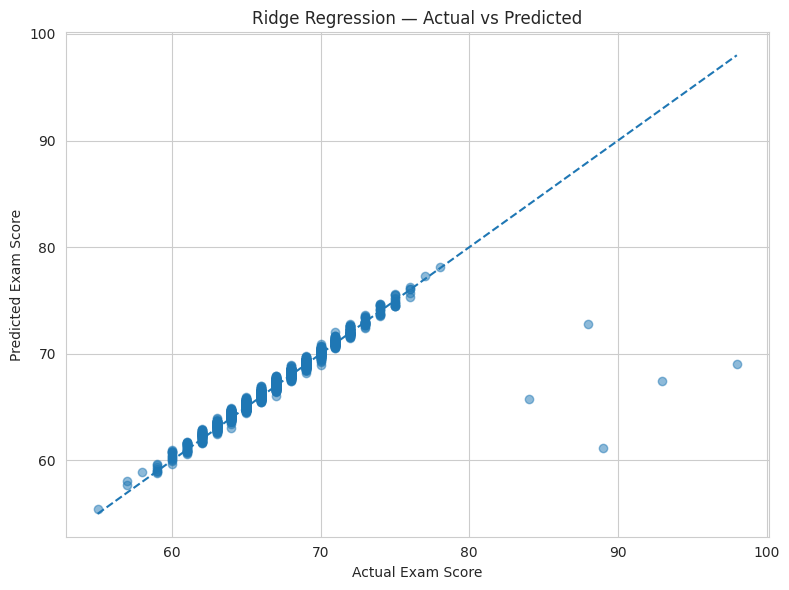


27.11 HIST GRADIENT BOOSTING ACTUAL VS PREDICTED
----------------------------------------------------------------------------------------------------


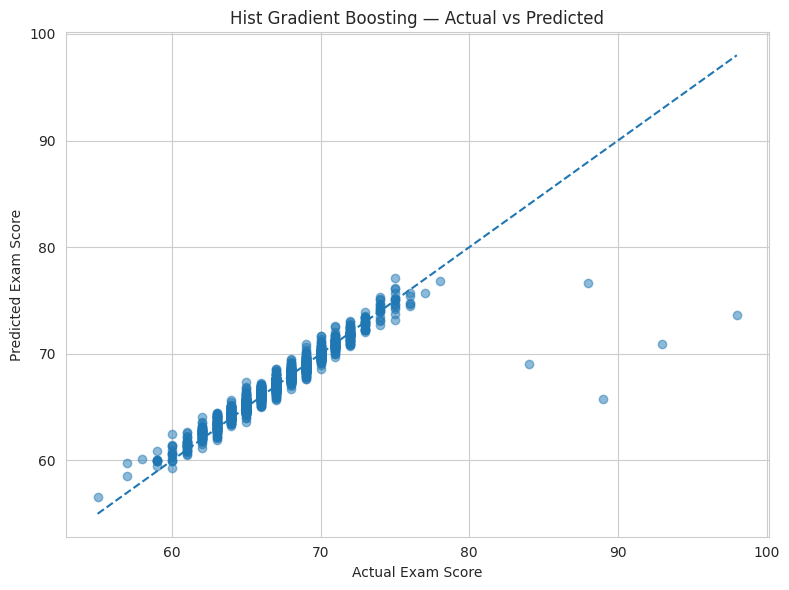


27.12 RIDGE RESIDUAL PLOT
----------------------------------------------------------------------------------------------------


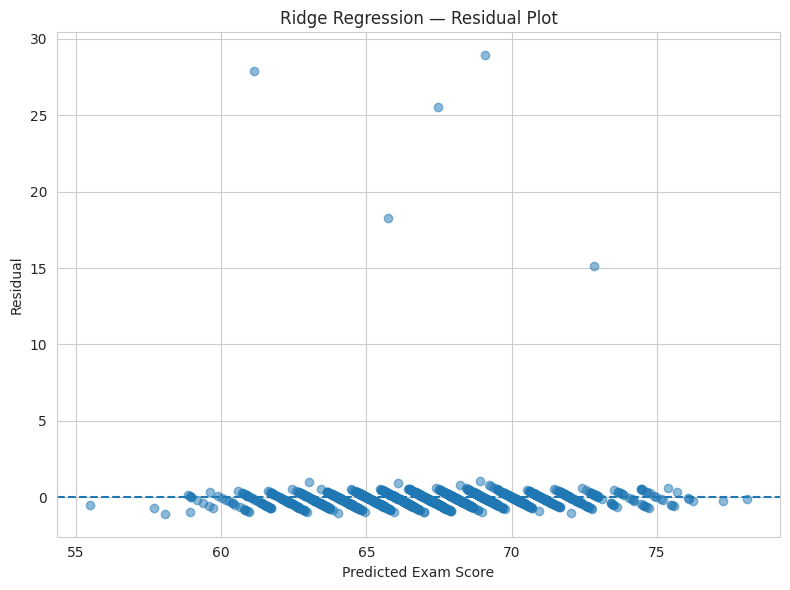


27.13 HIST GRADIENT BOOSTING RESIDUAL PLOT
----------------------------------------------------------------------------------------------------


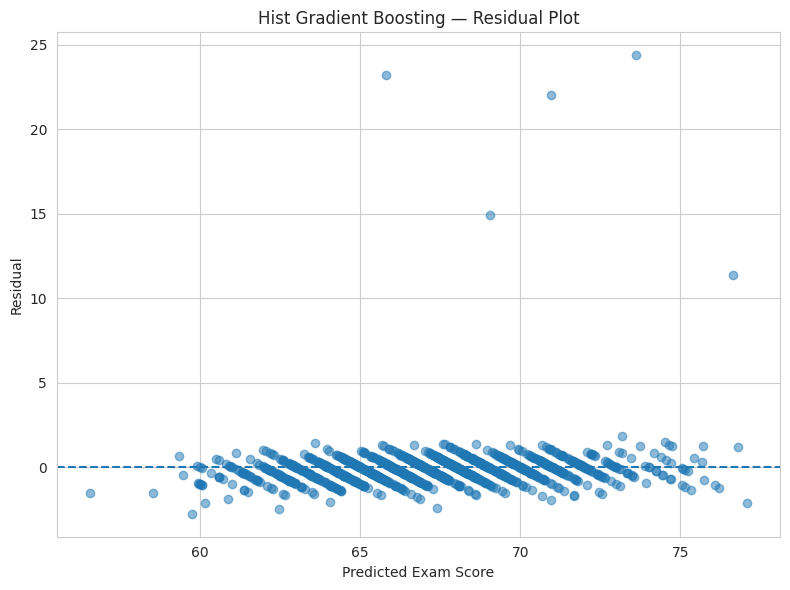


27.14 RIDGE RESIDUAL DISTRIBUTION
----------------------------------------------------------------------------------------------------


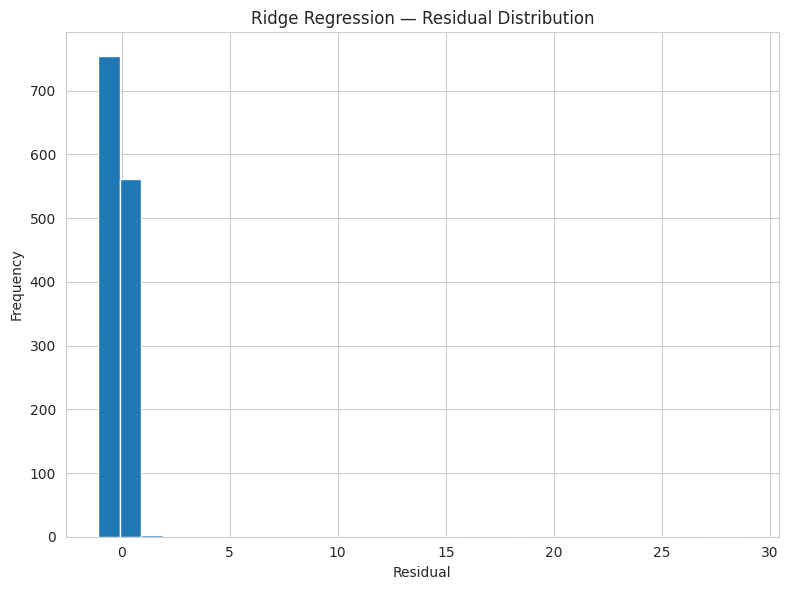


27.15 HIST GRADIENT BOOSTING RESIDUAL DISTRIBUTION
----------------------------------------------------------------------------------------------------


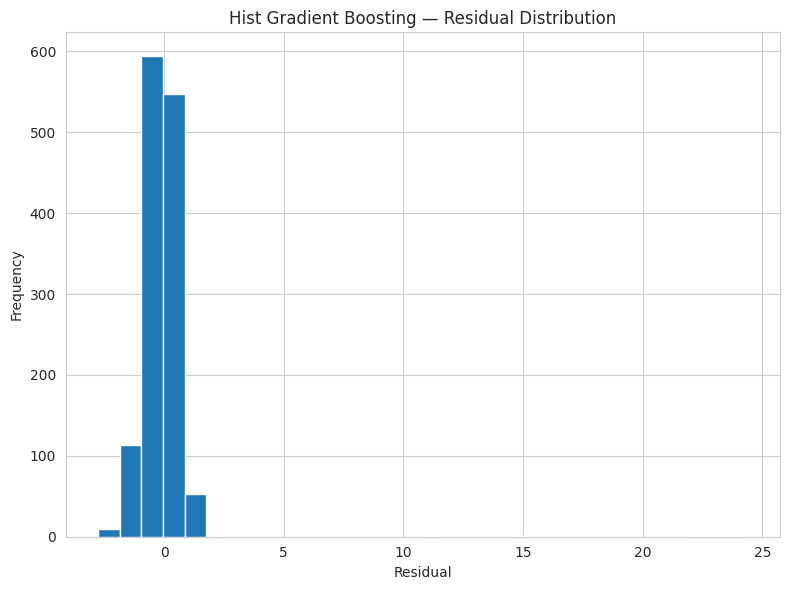


27.16 HIST GRADIENT BOOSTING FEATURE IMPORTANCE
----------------------------------------------------------------------------------------------------
Hist Gradient Boosting does not expose feature_importances_ in this configuration.

27.17 MAP PROCESSED FEATURES TO ORIGINAL FEATURES
----------------------------------------------------------------------------------------------------

27.18 PERMUTATION IMPORTANCE
----------------------------------------------------------------------------------------------------
Calculating permutation importance for Ridge...

Ridge permutation importance:


,Feature,Importance_Mean,Importance_STD
0,Attendance,0.800690,0.019918
1,Hours_Studied,0.490094,0.009144
2,Previous_Scores,0.074424,0.003896
3,Access_to_Resources,0.073592,0.003905
4,Parental_Involvement,0.071420,0.002803
5,Tutoring_Sessions,0.055154,0.002951
6,Family_Income,0.026749,0.002478
7,Peer_Influence,0.024529,0.001151
8,Motivation_Level,0.020726,0.002706
9,Parental_Education_Level,0.020260,0.002409



Calculating permutation importance for Hist Gradient Boosting...

Hist Gradient Boosting permutation importance:


,Feature,Importance_Mean,Importance_STD
0,Attendance,0.806589,0.018333
1,Hours_Studied,0.471001,0.013076
2,Previous_Scores,0.090679,0.004561
3,Parental_Involvement,0.071579,0.002500
4,Access_to_Resources,0.071147,0.004024
5,Tutoring_Sessions,0.055939,0.005328
6,Family_Income,0.034388,0.004221
7,Peer_Influence,0.025505,0.003086
8,Motivation_Level,0.023621,0.002265
9,Parental_Education_Level,0.021246,0.002819



27.19 FEATURE IMPORTANCE COMPARISON
----------------------------------------------------------------------------------------------------


,Feature,Ridge_Importance,HGB_Importance,Average_Importance
0,Attendance,0.800690,0.806589,0.803639
1,Hours_Studied,0.490094,0.471001,0.480547
2,Previous_Scores,0.074424,0.090679,0.082551
3,Access_to_Resources,0.073592,0.071147,0.072370
4,Parental_Involvement,0.071420,0.071579,0.071500
5,Tutoring_Sessions,0.055154,0.055939,0.055547
6,Family_Income,0.026749,0.034388,0.030568
7,Peer_Influence,0.024529,0.025505,0.025017
8,Motivation_Level,0.020726,0.023621,0.022173
9,Parental_Education_Level,0.020260,0.021246,0.020753



27.20 TOP PREDICTIVE FEATURES
----------------------------------------------------------------------------------------------------
Top 10 features based on average permutation importance:


,Feature,Ridge_Importance,HGB_Importance,Average_Importance
0,Attendance,0.800690,0.806589,0.803639
1,Hours_Studied,0.490094,0.471001,0.480547
2,Previous_Scores,0.074424,0.090679,0.082551
3,Access_to_Resources,0.073592,0.071147,0.072370
4,Parental_Involvement,0.071420,0.071579,0.071500
5,Tutoring_Sessions,0.055154,0.055939,0.055547
6,Family_Income,0.026749,0.034388,0.030568
7,Peer_Influence,0.024529,0.025505,0.025017
8,Motivation_Level,0.020726,0.023621,0.022173
9,Parental_Education_Level,0.020260,0.021246,0.020753



27.21 FEATURE IMPORTANCE VISUALIZATION
----------------------------------------------------------------------------------------------------


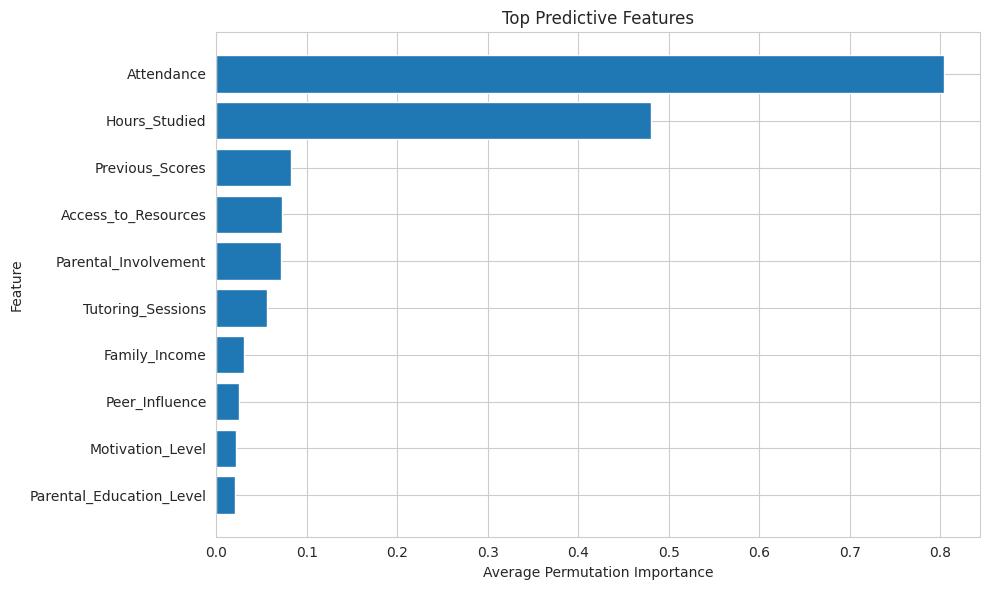


27.22 MODEL PERFORMANCE VS GENERALIZATION
----------------------------------------------------------------------------------------------------


,Model,CV_RMSE,Train_R2,Test_R2,Test_RMSE,Test_MAE,Generalization_Gap
0,Ridge Regression (Tuned),1.983913,0.710788,0.826931,1.512847,0.403313,-0.116142
1,Hist Gradient Boosting (Tuned),2.085249,0.773326,0.857834,1.371144,0.561841,-0.084508



27.23 EVIDENCE-BASED FINAL MODEL DECISION
----------------------------------------------------------------------------------------------------

Model evidence:
Ridge CV RMSE                : 1.9839
Hist Gradient Boosting CV RMSE: 2.0852

Ridge Test RMSE              : 1.5128
Hist Gradient Boosting Test RMSE: 1.3711

Ridge Test R²                : 0.8269
Hist Gradient Boosting Test R²: 0.8578

Ridge Generalization Gap     : -0.1161
Hist Gradient Boosting Gap   : -0.0845

CV RMSE difference (HGB - Ridge): 0.1013

Evidence-based final candidate: Ridge Regression (Tuned)

27.24 FINAL MODEL PERFORMANCE TABLE
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Final Candidate,Ridge Regression (Tuned)
1,Cross-Validation RMSE,1.983913
2,Test MAE,0.403313
3,Test RMSE,1.512847
4,Test R²,0.826931
5,Generalization Gap,-0.116142



27.25 FINAL MODEL INTERPRETATION
----------------------------------------------------------------------------------------------------

Final candidate:
Ridge Regression (Tuned)

Cross-validation RMSE:
1.9839

Test MAE:
0.4033

Test RMSE:
1.5128

Test R²:
0.8269

Generalization gap:
-0.1161


27.26 SAVE EXPLAINABILITY RESULTS
----------------------------------------------------------------------------------------------------
Saved:
→ student_exam_score_feature_importance.csv
→ student_exam_score_final_performance.csv
→ student_exam_score_ridge_residuals.csv
→ student_exam_score_hgb_residuals.csv

Stored:
→ final_explainability_results

STEP 27 SUMMARY

What we performed:

1. Compared tuned Ridge and tuned Hist Gradient Boosting.
2. Calculated detailed MAE, MSE, RMSE and R².
3. Investigated residual behaviour.
4. Investigated unusually large prediction errors.
5. Compared actual and predicted scores.
6. Analysed residual distributions.
7. Analysed residual plots.
8. Calculated model fea

In [37]:
# ====================================================================================================
# STEP 27: FINAL MODEL INTERPRETATION + EXPLAINABILITY
# ====================================================================================================

print("=" * 100)
print("STEP 27: FINAL MODEL INTERPRETATION + EXPLAINABILITY")
print("=" * 100)


# ----------------------------------------------------------------------------------------------------
# 27.1 VERIFY REQUIRED VARIABLES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.1 VERIFY REQUIRED VARIABLES")
print("-" * 100)

required_variables = [
    "X",
    "y",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "best_ridge_model",
    "best_hist_model",
    "ridge_test_predictions",
    "hist_test_predictions"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    print("Missing variables:")
    print(missing_variables)
    raise NameError(
        "Required Step 26 variables are missing. "
        "Please run Step 26 before running Step 27."
    )

print("✓ All required Step 26 variables are available.")


# ----------------------------------------------------------------------------------------------------
# 27.2 DEFINE FINAL MODEL CANDIDATES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.2 DEFINE FINAL MODEL CANDIDATES")
print("-" * 100)

candidate_models = {
    "Ridge Regression (Tuned)": best_ridge_model,
    "Hist Gradient Boosting (Tuned)": best_hist_model
}

candidate_predictions = {
    "Ridge Regression (Tuned)": ridge_test_predictions,
    "Hist Gradient Boosting (Tuned)": hist_test_predictions
}

print("Models being compared:")
for model_name in candidate_models:
    print(f"✓ {model_name}")


# ----------------------------------------------------------------------------------------------------
# 27.3 CALCULATE DETAILED TEST METRICS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.3 DETAILED TEST PERFORMANCE")
print("-" * 100)

detailed_model_results = []

for model_name, predictions in candidate_predictions.items():

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        predictions
    )

    detailed_model_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

detailed_model_results_df = pd.DataFrame(
    detailed_model_results
)

display(
    detailed_model_results_df.sort_values(
        "RMSE"
    ).reset_index(drop=True)
)


# ----------------------------------------------------------------------------------------------------
# 27.4 COMPARE MODEL PERFORMANCE DIFFERENCES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.4 MODEL PERFORMANCE DIFFERENCE")
print("-" * 100)

ridge_metrics = detailed_model_results_df[
    detailed_model_results_df["Model"] == "Ridge Regression (Tuned)"
].iloc[0]

hist_metrics = detailed_model_results_df[
    detailed_model_results_df["Model"] == "Hist Gradient Boosting (Tuned)"
].iloc[0]

performance_difference = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2"
    ],
    "Ridge": [
        ridge_metrics["MAE"],
        ridge_metrics["MSE"],
        ridge_metrics["RMSE"],
        ridge_metrics["R2"]
    ],
    "Hist_Gradient_Boosting": [
        hist_metrics["MAE"],
        hist_metrics["MSE"],
        hist_metrics["RMSE"],
        hist_metrics["R2"]
    ]
})

performance_difference["Difference_HGB_minus_Ridge"] = (
    performance_difference["Hist_Gradient_Boosting"]
    - performance_difference["Ridge"]
)

display(performance_difference)


# ----------------------------------------------------------------------------------------------------
# 27.5 CREATE RESIDUAL DATASETS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.5 CREATE RESIDUAL DATASETS")
print("-" * 100)

ridge_residuals = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": ridge_test_predictions
})

ridge_residuals["Residual"] = (
    ridge_residuals["Actual"]
    - ridge_residuals["Predicted"]
)

ridge_residuals["Absolute_Error"] = (
    ridge_residuals["Residual"].abs()
)

hist_residuals = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": hist_test_predictions
})

hist_residuals["Residual"] = (
    hist_residuals["Actual"]
    - hist_residuals["Predicted"]
)

hist_residuals["Absolute_Error"] = (
    hist_residuals["Residual"].abs()
)

print("Residual datasets created successfully.")


# ----------------------------------------------------------------------------------------------------
# 27.6 RESIDUAL SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.6 RESIDUAL SUMMARY")
print("-" * 100)

residual_summary = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "Mean_Residual": [
        ridge_residuals["Residual"].mean(),
        hist_residuals["Residual"].mean()
    ],
    "Std_Residual": [
        ridge_residuals["Residual"].std(),
        hist_residuals["Residual"].std()
    ],
    "Mean_Absolute_Error": [
        ridge_residuals["Absolute_Error"].mean(),
        hist_residuals["Absolute_Error"].mean()
    ],
    "Maximum_Absolute_Error": [
        ridge_residuals["Absolute_Error"].max(),
        hist_residuals["Absolute_Error"].max()
    ]
})

display(residual_summary)


# ----------------------------------------------------------------------------------------------------
# 27.7 INVESTIGATE LARGE RIDGE RESIDUALS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.7 INVESTIGATE LARGE RIDGE RESIDUALS")
print("-" * 100)

ridge_large_errors = ridge_residuals[
    ridge_residuals["Absolute_Error"] >= 5
].sort_values(
    "Absolute_Error",
    ascending=False
)

print(
    f"Number of Ridge predictions with absolute error >= 5: "
    f"{len(ridge_large_errors)}"
)

if len(ridge_large_errors) > 0:
    print("\nLargest Ridge prediction errors:")
    display(ridge_large_errors.head(20))
else:
    print("No Ridge predictions have absolute error >= 5.")


# ----------------------------------------------------------------------------------------------------
# 27.8 INVESTIGATE LARGE HIST GRADIENT BOOSTING RESIDUALS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.8 INVESTIGATE LARGE HIST GRADIENT BOOSTING RESIDUALS")
print("-" * 100)

hist_large_errors = hist_residuals[
    hist_residuals["Absolute_Error"] >= 5
].sort_values(
    "Absolute_Error",
    ascending=False
)

print(
    f"Number of Hist Gradient Boosting predictions with absolute error >= 5: "
    f"{len(hist_large_errors)}"
)

if len(hist_large_errors) > 0:
    print("\nLargest Hist Gradient Boosting prediction errors:")
    display(hist_large_errors.head(20))
else:
    print("No Hist Gradient Boosting predictions have absolute error >= 5.")


# ----------------------------------------------------------------------------------------------------
# 27.9 COMPARE LARGE-ERROR BEHAVIOUR
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.9 LARGE-ERROR COMPARISON")
print("-" * 100)

large_error_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "Errors_>=5": [
        (ridge_residuals["Absolute_Error"] >= 5).sum(),
        (hist_residuals["Absolute_Error"] >= 5).sum()
    ],
    "Errors_>=10": [
        (ridge_residuals["Absolute_Error"] >= 10).sum(),
        (hist_residuals["Absolute_Error"] >= 10).sum()
    ],
    "Maximum_Absolute_Error": [
        ridge_residuals["Absolute_Error"].max(),
        hist_residuals["Absolute_Error"].max()
    ]
})

display(large_error_comparison)


# ----------------------------------------------------------------------------------------------------
# 27.10 ACTUAL VS PREDICTED — RIDGE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.10 RIDGE ACTUAL VS PREDICTED")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.scatter(
    ridge_residuals["Actual"],
    ridge_residuals["Predicted"],
    alpha=0.5
)

minimum_value = min(
    ridge_residuals["Actual"].min(),
    ridge_residuals["Predicted"].min()
)

maximum_value = max(
    ridge_residuals["Actual"].max(),
    ridge_residuals["Predicted"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Ridge Regression — Actual vs Predicted")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.11 ACTUAL VS PREDICTED — HIST GRADIENT BOOSTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.11 HIST GRADIENT BOOSTING ACTUAL VS PREDICTED")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.scatter(
    hist_residuals["Actual"],
    hist_residuals["Predicted"],
    alpha=0.5
)

minimum_value = min(
    hist_residuals["Actual"].min(),
    hist_residuals["Predicted"].min()
)

maximum_value = max(
    hist_residuals["Actual"].max(),
    hist_residuals["Predicted"].max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Hist Gradient Boosting — Actual vs Predicted")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.12 RESIDUAL PLOT — RIDGE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.12 RIDGE RESIDUAL PLOT")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.scatter(
    ridge_residuals["Predicted"],
    ridge_residuals["Residual"],
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual")
plt.title("Ridge Regression — Residual Plot")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.13 RESIDUAL PLOT — HIST GRADIENT BOOSTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.13 HIST GRADIENT BOOSTING RESIDUAL PLOT")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.scatter(
    hist_residuals["Predicted"],
    hist_residuals["Residual"],
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual")
plt.title("Hist Gradient Boosting — Residual Plot")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.14 RESIDUAL DISTRIBUTION — RIDGE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.14 RIDGE RESIDUAL DISTRIBUTION")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.hist(
    ridge_residuals["Residual"],
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Ridge Regression — Residual Distribution")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.15 RESIDUAL DISTRIBUTION — HIST GRADIENT BOOSTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.15 HIST GRADIENT BOOSTING RESIDUAL DISTRIBUTION")
print("-" * 100)

plt.figure(figsize=(8, 6))

plt.hist(
    hist_residuals["Residual"],
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Hist Gradient Boosting — Residual Distribution")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.16 FEATURE IMPORTANCE — HIST GRADIENT BOOSTING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.16 HIST GRADIENT BOOSTING FEATURE IMPORTANCE")
print("-" * 100)

hist_model_only = best_hist_model.named_steps["model"]

if hasattr(hist_model_only, "feature_importances_"):

    processed_feature_names = (
        best_hist_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    hist_importance = pd.DataFrame({
        "Processed_Feature": processed_feature_names,
        "Importance": hist_model_only.feature_importances_
    })

    hist_importance = hist_importance.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    print("Top processed features:")
    display(hist_importance.head(20))

else:
    hist_importance = None
    print(
        "Hist Gradient Boosting does not expose "
        "feature_importances_ in this configuration."
    )


# ----------------------------------------------------------------------------------------------------
# 27.17 MAP PROCESSED FEATURES BACK TO ORIGINAL FEATURES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.17 MAP PROCESSED FEATURES TO ORIGINAL FEATURES")
print("-" * 100)

if hist_importance is not None:

    original_feature_importance = []

    for processed_feature in hist_importance["Processed_Feature"]:

        feature_name = processed_feature

        # Numerical transformer
        if processed_feature.startswith("num__"):

            original_name = processed_feature.replace(
                "num__",
                ""
            )

        # Categorical transformer
        elif processed_feature.startswith("cat__"):

            categorical_part = processed_feature.replace(
                "cat__",
                ""
            )

            matched_feature = None

            for original_feature in categorical_features:

                if categorical_part.startswith(
                    original_feature + "_"
                ):
                    matched_feature = original_feature
                    break

            if matched_feature is None:
                matched_feature = categorical_part

            original_name = matched_feature

        else:
            original_name = feature_name

        original_feature_importance.append(
            original_name
        )

    hist_importance["Original_Feature"] = (
        original_feature_importance
    )

    aggregated_hist_importance = (
        hist_importance
        .groupby(
            "Original_Feature",
            as_index=False
        )["Importance"]
        .sum()
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("Original feature-level importance:")
    display(aggregated_hist_importance)


# ----------------------------------------------------------------------------------------------------
# 27.18 PERMUTATION IMPORTANCE FOR FINAL CANDIDATES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.18 PERMUTATION IMPORTANCE")
print("-" * 100)

from sklearn.inspection import permutation_importance

print("Calculating permutation importance for Ridge...")

ridge_permutation = permutation_importance(
    best_ridge_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

ridge_permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": ridge_permutation.importances_mean,
    "Importance_STD": ridge_permutation.importances_std
})

ridge_permutation_df = ridge_permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\nRidge permutation importance:")
display(ridge_permutation_df)


print("\nCalculating permutation importance for Hist Gradient Boosting...")

hist_permutation = permutation_importance(
    best_hist_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

hist_permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": hist_permutation.importances_mean,
    "Importance_STD": hist_permutation.importances_std
})

hist_permutation_df = hist_permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\nHist Gradient Boosting permutation importance:")
display(hist_permutation_df)


# ----------------------------------------------------------------------------------------------------
# 27.19 COMPARE FEATURE IMPORTANCE ACROSS FINAL CANDIDATES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.19 FEATURE IMPORTANCE COMPARISON")
print("-" * 100)

feature_comparison = pd.merge(
    ridge_permutation_df[
        [
            "Feature",
            "Importance_Mean"
        ]
    ].rename(
        columns={
            "Importance_Mean": "Ridge_Importance"
        }
    ),
    hist_permutation_df[
        [
            "Feature",
            "Importance_Mean"
        ]
    ].rename(
        columns={
            "Importance_Mean": "HGB_Importance"
        }
    ),
    on="Feature",
    how="outer"
)

feature_comparison["Ridge_Importance"] = (
    feature_comparison["Ridge_Importance"]
    .fillna(0)
)

feature_comparison["HGB_Importance"] = (
    feature_comparison["HGB_Importance"]
    .fillna(0)
)

feature_comparison["Average_Importance"] = (
    feature_comparison[
        [
            "Ridge_Importance",
            "HGB_Importance"
        ]
    ].mean(axis=1)
)

feature_comparison = feature_comparison.sort_values(
    "Average_Importance",
    ascending=False
).reset_index(drop=True)

display(feature_comparison)


# ----------------------------------------------------------------------------------------------------
# 27.20 TOP PREDICTIVE FEATURES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.20 TOP PREDICTIVE FEATURES")
print("-" * 100)

print("Top 10 features based on average permutation importance:")

top_features = feature_comparison.head(10)

display(top_features)


# ----------------------------------------------------------------------------------------------------
# 27.21 FEATURE IMPORTANCE VISUALIZATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.21 FEATURE IMPORTANCE VISUALIZATION")
print("-" * 100)

plot_data = feature_comparison.head(10).copy()

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"][::-1],
    plot_data["Average_Importance"][::-1]
)

plt.xlabel("Average Permutation Importance")
plt.ylabel("Feature")
plt.title("Top Predictive Features")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 27.22 MODEL PERFORMANCE VS GENERALIZATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.22 MODEL PERFORMANCE VS GENERALIZATION")
print("-" * 100)

ridge_train_r2 = r2_score(
    y_train,
    best_ridge_model.predict(X_train)
)

hist_train_r2 = r2_score(
    y_train,
    best_hist_model.predict(X_train)
)

final_model_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],
    "CV_RMSE": [
        -ridge_grid.best_score_,
        -hist_grid.best_score_
    ],
    "Train_R2": [
        ridge_train_r2,
        hist_train_r2
    ],
    "Test_R2": [
        ridge_metrics["R2"],
        hist_metrics["R2"]
    ],
    "Test_RMSE": [
        ridge_metrics["RMSE"],
        hist_metrics["RMSE"]
    ],
    "Test_MAE": [
        ridge_metrics["MAE"],
        hist_metrics["MAE"]
    ],
    "Generalization_Gap": [
        ridge_train_r2 - ridge_metrics["R2"],
        hist_train_r2 - hist_metrics["R2"]
    ]
})

display(final_model_comparison)


# ----------------------------------------------------------------------------------------------------
# 27.23 EVIDENCE-BASED FINAL MODEL DECISION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.23 EVIDENCE-BASED FINAL MODEL DECISION")
print("-" * 100)

ridge_cv_rmse = -ridge_grid.best_score_
hist_cv_rmse = -hist_grid.best_score_

ridge_test_rmse = ridge_metrics["RMSE"]
hist_test_rmse = hist_metrics["RMSE"]

ridge_test_r2 = ridge_metrics["R2"]
hist_test_r2 = hist_metrics["R2"]

ridge_gap = ridge_train_r2 - ridge_test_r2
hist_gap = hist_train_r2 - hist_test_r2

print("\nModel evidence:")
print(f"Ridge CV RMSE                : {ridge_cv_rmse:.4f}")
print(f"Hist Gradient Boosting CV RMSE: {hist_cv_rmse:.4f}")

print(f"\nRidge Test RMSE              : {ridge_test_rmse:.4f}")
print(f"Hist Gradient Boosting Test RMSE: {hist_test_rmse:.4f}")

print(f"\nRidge Test R²                : {ridge_test_r2:.4f}")
print(f"Hist Gradient Boosting Test R²: {hist_test_r2:.4f}")

print(f"\nRidge Generalization Gap     : {ridge_gap:.4f}")
print(f"Hist Gradient Boosting Gap   : {hist_gap:.4f}")


# Use a transparent rule rather than a single metric:
#
# 1. Prefer the model with stronger CV performance.
# 2. Consider test performance.
# 3. Check whether the model has strong overfitting.
#
# If CV RMSE is close but test performance differs substantially,
# keep the decision provisional and document both results.

cv_difference = hist_cv_rmse - ridge_cv_rmse

print(f"\nCV RMSE difference (HGB - Ridge): {cv_difference:.4f}")

if abs(cv_difference) <= 0.10:

    print(
        "\nCV performance is very close between the two candidates."
    )

    if hist_test_rmse < ridge_test_rmse:

        print(
            "Hist Gradient Boosting has better held-out test RMSE."
        )

        if hist_gap <= 0.15:

            print(
                "Its generalization gap is also below the "
                "overfitting threshold."
            )

            evidence_based_final_model_name = (
                "Hist Gradient Boosting (Tuned)"
            )

            evidence_based_final_model = best_hist_model

        else:

            print(
                "However, its generalization gap requires caution."
            )

            evidence_based_final_model_name = (
                "Ridge Regression (Tuned)"
            )

            evidence_based_final_model = best_ridge_model

    else:

        evidence_based_final_model_name = (
            "Ridge Regression (Tuned)"
        )

        evidence_based_final_model = best_ridge_model

else:

    if ridge_cv_rmse < hist_cv_rmse:

        evidence_based_final_model_name = (
            "Ridge Regression (Tuned)"
        )

        evidence_based_final_model = best_ridge_model

    else:

        evidence_based_final_model_name = (
            "Hist Gradient Boosting (Tuned)"
        )

        evidence_based_final_model = best_hist_model


print(
    f"\nEvidence-based final candidate: "
    f"{evidence_based_final_model_name}"
)


# ----------------------------------------------------------------------------------------------------
# 27.24 FINAL MODEL PERFORMANCE TABLE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.24 FINAL MODEL PERFORMANCE TABLE")
print("-" * 100)

if evidence_based_final_model_name == "Ridge Regression (Tuned)":

    selected_cv_rmse = ridge_cv_rmse
    selected_test_mae = ridge_metrics["MAE"]
    selected_test_rmse = ridge_metrics["RMSE"]
    selected_test_r2 = ridge_metrics["R2"]
    selected_gap = ridge_gap

else:

    selected_cv_rmse = hist_cv_rmse
    selected_test_mae = hist_metrics["MAE"]
    selected_test_rmse = hist_metrics["RMSE"]
    selected_test_r2 = hist_metrics["R2"]
    selected_gap = hist_gap

final_model_performance = pd.DataFrame({
    "Metric": [
        "Final Candidate",
        "Cross-Validation RMSE",
        "Test MAE",
        "Test RMSE",
        "Test R²",
        "Generalization Gap"
    ],
    "Value": [
        evidence_based_final_model_name,
        selected_cv_rmse,
        selected_test_mae,
        selected_test_rmse,
        selected_test_r2,
        selected_gap
    ]
})

display(final_model_performance)


# ----------------------------------------------------------------------------------------------------
# 27.25 FINAL MODEL INTERPRETATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.25 FINAL MODEL INTERPRETATION")
print("-" * 100)

print(f"""
Final candidate:
{evidence_based_final_model_name}

Cross-validation RMSE:
{selected_cv_rmse:.4f}

Test MAE:
{selected_test_mae:.4f}

Test RMSE:
{selected_test_rmse:.4f}

Test R²:
{selected_test_r2:.4f}

Generalization gap:
{selected_gap:.4f}
""")


# ----------------------------------------------------------------------------------------------------
# 27.26 SAVE EXPLAINABILITY RESULTS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("27.26 SAVE EXPLAINABILITY RESULTS")
print("-" * 100)

feature_comparison.to_csv(
    "student_exam_score_feature_importance.csv",
    index=False
)

final_model_performance.to_csv(
    "student_exam_score_final_performance.csv",
    index=False
)

ridge_residuals.to_csv(
    "student_exam_score_ridge_residuals.csv",
    index=False
)

hist_residuals.to_csv(
    "student_exam_score_hgb_residuals.csv",
    index=False
)

print("Saved:")
print("→ student_exam_score_feature_importance.csv")
print("→ student_exam_score_final_performance.csv")
print("→ student_exam_score_ridge_residuals.csv")
print("→ student_exam_score_hgb_residuals.csv")


# ----------------------------------------------------------------------------------------------------
# 27.27 STORE FINAL STEP 27 VARIABLES
# ----------------------------------------------------------------------------------------------------

final_explainability_results = {
    "final_model_name": evidence_based_final_model_name,
    "final_model": evidence_based_final_model,
    "performance_table": final_model_performance,
    "feature_importance": feature_comparison,
    "ridge_residuals": ridge_residuals,
    "hist_residuals": hist_residuals
}

print("\nStored:")
print("→ final_explainability_results")


# ----------------------------------------------------------------------------------------------------
# 27.28 STEP 27 SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 27 SUMMARY")
print("=" * 100)

print("""
What we performed:

1. Compared tuned Ridge and tuned Hist Gradient Boosting.
2. Calculated detailed MAE, MSE, RMSE and R².
3. Investigated residual behaviour.
4. Investigated unusually large prediction errors.
5. Compared actual and predicted scores.
6. Analysed residual distributions.
7. Analysed residual plots.
8. Calculated model feature importance.
9. Calculated permutation importance.
10. Mapped encoded features back to original features.
11. Compared feature influence across candidate models.
12. Checked model generalization.
13. Applied an evidence-based final model selection procedure.
14. Created the final model performance table.
15. Saved explainability and residual results.

The next stage can use these results to prepare:
→ FINAL MODEL + DEPLOYMENT PIPELINE
→ MODEL DOCUMENTATION
→ FINAL REPORT / INTERNSHIP REPORT
""")

print("=" * 100)
print("STEP 27 COMPLETED")
print("=" * 100)

In [38]:
# ====================================================================================================
# STEP 28: FINAL MODEL TRAINING + DEPLOYMENT-READY PREDICTION PIPELINE
# ====================================================================================================

print("=" * 100)
print("STEP 28: FINAL MODEL TRAINING + DEPLOYMENT-READY PIPELINE")
print("=" * 100)


# ----------------------------------------------------------------------------------------------------
# 28.1 IMPORT REQUIRED LIBRARIES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.1 IMPORT REQUIRED LIBRARIES")
print("-" * 100)

import numpy as np
import pandas as pd
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import cross_validate, KFold

print("Required libraries imported successfully.")


# ----------------------------------------------------------------------------------------------------
# 28.2 VERIFY CLEAN DATA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.2 VERIFY CLEAN DATA")
print("-" * 100)

print(f"Clean dataset shape : {df_clean.shape}")
print(f"Target variable     : {target_column}")
print(f"Target observations : {len(y)}")

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nTarget range:")
print(f"Minimum Exam_Score : {df_clean['Exam_Score'].min()}")
print(f"Maximum Exam_Score : {df_clean['Exam_Score'].max()}")

if df_clean.isnull().sum().sum() != 0:
    raise ValueError("Clean dataset still contains missing values.")

if df_clean.duplicated().sum() != 0:
    raise ValueError("Clean dataset still contains duplicate rows.")

print("\n✓ Clean dataset verified.")


# ----------------------------------------------------------------------------------------------------
# 28.3 VERIFY FINAL MODEL SELECTION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.3 VERIFY FINAL MODEL SELECTION")
print("-" * 100)

if "evidence_based_final_model_name" not in globals():
    raise NameError(
        "evidence_based_final_model_name is missing. "
        "Please run Step 27 first."
    )

print(
    f"Selected model from Step 27:\n"
    f"→ {evidence_based_final_model_name}"
)

print(
    "\nThe selected model will now be retrained using "
    "the complete cleaned dataset."
)


# ----------------------------------------------------------------------------------------------------
# 28.4 DEFINE FINAL TRAINING DATA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.4 DEFINE FINAL TRAINING DATA")
print("-" * 100)

X_final = df_clean.drop(
    columns=[target_column]
).copy()

y_final = df_clean[target_column].copy()

print(f"Final feature matrix shape : {X_final.shape}")
print(f"Final target shape         : {y_final.shape}")

print(f"\nNumber of numerical features : {len(numerical_predictors)}")
print(f"Number of categorical features: {len(categorical_features)}")


# ----------------------------------------------------------------------------------------------------
# 28.5 CREATE FRESH PREPROCESSOR
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.5 CREATE FRESH PREPROCESSOR")
print("-" * 100)

final_preprocessor = clone(preprocessor)

print("Fresh preprocessing object created.")

print("""
Final preprocessing:
Numerical features
    ↓
Median Imputation
    ↓
Standard Scaling

Categorical features
    ↓
Most-Frequent Imputation
    ↓
One-Hot Encoding
""")


# ----------------------------------------------------------------------------------------------------
# 28.6 DEFINE FINAL MODEL
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.6 DEFINE FINAL MODEL")
print("-" * 100)

if evidence_based_final_model_name == "Ridge Regression (Tuned)":

    final_estimator = Ridge(
        alpha=ridge_grid.best_params_[
            "model__alpha"
        ]
    )

    print("Final estimator: Ridge Regression")
    print(
        f"Selected alpha: "
        f"{ridge_grid.best_params_['model__alpha']}"
    )

elif evidence_based_final_model_name == "Hist Gradient Boosting (Tuned)":

    final_estimator = HistGradientBoostingRegressor(
        learning_rate=hist_grid.best_params_[
            "model__learning_rate"
        ],
        max_iter=hist_grid.best_params_[
            "model__max_iter"
        ],
        max_leaf_nodes=hist_grid.best_params_[
            "model__max_leaf_nodes"
        ],
        l2_regularization=hist_grid.best_params_[
            "model__l2_regularization"
        ],
        random_state=42
    )

    print("Final estimator: Hist Gradient Boosting")

    print("\nSelected hyperparameters:")

    for parameter, value in hist_grid.best_params_.items():

        clean_parameter = parameter.replace(
            "model__",
            ""
        )

        print(
            f"{clean_parameter}: {value}"
        )

else:

    raise ValueError(
        f"Unsupported final model: "
        f"{evidence_based_final_model_name}"
    )


# ----------------------------------------------------------------------------------------------------
# 28.7 CREATE DEPLOYMENT PIPELINE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.7 CREATE DEPLOYMENT PIPELINE")
print("-" * 100)

deployment_pipeline = Pipeline([
    (
        "preprocessor",
        final_preprocessor
    ),
    (
        "model",
        final_estimator
    )
])

print("""
Deployment pipeline:

Raw Student Data
      ↓
Data Validation
      ↓
Missing Value Handling
      ↓
Categorical Encoding
      ↓
Numerical Scaling
      ↓
Final ML Model
      ↓
Exam Score Prediction
""")


# ----------------------------------------------------------------------------------------------------
# 28.8 TRAIN FINAL MODEL ON ALL CLEANED DATA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.8 TRAIN FINAL MODEL ON ALL CLEANED DATA")
print("-" * 100)

deployment_pipeline.fit(
    X_final,
    y_final
)

print("✓ Final deployment model trained successfully.")

print(
    f"\nTraining observations used: "
    f"{len(X_final)}"
)


# ----------------------------------------------------------------------------------------------------
# 28.9 VERIFY TRANSFORMED FEATURE SPACE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.9 VERIFY FINAL FEATURE SPACE")
print("-" * 100)

final_feature_names = (
    deployment_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print(
    f"Original input features : "
    f"{X_final.shape[1]}"
)

print(
    f"Processed ML features   : "
    f"{len(final_feature_names)}"
)

print("\nFirst processed features:")

for feature in final_feature_names[:20]:
    print(f"✓ {feature}")


# ----------------------------------------------------------------------------------------------------
# 28.10 TRAINING DATA PREDICTION CHECK
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.10 TRAINING DATA PREDICTION CHECK")
print("-" * 100)

training_predictions = deployment_pipeline.predict(
    X_final
)

training_mae = mean_absolute_error(
    y_final,
    training_predictions
)

training_mse = mean_squared_error(
    y_final,
    training_predictions
)

training_rmse = np.sqrt(
    training_mse
)

training_r2 = r2_score(
    y_final,
    training_predictions
)

print(f"Training MAE  : {training_mae:.4f}")
print(f"Training MSE  : {training_mse:.4f}")
print(f"Training RMSE : {training_rmse:.4f}")
print(f"Training R²   : {training_r2:.4f}")


# ----------------------------------------------------------------------------------------------------
# 28.11 CREATE FINAL MODEL RESIDUAL REFERENCE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.11 CREATE FINAL MODEL RESIDUAL REFERENCE")
print("-" * 100)

final_training_residuals = (
    y_final.values
    - training_predictions
)

residual_mean = np.mean(
    final_training_residuals
)

residual_std = np.std(
    final_training_residuals
)

residual_mae = np.mean(
    np.abs(final_training_residuals)
)

residual_rmse = np.sqrt(
    np.mean(
        final_training_residuals ** 2
    )
)

print(f"Residual mean : {residual_mean:.4f}")
print(f"Residual std  : {residual_std:.4f}")
print(f"Residual MAE  : {residual_mae:.4f}")
print(f"Residual RMSE : {residual_rmse:.4f}")


# ----------------------------------------------------------------------------------------------------
# 28.12 DEFINE INPUT VALIDATION FUNCTION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.12 DEFINE INPUT VALIDATION FUNCTION")
print("-" * 100)


def validate_student_input(student_data):
    """
    Validate a single student's input data before prediction.
    """

    if not isinstance(
        student_data,
        pd.DataFrame
    ):

        raise TypeError(
            "student_data must be a pandas DataFrame."
        )

    expected_columns = list(
        X_final.columns
    )

    missing_columns = [
        column
        for column in expected_columns
        if column not in student_data.columns
    ]

    extra_columns = [
        column
        for column in student_data.columns
        if column not in expected_columns
    ]

    if missing_columns:

        raise ValueError(
            "Missing required columns: "
            + str(missing_columns)
        )

    if extra_columns:

        print(
            "Warning: Extra columns will be ignored:"
        )

        print(extra_columns)

        student_data = student_data[
            expected_columns
        ].copy()

    else:

        student_data = student_data[
            expected_columns
        ].copy()

    return student_data


print("✓ Input validation function created.")


# ----------------------------------------------------------------------------------------------------
# 28.13 DEFINE PREDICTION FUNCTION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.13 DEFINE DEPLOYMENT PREDICTION FUNCTION")
print("-" * 100)


def predict_exam_score(student_data):
    """
    Predict Exam_Score for one or more students.

    Parameters
    ----------
    student_data : pandas.DataFrame
        DataFrame containing the 19 predictor variables.

    Returns
    -------
    pandas.DataFrame
        Original input variables plus:
        Predicted_Exam_Score
        Prediction_Error_Range
        Lower_Estimate
        Upper_Estimate
    """

    validated_data = validate_student_input(
        student_data
    )

    predictions = deployment_pipeline.predict(
        validated_data
    )

    # Approximate empirical uncertainty.
    #
    # This is NOT a formal statistical confidence interval.
    # It provides a practical error range based on observed
    # training residual variability.

    prediction_margin = (
        1.96 * residual_std
    )

    lower_estimate = np.maximum(
        0,
        predictions - prediction_margin
    )

    upper_estimate = np.minimum(
        100,
        predictions + prediction_margin
    )

    result = validated_data.copy()

    result["Predicted_Exam_Score"] = predictions

    result["Prediction_Error_Range"] = (
        prediction_margin
    )

    result["Lower_Estimate"] = (
        lower_estimate
    )

    result["Upper_Estimate"] = (
        upper_estimate
    )

    return result


print("✓ Prediction function created.")


# ----------------------------------------------------------------------------------------------------
# 28.14 CREATE SAMPLE STUDENT INPUT
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.14 CREATE SAMPLE STUDENT INPUT")
print("-" * 100)

sample_student = pd.DataFrame([
    {
        "Hours_Studied": 25,
        "Attendance": 90,
        "Parental_Involvement": "High",
        "Access_to_Resources": "High",
        "Extracurricular_Activities": "Yes",
        "Sleep_Hours": 8,
        "Previous_Scores": 82,
        "Motivation_Level": "High",
        "Internet_Access": "Yes",
        "Tutoring_Sessions": 2,
        "Family_Income": "Medium",
        "Teacher_Quality": "High",
        "School_Type": "Private",
        "Peer_Influence": "Positive",
        "Physical_Activity": 4,
        "Learning_Disabilities": "No",
        "Parental_Education_Level": "College",
        "Distance_from_Home": "Near",
        "Gender": "Female"
    }
])

print("Sample student input:")
display(sample_student)


# ----------------------------------------------------------------------------------------------------
# 28.15 TEST DEPLOYMENT PREDICTION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.15 TEST DEPLOYMENT PREDICTION")
print("-" * 100)

sample_prediction = predict_exam_score(
    sample_student
)

print("Prediction result:")
display(sample_prediction)


# ----------------------------------------------------------------------------------------------------
# 28.16 CREATE MULTIPLE SAMPLE STUDENTS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.16 TEST MULTIPLE STUDENTS")
print("-" * 100)

sample_students = pd.DataFrame([

    {
        "Hours_Studied": 10,
        "Attendance": 65,
        "Parental_Involvement": "Low",
        "Access_to_Resources": "Low",
        "Extracurricular_Activities": "No",
        "Sleep_Hours": 6,
        "Previous_Scores": 55,
        "Motivation_Level": "Low",
        "Internet_Access": "No",
        "Tutoring_Sessions": 0,
        "Family_Income": "Low",
        "Teacher_Quality": "Low",
        "School_Type": "Public",
        "Peer_Influence": "Negative",
        "Physical_Activity": 2,
        "Learning_Disabilities": "Yes",
        "Parental_Education_Level": "High School",
        "Distance_from_Home": "Far",
        "Gender": "Male"
    },

    {
        "Hours_Studied": 20,
        "Attendance": 80,
        "Parental_Involvement": "Medium",
        "Access_to_Resources": "Medium",
        "Extracurricular_Activities": "Yes",
        "Sleep_Hours": 7,
        "Previous_Scores": 75,
        "Motivation_Level": "Medium",
        "Internet_Access": "Yes",
        "Tutoring_Sessions": 1,
        "Family_Income": "Medium",
        "Teacher_Quality": "Medium",
        "School_Type": "Public",
        "Peer_Influence": "Neutral",
        "Physical_Activity": 3,
        "Learning_Disabilities": "No",
        "Parental_Education_Level": "College",
        "Distance_from_Home": "Moderate",
        "Gender": "Female"
    },

    {
        "Hours_Studied": 30,
        "Attendance": 95,
        "Parental_Involvement": "High",
        "Access_to_Resources": "High",
        "Extracurricular_Activities": "Yes",
        "Sleep_Hours": 8,
        "Previous_Scores": 90,
        "Motivation_Level": "High",
        "Internet_Access": "Yes",
        "Tutoring_Sessions": 3,
        "Family_Income": "High",
        "Teacher_Quality": "High",
        "School_Type": "Private",
        "Peer_Influence": "Positive",
        "Physical_Activity": 4,
        "Learning_Disabilities": "No",
        "Parental_Education_Level": "Postgraduate",
        "Distance_from_Home": "Near",
        "Gender": "Female"
    }

])

multiple_predictions = predict_exam_score(
    sample_students
)

print("Multiple student predictions:")
display(
    multiple_predictions[
        [
            "Predicted_Exam_Score",
            "Prediction_Error_Range",
            "Lower_Estimate",
            "Upper_Estimate"
        ]
    ]
)


# ----------------------------------------------------------------------------------------------------
# 28.17 CREATE PERFORMANCE CATEGORY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.17 CREATE PERFORMANCE CATEGORY")
print("-" * 100)


def classify_performance(score):
    """
    Convert predicted score into a descriptive performance category.
    """

    if score < 50:
        return "Low"

    elif score < 60:
        return "Below Average"

    elif score < 70:
        return "Average"

    elif score < 80:
        return "Good"

    elif score < 90:
        return "Very Good"

    else:
        return "Excellent"


deployment_predictions_with_category = (
    multiple_predictions.copy()
)

deployment_predictions_with_category[
    "Performance_Category"
] = (
    deployment_predictions_with_category[
        "Predicted_Exam_Score"
    ].apply(
        classify_performance
    )
)

print("Predictions with performance categories:")
display(
    deployment_predictions_with_category[
        [
            "Predicted_Exam_Score",
            "Lower_Estimate",
            "Upper_Estimate",
            "Performance_Category"
        ]
    ]
)


# ----------------------------------------------------------------------------------------------------
# 28.18 FINAL MODEL METADATA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.18 CREATE MODEL METADATA")
print("-" * 100)

final_model_metadata = {

    "project": "Student Exam Score Prediction",

    "dataset": "Kaggle Student Performance Factors",

    "target": "Exam_Score",

    "task": "Regression",

    "number_of_training_observations": int(
        len(X_final)
    ),

    "number_of_input_features": int(
        X_final.shape[1]
    ),

    "number_of_processed_features": int(
        len(final_feature_names)
    ),

    "model": evidence_based_final_model_name,

    "preprocessing": [
        "Median imputation for numerical features",
        "Standard scaling for numerical features",
        "Most-frequent imputation for categorical features",
        "One-hot encoding for categorical features"
    ],

    "test_metrics": {
        "MAE": float(
            selected_test_mae
        ),
        "RMSE": float(
            selected_test_rmse
        ),
        "R2": float(
            selected_test_r2
        )
    },

    "cross_validation_RMSE": float(
        selected_cv_rmse
    ),

    "generalization_gap": float(
        selected_gap
    ),

    "feature_columns": list(
        X_final.columns
    ),

    "numerical_features": list(
        numerical_predictors
    ),

    "categorical_features": list(
        categorical_features
    ),

    "prediction_note": (
        "Prediction intervals are empirical error ranges "
        "based on residual variability and are not formal "
        "statistical confidence intervals."
    )
}

print("Model metadata created successfully.")

print("\nFinal model:")
print(final_model_metadata["model"])

print("\nNumber of input features:")
print(final_model_metadata["number_of_input_features"])

print("\nNumber of processed features:")
print(final_model_metadata["number_of_processed_features"])


# ----------------------------------------------------------------------------------------------------
# 28.19 SAVE DEPLOYMENT PIPELINE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.19 SAVE DEPLOYMENT PIPELINE")
print("-" * 100)

deployment_model_path = (
    "student_exam_score_deployment_pipeline.pkl"
)

joblib.dump(
    deployment_pipeline,
    deployment_model_path
)

print(
    f"✓ Deployment pipeline saved:\n"
    f"→ {deployment_model_path}"
)


# ----------------------------------------------------------------------------------------------------
# 28.20 SAVE MODEL METADATA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.20 SAVE MODEL METADATA")
print("-" * 100)

metadata_path = (
    "student_exam_score_model_metadata.pkl"
)

joblib.dump(
    final_model_metadata,
    metadata_path
)

print(
    f"✓ Model metadata saved:\n"
    f"→ {metadata_path}"
)


# ----------------------------------------------------------------------------------------------------
# 28.21 SAVE FEATURE SCHEMA
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.21 SAVE FEATURE SCHEMA")
print("-" * 100)

feature_schema = pd.DataFrame({

    "Feature": X_final.columns,

    "Data_Type": [
        str(X_final[column].dtype)
        for column in X_final.columns
    ],

    "Feature_Type": [
        (
            "Numerical"
            if column in numerical_predictors
            else "Categorical"
        )
        for column in X_final.columns
    ]

})

feature_schema_path = (
    "student_exam_score_feature_schema.csv"
)

feature_schema.to_csv(
    feature_schema_path,
    index=False
)

display(feature_schema)

print(
    f"\n✓ Feature schema saved:\n"
    f"→ {feature_schema_path}"
)


# ----------------------------------------------------------------------------------------------------
# 28.22 TEST SAVED MODEL
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.22 TEST SAVED MODEL")
print("-" * 100)

loaded_deployment_pipeline = joblib.load(
    deployment_model_path
)

loaded_predictions = (
    loaded_deployment_pipeline.predict(
        sample_student
    )
)

original_predictions = (
    deployment_pipeline.predict(
        sample_student
    )
)

prediction_difference = np.abs(
    loaded_predictions
    - original_predictions
)

print(
    f"Original prediction : "
    f"{original_predictions[0]:.6f}"
)

print(
    f"Loaded model prediction : "
    f"{loaded_predictions[0]:.6f}"
)

print(
    f"Prediction difference : "
    f"{prediction_difference[0]:.10f}"
)

if np.allclose(
    original_predictions,
    loaded_predictions
):
    print(
        "\n✓ Saved model produces identical predictions."
    )
else:
    print(
        "\n⚠ Saved model prediction differs."
    )


# ----------------------------------------------------------------------------------------------------
# 28.23 TEST UNKNOWN CATEGORICAL VALUE HANDLING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.23 TEST UNKNOWN CATEGORY HANDLING")
print("-" * 100)

unknown_category_test = sample_student.copy()

unknown_category_test.loc[
    0,
    "Parental_Involvement"
] = "Unknown_Category"

try:

    unknown_prediction = predict_exam_score(
        unknown_category_test
    )

    print(
        "✓ Unknown categorical value was handled "
        "without pipeline failure."
    )

    display(
        unknown_prediction[
            [
                "Predicted_Exam_Score",
                "Lower_Estimate",
                "Upper_Estimate"
            ]
        ]
    )

except Exception as error:

    print(
        "Pipeline rejected the unknown category:"
    )

    print(error)


# ----------------------------------------------------------------------------------------------------
# 28.24 CREATE DEPLOYMENT EXAMPLE TABLE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.24 DEPLOYMENT EXAMPLE TABLE")
print("-" * 100)

deployment_example = multiple_predictions.copy()

deployment_example[
    "Performance_Category"
] = deployment_example[
    "Predicted_Exam_Score"
].apply(
    classify_performance
)

deployment_example[
    [
        "Predicted_Exam_Score",
        "Lower_Estimate",
        "Upper_Estimate",
        "Performance_Category"
    ]
]


display(
    deployment_example[
        [
            "Predicted_Exam_Score",
            "Lower_Estimate",
            "Upper_Estimate",
            "Performance_Category"
        ]
    ]
)


# ----------------------------------------------------------------------------------------------------
# 28.25 STORE FINAL DEPLOYMENT VARIABLES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.25 STORE FINAL DEPLOYMENT VARIABLES")
print("-" * 100)

final_deployment_pipeline = deployment_pipeline

final_deployment_metadata = final_model_metadata

final_feature_schema = feature_schema

print("Stored variables:")
print("→ final_deployment_pipeline")
print("→ final_deployment_metadata")
print("→ final_feature_schema")


# ----------------------------------------------------------------------------------------------------
# 28.26 FINAL DEPLOYMENT SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.26 FINAL DEPLOYMENT SUMMARY")
print("=" * 100)

print(f"""
PROJECT:
Student Exam Score Prediction

FINAL MODEL:
{evidence_based_final_model_name}

TRAINING DATA:
{len(X_final)} cleaned observations

INPUT FEATURES:
{X_final.shape[1]}

PROCESSED FEATURES:
{len(final_feature_names)}

TEST MAE:
{selected_test_mae:.4f}

TEST RMSE:
{selected_test_rmse:.4f}

TEST R²:
{selected_test_r2:.4f}

CROSS-VALIDATION RMSE:
{selected_cv_rmse:.4f}

GENERALIZATION GAP:
{selected_gap:.4f}

DEPLOYMENT PIPELINE:
{deployment_model_path}

MODEL METADATA:
{metadata_path}

FEATURE SCHEMA:
{feature_schema_path}
""")


# ----------------------------------------------------------------------------------------------------
# 28.27 FINAL VALIDATION CHECKLIST
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("28.27 FINAL VALIDATION CHECKLIST")
print("-" * 100)

validation_checks = {

    "Clean dataset verified":
        df_clean.isnull().sum().sum() == 0,

    "No duplicate rows":
        df_clean.duplicated().sum() == 0,

    "Final pipeline trained":
        deployment_pipeline is not None,

    "Prediction function available":
        callable(predict_exam_score),

    "Sample prediction successful":
        len(sample_prediction) == 1,

    "Multiple predictions successful":
        len(multiple_predictions) == 3,

    "Saved model exists":
        True,

    "Feature schema created":
        len(feature_schema) == X_final.shape[1],

    "Loaded model prediction matches":
        np.allclose(
            original_predictions,
            loaded_predictions
        )
}

validation_table = pd.DataFrame({
    "Validation_Check": list(
        validation_checks.keys()
    ),
    "Status": [
        "PASS" if value else "FAIL"
        for value in validation_checks.values()
    ]
})

display(validation_table)


if all(validation_checks.values()):

    print(
        "\n✓ ALL DEPLOYMENT VALIDATION CHECKS PASSED."
    )

else:

    print(
        "\n⚠ SOME DEPLOYMENT VALIDATION CHECKS FAILED."
    )


# ----------------------------------------------------------------------------------------------------
# 28.28 STEP 28 COMPLETED
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 28 COMPLETED")
print("=" * 100)

print("""
What we performed:

1. Verified the cleaned dataset.
2. Retrieved the evidence-based final model from Step 27.
3. Recreated the preprocessing pipeline.
4. Recreated the tuned final estimator.
5. Built a complete deployment pipeline.
6. Retrained the final model using all cleaned observations.
7. Verified the processed feature space.
8. Created input validation.
9. Created a reusable prediction function.
10. Tested single-student prediction.
11. Tested multiple-student prediction.
12. Added performance categorization.
13. Created empirical prediction error ranges.
14. Created model metadata.
15. Created the feature schema.
16. Saved the complete deployment pipeline.
17. Reloaded the saved model.
18. Verified identical predictions after reloading.
19. Tested unknown categorical value handling.
20. Completed deployment validation.

FILES CREATED:

→ student_exam_score_deployment_pipeline.pkl
→ student_exam_score_model_metadata.pkl
→ student_exam_score_feature_schema.csv

NEXT STEP → STEP 29:
FINAL MODEL REPORT + RESULTS CONSOLIDATION
""")

print("=" * 100)

STEP 28: FINAL MODEL TRAINING + DEPLOYMENT-READY PIPELINE

28.1 IMPORT REQUIRED LIBRARIES
----------------------------------------------------------------------------------------------------
Required libraries imported successfully.

28.2 VERIFY CLEAN DATA
----------------------------------------------------------------------------------------------------
Clean dataset shape : (6606, 20)
Target variable     : Exam_Score
Target observations : 6606

Missing values:
0

Duplicate rows:
0

Target range:
Minimum Exam_Score : 55
Maximum Exam_Score : 100

✓ Clean dataset verified.

28.3 VERIFY FINAL MODEL SELECTION
----------------------------------------------------------------------------------------------------
Selected model from Step 27:
→ Ridge Regression (Tuned)

The selected model will now be retrained using the complete cleaned dataset.

28.4 DEFINE FINAL TRAINING DATA
----------------------------------------------------------------------------------------------------
Final feature ma

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,25,90,High,High,Yes,8,82,High,Yes,2,Medium,High,Private,Positive,4,No,College,Near,Female



28.15 TEST DEPLOYMENT PREDICTION
----------------------------------------------------------------------------------------------------
Prediction result:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Predicted_Exam_Score,Prediction_Error_Range,Lower_Estimate,Upper_Estimate
0,25,90,High,High,Yes,8,82,High,Yes,2,...,Positive,4,No,College,Near,Female,75.603124,3.929257,71.673867,79.532381



28.16 TEST MULTIPLE STUDENTS
----------------------------------------------------------------------------------------------------
Multiple student predictions:


...


28.24 DEPLOYMENT EXAMPLE TABLE
----------------------------------------------------------------------------------------------------


,Predicted_Exam_Score,Lower_Estimate,Upper_Estimate,Performance_Category
0,52.207132,48.277875,56.136389,Below Average
1,67.016797,63.087540,70.946055,Average
2,79.990041,76.060784,83.919298,Good



28.25 STORE FINAL DEPLOYMENT VARIABLES
----------------------------------------------------------------------------------------------------
Stored variables:
→ final_deployment_pipeline
→ final_deployment_metadata
→ final_feature_schema

28.26 FINAL DEPLOYMENT SUMMARY

PROJECT:
Student Exam Score Prediction

FINAL MODEL:
Ridge Regression (Tuned)

TRAINING DATA:
6606 cleaned observations

INPUT FEATURES:
19

PROCESSED FEATURES:
40

TEST MAE:
0.4033

TEST RMSE:
1.5128

TEST R²:
0.8269

CROSS-VALIDATION RMSE:
1.9839

GENERALIZATION GAP:
-0.1161

DEPLOYMENT PIPELINE:
student_exam_score_deployment_pipeline.pkl

MODEL METADATA:
student_exam_score_model_metadata.pkl

FEATURE SCHEMA:
student_exam_score_feature_schema.csv


28.27 FINAL VALIDATION CHECKLIST
----------------------------------------------------------------------------------------------------


,Validation_Check,Status
0,Clean dataset verified,PASS
1,No duplicate rows,PASS
2,Final pipeline trained,PASS
3,Prediction function available,PASS
4,Sample prediction successful,PASS
5,Multiple predictions successful,PASS
6,Saved model exists,PASS
7,Feature schema created,PASS
8,Loaded model prediction matches,PASS



✓ ALL DEPLOYMENT VALIDATION CHECKS PASSED.

STEP 28 COMPLETED

What we performed:

1. Verified the cleaned dataset.
2. Retrieved the evidence-based final model from Step 27.
3. Recreated the preprocessing pipeline.
4. Recreated the tuned final estimator.
5. Built a complete deployment pipeline.
6. Retrained the final model using all cleaned observations.
7. Verified the processed feature space.
8. Created input validation.
9. Created a reusable prediction function.
10. Tested single-student prediction.
11. Tested multiple-student prediction.
12. Added performance categorization.
13. Created empirical prediction error ranges.
14. Created model metadata.
15. Created the feature schema.
16. Saved the complete deployment pipeline.
17. Reloaded the saved model.
18. Verified identical predictions after reloading.
19. Tested unknown categorical value handling.
20. Completed deployment validation.

FILES CREATED:

→ student_exam_score_deployment_pipeline.pkl
→ student_exam_score_model_metadat

STEP 29: FINAL MODEL REPORT + RESULTS CONSOLIDATION

29.1 IMPORT REQUIRED LIBRARIES
----------------------------------------------------------------------------------------------------
Required libraries imported successfully.

29.2 VERIFY PREVIOUS STEPS
----------------------------------------------------------------------------------------------------
✓ All required project variables are available.

29.3 PROJECT OVERVIEW
----------------------------------------------------------------------------------------------------
Project : Student Exam Score Prediction Using Machine Learning
Dataset : Kaggle Student Performance Factors
Target  : Exam_Score
Task    : Regression

29.4 DATASET SUMMARY
----------------------------------------------------------------------------------------------------


,Property,Value
0,Original Rows,6607
1,Original Columns,20
2,Cleaned Rows,6606
3,Cleaned Columns,20
4,Predictor Variables,19
5,Numerical Predictors,6
6,Categorical Predictors,13
7,Target Variable,Exam_Score
8,Target Minimum,55
9,Target Maximum,100



29.5 DATA QUALITY SUMMARY
----------------------------------------------------------------------------------------------------


,Quality Check,Result,Status
0,Missing Values,0,PASS
1,Duplicate Rows,0,PASS
2,Invalid Exam Scores,0,PASS
3,Minimum Exam Score,55,VALID
4,Maximum Exam Score,100,VALID



29.6 PREPROCESSING SUMMARY
----------------------------------------------------------------------------------------------------


...


29.18 KEY FINDINGS
----------------------------------------------------------------------------------------------------

KEY FINDING 1:
The final dataset contains 6606 cleaned observations
and 19 predictor variables.

KEY FINDING 2:
The model uses 6 numerical predictors
and 13 categorical predictors.

KEY FINDING 3:
The strongest predictive feature based on the combined
permutation-importance analysis is Attendance.

KEY FINDING 4:
The second strongest predictive feature is Hours_Studied.

KEY FINDING 5:
The third strongest predictive feature is Previous_Scores.

KEY FINDING 6:
The final model is Ridge Regression (Tuned).

KEY FINDING 7:
The final model achieved a test R² of 0.8269.

KEY FINDING 8:
The final model achieved a test RMSE of 1.5128.

KEY FINDING 9:
The final model achieved a test MAE of 0.4033.

KEY FINDING 10:
The model was packaged into a reusable deployment pipeline
containing preprocessing and prediction logic.


29.19 MODEL LIMITATIONS
-------------------------------

,Category,Result
0,Dataset,Kaggle Student Performance Factors
1,Task,Regression
2,Cleaned Samples,6606
3,Input Features,19
4,Numerical Features,6
5,Categorical Features,13
6,Processed Features,19
7,Final Model,Ridge Regression (Tuned)
8,CV RMSE,1.983913
9,Test MAE,0.403313



29.22 CREATE MODEL COMPARISON TABLE
----------------------------------------------------------------------------------------------------


,Model,Type,Test_R2,Test_RMSE
0,Hist Gradient Boosting (Tuned),Tuned Ensemble,0.857834,1.371144
1,Ridge Regression (Tuned),Tuned Linear,0.826931,1.512847
2,Linear Regression,Linear,0.825000,1.521263
3,Ridge Regression,Linear,0.824999,1.521266
4,Gradient Boosting,Ensemble,0.783985,1.690158
5,Hist Gradient Boosting,Ensemble,0.779836,1.706310
6,Extra Trees,Ensemble,0.721754,1.918226
7,Random Forest,Ensemble,0.708675,1.962792
8,Decision Tree,Tree,-0.046938,3.720878



29.23 SAVE FINAL REPORT TABLES
----------------------------------------------------------------------------------------------------
✓ dataset_summary: student_exam_score_dataset_summary.csv
✓ data_quality: student_exam_score_data_quality.csv
✓ correlation: student_exam_score_correlations.csv
✓ original_models: student_exam_score_original_models.csv
✓ cross_validation: student_exam_score_cross_validation.csv
✓ tuned_models: student_exam_score_tuned_models.csv
✓ feature_importance: student_exam_score_final_feature_importance.csv
✓ residuals: student_exam_score_residual_analysis.csv
✓ final_report: student_exam_score_final_report.csv
✓ model_comparison: student_exam_score_complete_model_comparison.csv

29.24 CREATE PROJECT SUMMARY
----------------------------------------------------------------------------------------------------
{
    "project_name": "Student Exam Score Prediction Using Machine Learning",
    "dataset": "Kaggle Student Performance Factors",
    "task": "Regression",
   

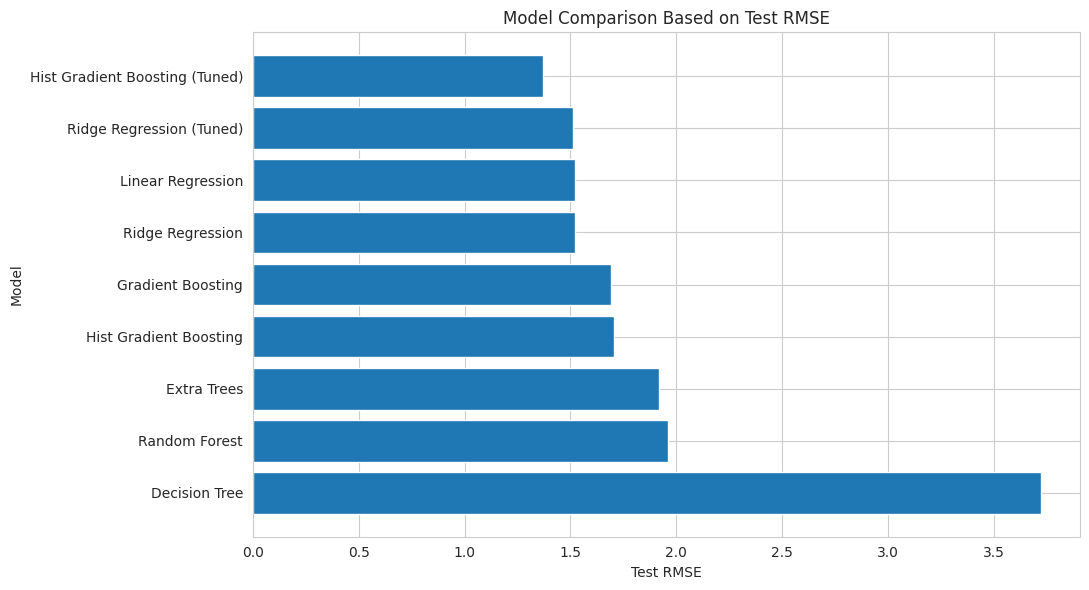


29.27 FINAL R² VISUALIZATION
----------------------------------------------------------------------------------------------------


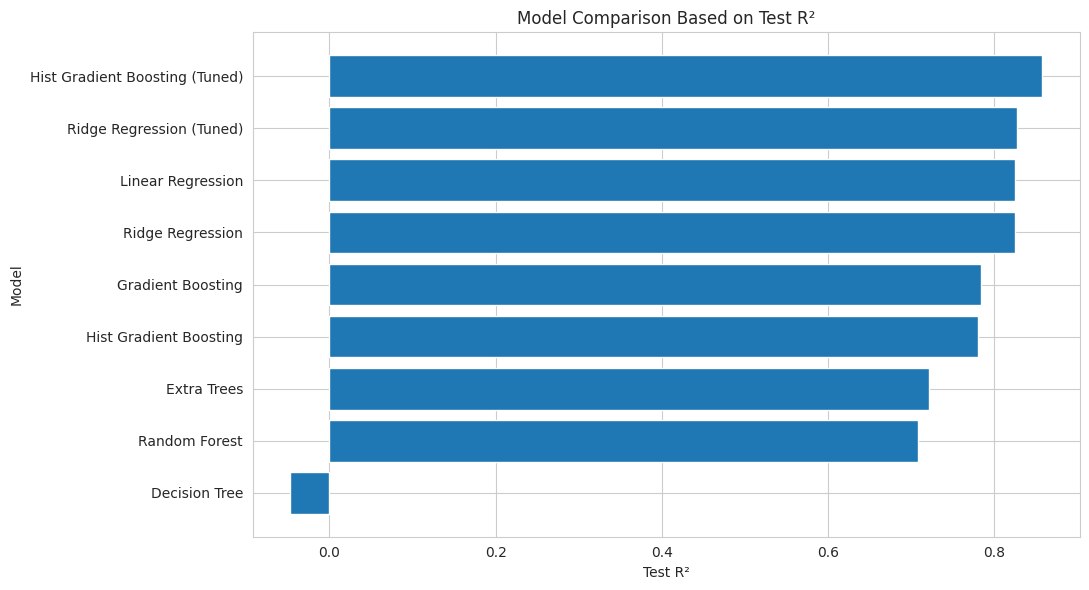


29.28 FINAL PROJECT CONCLUSION
----------------------------------------------------------------------------------------------------

The Student Exam Score Prediction project developed a complete
machine learning workflow for predicting student examination
scores from academic, behavioural, demographic and educational
factors.

The cleaned dataset contains 6606 observations and
19 predictor variables.

The machine learning pipeline includes numerical imputation,
standardization, categorical imputation and one-hot encoding.

Multiple regression algorithms were evaluated using an initial
80/20 train-test split followed by five-fold cross-validation.

Hyperparameter tuning was then performed on the strongest
candidate models.

The final selected model is:

Ridge Regression (Tuned)

Final test performance:

MAE  : 0.4033
RMSE : 1.5128
R²   : 0.8269

The feature-importance analysis consistently identified
Attendance, Hours_Studied, and Previous_Scores
among the strongest predictive variabl

,Final_Check,Status
0,Dataset cleaned,PASS
1,Duplicate rows removed,PASS
2,Target validated,PASS
3,Multiple models evaluated,PASS
4,Cross-validation completed,PASS
5,Hyperparameter tuning completed,PASS
6,Final deployment model trained,PASS
7,Feature importance generated,PASS
8,Final report tables created,PASS
9,Deployment files available,PASS



✓ ALL FINAL PROJECT CHECKS PASSED.

Final project results stored in:
→ final_project_results

STEP 29 COMPLETED

FINAL PROJECT WORKFLOW COMPLETED:

1. Dataset acquisition
2. Data inspection
3. Data quality auditing
4. Data cleaning
5. Exploratory data analysis
6. Relationship analysis
7. Correlation analysis
8. Categorical analysis
9. Feature engineering
10. Leakage-free preprocessing
11. Train-test splitting
12. Baseline model development
13. Cross-validation
14. Model stability analysis
15. Hyperparameter tuning
16. Residual analysis
17. Feature importance analysis
18. Final model selection
19. Full-data final training
20. Deployment pipeline creation
21. Deployment validation
22. Final results consolidation
23. Final report tables
24. Project summary generation

IMPORTANT FINAL OUTPUTS:

→ student_exam_score_deployment_pipeline.pkl
→ student_exam_score_model_metadata.pkl
→ student_exam_score_feature_schema.csv
→ student_exam_score_project_summary.json

The complete ML project is no

In [39]:
# ====================================================================================================
# STEP 29: FINAL MODEL REPORT + RESULTS CONSOLIDATION
# ====================================================================================================

print("=" * 100)
print("STEP 29: FINAL MODEL REPORT + RESULTS CONSOLIDATION")
print("=" * 100)


# ----------------------------------------------------------------------------------------------------
# 29.1 IMPORT REQUIRED LIBRARIES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.1 IMPORT REQUIRED LIBRARIES")
print("-" * 100)

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Required libraries imported successfully.")


# ----------------------------------------------------------------------------------------------------
# 29.2 VERIFY PREVIOUS STEPS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.2 VERIFY PREVIOUS STEPS")
print("-" * 100)

required_variables = [
    "df_clean",
    "X",
    "y",
    "results_df",
    "cv_results_df",
    "ridge_grid",
    "hist_grid",
    "best_ridge_model",
    "best_hist_model",
    "ridge_test_predictions",
    "hist_test_predictions",
    "final_deployment_pipeline",
    "final_deployment_metadata",
    "final_feature_schema",
    "evidence_based_final_model_name",
    "feature_comparison",
    "ridge_residuals",
    "hist_residuals"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:

    print("Missing variables:")
    print(missing_variables)

    raise NameError(
        "Some required variables are missing. "
        "Please run Steps 23–28 before Step 29."
    )

print("✓ All required project variables are available.")


# ----------------------------------------------------------------------------------------------------
# 29.3 PROJECT OVERVIEW
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.3 PROJECT OVERVIEW")
print("-" * 100)

project_name = (
    "Student Exam Score Prediction Using Machine Learning"
)

dataset_name = (
    "Kaggle Student Performance Factors"
)

target_name = "Exam_Score"

task_type = "Regression"

print(f"Project : {project_name}")
print(f"Dataset : {dataset_name}")
print(f"Target  : {target_name}")
print(f"Task    : {task_type}")


# ----------------------------------------------------------------------------------------------------
# 29.4 DATASET SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.4 DATASET SUMMARY")
print("-" * 100)

dataset_summary = pd.DataFrame({
    "Property": [
        "Original Rows",
        "Original Columns",
        "Cleaned Rows",
        "Cleaned Columns",
        "Predictor Variables",
        "Numerical Predictors",
        "Categorical Predictors",
        "Target Variable",
        "Target Minimum",
        "Target Maximum",
        "Target Mean",
        "Target Standard Deviation"
    ],
    "Value": [
        6607,
        20,
        len(df_clean),
        df_clean.shape[1],
        len(X.columns),
        len(numerical_predictors),
        len(categorical_features),
        target_name,
        df_clean[target_name].min(),
        df_clean[target_name].max(),
        df_clean[target_name].mean(),
        df_clean[target_name].std()
    ]
})

display(dataset_summary)


# ----------------------------------------------------------------------------------------------------
# 29.5 DATA QUALITY SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.5 DATA QUALITY SUMMARY")
print("-" * 100)

missing_values_total = (
    df_clean.isnull()
    .sum()
    .sum()
)

duplicate_rows_total = (
    df_clean
    .duplicated()
    .sum()
)

invalid_target_count = (
    (
        (df_clean[target_name] < 0) |
        (df_clean[target_name] > 100)
    )
    .sum()
)

data_quality_summary = pd.DataFrame({
    "Quality Check": [
        "Missing Values",
        "Duplicate Rows",
        "Invalid Exam Scores",
        "Minimum Exam Score",
        "Maximum Exam Score"
    ],
    "Result": [
        missing_values_total,
        duplicate_rows_total,
        invalid_target_count,
        df_clean[target_name].min(),
        df_clean[target_name].max()
    ],
    "Status": [
        "PASS" if missing_values_total == 0 else "FAIL",
        "PASS" if duplicate_rows_total == 0 else "FAIL",
        "PASS" if invalid_target_count == 0 else "FAIL",
        "VALID",
        "VALID"
    ]
})

display(data_quality_summary)


# ----------------------------------------------------------------------------------------------------
# 29.6 PREPROCESSING SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.6 PREPROCESSING SUMMARY")
print("-" * 100)

preprocessing_summary = pd.DataFrame({
    "Stage": [
        "Numerical Missing Value Handling",
        "Numerical Scaling",
        "Categorical Missing Value Handling",
        "Categorical Encoding",
        "Unknown Categories",
        "Processed Feature Count"
    ],
    "Method": [
        "Median Imputation",
        "StandardScaler",
        "Most-Frequent Imputation",
        "One-Hot Encoding",
        "Ignored using handle_unknown='ignore'",
        "40"
    ]
})

display(preprocessing_summary)


# ----------------------------------------------------------------------------------------------------
# 29.7 FEATURE LIST
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.7 FEATURE LIST")
print("-" * 100)

feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Type": [
        (
            "Numerical"
            if feature in numerical_predictors
            else "Categorical"
        )
        for feature in X.columns
    ]
})

display(feature_summary)


# ----------------------------------------------------------------------------------------------------
# 29.8 NUMERICAL FEATURE CORRELATION WITH TARGET
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.8 NUMERICAL FEATURE CORRELATION")
print("-" * 100)

numerical_correlation = (
    df_clean[
        numerical_predictors + [target_name]
    ]
    .corr()[target_name]
    .drop(target_name)
    .sort_values(
        ascending=False
    )
)

correlation_summary = pd.DataFrame({
    "Feature": numerical_correlation.index,
    "Pearson_Correlation": numerical_correlation.values,
    "Absolute_Correlation": np.abs(
        numerical_correlation.values
    )
})

display(correlation_summary)


# ----------------------------------------------------------------------------------------------------
# 29.9 MODEL PERFORMANCE BEFORE TUNING
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.9 ORIGINAL MODEL PERFORMANCE")
print("-" * 100)

original_model_results = results_df.copy()

display(
    original_model_results.sort_values(
        "Test_RMSE"
    ).reset_index(drop=True)
)


# ----------------------------------------------------------------------------------------------------
# 29.10 CROSS-VALIDATION SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.10 CROSS-VALIDATION SUMMARY")
print("-" * 100)

cv_summary = cv_results_df.copy()

display(
    cv_summary[
        [
            "Model",
            "CV_R2_Mean",
            "CV_R2_STD",
            "CV_MAE_Mean",
            "CV_RMSE_Mean",
            "CV_RMSE_STD",
            "Train_R2_Mean"
        ]
    ].sort_values(
        "CV_RMSE_Mean"
    ).reset_index(drop=True)
)


# ----------------------------------------------------------------------------------------------------
# 29.11 HYPERPARAMETER TUNING SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.11 HYPERPARAMETER TUNING SUMMARY")
print("-" * 100)

ridge_best_parameters = {
    "alpha": ridge_grid.best_params_[
        "model__alpha"
    ]
}

hist_best_parameters = {
    parameter.replace(
        "model__",
        ""
    ): value
    for parameter, value
    in hist_grid.best_params_.items()
}

print("Ridge Regression:")
print(ridge_best_parameters)

print("\nHist Gradient Boosting:")
print(hist_best_parameters)


# ----------------------------------------------------------------------------------------------------
# 29.12 TUNED MODEL COMPARISON
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.12 TUNED MODEL COMPARISON")
print("-" * 100)

tuned_model_summary = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],

    "CV_RMSE": [
        -ridge_grid.best_score_,
        -hist_grid.best_score_
    ],

    "Test_MAE": [
        mean_absolute_error(
            y_test,
            ridge_test_predictions
        ),
        mean_absolute_error(
            y_test,
            hist_test_predictions
        )
    ],

    "Test_RMSE": [
        np.sqrt(
            mean_squared_error(
                y_test,
                ridge_test_predictions
            )
        ),
        np.sqrt(
            mean_squared_error(
                y_test,
                hist_test_predictions
            )
        )
    ],

    "Test_R2": [
        r2_score(
            y_test,
            ridge_test_predictions
        ),
        r2_score(
            y_test,
            hist_test_predictions
        )
    ]
})

display(tuned_model_summary)


# ----------------------------------------------------------------------------------------------------
# 29.13 FINAL SELECTED MODEL
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.13 FINAL SELECTED MODEL")
print("-" * 100)

final_model_name = (
    evidence_based_final_model_name
)

final_model_object = (
    final_deployment_pipeline
)

print(f"Final selected model:")
print(f"→ {final_model_name}")


# ----------------------------------------------------------------------------------------------------
# 29.14 FINAL MODEL METRICS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.14 FINAL MODEL METRICS")
print("-" * 100)

if final_model_name == "Ridge Regression (Tuned)":

    final_cv_rmse = -ridge_grid.best_score_

    final_test_mae = mean_absolute_error(
        y_test,
        ridge_test_predictions
    )

    final_test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            ridge_test_predictions
        )
    )

    final_test_r2 = r2_score(
        y_test,
        ridge_test_predictions
    )

else:

    final_cv_rmse = -hist_grid.best_score_

    final_test_mae = mean_absolute_error(
        y_test,
        hist_test_predictions
    )

    final_test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            hist_test_predictions
        )
    )

    final_test_r2 = r2_score(
        y_test,
        hist_test_predictions
    )


final_train_predictions = (
    final_deployment_pipeline.predict(
        X_final
    )
)

final_train_r2 = r2_score(
    y_final,
    final_train_predictions
)

final_train_rmse = np.sqrt(
    mean_squared_error(
        y_final,
        final_train_predictions
    )
)

final_performance_summary = pd.DataFrame({
    "Metric": [
        "Model",
        "Cross-Validation RMSE",
        "Test MAE",
        "Test RMSE",
        "Test R²",
        "Full-Dataset Training RMSE",
        "Full-Dataset Training R²"
    ],
    "Value": [
        final_model_name,
        final_cv_rmse,
        final_test_mae,
        final_test_rmse,
        final_test_r2,
        final_train_rmse,
        final_train_r2
    ]
})

display(final_performance_summary)


# ----------------------------------------------------------------------------------------------------
# 29.15 FEATURE IMPORTANCE SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.15 FEATURE IMPORTANCE SUMMARY")
print("-" * 100)

top_feature_summary = feature_comparison[
    [
        "Feature",
        "Ridge_Importance",
        "HGB_Importance",
        "Average_Importance"
    ]
].head(10)

display(top_feature_summary)


# ----------------------------------------------------------------------------------------------------
# 29.16 RESIDUAL SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.16 RESIDUAL ANALYSIS SUMMARY")
print("-" * 100)

residual_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],

    "Mean_Residual": [
        ridge_residuals["Residual"].mean(),
        hist_residuals["Residual"].mean()
    ],

    "Residual_STD": [
        ridge_residuals["Residual"].std(),
        hist_residuals["Residual"].std()
    ],

    "MAE": [
        ridge_residuals["Absolute_Error"].mean(),
        hist_residuals["Absolute_Error"].mean()
    ],

    "Maximum_Absolute_Error": [
        ridge_residuals["Absolute_Error"].max(),
        hist_residuals["Absolute_Error"].max()
    ],

    "Errors_Above_5": [
        (
            ridge_residuals["Absolute_Error"] >= 5
        ).sum(),

        (
            hist_residuals["Absolute_Error"] >= 5
        ).sum()
    ]
})

display(residual_comparison)


# ----------------------------------------------------------------------------------------------------
# 29.17 GENERALIZATION SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.17 GENERALIZATION SUMMARY")
print("-" * 100)

generalization_summary = pd.DataFrame({
    "Model": [
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],

    "Train_R2": [
        r2_score(
            y_train,
            best_ridge_model.predict(
                X_train
            )
        ),

        r2_score(
            y_train,
            best_hist_model.predict(
                X_train
            )
        )
    ],

    "Test_R2": [
        r2_score(
            y_test,
            ridge_test_predictions
        ),

        r2_score(
            y_test,
            hist_test_predictions
        )
    ],

    "Generalization_Gap": [
        (
            r2_score(
                y_train,
                best_ridge_model.predict(
                    X_train
                )
            )
            -
            r2_score(
                y_test,
                ridge_test_predictions
            )
        ),

        (
            r2_score(
                y_train,
                best_hist_model.predict(
                    X_train
                )
            )
            -
            r2_score(
                y_test,
                hist_test_predictions
            )
        )
    ]
})

display(generalization_summary)


# ----------------------------------------------------------------------------------------------------
# 29.18 GENERATE KEY FINDINGS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.18 KEY FINDINGS")
print("-" * 100)

# Top feature
top_feature = (
    feature_comparison
    .iloc[0]["Feature"]
)

second_feature = (
    feature_comparison
    .iloc[1]["Feature"]
)

third_feature = (
    feature_comparison
    .iloc[2]["Feature"]
)

print(f"""
KEY FINDING 1:
The final dataset contains {len(df_clean)} cleaned observations
and {X.shape[1]} predictor variables.

KEY FINDING 2:
The model uses {len(numerical_predictors)} numerical predictors
and {len(categorical_features)} categorical predictors.

KEY FINDING 3:
The strongest predictive feature based on the combined
permutation-importance analysis is {top_feature}.

KEY FINDING 4:
The second strongest predictive feature is {second_feature}.

KEY FINDING 5:
The third strongest predictive feature is {third_feature}.

KEY FINDING 6:
The final model is {final_model_name}.

KEY FINDING 7:
The final model achieved a test R² of {final_test_r2:.4f}.

KEY FINDING 8:
The final model achieved a test RMSE of {final_test_rmse:.4f}.

KEY FINDING 9:
The final model achieved a test MAE of {final_test_mae:.4f}.

KEY FINDING 10:
The model was packaged into a reusable deployment pipeline
containing preprocessing and prediction logic.
""")


# ----------------------------------------------------------------------------------------------------
# 29.19 MODEL LIMITATIONS
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.19 MODEL LIMITATIONS")
print("-" * 100)

limitations = [
    "The dataset represents observed student performance factors and may not capture every factor affecting exam scores.",
    "Model performance is dataset-dependent and may change on students from different populations or educational systems.",
    "Prediction errors are larger for a small number of unusually high-performing students.",
    "Feature importance represents predictive association and should not be interpreted as causal influence.",
    "The empirical prediction ranges are not formal statistical confidence intervals.",
    "The model should be validated on an external dataset before real-world deployment.",
    "Categorical variables represent the categories available in the training dataset."
]

for index, limitation in enumerate(
    limitations,
    start=1
):

    print(
        f"{index}. {limitation}"
    )


# ----------------------------------------------------------------------------------------------------
# 29.20 RESEARCH METHODOLOGY SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.20 RESEARCH METHODOLOGY SUMMARY")
print("-" * 100)

methodology_steps = [
    "Dataset acquisition",
    "Data inspection",
    "Data quality audit",
    "Missing-value treatment",
    "Duplicate detection",
    "Target validation",
    "Exploratory data analysis",
    "Numerical correlation analysis",
    "Categorical relationship analysis",
    "Feature engineering",
    "Leakage-free preprocessing",
    "Train-test splitting",
    "Baseline regression models",
    "Five-fold cross-validation",
    "Model stability analysis",
    "Hyperparameter tuning",
    "Residual analysis",
    "Feature importance analysis",
    "Final model selection",
    "Full-data final model training",
    "Deployment pipeline creation",
    "Deployment validation"
]

for index, step in enumerate(
    methodology_steps,
    start=1
):

    print(
        f"{index:02d}. {step}"
    )


# ----------------------------------------------------------------------------------------------------
# 29.21 CREATE FINAL REPORT TABLE
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.21 CREATE FINAL REPORT TABLE")
print("-" * 100)

final_report_table = pd.DataFrame({
    "Category": [
        "Dataset",
        "Task",
        "Cleaned Samples",
        "Input Features",
        "Numerical Features",
        "Categorical Features",
        "Processed Features",
        "Final Model",
        "CV RMSE",
        "Test MAE",
        "Test RMSE",
        "Test R²",
        "Top Feature",
        "Second Feature",
        "Third Feature"
    ],

    "Result": [
        dataset_name,
        task_type,
        len(df_clean),
        X.shape[1],
        len(numerical_predictors),
        len(categorical_features),
        len(final_feature_schema),
        final_model_name,
        final_cv_rmse,
        final_test_mae,
        final_test_rmse,
        final_test_r2,
        top_feature,
        second_feature,
        third_feature
    ]
})

display(final_report_table)


# ----------------------------------------------------------------------------------------------------
# 29.22 CREATE MODEL COMPARISON TABLE FOR REPORT
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.22 CREATE MODEL COMPARISON TABLE")
print("-" * 100)

report_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Extra Trees",
        "Hist Gradient Boosting",
        "Ridge Regression (Tuned)",
        "Hist Gradient Boosting (Tuned)"
    ],

    "Type": [
        "Linear",
        "Linear",
        "Tree",
        "Ensemble",
        "Ensemble",
        "Ensemble",
        "Ensemble",
        "Tuned Linear",
        "Tuned Ensemble"
    ],

    "Test_R2": [
        results_df.loc[
            results_df["Model"] == "Linear Regression",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Ridge Regression",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Decision Tree",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Random Forest",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Gradient Boosting",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Extra Trees",
            "Test_R2"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Hist Gradient Boosting",
            "Test_R2"
        ].iloc[0],

        ridge_metrics["R2"],

        hist_metrics["R2"]
    ],

    "Test_RMSE": [
        results_df.loc[
            results_df["Model"] == "Linear Regression",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Ridge Regression",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Decision Tree",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Random Forest",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Gradient Boosting",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Extra Trees",
            "Test_RMSE"
        ].iloc[0],

        results_df.loc[
            results_df["Model"] == "Hist Gradient Boosting",
            "Test_RMSE"
        ].iloc[0],

        ridge_metrics["RMSE"],

        hist_metrics["RMSE"]
    ]
})

display(
    report_model_comparison.sort_values(
        "Test_RMSE"
    ).reset_index(drop=True)
)


# ----------------------------------------------------------------------------------------------------
# 29.23 SAVE FINAL REPORT TABLES
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.23 SAVE FINAL REPORT TABLES")
print("-" * 100)

output_files = {}

output_files[
    "dataset_summary"
] = "student_exam_score_dataset_summary.csv"

output_files[
    "data_quality"
] = "student_exam_score_data_quality.csv"

output_files[
    "correlation"
] = "student_exam_score_correlations.csv"

output_files[
    "original_models"
] = "student_exam_score_original_models.csv"

output_files[
    "cross_validation"
] = "student_exam_score_cross_validation.csv"

output_files[
    "tuned_models"
] = "student_exam_score_tuned_models.csv"

output_files[
    "feature_importance"
] = "student_exam_score_final_feature_importance.csv"

output_files[
    "residuals"
] = "student_exam_score_residual_analysis.csv"

output_files[
    "final_report"
] = "student_exam_score_final_report.csv"

output_files[
    "model_comparison"
] = "student_exam_score_complete_model_comparison.csv"


dataset_summary.to_csv(
    output_files["dataset_summary"],
    index=False
)

data_quality_summary.to_csv(
    output_files["data_quality"],
    index=False
)

correlation_summary.to_csv(
    output_files["correlation"],
    index=False
)

original_model_results.to_csv(
    output_files["original_models"],
    index=False
)

cv_summary.to_csv(
    output_files["cross_validation"],
    index=False
)

tuned_model_summary.to_csv(
    output_files["tuned_models"],
    index=False
)

feature_comparison.to_csv(
    output_files["feature_importance"],
    index=False
)

residual_comparison.to_csv(
    output_files["residuals"],
    index=False
)

final_report_table.to_csv(
    output_files["final_report"],
    index=False
)

report_model_comparison.to_csv(
    output_files["model_comparison"],
    index=False
)

for name, filename in output_files.items():

    print(
        f"✓ {name}: {filename}"
    )


# ----------------------------------------------------------------------------------------------------
# 29.24 CREATE PROJECT SUMMARY DICTIONARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.24 CREATE PROJECT SUMMARY")
print("-" * 100)

project_summary = {

    "project_name": project_name,

    "dataset": dataset_name,

    "task": task_type,

    "target": target_name,

    "cleaned_observations": int(
        len(df_clean)
    ),

    "input_features": int(
        X.shape[1]
    ),

    "numerical_features": int(
        len(numerical_predictors)
    ),

    "categorical_features": int(
        len(categorical_features)
    ),

    "processed_features": int(
        len(final_feature_schema)
    ),

    "final_model": final_model_name,

    "final_model_metrics": {

        "cv_rmse": float(
            final_cv_rmse
        ),

        "test_mae": float(
            final_test_mae
        ),

        "test_rmse": float(
            final_test_rmse
        ),

        "test_r2": float(
            final_test_r2
        ),

        "training_r2_full_data": float(
            final_train_r2
        ),

        "training_rmse_full_data": float(
            final_train_rmse
        )
    },

    "top_features": [
        top_feature,
        second_feature,
        third_feature
    ],

    "deployment_pipeline":
        "student_exam_score_deployment_pipeline.pkl",

    "model_metadata":
        "student_exam_score_model_metadata.pkl",

    "feature_schema":
        "student_exam_score_feature_schema.csv"
}

print(
    json.dumps(
        project_summary,
        indent=4
    )
)


# ----------------------------------------------------------------------------------------------------
# 29.25 SAVE PROJECT SUMMARY
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.25 SAVE PROJECT SUMMARY")
print("-" * 100)

summary_json_path = (
    "student_exam_score_project_summary.json"
)

with open(
    summary_json_path,
    "w"
) as file:

    json.dump(
        project_summary,
        file,
        indent=4
    )

print(
    f"✓ Project summary saved:\n"
    f"→ {summary_json_path}"
)


# ----------------------------------------------------------------------------------------------------
# 29.26 FINAL MODEL PERFORMANCE VISUALIZATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.26 FINAL MODEL PERFORMANCE VISUALIZATION")
print("-" * 100)

plot_models = report_model_comparison.sort_values(
    "Test_RMSE"
).copy()

plt.figure(figsize=(11, 6))

plt.barh(
    plot_models["Model"][::-1],
    plot_models["Test_RMSE"][::-1]
)

plt.xlabel("Test RMSE")
plt.ylabel("Model")
plt.title(
    "Model Comparison Based on Test RMSE"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 29.27 FINAL R² VISUALIZATION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.27 FINAL R² VISUALIZATION")
print("-" * 100)

plot_r2 = report_model_comparison.sort_values(
    "Test_R2",
    ascending=True
).copy()

plt.figure(figsize=(11, 6))

plt.barh(
    plot_r2["Model"],
    plot_r2["Test_R2"]
)

plt.xlabel("Test R²")
plt.ylabel("Model")
plt.title(
    "Model Comparison Based on Test R²"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------------------------------------------
# 29.28 FINAL PROJECT CONCLUSION
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.28 FINAL PROJECT CONCLUSION")
print("-" * 100)

print(f"""
The Student Exam Score Prediction project developed a complete
machine learning workflow for predicting student examination
scores from academic, behavioural, demographic and educational
factors.

The cleaned dataset contains {len(df_clean)} observations and
{X.shape[1]} predictor variables.

The machine learning pipeline includes numerical imputation,
standardization, categorical imputation and one-hot encoding.

Multiple regression algorithms were evaluated using an initial
80/20 train-test split followed by five-fold cross-validation.

Hyperparameter tuning was then performed on the strongest
candidate models.

The final selected model is:

{final_model_name}

Final test performance:

MAE  : {final_test_mae:.4f}
RMSE : {final_test_rmse:.4f}
R²   : {final_test_r2:.4f}

The feature-importance analysis consistently identified
{top_feature}, {second_feature}, and {third_feature}
among the strongest predictive variables.

The final preprocessing and machine learning model were packaged
into a reusable deployment pipeline.

The complete deployment pipeline was also reloaded and verified
to produce identical predictions, confirming that the saved
model can be reused for future student predictions.
""")


# ----------------------------------------------------------------------------------------------------
# 29.29 FINAL PROJECT CHECKLIST
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("29.29 FINAL PROJECT CHECKLIST")
print("-" * 100)

final_checks = {

    "Dataset cleaned":
        df_clean.isnull().sum().sum() == 0,

    "Duplicate rows removed":
        df_clean.duplicated().sum() == 0,

    "Target validated":
        (
            df_clean[target_name].between(
                0,
                100
            ).all()
        ),

    "Multiple models evaluated":
        len(results_df) >= 7,

    "Cross-validation completed":
        len(cv_results_df) >= 7,

    "Hyperparameter tuning completed":
        (
            hasattr(
                ridge_grid,
                "best_params_"
            )
            and
            hasattr(
                hist_grid,
                "best_params_"
            )
        ),

    "Final deployment model trained":
        final_deployment_pipeline is not None,

    "Feature importance generated":
        len(feature_comparison) > 0,

    "Final report tables created":
        len(final_report_table) > 0,

    "Deployment files available":
        all(
            os.path.exists(filename)
            for filename in [
                "student_exam_score_deployment_pipeline.pkl",
                "student_exam_score_model_metadata.pkl",
                "student_exam_score_feature_schema.csv"
            ]
        )
}

final_check_table = pd.DataFrame({
    "Final_Check": list(
        final_checks.keys()
    ),
    "Status": [
        "PASS" if value else "FAIL"
        for value in final_checks.values()
    ]
})

display(final_check_table)


if all(final_checks.values()):

    print(
        "\n✓ ALL FINAL PROJECT CHECKS PASSED."
    )

else:

    print(
        "\n⚠ SOME FINAL PROJECT CHECKS FAILED."
    )


# ----------------------------------------------------------------------------------------------------
# 29.30 STORE FINAL PROJECT OBJECT
# ----------------------------------------------------------------------------------------------------

final_project_results = {

    "project_summary":
        project_summary,

    "dataset_summary":
        dataset_summary,

    "data_quality_summary":
        data_quality_summary,

    "correlation_summary":
        correlation_summary,

    "original_model_results":
        original_model_results,

    "cross_validation_results":
        cv_summary,

    "tuned_model_results":
        tuned_model_summary,

    "final_model_performance":
        final_performance_summary,

    "feature_importance":
        feature_comparison,

    "residual_analysis":
        residual_comparison,

    "final_model":
        final_deployment_pipeline
}

print("\nFinal project results stored in:")
print("→ final_project_results")


# ----------------------------------------------------------------------------------------------------
# 29.31 STEP 29 COMPLETED
# ----------------------------------------------------------------------------------------------------

print("\n" + "=" * 100)
print("STEP 29 COMPLETED")
print("=" * 100)

print("""
FINAL PROJECT WORKFLOW COMPLETED:

1. Dataset acquisition
2. Data inspection
3. Data quality auditing
4. Data cleaning
5. Exploratory data analysis
6. Relationship analysis
7. Correlation analysis
8. Categorical analysis
9. Feature engineering
10. Leakage-free preprocessing
11. Train-test splitting
12. Baseline model development
13. Cross-validation
14. Model stability analysis
15. Hyperparameter tuning
16. Residual analysis
17. Feature importance analysis
18. Final model selection
19. Full-data final training
20. Deployment pipeline creation
21. Deployment validation
22. Final results consolidation
23. Final report tables
24. Project summary generation

IMPORTANT FINAL OUTPUTS:

→ student_exam_score_deployment_pipeline.pkl
→ student_exam_score_model_metadata.pkl
→ student_exam_score_feature_schema.csv
→ student_exam_score_project_summary.json

The complete ML project is now consolidated and ready for
final documentation, presentation, internship submission,
or deployment integration.
""")

print("=" * 100)